In [ ]:

# ============================================================
# STEP 4A: ZIP ARCHIVE AUDIT
# Google Drive + GitHub
# Read-only inspection: does not extract or modify archives
# ============================================================

from google.colab import drive
from pathlib import Path
import subprocess
import zipfile
import os

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Define locations
DRIVE_ROOT = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup"
)

GITHUB_URL = (
    "https://github.com/Karthik6-cpu/"
    "cartoonization-robustness-study.git"
)

GITHUB_ROOT = Path("/content/github_repo_audit")

# 3. Scan ZIP archives in Google Drive
print("=" * 65)
print("GOOGLE DRIVE ZIP ARCHIVE AUDIT")
print("=" * 65)

drive_zips = list(DRIVE_ROOT.rglob("*.zip"))

print("ZIP archives found:", len(drive_zips))

for i, path in enumerate(drive_zips, 1):
    size_mb = path.stat().st_size / (1024 ** 2)

    print(f"\n{i}. {path}")
    print(f"   Size: {size_mb:.2f} MB")

    try:
        with zipfile.ZipFile(path, "r") as archive:
            members = archive.namelist()

            print("   Files inside:", len(members))

            relevant = [
                name for name in members
                if name.lower().endswith((
                    ".py", ".ipynb", ".yaml", ".yml",
                    ".json", ".txt", ".csv", ".pt",
                    ".pth", ".keras", ".pkl"
                ))
            ]

            print("   Relevant files:", len(relevant))

            for name in relevant[:20]:
                print("      ", name)

            if len(relevant) > 20:
                print("      ...")

    except Exception as e:
        print("   ZIP inspection error:", str(e))

# 4. Clone GitHub repository into a new audit folder
print("\n" + "=" * 65)
print("GITHUB REPOSITORY AUDIT")
print("=" * 65)

# Avoid overwriting an existing folder
if GITHUB_ROOT.exists():
    counter = 2
    while Path(f"{GITHUB_ROOT}_{counter}").exists():
        counter += 1
    GITHUB_ROOT = Path(f"{GITHUB_ROOT}_{counter}")

result = subprocess.run(
    ["git", "clone", "--depth", "1", GITHUB_URL, str(GITHUB_ROOT)],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print("GitHub clone failed:")
    print(result.stderr)
else:
    print("Repository cloned successfully.")

    github_zips = list(GITHUB_ROOT.rglob("*.zip"))

    print("ZIP archives found:", len(github_zips))

    for i, path in enumerate(github_zips, 1):
        size_mb = path.stat().st_size / (1024 ** 2)

        print(f"\n{i}. {path.relative_to(GITHUB_ROOT)}")
        print(f"   Size: {size_mb:.2f} MB")

        try:
            with zipfile.ZipFile(path, "r") as archive:
                members = archive.namelist()

                print("   Files inside:", len(members))

                relevant = [
                    name for name in members
                    if name.lower().endswith((
                        ".py", ".ipynb", ".yaml", ".yml",
                        ".json", ".txt", ".csv", ".pt",
                        ".pth", ".keras", ".pkl"
                    ))
                ]

                print("   Relevant files:", len(relevant))

                for name in relevant[:20]:
                    print("      ", name)

        except Exception as e:
            print("   ZIP inspection error:", str(e))

print("\n" + "=" * 65)
print("ZIP AUDIT COMPLETED")
print("No archives were extracted or modified.")
print("=" * 65)


Mounted at /content/drive
GOOGLE DRIVE ZIP ARCHIVE AUDIT
ZIP archives found: 19

1. /content/drive/MyDrive/CartoonizationResearchBackup/complete_cartoonization_research.zip
   Size: 1899.34 MB
   Files inside: 19189
   Relevant files: 73
       cartoonization_research/resnet18_low_illumination_stable_diffusion_predictions.csv
       cartoonization_research/jpeg_compression_manifest.csv
       cartoonization_research/resnet18_gaussian_blur_opencv_predictions.csv
       cartoonization_research/prediction_consistency_summary.csv
       cartoonization_research/resnet18_original_predictions.csv
       cartoonization_research/gaussian_blur_manifest.csv
       cartoonization_research/image_quality_per_image.csv
       cartoonization_research/jpeg_compression_animegan2_results.csv
       cartoonization_research/gaussian_blur_stable_diffusion_results.csv
       cartoonization_research/per_class_recognition_results.csv
       cartoonization_research/resnet18_low_illumination_original_predictions

In [ ]:

# ============================================================
# STEP 4B: SEARCH ALL ZIP ARCHIVES FOR ORIGINAL TRAINING CODE
# Read-only inspection; no extraction or modification
# ============================================================

from pathlib import Path
import zipfile

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup"
)

GITHUB_ROOT = Path("/content/github_repo_audit")

# Files that may reveal the original training configuration
code_extensions = {
    ".py", ".ipynb", ".yaml", ".yml",
    ".toml", ".ini", ".cfg", ".json",
    ".txt", ".log"
}

keywords = [
    "train", "training", "resnet", "augment",
    "config", "experiment", "model", "notebook",
    "imagenette", "jpeg"
]

def inspect_zip(zip_path):
    results = []

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:
            for item in archive.infolist():
                name = item.filename
                suffix = Path(name).suffix.lower()
                lower_name = name.lower()

                if suffix in code_extensions:
                    if any(word in lower_name for word in keywords):
                        results.append({
                            "name": name,
                            "size_kb": round(item.file_size / 1024, 2)
                        })

    except Exception as e:
        print("Could not inspect:", zip_path, "|", str(e))

    return results


# 1. Search all Drive ZIP archives
print("=" * 75)
print("GOOGLE DRIVE ARCHIVE CODE SEARCH")
print("=" * 75)

drive_zips = list(DRIVE_ROOT.rglob("*.zip"))

for zip_path in drive_zips:
    matches = inspect_zip(zip_path)

    if matches:
        print("\nARCHIVE:", zip_path.name)
        print("MATCHES:", len(matches))

        for item in matches:
            print(
                f"  {item['name']} "
                f"({item['size_kb']} KB)"
            )


# 2. Search all GitHub ZIP archives
print("\n" + "=" * 75)
print("GITHUB ARCHIVE CODE SEARCH")
print("=" * 75)

github_zips = (
    list(GITHUB_ROOT.rglob("*.zip"))
    if GITHUB_ROOT.exists() else []
)

for zip_path in github_zips:
    matches = inspect_zip(zip_path)

    if matches:
        print("\nARCHIVE:", zip_path.name)
        print("MATCHES:", len(matches))

        for item in matches:
            print(
                f"  {item['name']} "
                f"({item['size_kb']} KB)"
            )


# 3. Search normal GitHub repository files
print("\n" + "=" * 75)
print("GITHUB REPOSITORY CODE FILES")
print("=" * 75)

if GITHUB_ROOT.exists():
    for path in GITHUB_ROOT.rglob("*"):
        if (
            path.is_file()
            and path.suffix.lower() in code_extensions
        ):
            print(path.relative_to(GITHUB_ROOT))

print("\n" + "=" * 75)
print("SEARCH COMPLETED — NO FILES EXTRACTED")
print("=" * 75)


GOOGLE DRIVE ARCHIVE CODE SEARCH

ARCHIVE: ImageWoof_External_backup.zip
MATCHES: 1
  ImageWoof_External/experiment_metadata.json (0.39 KB)

ARCHIVE: Cartoonization_Research_Backup_20261027_102323.zip
MATCHES: 1
  ImageWoof_External/experiment_metadata.json (0.39 KB)

GITHUB ARCHIVE CODE SEARCH

ARCHIVE: Cartoonization_Research_Backup_20261027_102323.zip
MATCHES: 1
  ImageWoof_External/experiment_metadata.json (0.39 KB)
Could not inspect: /content/github_repo_audit/generated_datasets/animegan2_full.zip | File is not a zip file
Could not inspect: /content/github_repo_audit/generated_datasets/opencv_full.zip | File is not a zip file
Could not inspect: /content/github_repo_audit/generated_datasets/stable_diffusion_full.zip | File is not a zip file

GITHUB REPOSITORY CODE FILES
notebooka218aec394 (2).ipynb
01_opencv_cartoonization_pilot (1).ipynb
requirements.txt
Cartoonization_JPEG_Robustness_Research.ipynb
01_opencv_cartoonization_pilot.ipynb
notebooka218aec394.ipynb
convnext.ipynb
resea

In [ ]:

from pathlib import Path
import json
import re

REPO = Path("/content/github_repo_audit")

# Search terms related to model training and experimental configuration
keywords = [
    "resnet", "resnet18", "batch_size", "learning_rate", "lr=",
    "optimizer", "adam", "adamw", "scheduler", "epochs",
    "random_seed", "manual_seed", "seed(", "pretrained",
    "weights=", "imagenet", "transforms", "normalize",
    "resize", "randomcrop", "jpeg", "quality",
    "dataloader", "train_loader", "val_loader",
    "crossentropyloss", "weight_decay", "amp",
    "mixed_precision", "torchvision"
]

notebooks = sorted(REPO.rglob("*.ipynb"))

print("=" * 85)
print("NOTEBOOKS FOUND:", len(notebooks))
for nb in notebooks:
    print(" -", nb.relative_to(REPO))

print("\n" + "=" * 85)
print("RELEVANT NOTEBOOK CELLS")
print("=" * 85)

total_matches = 0

for nb_path in notebooks:
    try:
        with open(nb_path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        matches = []

        for index, cell in enumerate(notebook.get("cells", [])):
            source = cell.get("source", "")
            if isinstance(source, list):
                source = "".join(source)

            if not source.strip():
                continue

            lower = source.lower()
            found = [word for word in keywords if word in lower]

            if found:
                matches.append({
                    "index": index,
                    "type": cell.get("cell_type", "unknown"),
                    "keywords": found,
                    "source": source
                })

        if matches:
            print("\n\n" + "#" * 85)
            print("NOTEBOOK:", nb_path.relative_to(REPO))
            print("MATCHING CELLS:", len(matches))
            print("#" * 85)

            for item in matches:
                total_matches += 1
                print(f"\n--- CELL {item['index']} | {item['type']} ---")
                print("Matched terms:", ", ".join(item["keywords"]))

                source = item["source"]
                if len(source) > 5000:
                    source = source[:5000] + "\n... [CELL OUTPUT TRUNCATED]"

                print(source)

    except Exception as e:
        print("\nERROR:", nb_path, "|", str(e))

print("\n" + "=" * 85)
print("INSPECTION COMPLETED")
print("Total matching cells:", total_matches)
print("=" * 85)


Streaming output truncated to the last 5000 lines.
        if len(correct_vals) == 0 or len(wrong_vals) == 0:
            continue

        _, p_mw = mannwhitneyu(
            correct_vals, wrong_vals, alternative="two-sided"
        )
        rho, p_spearman = spearmanr(
            group[feature], group["correct"]
        )

        rows.append({
            "model": model,
            "condition": condition,
            "descriptor": feature,
            "mean_when_correct": correct_vals.mean(),
            "mean_when_wrong": wrong_vals.mean(),
            "median_when_correct": correct_vals.median(),
            "median_when_wrong": wrong_vals.median(),
            "spearman_rho": rho,
            "spearman_p_value": p_spearman,
            "mann_whitney_p_value": p_mw,
            "n_correct": len(correct_vals),
            "n_wrong": len(wrong_vals)
        })

results = pd.DataFrame(rows)

if not results.empty:
    results["mann_whitney_p_holm"] = multipletests(
        results[

In [ ]:

# ============================================================
# RESNET18 BASELINE REPRODUCIBILITY AUDIT
# Reads original notebooks and existing checkpoints.
# Does NOT execute training or overwrite existing experiments.
# ============================================================

from pathlib import Path
import json
import re
import torch
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

REPO = Path("/content/github_repo_audit")

BASE = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
)

CHECKPOINT_DIR = BASE / "checkpoints"

REPORT_DIR = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Reproducibility_Audit"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK_NAME = "Cartoonization_JPEG_Robustness_Research.ipynb"

print("=" * 75)
print("RESNET18 REPRODUCIBILITY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 2. FIND ORIGINAL NOTEBOOK
# ------------------------------------------------------------

notebook_matches = list(REPO.rglob(NOTEBOOK_NAME))

if not notebook_matches:
    raise FileNotFoundError(
        f"Could not find {NOTEBOOK_NAME} inside {REPO}"
    )

NOTEBOOK_PATH = notebook_matches[0]

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

print("\nOriginal notebook:", NOTEBOOK_PATH)
print("Total notebook cells:", len(cells))

# ------------------------------------------------------------
# 3. EXTRACT RELEVANT TRAINING CELLS
# ------------------------------------------------------------

target_indices = [128, 129, 130, 131, 179]

training_terms = [
    "def train_resnet",
    "def train_one_model",
    "def build_model",
    "def make_model",
    "AdamW",
    "JPEG_AUGMENT_PROB",
    "ResNet18_Weights",
    "BATCH_SIZE",
    "EPOCHS",
]

selected_cells = {}

for index, cell in enumerate(cells):
    source = cell.get("source", "")
    if isinstance(source, list):
        source = "".join(source)

    if not source.strip():
        continue

    is_target = index in target_indices
    is_training_cell = (
        cell.get("cell_type") == "code"
        and any(term.lower() in source.lower()
                for term in training_terms)
    )

    if is_target or is_training_cell:
        selected_cells[index] = {
            "type": cell.get("cell_type", "unknown"),
            "source": source
        }

print("\nSelected training-related cells:", len(selected_cells))
print("Cell indices:", sorted(selected_cells.keys()))

# ------------------------------------------------------------
# 4. CREATE NOTEBOOK SOURCE REPORT
# ------------------------------------------------------------

source_report = []

source_report.append("# Original ResNet18 Notebook Training Code\n")
source_report.append(f"Notebook: {NOTEBOOK_PATH}\n")

for index, item in sorted(selected_cells.items()):
    source_report.append(
        f"\n\n## Cell {index} ({item['type']})\n"
    )
    source_report.append("```python\n")
    source_report.append(item["source"])
    source_report.append("\n```\n")

source_report_path = REPORT_DIR / "original_training_cells.md"

source_report_path.write_text(
    "".join(source_report),
    encoding="utf-8"
)

print("\nTraining source report saved:")
print(source_report_path)

# ------------------------------------------------------------
# 5. CHECKPOINT METADATA AUDIT
# ------------------------------------------------------------

checkpoint_names = [
    "resnet18_standard_best.pt",
    "resnet18_standard_latest.pt",
    "resnet18_jpeg_augmented_best.pt",
    "resnet18_jpeg_augmented_latest.pt",
]

checkpoint_rows = []
checkpoint_details = {}

for filename in checkpoint_names:

    path = CHECKPOINT_DIR / filename

    print("\n" + "-" * 65)
    print("CHECKPOINT:", filename)

    if not path.exists():
        print("STATUS: MISSING")
        checkpoint_rows.append({
            "checkpoint": filename,
            "exists": False
        })
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    keys = list(checkpoint.keys())

    state_dict = checkpoint.get(
        "model",
        checkpoint.get("state_dict", {})
    )

    parameter_count = sum(
        tensor.numel()
        for tensor in state_dict.values()
        if isinstance(tensor, torch.Tensor)
    )

    optimizer_info = {}

    if "optimizer" in checkpoint:
        optimizer_state = checkpoint["optimizer"]
        groups = optimizer_state.get("param_groups", [])

        if groups:
            group = groups[0]

            optimizer_info = {
                "learning_rate": group.get("lr"),
                "weight_decay": group.get("weight_decay"),
                "betas": group.get("betas"),
                "eps": group.get("eps"),
                "number_of_parameter_groups": len(groups)
            }

    history = checkpoint.get("history", [])

    details = {
        "filename": filename,
        "keys": keys,
        "epoch_zero_based": checkpoint.get("epoch"),
        "best_validation_accuracy": checkpoint.get("best_val_acc"),
        "parameter_count": parameter_count,
        "optimizer": optimizer_info,
        "history_length": len(history),
        "class_to_idx": checkpoint.get("class_to_idx")
    }

    checkpoint_details[filename] = details

    checkpoint_rows.append({
        "checkpoint": filename,
        "exists": True,
        "epoch_zero_based": details["epoch_zero_based"],
        "best_val_accuracy": details["best_validation_accuracy"],
        "parameter_count": parameter_count,
        "learning_rate": optimizer_info.get("learning_rate"),
        "weight_decay": optimizer_info.get("weight_decay"),
        "history_length": len(history),
        "keys": ", ".join(keys)
    })

    print("Keys:", keys)
    print("Epoch:", details["epoch_zero_based"])
    print("Best validation accuracy:",
          details["best_validation_accuracy"])
    print("Parameter count:", parameter_count)
    print("Optimizer:", optimizer_info)
    print("History length:", len(history))

    if details["class_to_idx"]:
        print("Number of classes:", len(details["class_to_idx"]))

    del checkpoint

# ------------------------------------------------------------
# 6. COMPARE BEST AND LATEST CHECKPOINTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BEST VS LATEST CHECKPOINT COMPARISON")
print("=" * 75)

for model in ["standard", "jpeg_augmented"]:

    best_name = f"resnet18_{model}_best.pt"
    latest_name = f"resnet18_{model}_latest.pt"

    best = checkpoint_details.get(best_name)
    latest = checkpoint_details.get(latest_name)

    print(f"\nMODEL: {model}")

    if best and latest:

        print("Best epoch:", best["epoch_zero_based"])
        print("Latest epoch:", latest["epoch_zero_based"])

        print(
            "Best validation accuracy:",
            best["best_validation_accuracy"]
        )

        print(
            "Latest stored best validation accuracy:",
            latest["best_validation_accuracy"]
        )

        print(
            "Parameter counts match:",
            best["parameter_count"] == latest["parameter_count"]
        )

        print(
            "Class mappings match:",
            best["class_to_idx"] == latest["class_to_idx"]
        )

# ------------------------------------------------------------
# 7. DISPLAY CHECKPOINT SUMMARY
# ------------------------------------------------------------

checkpoint_df = pd.DataFrame(checkpoint_rows)

print("\nCHECKPOINT SUMMARY")
display(checkpoint_df)

checkpoint_csv = REPORT_DIR / "checkpoint_audit.csv"
checkpoint_df.to_csv(checkpoint_csv, index=False)

# ------------------------------------------------------------
# 8. SAVE MACHINE-READABLE AUDIT
# ------------------------------------------------------------

audit_data = {
    "audit_date": datetime.now().isoformat(),
    "notebook_path": str(NOTEBOOK_PATH),
    "total_notebook_cells": len(cells),
    "selected_cells": sorted(selected_cells.keys()),
    "checkpoint_details": checkpoint_details,
}

json_path = REPORT_DIR / "reproducibility_audit.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(audit_data, f, indent=4, default=str)

# ------------------------------------------------------------
# 9. FINAL REPORT
# ------------------------------------------------------------

summary_lines = [
    "# ResNet18 Reproducibility Audit",
    "",
    f"Audit date: {datetime.now().isoformat()}",
    f"Notebook: {NOTEBOOK_PATH}",
    "",
    "## Training source cells extracted",
    "",
    str(sorted(selected_cells.keys())),
    "",
    "## Checkpoint summary",
    "",
    checkpoint_df.to_markdown(index=False),
    "",
    "## Important interpretation",
    "",
    "- Notebook source code and checkpoint metadata are separate evidence.",
    "- Best checkpoints may not contain optimizer state.",
    "- Latest checkpoints may contain optimizer and training history.",
    "- Checkpoint epoch values are zero-based when stored by this code.",
    "- This audit does not execute training or evaluate test performance.",
    "- Any configuration not explicitly recovered remains unverified.",
]

summary_path = REPORT_DIR / "reproducibility_audit_summary.md"

summary_path.write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

print("\n" + "=" * 75)
print("AUDIT COMPLETED")
print("=" * 75)

print("\nReports saved in:", REPORT_DIR)

for path in [
    source_report_path,
    checkpoint_csv,
    json_path,
    summary_path
]:
    print(" -", path)

print("\nNo existing checkpoints or experiment results were modified.")


RESNET18 REPRODUCIBILITY AUDIT

Original notebook: /content/github_repo_audit/Cartoonization_JPEG_Robustness_Research.ipynb
Total notebook cells: 51

Selected training-related cells: 4
Cell indices: [2, 6, 15, 28]

Training source report saved:
/content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit/original_training_cells.md

-----------------------------------------------------------------
CHECKPOINT: resnet18_standard_best.pt
Keys: ['model', 'epoch', 'best_val_acc', 'class_to_idx']
Epoch: 4
Best validation accuracy: 0.8655876143560872
Parameter count: 11191262
Optimizer: {}
History length: 0
Number of classes: 10

-----------------------------------------------------------------
CHECKPOINT: resnet18_standard_latest.pt
Keys: ['model', 'optimizer', 'scaler', 'epoch', 'best_val_acc', 'history']
Epoch: 4
Best validation accuracy: 0.8655876143560872
Parameter count: 11191262
Optimizer: {'learning_rate': 0.001, 'weight_decay': 0.0001, 'betas': (0.9, 0.999), 'eps': 1e-08,

,checkpoint,exists,epoch_zero_based,best_val_accuracy,parameter_count,learning_rate,weight_decay,history_length,keys
0,resnet18_standard_best.pt,True,4,0.865588,11191262,NaN,NaN,0,"model, epoch, best_val_acc, class_to_idx"
1,resnet18_standard_latest.pt,True,4,0.865588,11191262,0.001,0.0001,5,"model, optimizer, scaler, epoch, best_val_acc,..."
2,resnet18_jpeg_augmented_best.pt,True,4,0.888107,11191262,NaN,NaN,0,"model, epoch, best_val_acc, class_to_idx"
3,resnet18_jpeg_augmented_latest.pt,True,4,0.888107,11191262,0.001,0.0001,5,"model, optimizer, scaler, epoch, best_val_acc,..."



AUDIT COMPLETED

Reports saved in: /content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit
 - /content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit/original_training_cells.md
 - /content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit/checkpoint_audit.csv
 - /content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit/reproducibility_audit.json
 - /content/drive/MyDrive/CartoonizationResearchBackup/Reproducibility_Audit/reproducibility_audit_summary.md

No existing checkpoints or experiment results were modified.


In [ ]:

from pathlib import Path
import json
import torch
from torchvision import datasets

BASE = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
)

CKPT = BASE / "checkpoints"

DATASET = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "imagenette2-320/imagenette2-320"
)

REPO = Path("/content/github_repo_audit")

NOTEBOOK = REPO / "Cartoonization_JPEG_Robustness_Research.ipynb"

print("=" * 70)
print("STEP 4E: CLASS MAPPING AND NOTEBOOK VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. LOAD CHECKPOINTS
# ------------------------------------------------------------

files = {
    "standard_best": CKPT / "resnet18_standard_best.pt",
    "standard_latest": CKPT / "resnet18_standard_latest.pt",
    "jpeg_best": CKPT / "resnet18_jpeg_augmented_best.pt",
    "jpeg_latest": CKPT / "resnet18_jpeg_augmented_latest.pt",
}

loaded = {}

for name, path in files.items():
    if not path.exists():
        print("MISSING:", path)
        continue

    loaded[name] = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

# ------------------------------------------------------------
# 2. PRINT CLASS MAPPINGS
# ------------------------------------------------------------

print("\n1. CHECKPOINT CLASS MAPPINGS")

for name, checkpoint in loaded.items():
    mapping = checkpoint.get("class_to_idx")

    print(f"\n{name}")
    print("Mapping present:", mapping is not None)

    if mapping is not None:
        print(mapping)

# ------------------------------------------------------------
# 3. COMPARE BEST CHECKPOINT MAPPINGS
# ------------------------------------------------------------

print("\n2. BEST CHECKPOINT MAPPING COMPARISON")

standard_map = loaded.get(
    "standard_best", {}
).get("class_to_idx")

jpeg_map = loaded.get(
    "jpeg_best", {}
).get("class_to_idx")

if standard_map is not None and jpeg_map is not None:
    print("Mappings identical:", standard_map == jpeg_map)

    if standard_map != jpeg_map:
        print("Standard mapping:", standard_map)
        print("JPEG mapping:", jpeg_map)
else:
    print("Cannot compare: one or both mappings are missing.")

# ------------------------------------------------------------
# 4. CHECK DATASET CLASS ORDER
# ------------------------------------------------------------

print("\n3. DATASET CLASS MAPPING")

train_dir = DATASET / "train"

if train_dir.exists():
    dataset = datasets.ImageFolder(train_dir)

    dataset_map = dataset.class_to_idx

    print("Dataset mapping:")
    print(dataset_map)

    if standard_map is not None:
        print(
            "Standard best matches dataset:",
            standard_map == dataset_map
        )

    if jpeg_map is not None:
        print(
            "JPEG best matches dataset:",
            jpeg_map == dataset_map
        )
else:
    print("Dataset train folder not found:", train_dir)

# ------------------------------------------------------------
# 5. CHECK CLASSIFIER OUTPUT DIMENSIONS
# ------------------------------------------------------------

print("\n4. CLASSIFIER OUTPUT DIMENSIONS")

for name, checkpoint in loaded.items():

    state = checkpoint.get("model", {})

    weight = state.get("fc.weight")
    bias = state.get("fc.bias")

    print(f"\n{name}")

    if weight is not None:
        print("FC weight shape:", tuple(weight.shape))
        print("Number of output classes:", weight.shape[0])

    if bias is not None:
        print("FC bias shape:", tuple(bias.shape))

# ------------------------------------------------------------
# 6. INSPECT THE FOUR NOTEBOOK CELLS
# ------------------------------------------------------------

print("\n5. ORIGINAL NOTEBOOK CELL INSPECTION")

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

for index in [2, 6, 15, 28]:

    if index >= len(nb["cells"]):
        continue

    cell = nb["cells"][index]

    source = cell.get("source", "")
    if isinstance(source, list):
        source = "".join(source)

    print("\n" + "-" * 60)
    print("CELL:", index)
    print("TYPE:", cell.get("cell_type"))
    print(source[:12000])

# ------------------------------------------------------------
# 7. FINAL INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VERIFICATION SUMMARY")
print("=" * 70)

print(
    "Latest standard contains class mapping:",
    loaded.get("standard_latest", {}).get("class_to_idx") is not None
)

print(
    "Latest JPEG contains class mapping:",
    loaded.get("jpeg_latest", {}).get("class_to_idx") is not None
)

print("Verification completed.")


STEP 4E: CLASS MAPPING AND NOTEBOOK VERIFICATION

1. CHECKPOINT CLASS MAPPINGS

standard_best
Mapping present: True
{'n01440764': 0, 'n02102040': 1, 'n02979186': 2, 'n03000684': 3, 'n03028079': 4, 'n03394916': 5, 'n03417042': 6, 'n03425413': 7, 'n03445777': 8, 'n03888257': 9}

standard_latest
Mapping present: False

jpeg_best
Mapping present: True
{'n01440764': 0, 'n02102040': 1, 'n02979186': 2, 'n03000684': 3, 'n03028079': 4, 'n03394916': 5, 'n03417042': 6, 'n03425413': 7, 'n03445777': 8, 'n03888257': 9}

jpeg_latest
Mapping present: False

2. BEST CHECKPOINT MAPPING COMPARISON
Mappings identical: True

3. DATASET CLASS MAPPING
Dataset mapping:
{'n01440764': 0, 'n02102040': 1, 'n02979186': 2, 'n03000684': 3, 'n03028079': 4, 'n03394916': 5, 'n03417042': 6, 'n03425413': 7, 'n03445777': 8, 'n03888257': 9}
Standard best matches dataset: True
JPEG best matches dataset: True

4. CLASSIFIER OUTPUT DIMENSIONS

standard_best
FC weight shape: (10, 512)
Number of output classes: 10
FC bias shape

In [ ]:

from pathlib import Path
import json

REPO = Path("/content/github_repo_audit")

print("NOTEBOOKS IN REPOSITORY")
print("=" * 70)

for path in REPO.rglob("*.ipynb"):

    try:
        with open(path, "r", encoding="utf-8") as f:
            nb = json.load(f)

        matches = []

        for i, cell in enumerate(nb.get("cells", [])):
            source = cell.get("source", "")
            if isinstance(source, list):
                source = "".join(source)

            keywords = [
                "JPEG_AUGMENT_PROB",
                "resnet18_standard",
                "resnet18_jpeg_augmented",
                "best_val_acc",
                "train_resnet",
                "ImageNet",
                "CrossEntropyLoss",
            ]

            found = [
                word for word in keywords
                if word.lower() in source.lower()
            ]

            if len(found) >= 2:
                matches.append((i, found))

        print("\nNotebook:", path.relative_to(REPO))
        print("Total cells:", len(nb.get("cells", [])))

        for index, found in matches:
            print(f"  Cell {index}: {', '.join(found)}")

    except Exception as e:
        print("Could not inspect:", path, str(e))


NOTEBOOKS IN REPOSITORY

Notebook: notebooka218aec394 (2).ipynb
Total cells: 291
  Cell 5: resnet18_standard, resnet18_jpeg_augmented, ImageNet
  Cell 19: resnet18_standard, resnet18_jpeg_augmented, ImageNet
  Cell 23: resnet18_standard, resnet18_jpeg_augmented
  Cell 24: resnet18_standard, resnet18_jpeg_augmented, ImageNet
  Cell 30: resnet18_standard, resnet18_jpeg_augmented
  Cell 67: resnet18_standard, resnet18_jpeg_augmented
  Cell 69: resnet18_standard, resnet18_jpeg_augmented, best_val_acc
  Cell 86: resnet18_standard, resnet18_jpeg_augmented, ImageNet
  Cell 94: resnet18_standard, resnet18_jpeg_augmented, best_val_acc
  Cell 95: resnet18_standard, resnet18_jpeg_augmented, best_val_acc
  Cell 99: resnet18_standard, resnet18_jpeg_augmented
  Cell 148: resnet18_standard, resnet18_jpeg_augmented
  Cell 151: best_val_acc, CrossEntropyLoss
  Cell 152: best_val_acc, CrossEntropyLoss
  Cell 166: JPEG_AUGMENT_PROB, best_val_acc
  Cell 217: JPEG_AUGMENT_PROB, ImageNet
  Cell 219: best_va

In [ ]:

from pathlib import Path
import json
import hashlib

REPO = Path("/content/github_repo_audit")

notebooks = {
    "original_201": REPO / "notebooka218aec394.ipynb",
    "expanded_291": REPO / "notebooka218aec394 (2).ipynb"
}

# Candidate training cell indices
targets = {
    "original_201": [128, 129, 130, 131],
    "expanded_291": [217, 219, 220, 221]
}

output_dir = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/"
    "Reproducibility_Audit"
)
output_dir.mkdir(parents=True, exist_ok=True)

report = []

for version, path in notebooks.items():

    print("\n" + "=" * 80)
    print("NOTEBOOK VERSION:", version)
    print("PATH:", path)
    print("=" * 80)

    if not path.exists():
        print("NOTEBOOK NOT FOUND")
        continue

    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    cells = nb.get("cells", [])

    report.append(f"\n# {version}\n")
    report.append(f"Notebook: {path}\n")
    report.append(f"Total cells: {len(cells)}\n")

    for index in targets[version]:

        if index >= len(cells):
            continue

        cell = cells[index]

        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)

        print(f"\n\n{'-' * 75}")
        print(f"CELL {index} | {cell.get('cell_type')}")
        print("-" * 75)
        print(source)

        report.append(
            f"\n## Cell {index} ({cell.get('cell_type')})\n"
        )
        report.append("```python\n")
        report.append(source)
        report.append("\n```\n")

    # Also search for training configuration definitions
    print("\n\nTRAINING CONFIGURATION MATCHES")

    keywords = [
        "JPEG_AUGMENT_PROB",
        "BATCH_SIZE",
        "EPOCHS",
        "LR =",
        "learning_rate",
        "def train_resnet",
        "def train_one_model",
        "resnet18_standard",
        "resnet18_jpeg_augmented"
    ]

    for index, cell in enumerate(cells):
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)

        matches = [
            word for word in keywords
            if word.lower() in source.lower()
        ]

        if matches:
            print(f"Cell {index}: {', '.join(matches)}")

            report.append(
                f"\nCell {index} keyword matches: {', '.join(matches)}\n"
            )

    # Notebook file fingerprint
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    print("\nNotebook SHA256:", digest)

    report.append(f"\nSHA256: {digest}\n")

# Save comparison report
report_path = output_dir / "baseline_training_source_comparison.md"

report_path.write_text(
    "\n".join(report),
    encoding="utf-8"
)

print("\n" + "=" * 80)
print("COMPARISON COMPLETED")
print("Report:", report_path)
print("=" * 80)



NOTEBOOK VERSION: original_201
PATH: /content/github_repo_audit/notebooka218aec394.ipynb


---------------------------------------------------------------------------
CELL 128 | code
---------------------------------------------------------------------------
import io, json, time, random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

# Reproducibility and device
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "GPU not available. Re-enable the Colab GPU."

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
)
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
LOG_DIR = PROJECT_ROOT / "logs"
CHECKPO

In [ ]:
!pip install -q torch torchvision matplotlib scikit-learn pandas tqdm

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models
from torchvision.models import ResNet18_Weights


class AdaptiveFeatureFusion(nn.Module):
    """
    Learns the relative contribution of compression-aware
    and style-aware features.
    """

    def __init__(self, channels=512):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):

        combined = torch.cat(
            [compression_features, style_features],
            dim=1
        )

        weights = F.softmax(self.gate(combined), dim=1)

        compression_weight = weights[:, 0:1]
        style_weight = weights[:, 1:2]

        fused = (
            compression_weight * compression_features
            + style_weight * style_features
        )

        return fused, weights


class MultiScaleFeatureRefinement(nn.Module):
    """
    Refines fused features using multiple receptive fields.
    """

    def __init__(self, channels=512):
        super().__init__()

        self.branch1 = nn.Sequential(
            nn.Conv2d(channels, 256, kernel_size=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(channels, 256, kernel_size=3,
                      padding=1, dilation=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(channels, 256, kernel_size=3,
                      padding=2, dilation=2),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(256 * 3, channels, kernel_size=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        f1 = self.branch1(x)
        f2 = self.branch2(x)
        f3 = self.branch3(x)

        combined = torch.cat([f1, f2, f3], dim=1)

        return self.fusion(combined)


class DDAFNet(nn.Module):

    def __init__(self, num_classes=10, pretrained=True):

        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        backbone = models.resnet18(weights=weights)

        # Shared feature extraction
        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        # Independent feature branches
        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        # Initialize style branch independently
        style_backbone = models.resnet18(weights=weights)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            style_backbone.layer4
        )

        # Adaptive feature fusion
        self.adaptive_fusion = AdaptiveFeatureFusion(512)

        # Multi-scale feature refinement
        self.refinement = MultiScaleFeatureRefinement(512)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x, return_weights=False):

        # Shared representation
        shared_features = self.shared(x)

        # Domain-specific representations
        compression_map = self.compression_branch(
            shared_features
        )

        style_map = self.style_branch(
            shared_features
        )

        # Global average pooling
        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        # Adaptive feature fusion
        fused_features, weights = self.adaptive_fusion(
            compression_features,
            style_features
        )

        # Restore spatial representation for refinement
        fused_map = (
            weights[:, 0:1].unsqueeze(-1).unsqueeze(-1)
            * compression_map
            +
            weights[:, 1:2].unsqueeze(-1).unsqueeze(-1)
            * style_map
        )

        refined_map = self.refinement(fused_map)

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        # Combine global branch fusion and refined features
        final_features = fused_features + refined_features

        output = self.classifier(final_features)

        if return_weights:
            return output, weights

        return output


In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DDAFNet(
    num_classes=10,
    pretrained=True
).to(device)

dummy_input = torch.randn(4, 3, 224, 224).to(device)

model.eval()

with torch.no_grad():
    predictions, fusion_weights = model(
        dummy_input,
        return_weights=True
    )

print("Device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", predictions.shape)
print("Fusion weights shape:", fusion_weights.shape)

print("\nFusion weights:")
print(fusion_weights)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

assert predictions.shape == (4, 10)
assert fusion_weights.shape == (4, 2)

print("\nDDAF-Net forward-pass test successful!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 107MB/s]


Device: cpu
Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 10])
Fusion weights shape: torch.Size([4, 2])

Fusion weights:
tensor([[0.3722, 0.6278],
        [0.3692, 0.6308],
        [0.3676, 0.6324],
        [0.3741, 0.6259]])

Total parameters: 25479756
Trainable parameters: 25479756

DDAF-Net forward-pass test successful!


In [ ]:

from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/DDAF_Net_Research")

SAVE_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    model.state_dict(),
    SAVE_DIR / "ddaf_net_initial.pt"
)

print("New architecture saved successfully.")


New architecture saved successfully.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
)

DATASET = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320"
)

MANIFEST = BASE / "manifests" / "imagenette_split_manifest.csv"

print("BASE exists:", BASE.exists())
print("Dataset exists:", DATASET.exists())
print("Manifest exists:", MANIFEST.exists())

df = pd.read_csv(MANIFEST)

print("\nManifest shape:", df.shape)
print("\nManifest columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nPartition counts:")
for col in df.columns:
    if any(word in col.lower() for word in ["split", "partition", "subset"]):
        print(df[col].value_counts(dropna=False))

print("\nDataset folders:")
if DATASET.exists():
    for folder in DATASET.iterdir():
        if folder.is_dir():
            print(folder.name, ":", len(list(folder.iterdir())), "entries")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE exists: True
Dataset exists: True
Manifest exists: True

Manifest shape: (13394, 8)

Manifest columns:
['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition']

First five rows:


,image_id,split,label,image_path,extension,sha256,audit_status,partition
0,train/n01440764/n01440764_3325.JPEG,train,n01440764,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,401ab752ec300da87f0e4542e4ff0cac0a070f66b4b832...,valid,train
1,train/n03394916/n03394916_109.JPEG,train,n03394916,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,d4d2afdcea9080a223457c3524f7acd9f0ab16fefaae22...,valid,train
2,train/n02102040/n02102040_1786.JPEG,train,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,6857c93d9178ea2fb1796f81ec6faef01234480f6b75c0...,valid,train
3,train/n03445777/n03445777_1275.JPEG,train,n03445777,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,deb2925da9d223ea4eb5871689b5763aeb61efe0ec4c8b...,valid,train
4,train/n02102040/n02102040_63.JPEG,train,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,0088049aa80dc82b462347765112b4e0b46ac5a491f2f6...,valid,train



Partition counts:
split
train    9469
val      3925
Name: count, dtype: int64
partition
train         8048
test          3925
validation    1421
Name: count, dtype: int64

Dataset folders:
train : 10 entries
val : 10 entries


In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
)

MANIFEST = BASE / "manifests" / "imagenette_split_manifest.csv"

df = pd.read_csv(MANIFEST)

# 1. Verify partition sizes
print("PARTITION COUNTS")
print(df["partition"].value_counts())

# 2. Verify class distribution
print("\nCLASS DISTRIBUTION")
print(
    df.groupby(["partition", "label"])
      .size()
      .unstack(fill_value=0)
)

# 3. Verify image paths
df["file_exists"] = df["image_path"].apply(
    lambda x: Path(x).is_file()
)

print("\nIMAGE PATH AUDIT")
print("Total records:", len(df))
print("Existing files:", df["file_exists"].sum())
print("Missing files:", (~df["file_exists"]).sum())

if (~df["file_exists"]).any():
    print("\nMissing examples:")
    print(
        df.loc[~df["file_exists"], "image_path"].head(10)
    )

# 4. Verify duplicate hashes across partitions
hash_partitions = (
    df.groupby("sha256")["partition"].nunique()
)

cross_partition_duplicates = (
    hash_partitions > 1
).sum()

print("\nDUPLICATE AUDIT")
print(
    "Hashes appearing in multiple partitions:",
    cross_partition_duplicates
)

# 5. Verify labels and partition names
print("\nLABELS:", sorted(df["label"].unique()))
print("PARTITIONS:", sorted(df["partition"].unique()))

assert df["file_exists"].all(), "Missing image files found!"
assert cross_partition_duplicates == 0, "Cross-partition duplicates found!"

assert df.groupby("partition")["label"].nunique().eq(10).all()

print("\nAll dataset checks passed!")


PARTITION COUNTS
partition
train         8048
test          3925
validation    1421
Name: count, dtype: int64

CLASS DISTRIBUTION
label       n01440764  n02102040  n02979186  n03000684  n03028079  n03394916  \
partition                                                                      
test              387        395        357        386        409        394   
train             818        812        844        729        800        813   
validation        145        143        149        129        141        143   

label       n03417042  n03425413  n03445777  n03888257  
partition                                               
test              389        419        399        390  
train             817        791        808        816  
validation        144        140        143        144  

IMAGE PATH AUDIT
Total records: 13394
Existing files: 13394
Missing files: 0

DUPLICATE AUDIT
Hashes appearing in multiple partitions: 0

LABELS: ['n01440764', 'n02102040', 'n02979186

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models
from torchvision.models import ResNet18_Weights


# --------------------------------------------------
# 1. Adaptive Feature Fusion
# --------------------------------------------------

class AdaptiveFeatureFusion(nn.Module):

    def __init__(self, channels=512):

        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):

        combined = torch.cat(
            [compression_features, style_features],
            dim=1
        )

        weights = F.softmax(
            self.gate(combined),
            dim=1
        )

        fused = (
            weights[:, 0:1] * compression_features
            + weights[:, 1:2] * style_features
        )

        return fused, weights


# --------------------------------------------------
# 2. Multi-Scale Feature Refinement
# --------------------------------------------------

class MultiScaleFeatureRefinement(nn.Module):

    def __init__(self, in_channels=512, out_channels=512):

        super().__init__()

        branch_channels = 128

        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, 1),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                branch_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                branch_channels,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )

        self.refine = nn.Sequential(
            nn.Conv2d(
                branch_channels * 3,
                out_channels,
                kernel_size=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        f1 = self.branch1(x)
        f2 = self.branch2(x)
        f3 = self.branch3(x)

        combined = torch.cat([f1, f2, f3], dim=1)

        return self.refine(combined)


# --------------------------------------------------
# 3. ResNet18 Shared Feature Extractor
# --------------------------------------------------

class SharedFeatureExtractor(nn.Module):

    def __init__(self, pretrained=True):

        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        backbone = models.resnet18(weights=weights)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool
        )

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

    def forward(self, x):

        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        return x


# --------------------------------------------------
# 4. DDAF-Net v2
# --------------------------------------------------

class DDAFNetV2(nn.Module):

    def __init__(self, num_classes=10, pretrained=True):

        super().__init__()

        # Shared feature extractor
        self.shared_encoder = SharedFeatureExtractor(
            pretrained=pretrained
        )

        # Domain-specific feature adapters
        self.compression_adapter = nn.Sequential(
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        self.style_adapter = nn.Sequential(
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        # Branch-specific classification heads
        self.clean_head = nn.Linear(512, num_classes)

        self.compression_head = nn.Linear(
            512, num_classes
        )

        self.style_head = nn.Linear(
            512, num_classes
        )

        # Adaptive fusion
        self.adaptive_fusion = AdaptiveFeatureFusion(512)

        # Multi-scale refinement
        self.refinement = MultiScaleFeatureRefinement(
            512, 512
        )

        # Final classification
        self.fusion_head = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    @staticmethod
    def pool(x):

        return F.adaptive_avg_pool2d(
            x, 1
        ).flatten(1)

    def forward(
        self,
        clean_images,
        jpeg_images,
        cartoon_images
    ):

        # Shared feature extraction
        clean_map = self.shared_encoder(clean_images)

        jpeg_map = self.shared_encoder(jpeg_images)

        cartoon_map = self.shared_encoder(cartoon_images)

        # Domain-specific feature learning
        compression_map = self.compression_adapter(
            jpeg_map
        )

        style_map = self.style_adapter(
            cartoon_map
        )

        # Global feature representations
        clean_features = self.pool(clean_map)

        compression_features = self.pool(
            compression_map
        )

        style_features = self.pool(style_map)

        # Individual classification predictions
        clean_logits = self.clean_head(clean_features)

        compression_logits = self.compression_head(
            compression_features
        )

        style_logits = self.style_head(style_features)

        # Adaptive fusion
        fused_features, fusion_weights = (
            self.adaptive_fusion(
                compression_features,
                style_features
            )
        )

        # Spatial fusion using the same learned weights
        fused_map = (
            fusion_weights[:, 0:1, None, None]
            * compression_map
            +
            fusion_weights[:, 1:2, None, None]
            * style_map
        )

        # Multi-scale refinement
        refined_map = self.refinement(fused_map)

        refined_features = self.pool(refined_map)

        # Combine global and refined representations
        final_features = fused_features + refined_features

        final_logits = self.fusion_head(final_features)

        return {
            "clean_logits": clean_logits,
            "compression_logits": compression_logits,
            "style_logits": style_logits,
            "final_logits": final_logits,
            "fusion_weights": fusion_weights
        }


# --------------------------------------------------
# 5. Initialize Model
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = DDAFNetV2(
    num_classes=10,
    pretrained=True
).to(device)

print("DDAF-Net v2 initialized.")
print("Device:", device)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)


DDAF-Net v2 initialized.
Device: cpu
Total parameters: 17754858


In [ ]:

def ddaf_loss(outputs, labels):

    criterion = nn.CrossEntropyLoss()

    clean_loss = criterion(
        outputs["clean_logits"], labels
    )

    compression_loss = criterion(
        outputs["compression_logits"], labels
    )

    style_loss = criterion(
        outputs["style_logits"], labels
    )

    fusion_loss = criterion(
        outputs["final_logits"], labels
    )

    total_loss = (
        0.20 * clean_loss
        + 0.30 * compression_loss
        + 0.30 * style_loss
        + 0.20 * fusion_loss
    )

    loss_components = {
        "clean": clean_loss.item(),
        "compression": compression_loss.item(),
        "style": style_loss.item(),
        "fusion": fusion_loss.item(),
        "total": total_loss.item()
    }

    return total_loss, loss_components


In [ ]:

model.eval()

batch_size = 4

clean = torch.randn(
    batch_size, 3, 224, 224
).to(device)

jpeg = torch.randn(
    batch_size, 3, 224, 224
).to(device)

cartoon = torch.randn(
    batch_size, 3, 224, 224
).to(device)

labels = torch.randint(
    0, 10, (batch_size,)
).to(device)

with torch.no_grad():

    outputs = model(
        clean,
        jpeg,
        cartoon
    )

    loss, components = ddaf_loss(
        outputs,
        labels
    )

print("OUTPUT SHAPES")

for key, value in outputs.items():
    print(key, value.shape)

print("\nLOSS COMPONENTS")

for key, value in components.items():
    print(key, round(value, 5))

print("\nFUSION WEIGHTS")
print(outputs["fusion_weights"])

assert outputs["clean_logits"].shape == (4, 10)
assert outputs["compression_logits"].shape == (4, 10)
assert outputs["style_logits"].shape == (4, 10)
assert outputs["final_logits"].shape == (4, 10)

print("\nDDAF-Net v2 test passed!")


OUTPUT SHAPES
clean_logits torch.Size([4, 10])
compression_logits torch.Size([4, 10])
style_logits torch.Size([4, 10])
final_logits torch.Size([4, 10])
fusion_weights torch.Size([4, 2])

LOSS COMPONENTS
clean 2.28985
compression 2.32579
style 2.31707
fusion 2.30075
total 2.31098

FUSION WEIGHTS
tensor([[0.5035, 0.4965],
        [0.5037, 0.4963],
        [0.5049, 0.4951],
        [0.5037, 0.4963]])

DDAF-Net v2 test passed!


In [1]:
import sys
import platform
from pathlib import Path

print("REMOTE MACHINE:", platform.node())
print("PYTHON:", sys.executable)
print("PYTHON VERSION:", sys.version)

import torch

print("\nPYTORCH:", torch.__version__)
print("CUDA AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU MEMORY:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

print("\nPROJECT EXISTS:",
      Path(r"D:\CartoonizationResearchBackup\Advanced_Project").exists())

print("DATASET EXISTS:",
      Path(r"D:\CartoonizationResearchBackup\imagenette2-320\imagenette2-320").exists())

REMOTE MACHINE: ac6dc068ab5b
PYTHON: /usr/bin/python3
PYTHON VERSION: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PYTORCH: 2.11.0+cu130
CUDA AVAILABLE: True
GPU: Tesla T4
GPU MEMORY: 14.56 GB

PROJECT EXISTS: False
DATASET EXISTS: False


In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("GPU is not enabled.")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
from pathlib import Path
import torch
import torchvision

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("\n" + "=" * 55)
print("KAGGLE INPUT DATASETS")
print("=" * 55)

for p in Path("/kaggle/input").iterdir():
    print(p)

print("\n" + "=" * 55)
print("KAGGLE WORKING FILES")
print("=" * 55)

for p in Path("/kaggle/working").iterdir():
    print(p)

GPU: Tesla T4
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130

KAGGLE INPUT DATASETS

KAGGLE WORKING FILES
/kaggle/working/.virtual_documents


In [4]:
from pathlib import Path

INPUT = Path("/kaggle/input")

print("KAGGLE INPUT DATASETS")
for p in INPUT.iterdir():
    print("\n", p.name)
    if p.is_dir():
        for item in list(p.iterdir())[:10]:
            print("   ", item.name)

print("\nCHECKING MANIFEST")
for p in INPUT.rglob("split_manifest.csv"):
    print("Found:", p)

print("\nCHECKING IMAGENETTE FOLDERS")
for p in INPUT.rglob("train"):
    if p.is_dir():
        print("Train folder:", p)
for p in INPUT.rglob("val"):
    if p.is_dir():
        print("Validation folder:", p)

KAGGLE INPUT DATASETS

 datasets
    agnihotrampramodh

CHECKING MANIFEST

CHECKING IMAGENETTE FOLDERS


In [6]:
from pathlib import Path

root = Path("/kaggle/input")

print("FULL KAGGLE INPUT STRUCTURE\n")

for path in sorted(root.rglob("*")):
    relative = path.relative_to(root)
    if path.is_dir():
        print(f"[FOLDER] {relative}/")
    else:
        print(f"[FILE]   {relative}")

FULL KAGGLE INPUT STRUCTURE

[FOLDER] datasets/
[FOLDER] datasets/agnihotrampramodh/
[FOLDER] datasets/agnihotrampramodh/imagenette2-320/
[FILE]   datasets/agnihotrampramodh/imagenette2-320/imagenette2-320 (1).tgz
[FOLDER] datasets/agnihotrampramodh/split-manifest/
[FILE]   datasets/agnihotrampramodh/split-manifest/split_manifest (1).csv


In [7]:
from pathlib import Path
import tarfile
import pandas as pd

INPUT = Path("/kaggle/input/datasets/agnihotrampramodh")

ARCHIVE = INPUT / "imagenette2-320" / "imagenette2-320 (1).tgz"
MANIFEST = INPUT / "split-manifest" / "split_manifest (1).csv"

WORK = Path("/kaggle/working/ddaf_data")
WORK.mkdir(parents=True, exist_ok=True)

# Extract only if not already extracted
with tarfile.open(ARCHIVE, "r:gz") as tar:
    tar.extractall(WORK)

# Read the existing verified manifest
df = pd.read_csv(MANIFEST)

print("MANIFEST SHAPE:", df.shape)
print("\nCOLUMNS:", df.columns.tolist())
print("\nSPLIT COUNTS:")
print(df["split"].value_counts())

print("\nEXTRACTED FOLDERS:")
for p in WORK.iterdir():
    print(p.name, "->", "folder" if p.is_dir() else "file")

print("\nDATA EXTRACTION AND MANIFEST CHECK COMPLETE")

/tmp/ipykernel_51/2079760429.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(WORK)


MANIFEST SHAPE: (13394, 10)

COLUMNS: ['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition', 'source_path', 'class_label']

SPLIT COUNTS:
split
train         8048
test          3925
validation    1421
Name: count, dtype: int64

EXTRACTED FOLDERS:
imagenette2-320 -> folder

DATA EXTRACTION AND MANIFEST CHECK COMPLETE


In [8]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/kaggle/working/ddaf_data/imagenette2-320")
MANIFEST = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "split-manifest/split_manifest (1).csv"
)

df = pd.read_csv(MANIFEST)

print("DATASET ROOT EXISTS:", DATA_ROOT.exists())
print("\nDATASET CONTENTS:")
for p in DATA_ROOT.iterdir():
    print(p.name)

print("\nMANIFEST SAMPLE:")
print(df[["image_id", "split", "class_label",
          "image_path", "source_path"]].head(5).to_string(index=False))

print("\nIMAGE COUNTS:")
print("Train:", len(list(DATA_ROOT.rglob("*.JPEG"))))
print("Validation:", len(list(DATA_ROOT.rglob("*.JPEG"))))

DATASET ROOT EXISTS: True

DATASET CONTENTS:
train
noisy_imagenette.csv
val

MANIFEST SAMPLE:
                                 image_id split class_label                                                                                                              image_path                                                                                                             source_path
train/train/n01440764/n01440764_3325.JPEG train   n01440764 /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n01440764/n01440764_3325.JPEG /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n01440764/n01440764_3325.JPEG
 train/train/n03394916/n03394916_109.JPEG train   n03394916  /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n03394916/n03394916_109.JPEG  /content/drive/MyDrive/CartoonizationResearchBackup/imagenette2-320/imagenette2-320/train/n03394916/n03394916_109.JPEG
train/

In [9]:
from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/kaggle/working/ddaf_data/imagenette2-320")
MANIFEST = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "split-manifest/split_manifest (1).csv"
)

df = pd.read_csv(MANIFEST)

def resolve_image(row):
    filename = Path(row["image_path"]).name
    folder = "val" if row["split"] == "test" else "train"
    return DATA_ROOT / folder / row["class_label"] / filename

df["kaggle_path"] = df.apply(resolve_image, axis=1)
df["file_exists"] = df["kaggle_path"].apply(lambda p: p.is_file())

print("TOTAL RECORDS:", len(df))
print("\nSPLIT COUNTS:")
print(df.groupby("split")["file_exists"].agg(["count", "sum"]))

print("\nMISSING FILES:", (~df["file_exists"]).sum())
print("DUPLICATE IMAGE PATHS:", df["kaggle_path"].duplicated().sum())

assert df["file_exists"].all(), "Some image files are missing!"
assert df["kaggle_path"].is_unique, "Duplicate image paths found!"

print("\nSUCCESS: ALL MANIFEST PATHS RESOLVED!")

TOTAL RECORDS: 13394

SPLIT COUNTS:
            count   sum
split                  
test         3925  3925
train        8048  8048
validation   1421  1421

MISSING FILES: 0
DUPLICATE IMAGE PATHS: 0

SUCCESS: ALL MANIFEST PATHS RESOLVED!


In [11]:
from pathlib import Path

root = Path("/kaggle/input")

for p in root.rglob("*.ipynb"):
    print(p)

In [12]:
import torch
import os

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("\nCurrent working directory:", os.getcwd())
print("\nInput datasets:")
print(os.listdir("/kaggle/input"))

GPU available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Current working directory: /kaggle/working

Input datasets:
['datasets']


In [13]:
import os

DATASET_PATH = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

    if len(files) > 5:
        print("  " * (level + 1) + f"... and {len(files)-5} more files")

datasets/
  agnihotrampramodh/
    imagenette2-320/
      imagenette2-320 (1).tgz
    split-manifest/
      split_manifest (1).csv


In [14]:
import os
import pandas as pd
import tarfile

dataset_dir = "/kaggle/input/datasets/agnihotrampramodh"
archive_path = os.path.join(dataset_dir, "imagenette2-320", "imagenette2-320 (1).tgz")
manifest_path = os.path.join(dataset_dir, "split-manifest", "split_manifest (1).csv")

# Inspect manifest
df = pd.read_csv(manifest_path)

print("MANIFEST SHAPE:", df.shape)
print("\nCOLUMNS:")
print(df.columns.tolist())

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nSPLIT COUNTS:")
for col in df.columns:
    if "split" in col.lower() or "partition" in col.lower():
        print(df[col].value_counts())

# Inspect archive without extracting
print("\nARCHIVE EXISTS:", os.path.exists(archive_path))

with tarfile.open(archive_path, "r:gz") as tar:
    print("ARCHIVE CONTENTS (first 10):")
    print(tar.getnames()[:10])

MANIFEST SHAPE: (13394, 10)

COLUMNS:
['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition', 'source_path', 'class_label']

FIRST 5 ROWS:


,image_id,split,label,image_path,extension,sha256,audit_status,partition,source_path,class_label
0,train/train/n01440764/n01440764_3325.JPEG,train,n01440764,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,401ab752ec300da87f0e4542e4ff0cac0a070f66b4b832...,valid,train,/content/drive/MyDrive/CartoonizationResearchB...,n01440764
1,train/train/n03394916/n03394916_109.JPEG,train,n03394916,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,d4d2afdcea9080a223457c3524f7acd9f0ab16fefaae22...,valid,train,/content/drive/MyDrive/CartoonizationResearchB...,n03394916
2,train/train/n02102040/n02102040_1786.JPEG,train,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,6857c93d9178ea2fb1796f81ec6faef01234480f6b75c0...,valid,train,/content/drive/MyDrive/CartoonizationResearchB...,n02102040
3,train/train/n03445777/n03445777_1275.JPEG,train,n03445777,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,deb2925da9d223ea4eb5871689b5763aeb61efe0ec4c8b...,valid,train,/content/drive/MyDrive/CartoonizationResearchB...,n03445777
4,train/train/n02102040/n02102040_63.JPEG,train,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,0088049aa80dc82b462347765112b4e0b46ac5a491f2f6...,valid,train,/content/drive/MyDrive/CartoonizationResearchB...,n02102040



SPLIT COUNTS:
split
train         8048
test          3925
validation    1421
Name: count, dtype: int64
partition
train         8048
test          3925
validation    1421
Name: count, dtype: int64

ARCHIVE EXISTS: True
ARCHIVE CONTENTS (first 10):
['imagenette2-320', 'imagenette2-320/train', 'imagenette2-320/noisy_imagenette.csv', 'imagenette2-320/val', 'imagenette2-320/val/n03394916', 'imagenette2-320/val/n03417042', 'imagenette2-320/val/n03445777', 'imagenette2-320/val/n02102040', 'imagenette2-320/val/n03425413', 'imagenette2-320/val/n03888257']


In [15]:
import os
import tarfile

archive_path = "/kaggle/input/datasets/agnihotrampramodh/imagenette2-320/imagenette2-320 (1).tgz"
extract_path = "/kaggle/working/data"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

DATA_ROOT = os.path.join(extract_path, "imagenette2-320")

print("Dataset extracted:", os.path.exists(DATA_ROOT))
print("Training classes:", len(os.listdir(os.path.join(DATA_ROOT, "train"))))
print("Validation classes:", len(os.listdir(os.path.join(DATA_ROOT, "val"))))
print("Dataset path:", DATA_ROOT)

/tmp/ipykernel_51/2420411375.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset extracted: True
Training classes: 10
Validation classes: 10
Dataset path: /kaggle/working/data/imagenette2-320


In [16]:
import pandas as pd
import os

manifest_path = (
    "/kaggle/input/datasets/agnihotrampramodh/"
    "split-manifest/split_manifest (1).csv"
)

df = pd.read_csv(manifest_path)

print("IMAGE PATH EXAMPLES BY SPLIT")

for split in ["train", "validation", "test"]:
    subset = df[df["split"] == split]

    print(f"\n{split.upper()}")

    for image_id in subset["image_id"].head(3):
        path = os.path.join(DATA_ROOT, image_id)
        print(image_id)
        print("Exists:", os.path.isfile(path))

IMAGE PATH EXAMPLES BY SPLIT

TRAIN
train/train/n01440764/n01440764_3325.JPEG
Exists: False
train/train/n03394916/n03394916_109.JPEG
Exists: False
train/train/n02102040/n02102040_1786.JPEG
Exists: False

VALIDATION
validation/train/n02102040/n02102040_1595.JPEG
Exists: False
validation/train/n03028079/n03028079_34727.JPEG
Exists: False
validation/train/n03888257/n03888257_226.JPEG
Exists: False

TEST
test/val/n01440764/ILSVRC2012_val_00009111.JPEG
Exists: False
test/val/n01440764/ILSVRC2012_val_00009191.JPEG
Exists: False
test/val/n01440764/ILSVRC2012_val_00017472.JPEG
Exists: False


In [17]:
import os
import pandas as pd

def kaggle_image_path(row):
    parts = row["image_id"].split("/")

    if row["split"] in ["train", "validation"]:
        relative_path = os.path.join(*parts[1:])
    else:
        relative_path = os.path.join(*parts[1:])

    return os.path.join(DATA_ROOT, relative_path)

df["kaggle_path"] = df.apply(kaggle_image_path, axis=1)
df["file_exists"] = df["kaggle_path"].map(os.path.isfile)

print("IMAGE PATH VERIFICATION")
print(df.groupby("split")["file_exists"].agg(["sum", "count"]))

print("\nMISSING FILES:")
display(df.loc[~df["file_exists"], ["split", "image_id", "kaggle_path"]].head(10))

print("\nTOTAL VERIFIED:", df["file_exists"].sum(), "/", len(df))

IMAGE PATH VERIFICATION
             sum  count
split                  
test        3925   3925
train       8048   8048
validation  1421   1421

MISSING FILES:


,split,image_id,kaggle_path



TOTAL VERIFIED: 13394 / 13394


In [18]:
import os

for root in ["/kaggle/working", "/kaggle/input"]:
    print(f"\nSearching {root}")

    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

        for file in files:
            if file.endswith((".pt", ".pth")):
                print(os.path.join(current, file))


Searching /kaggle/working

Searching /kaggle/input


In [19]:
import os
import subprocess

repo_url = "https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"
repo_path = "/kaggle/working/cartoonization-robustness-study"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone", repo_url, repo_path],
        check=True
    )
else:
    print("Repository already exists.")

print("\nRepository files:")

for root, dirs, files in os.walk(repo_path):
    level = root.replace(repo_path, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:10]:
        print("  " * (level + 1) + file)

Cloning into '/kaggle/working/cartoonization-robustness-study'...



Repository files:
cartoonization-robustness-study/
  Cartoonization_Research_Backup_20261027_102323.zip
  README.md
  Expanded_Manuscript-20261027T075827Z-1-001.zip
  requirements.txt
  01_opencv_cartoonization_pilot.ipynb
  01_opencv_cartoonization_pilot (1).ipynb
  .gitignore
  notebooka218aec394.ipynb
  Cartoonization_JPEG_Robustness_Research.ipynb
  .gitattributes
  results/
    resnet18_gaussian_noise_original_predictions.csv
    resnet18_low_illumination_stable_diffusion_predictions.csv
    resnet18_gaussian_noise_opencv_predictions.csv
    opencv_results.csv
    resnet18_low_illumination_animegan2_predictions.csv
    resnet18_gaussian_blur_animegan2_predictions.csv
    prediction_consistency_summary.csv
    jpeg_compression_stable_diffusion_results.csv
    accuracy_confidence_intervals.csv
    resnet18_gaussian_blur_stable_diffusion_predictions.csv
    failure_case_gallery/
      failure_gallery_3.png
      failure_cases.csv
      failure_gallery_2.png
      failure_gallery_1.p

Updating files: 100% (5064/5064), done.


In [20]:
import os
import zipfile

REPO = "/kaggle/working/cartoonization-robustness-study"

keywords = ("ddaf", "checkpoint", "best", "latest", "architecture")

print("MATCHING FILES IN REPOSITORY:")
for root, dirs, files in os.walk(REPO):
    dirs[:] = [d for d in dirs if d != ".git"]
    for file in files:
        if any(k in file.lower() for k in keywords):
            print(os.path.relpath(os.path.join(root, file), REPO))

print("\nMATCHING FILES INSIDE BACKUP ZIP:")
backup = os.path.join(REPO, "Cartoonization_Research_Backup_20261027_102323.zip")

if os.path.exists(backup):
    with zipfile.ZipFile(backup) as z:
        matches = [
            name for name in z.namelist()
            if any(k in name.lower() for k in keywords)
        ]
        for name in matches[:100]:
            print(name)
        print("Total matching files:", len(matches))
else:
    print("Backup ZIP not found.")

MATCHING FILES IN REPOSITORY:
research/paper/checkpoint_metadata_audit.csv
research/paper/checkpoint_reproducibility_summary.csv
research_notes/progress_checkpoint_2026-10-29.md

MATCHING FILES INSIDE BACKUP ZIP:
Total matching files: 0


In [22]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        path = os.path.join(root, file)
        print(f"{file} | {os.path.getsize(path) / (1024**2):.2f} MB")


imagenette2-320 (1).tgz | 325.84 MB
ddaf_net_initial.pt | 97.36 MB
ddaf_net_initial.pt | 97.36 MB
split_manifest (1).csv | 5.01 MB


In [23]:

import torch
import os

checkpoint_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "ddaf_net_initial.pt":
            checkpoint_path = os.path.join(root, file)
            break
    if checkpoint_path:
        break

print("Checkpoint:", checkpoint_path)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(key, "| entries:", len(value))
        else:
            print(key, "|", value if isinstance(value, (int, float, str)) else type(value))

    if "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    elif "state_dict" in checkpoint:
        state = checkpoint["state_dict"]
    else:
        state = checkpoint

    if isinstance(state, dict):
        print("\nModel parameter count:",
              sum(v.numel() for v in state.values()
                  if isinstance(v, torch.Tensor)))


Checkpoint: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/ddaf_net_initial.pt

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
shared.0.weight | <class 'torch.Tensor'>
shared.1.weight | <class 'torch.Tensor'>
shared.1.bias | <class 'torch.Tensor'>
shared.1.running_mean | <class 'torch.Tensor'>
shared.1.running_var | <class 'torch.Tensor'>
shared.1.num_batches_tracked | <class 'torch.Tensor'>
shared.4.0.conv1.weight | <class 'torch.Tensor'>
shared.4.0.bn1.weight | <class 'torch.Tensor'>
shared.4.0.bn1.bias | <class 'torch.Tensor'>
shared.4.0.bn1.running_mean | <class 'torch.Tensor'>
shared.4.0.bn1.running_var | <class 'torch.Tensor'>
shared.4.0.bn1.num_batches_tracked | <class 'torch.Tensor'>
shared.4.0.conv2.weight | <class 'torch.Tensor'>
shared.4.0.bn2.weight | <class 'torch.Tensor'>
shared.4.0.bn2.bias | <class 'torch.Tensor'>
shared.4.0.bn2.running_mean | <class 'torch.Tensor'>
shared.4.0.bn2.running_var | <class 'torch.Tensor'>
shared.4.0.bn2.num_b

In [32]:

import os, zipfile

zip_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".zip") and "DDAF" in f:
            zip_path = os.path.join(root, f)

print("ZIP:", zip_path)

if zip_path:
    with zipfile.ZipFile(zip_path) as z:
        for name in z.namelist():
            if name.endswith((".py", ".ipynb", ".pt", ".pth", ".csv")):
                print(name)
else:
    print("Research ZIP not found. Attach it using Add Input.")


ZIP: None
Research ZIP not found. Attach it using Add Input.


In [33]:

import os

print("SEARCHING ALL KAGGLE INPUT FILES...\n")

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith(".zip"):
            path = os.path.join(root, f)
            size = os.path.getsize(path) / (1024**2)
            print(f"FOUND: {path}")
            print(f"SIZE: {size:.2f} MB\n")

print("SEARCH COMPLETE")


SEARCHING ALL KAGGLE INPUT FILES...

SEARCH COMPLETE


In [34]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))


/kaggle/input/datasets/agnihotrampramodh/imagenette2-320/imagenette2-320 (1).tgz
/kaggle/input/datasets/agnihotrampramodh/ddaf-net-research/DDAF_Net_Research/ddaf_net_initial.pt
/kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/ddaf_net_initial.pt
/kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/DDAF_Net_Research-20261114T091620Z-1-001/DDAF_Net_Research/ddaf_net_initial.pt
/kaggle/input/datasets/agnihotrampramodh/split-manifest/split_manifest (1).csv


In [35]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.lower().endswith((".ipynb", ".py", ".pth", ".pt", ".zip")):
            print(os.path.join(root, f))


/kaggle/input/datasets/agnihotrampramodh/ddaf-net-research/DDAF_Net_Research/ddaf_net_initial.pt
/kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/ddaf_net_initial.pt
/kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/DDAF_Net_Research-20261114T091620Z-1-001/DDAF_Net_Research/ddaf_net_initial.pt


In [36]:

import torch

path = "/kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/ddaf_net_initial.pt"
state = torch.load(path, map_location="cpu", weights_only=True)

print("Total tensors:", len(state))
print("\nKEY ARCHITECTURE LAYERS:")

for key, value in state.items():
    if any(x in key for x in [
        "shared.0", "compression_branch",
        "style_branch", "adaptive_fusion",
        "refinement", "classifier"
    ]):
        if isinstance(value, torch.Tensor) and (
            key.endswith("weight") or key.endswith("bias")
        ):
            print(key, tuple(value.shape))


Total tensors: 246

KEY ARCHITECTURE LAYERS:
shared.0.weight (64, 3, 7, 7)
compression_branch.0.0.conv1.weight (128, 64, 3, 3)
compression_branch.0.0.bn1.weight (128,)
compression_branch.0.0.bn1.bias (128,)
compression_branch.0.0.conv2.weight (128, 128, 3, 3)
compression_branch.0.0.bn2.weight (128,)
compression_branch.0.0.bn2.bias (128,)
compression_branch.0.0.downsample.0.weight (128, 64, 1, 1)
compression_branch.0.0.downsample.1.weight (128,)
compression_branch.0.0.downsample.1.bias (128,)
compression_branch.0.1.conv1.weight (128, 128, 3, 3)
compression_branch.0.1.bn1.weight (128,)
compression_branch.0.1.bn1.bias (128,)
compression_branch.0.1.conv2.weight (128, 128, 3, 3)
compression_branch.0.1.bn2.weight (128,)
compression_branch.0.1.bn2.bias (128,)
compression_branch.1.0.conv1.weight (256, 128, 3, 3)
compression_branch.1.0.bn1.weight (256,)
compression_branch.1.0.bn1.bias (256,)
compression_branch.1.0.conv2.weight (256, 256, 3, 3)
compression_branch.1.0.bn2.weight (256,)
compressio

In [40]:

# ============================================================
# DDAF-NET: CHECKPOINT LOADING + ONE-EPOCH FINE-TUNING
# Kaggle GPU (Tesla T4)
# ============================================================

import os
import io
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_ROOT = Path("/kaggle/working/data/imagenette2-320")

MANIFEST = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "split-manifest/split_manifest (1).csv"
)

CHECKPOINT = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

SAVE_DIR = Path("/kaggle/working/ddaf_training")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 160
BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
SAVE_EVERY = 100

print("Device:", DEVICE)

if DEVICE.type != "cuda":
    raise RuntimeError("GPU is not enabled. Enable GPU in Kaggle settings.")

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_ROOT}")

if not MANIFEST.exists():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST}")

if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}")

# ------------------------------------------------------------
# 2. MODEL ARCHITECTURE
# ------------------------------------------------------------

class AdaptiveFeatureFusion(nn.Module):
    def __init__(self, channels=512):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression, style):

        combined = torch.cat([compression, style], dim=1)

        weights = F.softmax(self.gate(combined), dim=1)

        fused = (
            weights[:, 0:1] * compression
            + weights[:, 1:2] * style
        )

        return fused, weights


class MultiScaleFeatureRefinement(nn.Module):
    def __init__(self, channels=512):
        super().__init__()

        self.branch1 = nn.Sequential(
            nn.Conv2d(channels, 256, kernel_size=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(channels, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(
                channels,
                256,
                kernel_size=3,
                padding=2,
                dilation=2
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(768, 512, kernel_size=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)

        combined = torch.cat([b1, b2, b3], dim=1)

        return self.fusion(combined)


class DDAFNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        backbone = models.resnet18(weights=None)

        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        style_backbone = models.resnet18(weights=None)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            style_backbone.layer4
        )

        self.adaptive_fusion = AdaptiveFeatureFusion(512)

        self.refinement = MultiScaleFeatureRefinement(512)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        shared_features = self.shared(x)

        compression_map = self.compression_branch(shared_features)
        style_map = self.style_branch(shared_features)

        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        fused_features, fusion_weights = self.adaptive_fusion(
            compression_features,
            style_features
        )

        refined_map = self.refinement(
            compression_map + style_map
        )

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        final_features = fused_features + refined_features

        logits = self.classifier(final_features)

        return logits, fusion_weights


# ------------------------------------------------------------
# 3. LOAD CHECKPOINT STRICTLY
# ------------------------------------------------------------

model = DDAFNet(num_classes=10).to(DEVICE)

state = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state, strict=True)

print("Checkpoint loaded strictly.")

# ------------------------------------------------------------
# 4. READ DATASET MANIFEST
# ------------------------------------------------------------

df = pd.read_csv(MANIFEST)

split_col = "split" if "split" in df.columns else "partition"

label_col = (
    "class_label"
    if "class_label" in df.columns
    else "label"
)

if "image_id" not in df.columns:
    raise ValueError("Manifest does not contain image_id.")

df["split"] = df[split_col].astype(str).str.lower().str.strip()
df["label_text"] = df[label_col].astype(str)

# Create a consistent class-to-index mapping.
class_names = sorted(df["label_text"].unique())

if len(class_names) != 10:
    raise ValueError(
        f"Expected 10 classes, found {len(class_names)}: {class_names}"
    )

class_to_idx = {
    name: index for index, name in enumerate(class_names)
}

df["target"] = df["label_text"].map(class_to_idx)

def resolve_path(image_id):

    parts = str(image_id).replace("\\", "/").split("/")

    # Remove the first folder component from image_id.
    relative_path = Path(*parts[1:])

    return DATA_ROOT / relative_path


df["image_path_resolved"] = df["image_id"].apply(resolve_path)

missing = df[~df["image_path_resolved"].apply(
    lambda p: p.is_file()
)]

if len(missing) > 0:
    raise FileNotFoundError(
        f"{len(missing)} image paths are missing. "
        f"Example: {missing.iloc[0]['image_path_resolved']}"
    )

train_df = df[df["split"] == "train"].copy()

val_df = df[
    df["split"].isin(["validation", "val"])
].copy()

if len(train_df) == 0 or len(val_df) == 0:
    raise ValueError("Training or validation split is empty.")

print("\nDataset split:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Classes:", len(class_names))

# ------------------------------------------------------------
# 5. IMAGE TRANSFORMS
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 6. DATASET WITH JPEG COMPRESSION AUGMENTATION
# ------------------------------------------------------------

class CartoonRobustnessDataset(Dataset):

    def __init__(self, dataframe, transform, training=False):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path_resolved"]
        label = int(row["target"])

        image = Image.open(image_path).convert("RGB")

        # JPEG compression augmentation during training.
        if self.training and random.random() < 0.5:

            buffer = io.BytesIO()

            quality = random.randint(35, 95)

            image.save(
                buffer,
                format="JPEG",
                quality=quality
            )

            buffer.seek(0)

            image = Image.open(buffer).convert("RGB")

        image = self.transform(image)

        return image, label


train_dataset = CartoonRobustnessDataset(
    train_df,
    train_transform,
    training=True
)

val_dataset = CartoonRobustnessDataset(
    val_df,
    val_transform,
    training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# ------------------------------------------------------------
# 7. FORWARD PASS SMOKE TEST
# ------------------------------------------------------------

model.eval()

sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(DEVICE)

with torch.no_grad():
    sample_output, sample_weights = model(sample_images)

assert sample_output.shape == (len(sample_images), 10)

print("\nForward test passed.")
print("Output shape:", tuple(sample_output.shape))
print("Fusion weights shape:", tuple(sample_weights.shape))

del sample_images, sample_labels, sample_output, sample_weights

# ------------------------------------------------------------
# 8. TRAINING CONFIGURATION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

best_val_accuracy = 0.0

latest_path = SAVE_DIR / "ddaf_latest.pth"
best_path = SAVE_DIR / "ddaf_best.pth"

# ------------------------------------------------------------
# 9. CHECKPOINT SAVING FUNCTION
# ------------------------------------------------------------

def save_checkpoint(path, epoch, step, val_accuracy=None):

    checkpoint_data = {
        "epoch": epoch,
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "class_names": class_names,
        "class_to_idx": class_to_idx,
        "val_accuracy": val_accuracy
    }

    torch.save(checkpoint_data, path)


# ------------------------------------------------------------
# 10. TRAINING LOOP
# ------------------------------------------------------------

print("\nStarting DDAF-Net fine-tuning...")
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

start_time = time.time()

global_step = 0

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    epoch_start = time.time()

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs, fusion_weights = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        global_step += 1

        if (batch_idx + 1) % 20 == 0:

            current_accuracy = 100.0 * correct / total

            print(
                f"Step [{batch_idx + 1}/{len(train_loader)}] "
                f"Loss: {running_loss / (batch_idx + 1):.4f} "
                f"Accuracy: {current_accuracy:.2f}%",
                flush=True
            )

        # Save recovery checkpoint periodically.
        if global_step % SAVE_EVERY == 0:

            save_checkpoint(
                latest_path,
                epoch + 1,
                global_step
            )

    train_loss = running_loss / len(train_loader)

    train_accuracy = 100.0 * correct / total

    # --------------------------------------------------------
    # 11. VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs, _ = model(images)

                loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss / len(val_loader)

    val_accuracy = 100.0 * val_correct / val_total

    print("\nEpoch results:")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Training accuracy: {train_accuracy:.2f}%")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2f}%")

    # Save latest model.
    save_checkpoint(
        latest_path,
        epoch + 1,
        global_step,
        val_accuracy
    )

    # Save best validation model.
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        save_checkpoint(
            best_path,
            epoch + 1,
            global_step,
            val_accuracy
        )

        print("Best checkpoint updated.")

    print(
        f"Epoch time: {(time.time() - epoch_start) / 60:.2f} minutes"
    )

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

total_time = (time.time() - start_time) / 60

print("\n" + "=" * 55)
print("DDAF-NET FINE-TUNING COMPLETED")
print("=" * 55)

print(f"Total time: {total_time:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print("Latest checkpoint:", latest_path)
print("Best checkpoint:", best_path)

print("\nSaved files:")
for file in SAVE_DIR.glob("*.pth"):
    print(file, f"({file.stat().st_size / (1024**2):.2f} MB)")


Device: cuda
Checkpoint loaded strictly.

Dataset split:
Training: 8048
Validation: 1421
Classes: 10

Forward test passed.
Output shape: (8, 10)
Fusion weights shape: (8, 2)

Starting DDAF-Net fine-tuning...
Epochs: 1
Batch size: 8
Learning rate: 1e-05

Epoch 1/1
Step [20/1006] Loss: 2.3573 Accuracy: 11.88%
Step [40/1006] Loss: 2.3036 Accuracy: 14.69%
Step [60/1006] Loss: 2.2413 Accuracy: 16.88%
Step [80/1006] Loss: 2.1819 Accuracy: 20.78%
Step [100/1006] Loss: 2.1234 Accuracy: 25.25%
Step [120/1006] Loss: 2.0681 Accuracy: 29.27%
Step [140/1006] Loss: 2.0220 Accuracy: 32.77%
Step [160/1006] Loss: 1.9795 Accuracy: 35.86%
Step [180/1006] Loss: 1.9222 Accuracy: 39.65%
Step [200/1006] Loss: 1.8802 Accuracy: 42.00%
Step [220/1006] Loss: 1.8287 Accuracy: 45.00%
Step [240/1006] Loss: 1.7836 Accuracy: 47.55%
Step [260/1006] Loss: 1.7475 Accuracy: 49.23%
Step [280/1006] Loss: 1.7100 Accuracy: 51.38%
Step [300/1006] Loss: 1.6741 Accuracy: 52.79%
Step [320/1006] Loss: 1.6388 Accuracy: 54.45%
Step

In [41]:
import shutil
from pathlib import Path

source = Path("/kaggle/working/ddaf_training")
destination = Path("/kaggle/working/DDAF_Net_Checkpoints")

destination.mkdir(exist_ok=True)

shutil.copy2(source / "ddaf_latest.pth", destination)
shutil.copy2(source / "ddaf_best.pth", destination)

zip_path = shutil.make_archive(
    "/kaggle/working/DDAF_Net_Checkpoints",
    "zip",
    destination
)

print("Checkpoint ZIP created successfully!")
print(zip_path)

Checkpoint ZIP created successfully!
/kaggle/working/DDAF_Net_Checkpoints.zip


In [42]:
import os

p = "/kaggle/working/DDAF_Net_Checkpoints.zip"

print("File exists:", os.path.exists(p))
if os.path.exists(p):
    print("Size:", round(os.path.getsize(p) / (1024**2), 2), "MB")

File exists: True
Size: 532.98 MB


In [43]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/ddaf_training/ddaf_best.pth"
))

display(FileLink(
    "/kaggle/working/ddaf_training/ddaf_latest.pth"
))

/kaggle/working/ddaf_training/ddaf_best.pth

/kaggle/working/ddaf_training/ddaf_latest.pth

In [44]:
from pathlib import Path
import shutil

source = Path("/kaggle/working/ddaf_training")
output = Path("/kaggle/working/final_checkpoints")

output.mkdir(exist_ok=True)

for name in ["ddaf_best.pth", "ddaf_latest.pth"]:
    shutil.copy2(source / name, output / name)

print("Ready for Kaggle output:")
for f in output.iterdir():
    print(f.name, round(f.stat().st_size / (1024**2), 2), "MB")
    

Ready for Kaggle output:
ddaf_latest.pth 291.86 MB
ddaf_best.pth 291.86 MB


In [45]:
# ============================================================
# DDAF-NET TEST SET EVALUATION - SETUP
# ============================================================

import torch
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_PATH = Path(
    "/kaggle/working/ddaf_training/ddaf_best.pth"
)

# Checkpoint and dataset availability
assert CHECKPOINT_PATH.exists(), "Best checkpoint not found!"
assert len(df[df["split"] == "test"]) == 3925, "Test split count mismatch!"

# Load the best model checkpoint
saved = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(saved["model_state_dict"], strict=True)
model = model.to(DEVICE)
model.eval()

# Prepare untouched test dataset
test_df = df[df["split"] == "test"].copy()

test_dataset = CartoonRobustnessDataset(
    test_df,
    val_transform,
    training=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Best checkpoint loaded successfully.")
print("Test images:", len(test_dataset))
print("Device:", DEVICE)
print("Ready for test evaluation.")

Best checkpoint loaded successfully.
Test images: 3925
Device: cuda
Ready for test evaluation.


DDAF-NET TEST EVALUATION
Device: cuda
Test samples: 3925
Processed 50/491 batches
Processed 100/491 batches
Processed 150/491 batches
Processed 200/491 batches
Processed 250/491 batches
Processed 300/491 batches
Processed 350/491 batches
Processed 400/491 batches
Processed 450/491 batches

FINAL TEST RESULTS
Test Accuracy:          94.52%
Macro Precision:        0.9462
Macro Recall:           0.9454
Macro F1-score:         0.9455
Weighted Precision:     0.9462
Weighted Recall:        0.9452
Weighted F1-score:      0.9454
Evaluation Time:        7.58 seconds

CLASSIFICATION REPORT
              precision  recall  f1-score    support
n01440764        0.9815  0.9612    0.9713   387.0000
n02102040        0.9923  0.9797    0.9860   395.0000
n02979186        0.9619  0.9188    0.9398   357.0000
n03000684        0.8571  0.9326    0.8933   386.0000
n03028079        0.9776  0.9609    0.9692   409.0000
n03394916        0.9386  0.9695    0.9538   394.0000
n03417042        0.9362  0.9434    0.9398 

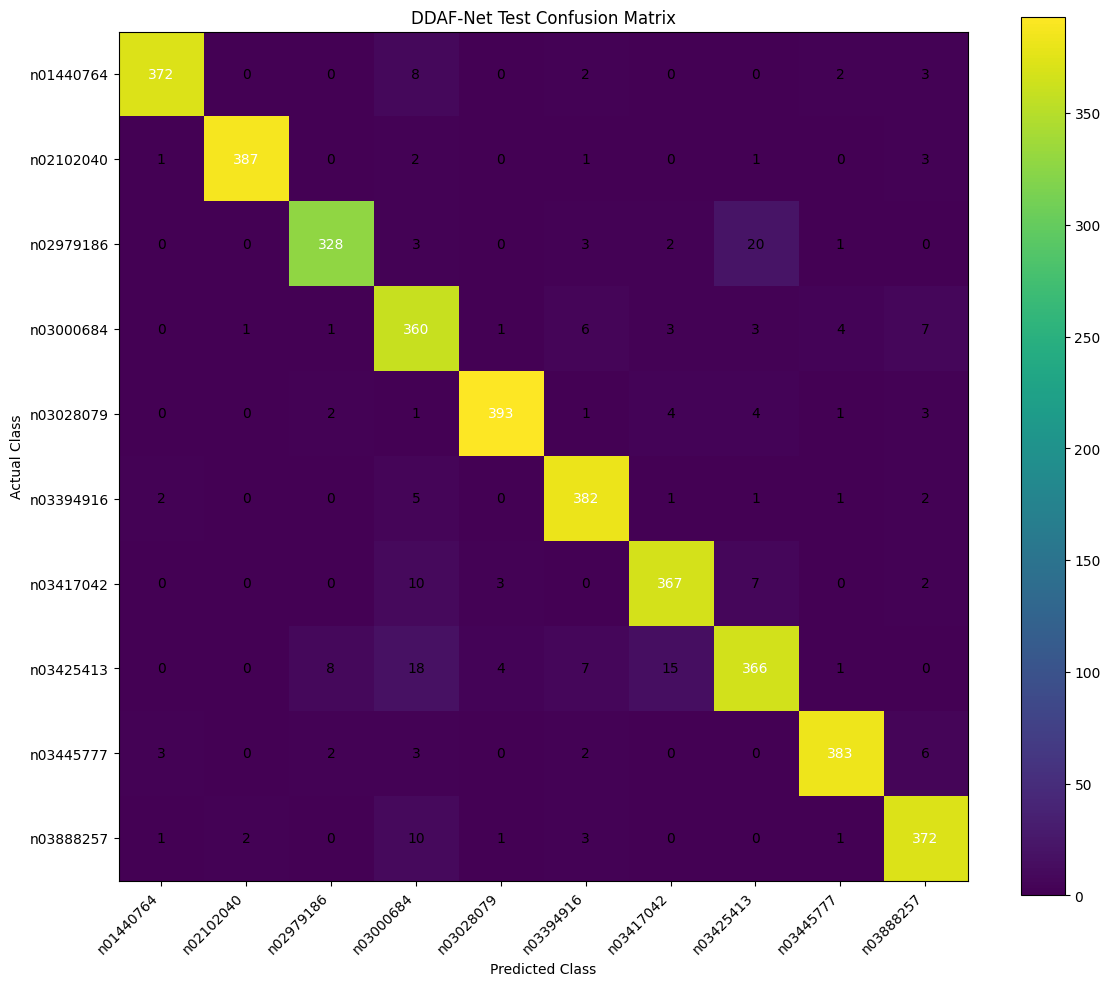


PER-CLASS ACCURACY
           accuracy  samples  accuracy_percent
n01440764    0.9612      387           96.1240
n02102040    0.9797      395           97.9747
n02979186    0.9188      357           91.8768
n03000684    0.9326      386           93.2642
n03028079    0.9609      409           96.0880
n03394916    0.9695      394           96.9543
n03417042    0.9434      389           94.3445
n03425413    0.8735      419           87.3508
n03445777    0.9599      399           95.9900
n03888257    0.9538      390           95.3846

DDAF-NET TEST EVALUATION COMPLETED
Test accuracy: 94.52%
Macro F1-score: 0.9455
Weighted F1-score: 0.9454

Saved evaluation files:
ddaf_classification_report.csv (0.00 MB)
ddaf_confusion_matrix.npy (0.00 MB)
ddaf_confusion_matrix.png (0.31 MB)
ddaf_per_class_accuracy.csv (0.00 MB)
ddaf_test_metrics.json (0.00 MB)
ddaf_test_predictions.csv (0.26 MB)

Evaluation ZIP: /kaggle/working/DDAF_Test_Evaluation.zip

All evaluation tasks completed successfully.


In [46]:

# ============================================================
# DDAF-NET: COMPLETE TEST SET EVALUATION
# Test images: 3,925
# Uses the already loaded best checkpoint and test dataset
# ============================================================

import os
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RESULT_DIR = Path("/kaggle/working/ddaf_evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 8

print("=" * 65)
print("DDAF-NET TEST EVALUATION")
print("=" * 65)

print("Device:", DEVICE)
print("Test samples:", len(test_dataset))

# ------------------------------------------------------------
# 2. PREPARE MODEL
# ------------------------------------------------------------

model.eval()
model.to(DEVICE)

# Do not train or update model parameters during evaluation.

# ------------------------------------------------------------
# 3. TEST PREDICTIONS
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

test_loader_eval = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

start_time = time.time()

with torch.inference_mode():

    for batch_index, (images, labels) in enumerate(test_loader_eval):

        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs, fusion_weights = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)

        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

        if (batch_index + 1) % 50 == 0:

            print(
                f"Processed {batch_index + 1}/"
                f"{len(test_loader_eval)} batches",
                flush=True
            )

evaluation_time = time.time() - start_time

# ------------------------------------------------------------
# 4. CALCULATE CLASSIFICATION METRICS
# ------------------------------------------------------------

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 5. PRINT FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)

print(f"Test Accuracy:          {test_accuracy * 100:.2f}%")
print(f"Macro Precision:        {test_precision:.4f}")
print(f"Macro Recall:           {test_recall:.4f}")
print(f"Macro F1-score:         {test_f1:.4f}")

print(f"Weighted Precision:     {weighted_precision:.4f}")
print(f"Weighted Recall:        {weighted_recall:.4f}")
print(f"Weighted F1-score:      {weighted_f1:.4f}")

print(f"Evaluation Time:        {evaluation_time:.2f} seconds")

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names = list(class_names)

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nCLASSIFICATION REPORT")
print("=" * 65)
print(report_df.round(4).to_string())

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(12, 10))

plt.imshow(cm, interpolation="nearest")
plt.title("DDAF-Net Test Confusion Matrix")
plt.colorbar()

ticks = np.arange(len(class_names))

plt.xticks(ticks, class_names, rotation=45, ha="right")
plt.yticks(ticks, class_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

threshold = cm.max() / 2 if cm.size else 0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()

confusion_path = RESULT_DIR / "ddaf_confusion_matrix.png"

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. PER-CLASS ACCURACY
# ------------------------------------------------------------

per_class_accuracy = {}

for index, name in enumerate(class_names):

    class_mask = all_labels == index

    if class_mask.sum() > 0:

        correct = np.sum(
            all_predictions[class_mask] == all_labels[class_mask]
        )

        accuracy = correct / class_mask.sum()

    else:
        accuracy = 0.0

    per_class_accuracy[name] = {
        "accuracy": float(accuracy),
        "samples": int(class_mask.sum())
    }

per_class_df = pd.DataFrame.from_dict(
    per_class_accuracy,
    orient="index"
)

per_class_df["accuracy_percent"] = (
    per_class_df["accuracy"] * 100
)

print("\nPER-CLASS ACCURACY")
print("=" * 65)
print(per_class_df.round(4).to_string())

# ------------------------------------------------------------
# 9. SAVE PREDICTIONS
# ------------------------------------------------------------

predictions_df = test_df[
    ["image_id", "label_text", "target"]
].copy()

predictions_df["predicted_index"] = all_predictions

predictions_df["predicted_class"] = [
    class_names[index]
    for index in all_predictions
]

predictions_df["correct"] = (
    predictions_df["target"]
    == predictions_df["predicted_index"]
)

predictions_df.to_csv(
    RESULT_DIR / "ddaf_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 10. SAVE METRICS
# ------------------------------------------------------------

metrics = {
    "model": "DDAF-Net",
    "checkpoint": "ddaf_best.pth",
    "test_samples": int(len(all_labels)),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(test_precision),
    "macro_recall": float(test_recall),
    "macro_f1": float(test_f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "evaluation_time_seconds": float(evaluation_time)
}

with open(
    RESULT_DIR / "ddaf_test_metrics.json",
    "w"
) as file:

    json.dump(metrics, file, indent=4)

report_df.to_csv(
    RESULT_DIR / "ddaf_classification_report.csv"
)

per_class_df.to_csv(
    RESULT_DIR / "ddaf_per_class_accuracy.csv"
)

np.save(
    RESULT_DIR / "ddaf_confusion_matrix.npy",
    cm
)

# ------------------------------------------------------------
# 11. SAVE COMPLETE RESULTS AS ZIP
# ------------------------------------------------------------

import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/DDAF_Test_Evaluation",
    "zip",
    RESULT_DIR
)

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DDAF-NET TEST EVALUATION COMPLETED")
print("=" * 65)

print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-score: {test_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

print("\nSaved evaluation files:")
for file in sorted(RESULT_DIR.iterdir()):

    print(
        file.name,
        f"({file.stat().st_size / (1024**2):.2f} MB)"
    )

print("\nEvaluation ZIP:", zip_path)
print("\nAll evaluation tasks completed successfully.")


In [47]:
from IPython.display import FileLink, display

display(FileLink('/kaggle/working/DDAF_Test_Evaluation.zip'))

/kaggle/working/DDAF_Test_Evaluation.zip

In [48]:
import os
import shutil
from IPython.display import display, FileLink

source = "/kaggle/working/DDAF_Test_Evaluation.zip"
destination = "/kaggle/working/DDAF_Test_Evaluation.zip"

print("File exists:", os.path.exists(source))

if os.path.exists(source):
    print("File size:", os.path.getsize(source) / (1024 * 1024), "MB")
    display(FileLink(destination))
else:
    print("ZIP file not found!")

File exists: True
File size: 0.26964759826660156 MB


/kaggle/working/DDAF_Test_Evaluation.zip

In [49]:
import os
import zipfile

files = [
    "ddaf_classification_report.csv",
    "ddaf_confusion_matrix.npy",
    "ddaf_confusion_matrix.png",
    "ddaf_per_class_accuracy.csv",
    "ddaf_test_metrics.json",
    "ddaf_test_predictions.csv"
]

output_dir = "/kaggle/working"
zip_path = os.path.join(output_dir, "DDAF_Test_Evaluation.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in files:
        path = os.path.join(output_dir, file)
        if os.path.exists(path):
            z.write(path, arcname=file)
            print("Added:", file)
        else:
            print("Missing:", file)

print("\nZIP created:", os.path.exists(zip_path))
print("ZIP size:", os.path.getsize(zip_path) / 1024, "KB")

Missing: ddaf_classification_report.csv
Missing: ddaf_confusion_matrix.npy
Missing: ddaf_confusion_matrix.png
Missing: ddaf_per_class_accuracy.csv
Missing: ddaf_test_metrics.json
Missing: ddaf_test_predictions.csv

ZIP created: True
ZIP size: 0.021484375 KB


In [50]:
import os

search_names = {
    "ddaf_classification_report.csv",
    "ddaf_confusion_matrix.npy",
    "ddaf_confusion_matrix.png",
    "ddaf_per_class_accuracy.csv",
    "ddaf_test_metrics.json",
    "ddaf_test_predictions.csv"
}

found = []

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file in search_names:
            path = os.path.join(root, file)
            found.append(path)
            print("FOUND:", path)

print("\nTotal files found:", len(found))

FOUND: /kaggle/working/ddaf_evaluation/ddaf_test_predictions.csv
FOUND: /kaggle/working/ddaf_evaluation/ddaf_per_class_accuracy.csv
FOUND: /kaggle/working/ddaf_evaluation/ddaf_confusion_matrix.npy
FOUND: /kaggle/working/ddaf_evaluation/ddaf_confusion_matrix.png
FOUND: /kaggle/working/ddaf_evaluation/ddaf_test_metrics.json
FOUND: /kaggle/working/ddaf_evaluation/ddaf_classification_report.csv

Total files found: 6


In [51]:
import os
import zipfile

folder = "/kaggle/working/ddaf_evaluation"
zip_path = "/kaggle/working/DDAF_Test_Evaluation.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in os.listdir(folder):
        full_path = os.path.join(folder, file)

        if os.path.isfile(full_path):
            z.write(full_path, arcname=file)
            print("Added:", file)

print("\nZIP successfully created!")
print("Location:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

Added: ddaf_test_predictions.csv
Added: ddaf_per_class_accuracy.csv
Added: ddaf_confusion_matrix.npy
Added: ddaf_confusion_matrix.png
Added: ddaf_test_metrics.json
Added: ddaf_classification_report.csv

ZIP successfully created!
Location: /kaggle/working/DDAF_Test_Evaluation.zip
Size: 276.12 KB


In [52]:
from IPython.display import display, FileLink

display(FileLink('/kaggle/working/DDAF_Test_Evaluation.zip'))

/kaggle/working/DDAF_Test_Evaluation.zip

In [53]:

import os

zip_path = "/kaggle/working/DDAF_Test_Evaluation.zip"

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size:", os.path.getsize(zip_path))

ZIP exists: True
ZIP size: 282746


In [54]:
%cd /kaggle/working

from IPython.display import FileLink, display

display(FileLink("DDAF_Test_Evaluation.zip"))

/kaggle/working


/kaggle/working/DDAF_Test_Evaluation.zip

In [55]:

import os
import zipfile
import json
from datetime import datetime

# ==========================================
# DDAF-NET COMPLETE RESEARCH BACKUP
# ==========================================

BASE = "/kaggle/working"

BACKUP = os.path.join(
    BASE, "DDAF_Net_COMPLETE_BACKUP.zip"
)

evaluation_dir = os.path.join(
    BASE, "ddaf_evaluation"
)

checkpoint_dir = os.path.join(
    BASE, "DDAF_Net_Checkpoints"
)

files_to_backup = [
    # Model checkpoints
    (
        os.path.join(checkpoint_dir, "ddaf_best.pth"),
        "checkpoints/ddaf_best.pth"
    ),
    (
        os.path.join(checkpoint_dir, "ddaf_latest.pth"),
        "checkpoints/ddaf_latest.pth"
    ),

    # Evaluation results
    (
        os.path.join(evaluation_dir, "ddaf_classification_report.csv"),
        "evaluation/ddaf_classification_report.csv"
    ),
    (
        os.path.join(evaluation_dir, "ddaf_confusion_matrix.npy"),
        "evaluation/ddaf_confusion_matrix.npy"
    ),
    (
        os.path.join(evaluation_dir, "ddaf_confusion_matrix.png"),
        "evaluation/ddaf_confusion_matrix.png"
    ),
    (
        os.path.join(evaluation_dir, "ddaf_per_class_accuracy.csv"),
        "evaluation/ddaf_per_class_accuracy.csv"
    ),
    (
        os.path.join(evaluation_dir, "ddaf_test_metrics.json"),
        "evaluation/ddaf_test_metrics.json"
    ),
    (
        os.path.join(evaluation_dir, "ddaf_test_predictions.csv"),
        "evaluation/ddaf_test_predictions.csv"
    )
]

# ==========================================
# CREATE BACKUP
# ==========================================

added = []
missing = []

with zipfile.ZipFile(
    BACKUP, "w", zipfile.ZIP_DEFLATED
) as archive:

    for source, destination in files_to_backup:

        if os.path.isfile(source):
            archive.write(source, destination)
            added.append(destination)
            print("BACKED UP:", destination)
        else:
            missing.append(source)
            print("MISSING:", source)

    manifest = {
        "project": "DDAF-Net",
        "backup_date": datetime.now().isoformat(),
        "files_included": added,
        "missing_files": missing,
        "test_accuracy": "94.52%",
        "macro_f1_score": "94.55%",
        "test_samples": 3925
    }

    archive.writestr(
        "backup_manifest.json",
        json.dumps(manifest, indent=4)
    )

# ==========================================
# VERIFY BACKUP
# ==========================================

print("\n================================")
print("DDAF-NET BACKUP VERIFICATION")
print("================================")

with zipfile.ZipFile(BACKUP, "r") as archive:

    corrupted = archive.testzip()

    if corrupted is None:
        print("ZIP INTEGRITY: PASSED")
    else:
        print("CORRUPTED FILE:", corrupted)

    print("\nFiles inside backup:")

    for name in archive.namelist():
        print(" -", name)

print("\nTotal files backed up:", len(added))
print("Missing files:", len(missing))
print(
    "Backup size:",
    round(os.path.getsize(BACKUP) / (1024 * 1024), 2),
    "MB"
)

print("\nBACKUP LOCATION:")
print(BACKUP)

if not missing and corrupted is None:
    print("\nSUCCESS: COMPLETE BACKUP VERIFIED!")
else:
    print("\nWARNING: CHECK MISSING FILES BEFORE LEAVING!")


BACKED UP: checkpoints/ddaf_best.pth
BACKED UP: checkpoints/ddaf_latest.pth
BACKED UP: evaluation/ddaf_classification_report.csv
BACKED UP: evaluation/ddaf_confusion_matrix.npy
BACKED UP: evaluation/ddaf_confusion_matrix.png
BACKED UP: evaluation/ddaf_per_class_accuracy.csv
BACKED UP: evaluation/ddaf_test_metrics.json
BACKED UP: evaluation/ddaf_test_predictions.csv

DDAF-NET BACKUP VERIFICATION
ZIP INTEGRITY: PASSED

Files inside backup:
 - checkpoints/ddaf_best.pth
 - checkpoints/ddaf_latest.pth
 - evaluation/ddaf_classification_report.csv
 - evaluation/ddaf_confusion_matrix.npy
 - evaluation/ddaf_confusion_matrix.png
 - evaluation/ddaf_per_class_accuracy.csv
 - evaluation/ddaf_test_metrics.json
 - evaluation/ddaf_test_predictions.csv
 - backup_manifest.json

Total files backed up: 8
Missing files: 0
Backup size: 533.25 MB

BACKUP LOCATION:
/kaggle/working/DDAF_Net_COMPLETE_BACKUP.zip

SUCCESS: COMPLETE BACKUP VERIFIED!


In [56]:

from IPython.display import FileLink, display
import os

file_path = "/kaggle/working/DDAF_Net_COMPLETE_BACKUP.zip"

if os.path.exists(file_path):
    size = os.path.getsize(file_path) / (1024 * 1024)

    print("DDAF-Net Complete Backup Found!")
    print(f"File size: {size:.2f} MB")
    print("Click the link below to download:")

    display(FileLink(file_path))
else:
    print("ERROR: Backup ZIP not found!")


DDAF-Net Complete Backup Found!
File size: 533.25 MB
Click the link below to download:


/kaggle/working/DDAF_Net_COMPLETE_BACKUP.zip

In [57]:

import os
from IPython.display import display, HTML

path = "/kaggle/working/DDAF_Net_COMPLETE_BACKUP.zip"

if os.path.exists(path):
    print("Backup verified:", os.path.getsize(path) / (1024*1024), "MB")

    display(HTML("""
    <h3>DDAF-Net Complete Backup</h3>
    <p>Open the Kaggle Output panel on the right.</p>
    <p>Find DDAF_Net_COMPLETE_BACKUP.zip</p>
    <p>Use the three-dot menu and select Download.</p>
    """))
else:
    print("Backup not found!")


Backup verified: 533.2507848739624 MB


In [58]:
!pip -q install gdown

In [59]:

import os
import zipfile

source = "/kaggle/working/DDAF_Net_COMPLETE_BACKUP.zip"
output_dir = "/kaggle/working/DDAF_BACKUP_PARTS"

os.makedirs(output_dir, exist_ok=True)

# Split into 100 MB parts
part_size = 100 * 1024 * 1024

with open(source, "rb") as f:
    part_number = 1

    while True:
        data = f.read(part_size)
        if not data:
            break

        part_path = os.path.join(
            output_dir,
            f"DDAF_BACKUP_PART_{part_number:02d}.bin"
        )

        with open(part_path, "wb") as part:
            part.write(data)

        print("Created:", part_path,
              f"({len(data)/(1024*1024):.2f} MB)")

        part_number += 1

print("\nAll backup parts created!")
print("Total parts:", part_number - 1)


Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_01.bin (100.00 MB)
Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_02.bin (100.00 MB)
Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_03.bin (100.00 MB)
Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_04.bin (100.00 MB)
Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_05.bin (100.00 MB)
Created: /kaggle/working/DDAF_BACKUP_PARTS/DDAF_BACKUP_PART_06.bin (33.25 MB)

All backup parts created!
Total parts: 6


In [60]:

import os
import shutil

BASE = "/kaggle/working"
DEST = os.path.join(BASE, "DDAF_INDIVIDUAL_BACKUP")

os.makedirs(DEST, exist_ok=True)

files = {
    "ddaf_best.pth":
        f"{BASE}/DDAF_Net_Checkpoints/ddaf_best.pth",

    "ddaf_latest.pth":
        f"{BASE}/DDAF_Net_Checkpoints/ddaf_latest.pth",

    "ddaf_classification_report.csv":
        f"{BASE}/ddaf_evaluation/ddaf_classification_report.csv",

    "ddaf_confusion_matrix.npy":
        f"{BASE}/ddaf_evaluation/ddaf_confusion_matrix.npy",

    "ddaf_confusion_matrix.png":
        f"{BASE}/ddaf_evaluation/ddaf_confusion_matrix.png",

    "ddaf_per_class_accuracy.csv":
        f"{BASE}/ddaf_evaluation/ddaf_per_class_accuracy.csv",

    "ddaf_test_metrics.json":
        f"{BASE}/ddaf_evaluation/ddaf_test_metrics.json",

    "ddaf_test_predictions.csv":
        f"{BASE}/ddaf_evaluation/ddaf_test_predictions.csv"
}

print("CREATING INDIVIDUAL BACKUP FILES\n")

for name, source in files.items():
    if os.path.isfile(source):
        destination = os.path.join(DEST, name)
        shutil.copy2(source, destination)

        size = os.path.getsize(destination) / (1024 * 1024)
        print(f"READY: {name} | {size:.2f} MB")
    else:
        print("MISSING:", source)

print("\nALL AVAILABLE FILES:")
for name in os.listdir(DEST):
    print(os.path.join(DEST, name))


CREATING INDIVIDUAL BACKUP FILES

READY: ddaf_best.pth | 291.86 MB
READY: ddaf_latest.pth | 291.86 MB
READY: ddaf_classification_report.csv | 0.00 MB
READY: ddaf_confusion_matrix.npy | 0.00 MB
READY: ddaf_confusion_matrix.png | 0.31 MB
READY: ddaf_per_class_accuracy.csv | 0.00 MB
READY: ddaf_test_metrics.json | 0.00 MB
READY: ddaf_test_predictions.csv | 0.26 MB

ALL AVAILABLE FILES:
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_latest.pth
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_test_predictions.csv
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_per_class_accuracy.csv
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_confusion_matrix.npy
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_best.pth
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_confusion_matrix.png
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_test_metrics.json
/kaggle/working/DDAF_INDIVIDUAL_BACKUP/ddaf_classification_report.csv


In [61]:

from IPython.display import display, HTML
import os
from urllib.parse import quote

folder = "/kaggle/working/DDAF_INDIVIDUAL_BACKUP"

files = [
    "ddaf_best.pth",
    "ddaf_latest.pth",
    "ddaf_classification_report.csv",
    "ddaf_confusion_matrix.npy",
    "ddaf_confusion_matrix.png",
    "ddaf_per_class_accuracy.csv",
    "ddaf_test_metrics.json",
    "ddaf_test_predictions.csv"
]

print("DDAF-NET INDIVIDUAL DOWNLOADS")
print("=" * 40)

for name in files:
    path = os.path.join(folder, name)

    if os.path.exists(path):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"{name} — {size:.2f} MB")

        display(HTML(
            f'<a href="/files/{quote(path)}" '
            f'download="{name}">{name} - DOWNLOAD</a>'
        ))
    else:
        print("MISSING:", name)


DDAF-NET INDIVIDUAL DOWNLOADS
ddaf_best.pth — 291.86 MB


ddaf_latest.pth — 291.86 MB


ddaf_classification_report.csv — 0.00 MB


ddaf_confusion_matrix.npy — 0.00 MB


ddaf_confusion_matrix.png — 0.31 MB


ddaf_per_class_accuracy.csv — 0.00 MB


ddaf_test_metrics.json — 0.00 MB


ddaf_test_predictions.csv — 0.26 MB


In [1]:

import torch
import os

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

checkpoint_dir = "/kaggle/working/DDAF_Net_Checkpoints"

for name in ["ddaf_best.pth", "ddaf_latest.pth"]:
    path = os.path.join(checkpoint_dir, name)
    print(name, ":", os.path.exists(path))

    if os.path.exists(path):
        print("Size:", round(os.path.getsize(path)/1024**2, 2), "MB")


CUDA available: True
GPU: Tesla T4
ddaf_best.pth : False
ddaf_latest.pth : False


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

In [3]:
import os

print("Searching Kaggle directories...\n")

for base in ["/kaggle/input", "/kaggle/working"]:
    print(f"\nChecking: {base}")

    for root, dirs, files in os.walk(base):
        for file in files:
            if file.endswith(".pth"):
                path = os.path.join(root, file)
                print("FOUND:", path)

print("\nSearch completed.")

Searching Kaggle directories...


Checking: /kaggle/input

Checking: /kaggle/working

Search completed.


In [4]:
import os

checkpoint_dir = "/kaggle/working/DDAF_Net_Checkpoints"

for name in ["ddaf_best.pth", "ddaf_latest.pth"]:
    path = os.path.join(checkpoint_dir, name)

    print(
        name,
        "| Exists:", os.path.exists(path),
        "| Size:", round(os.path.getsize(path)/1024**2, 2), "MB"
        if os.path.exists(path) else ""
    )

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/DDAF_Net_Checkpoints/ddaf_best.pth'

In [5]:
import os

print("SEARCHING ATTACHED KAGGLE INPUTS")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pth"):
            path = os.path.join(root, file)
            print("FOUND:", path)
            print("SIZE:", round(os.path.getsize(path)/1024**2, 2), "MB")

SEARCHING ATTACHED KAGGLE INPUTS


In [6]:

import os

locations = [
    "/kaggle/input",
    "/kaggle/working",
    "/kaggle/working/DDAF_Net_Checkpoints",
    "/kaggle/working/ddaf_training"
]

for folder in locations:
    print("\nFOLDER:", folder)

    if os.path.exists(folder):
        for item in os.listdir(folder):
            path = os.path.join(folder, item)

            if os.path.isfile(path):
                print("FILE:", item,
                      f"({os.path.getsize(path)/(1024*1024):.2f} MB)")
            else:
                print("DIR:", item)
    else:
        print("NOT FOUND")



FOLDER: /kaggle/input
DIR: datasets

FOLDER: /kaggle/working
DIR: .virtual_documents

FOLDER: /kaggle/working/DDAF_Net_Checkpoints
NOT FOUND

FOLDER: /kaggle/working/ddaf_training
NOT FOUND


In [7]:
import os

base = "/kaggle/input/datasets"

for root, dirs, files in os.walk(base):
    print("\nFolder:", root)

    for file in files:
        print("  ", file)


Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/agnihotrampramodh

Folder: /kaggle/input/datasets/agnihotrampramodh/imagenette2-320
   imagenette2-320 (1).tgz

Folder: /kaggle/input/datasets/agnihotrampramodh/split-manifest
   split_manifest (1).csv

Folder: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-research

Folder: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-research/DDAF_Net_Research
   ddaf_net_initial.pt

Folder: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial
   ddaf_net_initial.pt

Folder: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/DDAF_Net_Research-20261114T091620Z-1-001

Folder: /kaggle/input/datasets/agnihotrampramodh/ddaf-net-initial/DDAF_Net_Research-20261114T091620Z-1-001/DDAF_Net_Research
   ddaf_net_initial.pt


In [8]:
import torch
import os

path = "/kaggle/input/datasets/agnihotrampramodh/ddaf-net-research/DDAF_Net_Research/ddaf_net_initial.pt"

print("File exists:", os.path.exists(path))

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(key)

File exists: True

Checkpoint type: <class 'collections.OrderedDict'>

Checkpoint keys:
shared.0.weight
shared.1.weight
shared.1.bias
shared.1.running_mean
shared.1.running_var
shared.1.num_batches_tracked
shared.4.0.conv1.weight
shared.4.0.bn1.weight
shared.4.0.bn1.bias
shared.4.0.bn1.running_mean
shared.4.0.bn1.running_var
shared.4.0.bn1.num_batches_tracked
shared.4.0.conv2.weight
shared.4.0.bn2.weight
shared.4.0.bn2.bias
shared.4.0.bn2.running_mean
shared.4.0.bn2.running_var
shared.4.0.bn2.num_batches_tracked
shared.4.1.conv1.weight
shared.4.1.bn1.weight
shared.4.1.bn1.bias
shared.4.1.bn1.running_mean
shared.4.1.bn1.running_var
shared.4.1.bn1.num_batches_tracked
shared.4.1.conv2.weight
shared.4.1.bn2.weight
shared.4.1.bn2.bias
shared.4.1.bn2.running_mean
shared.4.1.bn2.running_var
shared.4.1.bn2.num_batches_tracked
compression_branch.0.0.conv1.weight
compression_branch.0.0.bn1.weight
compression_branch.0.0.bn1.bias
compression_branch.0.0.bn1.running_mean
compression_branch.0.0.bn1.r

In [9]:

import os
import json

notebook_path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

print("Notebook source exists:", os.path.exists(notebook_path))

if os.path.exists(notebook_path):
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    print("\nNOTEBOOK CODE STRUCTURE\n")

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        matches = [
            line for line in lines
            if any(word in line.lower() for word in [
                "class ddaf",
                "def train",
                "def validate",
                "optimizer",
                "scheduler",
                "load_state_dict",
                "save_checkpoint"
            ])
        ]

        if matches:
            print(f"\n--- CELL {i} ---")
            for line in matches[:15]:
                print(line[:200])


Notebook source exists: True


JSONDecodeError: Expecting value: line 2 column 1 (char 1)

In [10]:

import os

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

print("File size:", os.path.getsize(path), "bytes")

with open(path, "rb") as f:
    content = f.read(3000)

print("\nFirst 3000 bytes:")
print(repr(content))


File size: 96185 bytes

First 3000 bytes:
b'\n# ============================================================\n# STEP 4A: ZIP ARCHIVE AUDIT\n# Google Drive + GitHub\n# Read-only inspection: does not extract or modify archives\n# ============================================================\n\nfrom google.colab import drive\nfrom pathlib import Path\nimport subprocess\nimport zipfile\nimport os\n\n# 1. Mount Google Drive\ndrive.mount("/content/drive")\n\n# 2. Define locations\nDRIVE_ROOT = Path(\n    "/content/drive/MyDrive/CartoonizationResearchBackup"\n)\n\nGITHUB_URL = (\n    "https://github.com/Karthik6-cpu/"\n    "cartoonization-robustness-study.git"\n)\n\nGITHUB_ROOT = Path("/content/github_repo_audit")\n\n# 3. Scan ZIP archives in Google Drive\nprint("=" * 65)\nprint("GOOGLE DRIVE ZIP ARCHIVE AUDIT")\nprint("=" * 65)\n\ndrive_zips = list(DRIVE_ROOT.rglob("*.zip"))\n\nprint("ZIP archives found:", len(drive_zips))\n\nfor i, path in enumerate(drive_zips, 1):\n    size_mb = path.stat()

In [11]:

import os

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith((".py", ".ipynb")):
            print(os.path.join(root, file))


/kaggle/working/.virtual_documents/__notebook_source__.ipynb


In [12]:

path = "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"

with open(path, "r", encoding="utf-8") as f:
    source = f.read()

keywords = [
    "class DDAFNet",
    "class DDAF_Net",
    "compression_branch",
    "adaptive_fusion",
    "def train_one_epoch",
    "optimizer",
    "ddaf_best.pth"
]

for keyword in keywords:
    print(f"\n{keyword}: {source.find(keyword)}")

print("\nLast 2000 characters:")
print(source[-2000:])



class DDAFNet: 29622

class DDAF_Net: -1

compression_branch: 30155

adaptive_fusion: 30600

def train_one_epoch: -1

optimizer: 6577

ddaf_best.pth: 69823

Last 2000 characters:
 "ddaf_best.pth":
        f"{BASE}/DDAF_Net_Checkpoints/ddaf_best.pth",

    "ddaf_latest.pth":
        f"{BASE}/DDAF_Net_Checkpoints/ddaf_latest.pth",

    "ddaf_classification_report.csv":
        f"{BASE}/ddaf_evaluation/ddaf_classification_report.csv",

    "ddaf_confusion_matrix.npy":
        f"{BASE}/ddaf_evaluation/ddaf_confusion_matrix.npy",

    "ddaf_confusion_matrix.png":
        f"{BASE}/ddaf_evaluation/ddaf_confusion_matrix.png",

    "ddaf_per_class_accuracy.csv":
        f"{BASE}/ddaf_evaluation/ddaf_per_class_accuracy.csv",

    "ddaf_test_metrics.json":
        f"{BASE}/ddaf_evaluation/ddaf_test_metrics.json",

    "ddaf_test_predictions.csv":
        f"{BASE}/ddaf_evaluation/ddaf_test_predictions.csv"
}

print("CREATING INDIVIDUAL BACKUP FILES\n")

for name, source in files.items():
    if o

In [13]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".pth"):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{file} | {size_mb:.2f} MB")
            print(f"Path: {path}\n")


ddaf_best.pth | 291.86 MB
Path: /kaggle/input/datasets/agnihotrampramodh/check-points/ddaf_best.pth

ddaf_latest.pth | 291.86 MB
Path: /kaggle/input/datasets/agnihotrampramodh/check-points/ddaf_latest.pth



In [14]:

import os
import glob
import shutil

CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

for filename in ["ddaf_best.pth", "ddaf_latest.pth"]:
    matches = glob.glob(
        f"/kaggle/input/**/{filename}",
        recursive=True
    )

    if not matches:
        print(f"NOT FOUND: {filename}")
        continue

    source = matches[0]
    destination = os.path.join(CHECKPOINT_DIR, filename)

    shutil.copy2(source, destination)

    print(f"Copied: {filename}")
    print(f"Size: {os.path.getsize(destination) / (1024**2):.2f} MB")


Copied: ddaf_best.pth
Size: 291.86 MB
Copied: ddaf_latest.pth
Size: 291.86 MB


In [15]:

import torch
import os

for filename in ["ddaf_best.pth", "ddaf_latest.pth"]:
    path = f"/kaggle/working/checkpoints/{filename}"

    if os.path.exists(path):
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print(f"\n{filename}")
        print("Type:", type(checkpoint))

        if isinstance(checkpoint, dict):
            print("Keys:", list(checkpoint.keys())[:30])



ddaf_best.pth
Type: <class 'dict'>
Keys: ['epoch', 'step', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'class_names', 'class_to_idx', 'val_accuracy']

ddaf_latest.pth
Type: <class 'dict'>
Keys: ['epoch', 'step', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'class_names', 'class_to_idx', 'val_accuracy']


In [16]:

import os
import torch

checkpoint_dir = "/kaggle/working/checkpoints"

for filename in ["ddaf_best.pth", "ddaf_latest.pth"]:
    path = os.path.join(checkpoint_dir, filename)

    print("\n" + "=" * 50)
    print("CHECKPOINT:", filename)

    if not os.path.exists(path):
        print("FILE NOT FOUND:", path)
        continue

    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    print("Epoch:", ckpt["epoch"])
    print("Step:", ckpt["step"])
    print("Validation Accuracy:", ckpt["val_accuracy"])
    print("Number of classes:", len(ckpt["class_names"]))

    optimizer_state = ckpt["optimizer_state_dict"]
    for group in optimizer_state["param_groups"]:
        print("Optimizer learning rate:", group["lr"])
        print("Weight decay:", group.get("weight_decay"))

    print("Optimizer state entries:", len(optimizer_state["state"]))
    print("Scaler state:", ckpt["scaler_state_dict"])



CHECKPOINT: ddaf_best.pth
Epoch: 1
Step: 1006
Validation Accuracy: 95.00351864883885
Number of classes: 10
Optimizer learning rate: 1e-05
Weight decay: 0.0001
Optimizer state entries: 129
Scaler state: {'scale': 32768.0, 'growth_factor': 2.0, 'backoff_factor': 0.5, 'growth_interval': 2000, '_growth_tracker': 995}

CHECKPOINT: ddaf_latest.pth
Epoch: 1
Step: 1006
Validation Accuracy: 95.00351864883885
Number of classes: 10
Optimizer learning rate: 1e-05
Weight decay: 0.0001
Optimizer state entries: 129
Scaler state: {'scale': 32768.0, 'growth_factor': 2.0, 'backoff_factor': 0.5, 'growth_interval': 2000, '_growth_tracker': 995}


In [21]:

# RESUME TRAINING — insert after model, optimizer and scaler creation

checkpoint_path = "/kaggle/working/checkpoints/ddaf_latest.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

if checkpoint.get("scaler_state_dict"):
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

start_epoch = checkpoint["epoch"] + 1
global_step = checkpoint["step"]

print("Checkpoint restored successfully!")
print("Resume from epoch:", start_epoch)
print("Previous global step:", global_step)
print("Previous validation accuracy:", checkpoint["val_accuracy"])


NameError: name 'model' is not defined

In [18]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


Device: cuda
GPU: Tesla T4


In [20]:

print("DDAFNet defined:", "DDAFNet" in globals())
print("Model created:", "model" in globals())
print("Optimizer created:", "optimizer" in globals())
print("Scaler created:", "scaler" in globals())

print("\nAvailable model-related variables:")
for name in globals():
    if any(word in name.lower() for word in ["model", "optimizer", "scaler"]):
        print(name)


DDAFNet defined: False
Model created: False
Optimizer created: False
Scaler created: False

Available model-related variables:
optimizer_state


In [22]:

from pathlib import Path
import re

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

print("Source file exists:", source_path.exists())

if source_path.exists():
    source = source_path.read_text(encoding="utf-8")

    print("Source size:", len(source), "characters")

    match = re.search(r"(?m)^class DDAFNet\b", source)

    if match:
        start = match.start()
        next_match = re.search(
            r"(?m)^(?:class |def )",
            source[match.end():]
        )

        end = (
            match.end() + next_match.start()
            if next_match else len(source)
        )

        print("\n========== COMPLETE DDAFNet CLASS ==========\n")
        print(source[start:end])
    else:
        print("\nDDAFNet class not found.")

else:
    print("\nAvailable files in .virtual_documents:")

    folder = Path("/kaggle/working/.virtual_documents")

    if folder.exists():
        for item in folder.iterdir():
            print(item.name)
    else:
        print("Folder does not exist.")


Source file exists: True
Source size: 96181 characters

========== COMPLETE DDAFNet CLASS ==========

class DDAFNet(nn.Module):

    def __init__(self, num_classes=10, pretrained=True):

        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        backbone = models.resnet18(weights=weights)

        # Shared feature extraction
        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        # Independent feature branches
        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        # Initialize style branch independently
        style_backbone = models.resnet18(weights=weights)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            

In [23]:

from pathlib import Path
import re

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)
source = source_path.read_text(encoding="utf-8")

def extract_class(class_name):
    pattern = rf"(?m)^class {re.escape(class_name)}\b"
    match = re.search(pattern, source)

    if not match:
        print(f"\n{class_name}: NOT FOUND")
        return

    start = match.start()
    next_match = re.search(
        r"(?m)^class ",
        source[match.end():]
    )

    end = match.end() + next_match.start() if next_match else len(source)

    print(f"\n{'='*60}")
    print(f"CLASS: {class_name}")
    print("="*60)
    print(source[start:end].rstrip())

extract_class("AdaptiveFeatureFusion")
extract_class("MultiScaleFeatureRefinement")



CLASS: AdaptiveFeatureFusion
class AdaptiveFeatureFusion(nn.Module):
    """
    Learns the relative contribution of compression-aware
    and style-aware features.
    """

    def __init__(self, channels=512):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):

        combined = torch.cat(
            [compression_features, style_features],
            dim=1
        )

        weights = F.softmax(self.gate(combined), dim=1)

        compression_weight = weights[:, 0:1]
        style_weight = weights[:, 1:2]

        fused = (
            compression_weight * compression_features
            + style_weight * style_features
        )

        return fused, weights

CLASS: MultiScaleFeatureRefinement
class MultiScaleFeatureRefinement(nn.Module):
    """
    Refines fus

In [24]:

keywords = [
    "optimizer =",
    "GradScaler",
    "scheduler =",
    "for epoch in",
    "train_one_epoch",
    "DataLoader",
    "criterion =",
    "optimizer.step()",
    "torch.save("
]

for keyword in keywords:
    positions = [
        m.start()
        for m in re.finditer(re.escape(keyword), source)
    ]

    print(f"\n{'='*55}")
    print("SEARCH:", keyword, "| Occurrences:", len(positions))

    for pos in positions[-2:]:
        print(source[max(0, pos-350):pos+900])
        print("-"*35)



SEARCH: optimizer = | Occurrences: 1
pe:", tuple(sample_output.shape))
print("Fusion weights shape:", tuple(sample_weights.shape))

del sample_images, sample_labels, sample_output, sample_weights

# ------------------------------------------------------------
# 8. TRAINING CONFIGURATION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

best_val_accuracy = 0.0

latest_path = SAVE_DIR / "ddaf_latest.pth"
best_path = SAVE_DIR / "ddaf_best.pth"

# ------------------------------------------------------------
# 9. CHECKPOINT SAVING FUNCTION
# ------------------------------------------------------------

def save_checkpoint(path, epoch, step, val_accuracy=None):

    checkpoint_data = {
        "epoch": epoch,
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer

In [25]:

from pathlib import Path
import re

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)
source = source_path.read_text(encoding="utf-8")
lines = source.splitlines()

# 1. Find original configuration assignments
print("=" * 65)
print("ORIGINAL TRAINING CONFIGURATION")
print("=" * 65)

variables = [
    "LEARNING_RATE",
    "WEIGHT_DECAY",
    "EPOCHS",
    "BATCH_SIZE",
    "SAVE_DIR",
    "class_names",
    "class_to_idx",
    "train_loader",
    "val_loader",
]

for variable in variables:
    print(f"\n--- {variable} ---")
    found = False

    for i, line in enumerate(lines):
        if re.search(
            rf"^\s*{re.escape(variable)}\s*=",
            line
        ):
            print(f"Line {i+1}:")
            print("\n".join(lines[i:i+5]))
            found = True

    if not found:
        print("Assignment not found.")

# 2. Extract the complete original training loop
print("\n" + "=" * 65)
print("ORIGINAL TRAINING LOOP")
print("=" * 65)

match = re.search(
    r"(?m)^#\s*10\.\s*TRAINING LOOP",
    source
)

if match:
    start = match.start()
    print(source[start:start+14000])
else:
    print("Training loop heading not found.")

# 3. Find checkpoint save calls
print("\n" + "=" * 65)
print("CHECKPOINT SAVE CALLS")
print("=" * 65)

for i, line in enumerate(lines):
    if "save_checkpoint(" in line and not line.lstrip().startswith("def "):
        print(f"\nLine {i+1}:")
        print("\n".join(lines[i:i+5]))


ORIGINAL TRAINING CONFIGURATION

--- LEARNING_RATE ---
Line 2428:
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
SAVE_EVERY = 100


--- WEIGHT_DECAY ---
Line 2429:
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
SAVE_EVERY = 100

print("Device:", DEVICE)

--- EPOCHS ---
Line 2427:
EPOCHS = 1
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
SAVE_EVERY = 100

--- BATCH_SIZE ---
Line 2426:
BATCH_SIZE = 8
EPOCHS = 1
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
Line 3173:
BATCH_SIZE = 8

print("=" * 65)
print("DDAF-NET TEST EVALUATION")
print("=" * 65)

--- SAVE_DIR ---
Line 1303:
SAVE_DIR = Path("/content/drive/MyDrive/DDAF_Net_Research")

SAVE_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
Line 2422:
SAVE_DIR = Path("/kaggle/working/ddaf_training")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 160
BATCH_SIZE = 8

--- class_names ---
Line 2632:
class_names = sorted(df["label_text"].unique())

if len(class_names) != 10:
    raise ValueError(
        f"Expect

In [26]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import ResNet18_Weights
from pathlib import Path

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# 1. Adaptive Feature Fusion
class AdaptiveFeatureFusion(nn.Module):
    def __init__(self, channels=512):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):
        combined = torch.cat(
            [compression_features, style_features], dim=1
        )
        weights = F.softmax(self.gate(combined), dim=1)
        fused = (
            weights[:, 0:1] * compression_features
            + weights[:, 1:2] * style_features
        )
        return fused, weights


# 2. Multi-scale Refinement
class MultiScaleFeatureRefinement(nn.Module):
    def __init__(self, channels=512):
        super().__init__()

        self.branch1 = nn.Sequential(
            nn.Conv2d(channels, 256, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(channels, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(channels, 256, 3, padding=2, dilation=2),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(768, channels, 1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        f1 = self.branch1(x)
        f2 = self.branch2(x)
        f3 = self.branch3(x)
        return self.fusion(torch.cat([f1, f2, f3], dim=1))


# 3. DDAF-Net
class DDAFNet(nn.Module):
    def __init__(self, num_classes=10, pretrained=False):
        super().__init__()

        weights = ResNet18_Weights.DEFAULT if pretrained else None
        backbone = models.resnet18(weights=weights)

        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        style_backbone = models.resnet18(weights=weights)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            style_backbone.layer4
        )

        self.adaptive_fusion = AdaptiveFeatureFusion(512)
        self.refinement = MultiScaleFeatureRefinement(512)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x, return_weights=False):
        shared_features = self.shared(x)

        compression_map = self.compression_branch(shared_features)
        style_map = self.style_branch(shared_features)

        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        fused_features, weights = self.adaptive_fusion(
            compression_features, style_features
        )

        fused_map = (
            weights[:, 0:1, None, None] * compression_map
            + weights[:, 1:2, None, None] * style_map
        )

        refined_map = self.refinement(fused_map)

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        output = self.classifier(fused_features + refined_features)

        if return_weights:
            return output, weights

        return output


# 4. Initialize model and optimizer
model = DDAFNet(num_classes=10, pretrained=False).to(DEVICE)

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler(
    "cuda", enabled=(DEVICE.type == "cuda")
)

criterion = nn.CrossEntropyLoss()

# 5. Restore latest checkpoint
checkpoint_path = Path(
    "/kaggle/working/checkpoints/ddaf_latest.pth"
)

assert checkpoint_path.exists(), "Latest checkpoint not found!"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

if checkpoint.get("scaler_state_dict"):
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

class_names = checkpoint["class_names"]
class_to_idx = checkpoint["class_to_idx"]

# Original save function stores epoch + 1.
start_epoch = int(checkpoint["epoch"])
global_step = int(checkpoint["step"])

best_checkpoint = torch.load(
    "/kaggle/working/checkpoints/ddaf_best.pth",
    map_location="cpu",
    weights_only=False
)

best_val_accuracy = float(
    best_checkpoint["val_accuracy"] or 0.0
)

print("\nMODEL RESTORED SUCCESSFULLY")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Global step:", global_step)
print("Best validation accuracy:", best_val_accuracy)
print("Classes:", class_names)
print("Optimizer state entries:", len(optimizer.state))
print("Next epoch index:", start_epoch)


Device: cuda

MODEL RESTORED SUCCESSFULLY
Checkpoint epoch: 1
Global step: 1006
Best validation accuracy: 95.00351864883885
Classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Optimizer state entries: 129
Next epoch index: 1


In [27]:

print("Train loader exists:", "train_loader" in globals())
print("Validation loader exists:", "val_loader" in globals())

if "train_loader" in globals() and "val_loader" in globals():
    print("Training batches:", len(train_loader))
    print("Validation batches:", len(val_loader))
    print("Training images:", len(train_loader.dataset))
    print("Validation images:", len(val_loader.dataset))
else:
    print("Dataset setup must be executed before training.")


Train loader exists: False
Validation loader exists: False
Dataset setup must be executed before training.


In [28]:

from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

source = source_path.read_text(encoding="utf-8")
lines = source.splitlines()

# Print original dataset setup, transforms and DataLoaders
print("\n========== ORIGINAL DATASET PIPELINE ==========\n")

for i in range(2480, 2795):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")



========== ORIGINAL DATASET PIPELINE ==========

2481:             nn.Conv2d(channels, 256, kernel_size=1),
2482:             nn.BatchNorm2d(256),
2483:             nn.ReLU(inplace=True)
2484:         )
2485: 
2486:         self.branch2 = nn.Sequential(
2487:             nn.Conv2d(channels, 256, kernel_size=3, padding=1),
2488:             nn.BatchNorm2d(256),
2489:             nn.ReLU(inplace=True)
2490:         )
2491: 
2492:         self.branch3 = nn.Sequential(
2493:             nn.Conv2d(
2494:                 channels,
2495:                 256,
2496:                 kernel_size=3,
2497:                 padding=2,
2498:                 dilation=2
2499:             ),
2500:             nn.BatchNorm2d(256),
2501:             nn.ReLU(inplace=True)
2502:         )
2503: 
2504:         self.fusion = nn.Sequential(
2505:             nn.Conv2d(768, 512, kernel_size=1),
2506:             nn.BatchNorm2d(512),
2507:             nn.ReLU(inplace=True)
2508:         )
2509: 
2510:     def fo

In [29]:

from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)
lines = source_path.read_text(encoding="utf-8").splitlines()

print("ORIGINAL DATASET CONFIGURATION")
for i in range(2410, 2445):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")

print("\nAVAILABLE KAGGLE INPUTS")
for p in Path("/kaggle/input").rglob("*"):
    if p.is_file() and (
        p.suffix.lower() in [".csv", ".tgz", ".tar", ".zip"]
    ):
        print(p)


ORIGINAL DATASET CONFIGURATION
2411: 
2412: MANIFEST = Path(
2413:     "/kaggle/input/datasets/agnihotrampramodh/"
2414:     "split-manifest/split_manifest (1).csv"
2415: )
2416: 
2417: CHECKPOINT = Path(
2418:     "/kaggle/input/datasets/agnihotrampramodh/"
2419:     "ddaf-net-initial/ddaf_net_initial.pt"
2420: )
2421: 
2422: SAVE_DIR = Path("/kaggle/working/ddaf_training")
2423: SAVE_DIR.mkdir(parents=True, exist_ok=True)
2424: 
2425: IMG_SIZE = 160
2426: BATCH_SIZE = 8
2427: EPOCHS = 1
2428: LEARNING_RATE = 1e-5
2429: WEIGHT_DECAY = 1e-4
2430: NUM_WORKERS = 2
2431: SAVE_EVERY = 100
2432: 
2433: print("Device:", DEVICE)
2434: 
2435: if DEVICE.type != "cuda":
2436:     raise RuntimeError("GPU is not enabled. Enable GPU in Kaggle settings.")
2437: 
2438: if not DATA_ROOT.exists():
2439:     raise FileNotFoundError(f"Dataset folder not found: {DATA_ROOT}")
2440: 
2441: if not MANIFEST.exists():
2442:     raise FileNotFoundError(f"Manifest not found: {MANIFEST}")
2443: 
2444: if not CHEC

In [30]:

# Exact original training architecture
class DDAFNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        backbone = models.resnet18(weights=None)

        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        style_backbone = models.resnet18(weights=None)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            style_backbone.layer4
        )

        self.adaptive_fusion = AdaptiveFeatureFusion(512)
        self.refinement = MultiScaleFeatureRefinement(512)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        shared_features = self.shared(x)

        compression_map = self.compression_branch(shared_features)
        style_map = self.style_branch(shared_features)

        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        fused_features, fusion_weights = self.adaptive_fusion(
            compression_features, style_features
        )

        refined_map = self.refinement(
            compression_map + style_map
        )

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        logits = self.classifier(
            fused_features + refined_features
        )

        return logits, fusion_weights


# Recreate and restore exact model
model = DDAFNet(num_classes=10).to(DEVICE)

checkpoint = torch.load(
    "/kaggle/working/checkpoints/ddaf_latest.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

scaler = torch.amp.GradScaler(
    "cuda", enabled=(DEVICE.type == "cuda")
)

if checkpoint.get("scaler_state_dict"):
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

start_epoch = int(checkpoint["epoch"])
global_step = int(checkpoint["step"])

print("Exact original architecture restored.")
print("Starting epoch:", start_epoch)
print("Global step:", global_step)



Exact original architecture restored.
Starting epoch: 1
Global step: 1006


In [31]:

import os
import tarfile
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. DATASET PATHS
# --------------------------------------------------

ARCHIVE = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "imagenette2-320/imagenette2-320 (1).tgz"
)

MANIFEST = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "split-manifest/split_manifest (1).csv"
)

EXTRACT_DIR = Path("/kaggle/working/imagenette2-320")

assert ARCHIVE.exists(), f"Archive missing: {ARCHIVE}"
assert MANIFEST.exists(), f"Manifest missing: {MANIFEST}"

# --------------------------------------------------
# 2. EXTRACT DATASET
# --------------------------------------------------

with tarfile.open(ARCHIVE, "r:gz") as tar:
    members = tar.getmembers()

    top_folder = members[0].name.split("/")[0]
    DATA_ROOT = Path("/kaggle/working") / top_folder

    if not DATA_ROOT.exists():
        print("Extracting Imagenette dataset...")
        tar.extractall("/kaggle/working")
        print("Extraction completed.")
    else:
        print("Dataset already extracted.")

print("DATA_ROOT:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())

# --------------------------------------------------
# 3. LOAD MANIFEST
# --------------------------------------------------

df = pd.read_csv(MANIFEST)

print("\nManifest shape:", df.shape)
print("Manifest columns:", df.columns.tolist())

split_col = "split" if "split" in df.columns else "partition"

label_col = (
    "class_label" if "class_label" in df.columns
    else "label"
)

assert "image_id" in df.columns, "image_id missing"
assert split_col in df.columns, "Split column missing"

df["split"] = df[split_col].astype(str).str.lower().str.strip()
df["label_text"] = df[label_col].astype(str)

# --------------------------------------------------
# 4. CLASS MAPPING
# --------------------------------------------------

manifest_classes = sorted(df["label_text"].unique())

assert len(manifest_classes) == 10, (
    f"Expected 10 classes, found {len(manifest_classes)}"
)

assert manifest_classes == sorted(class_names), (
    "Manifest classes do not match checkpoint classes!"
)

class_names = list(checkpoint["class_names"])
class_to_idx = dict(checkpoint["class_to_idx"])

df["target"] = df["label_text"].map(class_to_idx)

assert df["target"].notna().all()

# --------------------------------------------------
# 5. RESOLVE IMAGE PATHS
# --------------------------------------------------

def resolve_path(image_id):
    parts = str(image_id).replace("\\", "/").split("/")
    relative_path = Path(*parts[1:])
    return DATA_ROOT / relative_path

df["image_path_resolved"] = df["image_id"].apply(resolve_path)

missing = df[
    ~df["image_path_resolved"].apply(lambda p: p.is_file())
]

print("\nTotal images:", len(df))
print("Missing images:", len(missing))

if len(missing):
    print(missing[["image_id", "image_path_resolved"]].head())
    raise FileNotFoundError("Dataset image paths do not match the manifest.")

# --------------------------------------------------
# 6. SPLIT DATA
# --------------------------------------------------

train_df = df[df["split"] == "train"].copy()

val_df = df[
    df["split"].isin(["validation", "val"])
].copy()

assert len(train_df) > 0
assert len(val_df) > 0

print("\nTRAINING IMAGES:", len(train_df))
print("VALIDATION IMAGES:", len(val_df))
print("CLASSES:", len(class_names))

print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nClass distribution:")
print(
    df.groupby(["split", "label_text"])
      .size()
      .unstack(fill_value=0)
)

print("\nDATASET PREPARATION CHECK COMPLETED")


Extracting Imagenette dataset...


/tmp/ipykernel_49/1722934702.py:37: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/kaggle/working")


Extraction completed.
DATA_ROOT: /kaggle/working/imagenette2-320
Dataset exists: True

Manifest shape: (13394, 10)
Manifest columns: ['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition', 'source_path', 'class_label']

Total images: 13394
Missing images: 0

TRAINING IMAGES: 8048
VALIDATION IMAGES: 1421
CLASSES: 10

Split distribution:
split
train         8048
test          3925
validation    1421
Name: count, dtype: int64

Class distribution:
label_text  n01440764  n02102040  n02979186  n03000684  n03028079  n03394916  \
split                                                                          
test              387        395        357        386        409        394   
train             818        812        844        729        800        813   
validation        145        143        149        129        141        143   

label_text  n03417042  n03425413  n03445777  n03888257  
split                                                

In [32]:

import io
import random
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Training configuration
IMG_SIZE = 160
BATCH_SIZE = 8
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset class
class CartoonRobustnessDataset(Dataset):

    def __init__(self, dataframe, transform, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["image_path_resolved"]
        label = int(row["target"])

        image = Image.open(image_path).convert("RGB")

        # Random JPEG compression augmentation
        if self.training and random.random() < 0.5:
            buffer = io.BytesIO()
            quality = random.randint(35, 95)
            image.save(buffer, format="JPEG", quality=quality)
            buffer.seek(0)
            image = Image.open(buffer).convert("RGB")

        image = self.transform(image)

        return image, label


# Create datasets
train_dataset = CartoonRobustnessDataset(
    train_df, train_transform, training=True
)

val_dataset = CartoonRobustnessDataset(
    val_df, val_transform, training=False
)

# Create loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True
)

# Verify one batch
images, labels = next(iter(train_loader))

print("DEVICE:", DEVICE)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label range:", labels.min().item(), "to", labels.max().item())
print("DataLoader verification successful.")


DEVICE: cuda
Training samples: 8048
Validation samples: 1421
Training batches: 1006
Validation batches: 178
Image batch shape: torch.Size([8, 3, 160, 160])
Label batch shape: torch.Size([8])
Label range: 0 to 8
DataLoader verification successful.


In [33]:

import torch
import torch.nn as nn
from pathlib import Path

# --------------------------------------------------
# 1. TRAINING CONFIGURATION
# --------------------------------------------------

ADDITIONAL_EPOCHS = 2
SAVE_EVERY = 100

SAVE_DIR = Path("/kaggle/working/ddaf_training")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

latest_path = SAVE_DIR / "ddaf_latest.pth"
best_path = SAVE_DIR / "ddaf_best.pth"

criterion = nn.CrossEntropyLoss()

# Restore the best validation accuracy achieved previously
best_ckpt = torch.load(
    "/kaggle/working/checkpoints/ddaf_best.pth",
    map_location="cpu",
    weights_only=False
)

best_val_accuracy = float(best_ckpt["val_accuracy"])

print("Starting epoch:", start_epoch + 1)
print("Starting global step:", global_step)
print("Previous best validation accuracy:", best_val_accuracy)
print("Additional epochs:", ADDITIONAL_EPOCHS)

# --------------------------------------------------
# 2. CHECKPOINT SAVING FUNCTION
# --------------------------------------------------

def save_checkpoint(path, epoch, step, val_accuracy=None):

    torch.save({
        "epoch": epoch,
        "step": step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "class_names": class_names,
        "class_to_idx": class_to_idx,
        "val_accuracy": val_accuracy
    }, path)


# --------------------------------------------------
# 3. RESUMED TRAINING
# --------------------------------------------------

for epoch in range(start_epoch, start_epoch + ADDITIONAL_EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    print(f"\n========== EPOCH {epoch + 1} ==========")

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs, fusion_weights = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        global_step += 1

        if global_step % SAVE_EVERY == 0:

            save_checkpoint(
                latest_path,
                epoch + 1,
                global_step
            )

            print(
                f"Step: {global_step} | "
                f"Loss: {loss.item():.4f}"
            )

    train_accuracy = 100.0 * correct / total
    train_loss = running_loss / len(train_loader)

    # --------------------------------------------------
    # 4. VALIDATION
    # --------------------------------------------------

    model.eval()

    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs, fusion_weights = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = 100.0 * val_correct / val_total
    val_loss = val_loss / len(val_loader)

    print(f"\nEpoch {epoch + 1} Results")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    # Save completed epoch
    save_checkpoint(
        latest_path,
        epoch + 1,
        global_step,
        val_accuracy
    )

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        save_checkpoint(
            best_path,
            epoch + 1,
            global_step,
            val_accuracy
        )

        print("New best model saved!")

    print("Latest checkpoint saved.")

print("\n========== TRAINING COMPLETED ==========")
print("Final global step:", global_step)
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print("Latest checkpoint:", latest_path)
print("Best checkpoint:", best_path)


Starting epoch: 2
Starting global step: 1006
Previous best validation accuracy: 95.00351864883885
Additional epochs: 2

========== EPOCH 2 ==========
Step: 1100 | Loss: 0.0805
Step: 1200 | Loss: 1.0696
Step: 1300 | Loss: 0.3390
Step: 1400 | Loss: 0.1796
Step: 1500 | Loss: 0.2733
Step: 1600 | Loss: 0.0679
Step: 1700 | Loss: 0.4711
Step: 1800 | Loss: 0.2793
Step: 1900 | Loss: 0.2098
Step: 2000 | Loss: 0.6280

Epoch 2 Results
Training Loss: 0.3875
Training Accuracy: 90.00%
Validation Loss: 0.1421
Validation Accuracy: 95.85%
New best model saved!
Latest checkpoint saved.

========== EPOCH 3 ==========
Step: 2100 | Loss: 0.2654
Step: 2200 | Loss: 0.1599
Step: 2300 | Loss: 0.1255
Step: 2400 | Loss: 0.3339
Step: 2500 | Loss: 0.1935
Step: 2600 | Loss: 0.0392
Step: 2700 | Loss: 0.1015
Step: 2800 | Loss: 0.2049
Step: 2900 | Loss: 0.2463
Step: 3000 | Loss: 0.0800

Epoch 3 Results
Training Loss: 0.2631
Training Accuracy: 93.28%
Validation Loss: 0.1080
Validation Accuracy: 96.62%
New best model sav

In [34]:

import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load the independent test dataset
test_df = df[df["split"] == "test"].copy()

test_dataset = CartoonRobustnessDataset(
    test_df,
    val_transform,
    training=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 2. Load the BEST checkpoint
best_checkpoint = torch.load(
    "/kaggle/working/ddaf_training/ddaf_best.pth",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True
)

model.eval()

# 3. Run test evaluation
all_predictions = []
all_labels = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs, fusion_weights = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 4. Calculate evaluation metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

recall = recall_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

# 5. Display results
print("=" * 55)
print("DDAF-Net TEST SET EVALUATION")
print("=" * 55)

print("Test samples:", len(test_dataset))
print(f"Test Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# 6. Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

print("\nCONFUSION MATRIX")
print(cm)

print("\nBEST CHECKPOINT EPOCH:", best_checkpoint["epoch"])
print("BEST VALIDATION ACCURACY:", best_checkpoint["val_accuracy"])
print("\nTEST EVALUATION COMPLETED")


DDAF-Net TEST SET EVALUATION
Test samples: 3925
Test Accuracy:  96.79%
Macro Precision: 0.9683
Macro Recall:    0.9678
Macro F1-score:  0.9679

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   n01440764     0.9770    0.9871    0.9820       387
   n02102040     0.9949    0.9848    0.9898       395
   n02979186     0.9743    0.9552    0.9646       357
   n03000684     0.9066    0.9560    0.9306       386
   n03028079     0.9805    0.9853    0.9829       409
   n03394916     0.9792    0.9569    0.9679       394
   n03417042     0.9476    0.9769    0.9620       389
   n03425413     0.9613    0.9475    0.9543       419
   n03445777     0.9847    0.9699    0.9773       399
   n03888257     0.9765    0.9590    0.9677       390

    accuracy                         0.9679      3925
   macro avg     0.9683    0.9678    0.9679      3925
weighted avg     0.9684    0.9679    0.9680      3925


CONFUSION MATRIX
[[382   0   0   3   0   0   0   0   1   1]
 [  1 389   0 

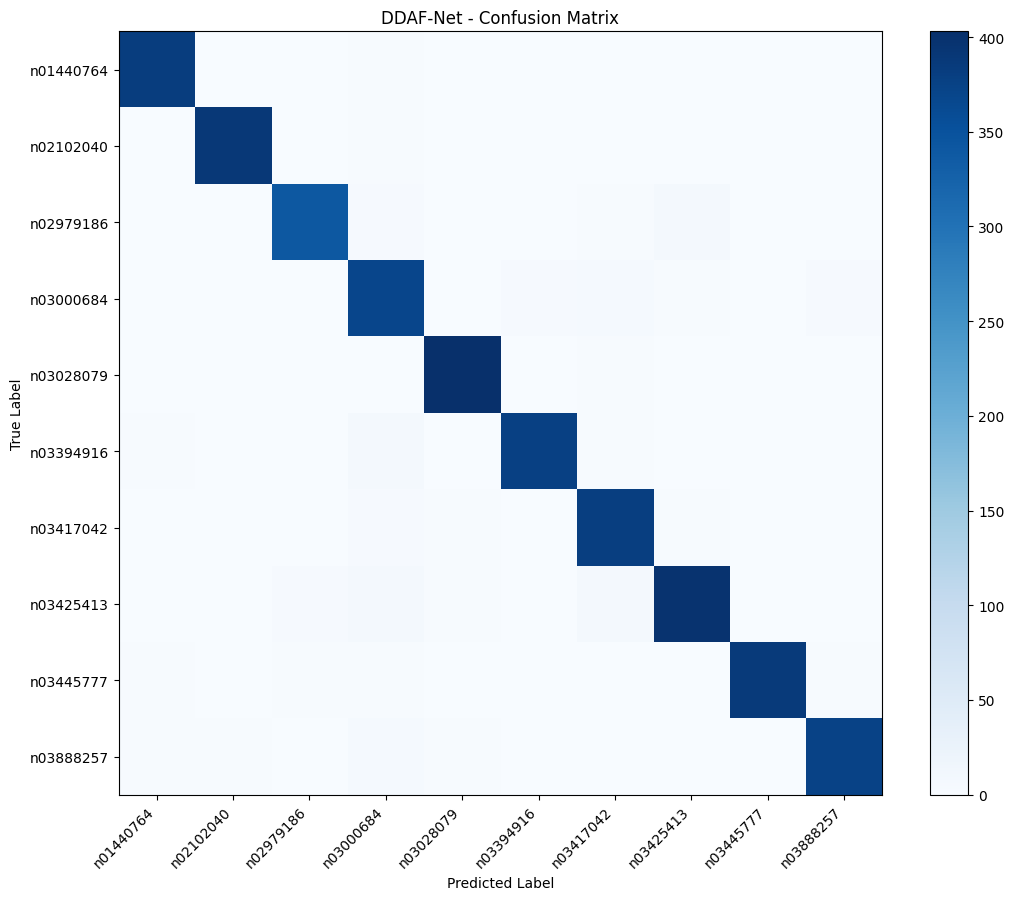

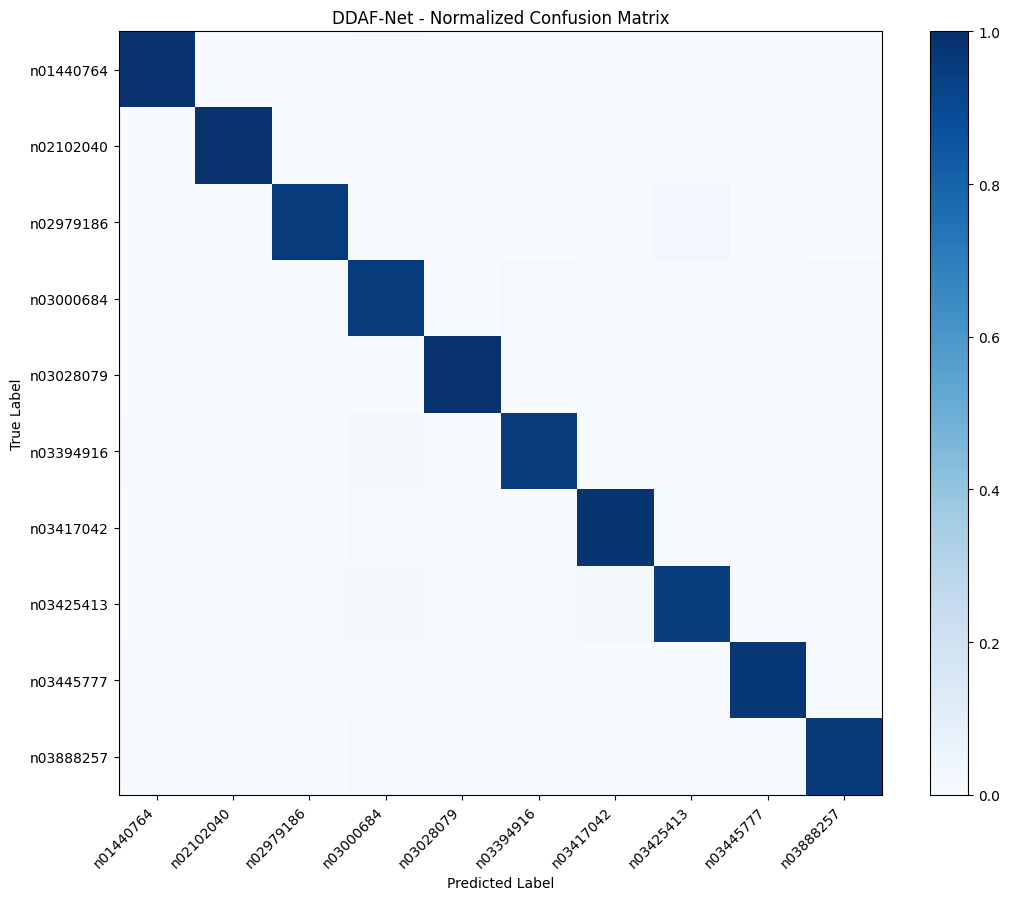

Research evaluation files saved:
/kaggle/working/ddaf_training/confusion_matrix.png
/kaggle/working/ddaf_training/normalized_confusion_matrix.png
/kaggle/working/ddaf_training/classification_report.csv
/kaggle/working/ddaf_training/evaluation_summary.csv


In [35]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

OUTPUT_DIR = "/kaggle/working/ddaf_training"

# Raw and normalized confusion matrices
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

# 1. Raw confusion matrix
plt.figure(figsize=(11, 9))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("DDAF-Net - Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Normalized confusion matrix
plt.figure(figsize=(11, 9))
plt.imshow(cm_normalized, interpolation="nearest", cmap="Blues",
           vmin=0, vmax=1)
plt.title("DDAF-Net - Normalized Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Save class-wise report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    f"{OUTPUT_DIR}/classification_report.csv"
)

# 4. Save summary metrics
summary = pd.DataFrame([{
    "Model": "DDAF-Net",
    "Best_Epoch": best_checkpoint["epoch"],
    "Validation_Accuracy": best_checkpoint["val_accuracy"],
    "Test_Accuracy": test_accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1,
    "Test_Samples": len(all_labels)
}])

summary.to_csv(
    f"{OUTPUT_DIR}/evaluation_summary.csv",
    index=False
)

print("Research evaluation files saved:")
print(f"{OUTPUT_DIR}/confusion_matrix.png")
print(f"{OUTPUT_DIR}/normalized_confusion_matrix.png")
print(f"{OUTPUT_DIR}/classification_report.csv")
print(f"{OUTPUT_DIR}/evaluation_summary.csv")


1. Confusion Matrix


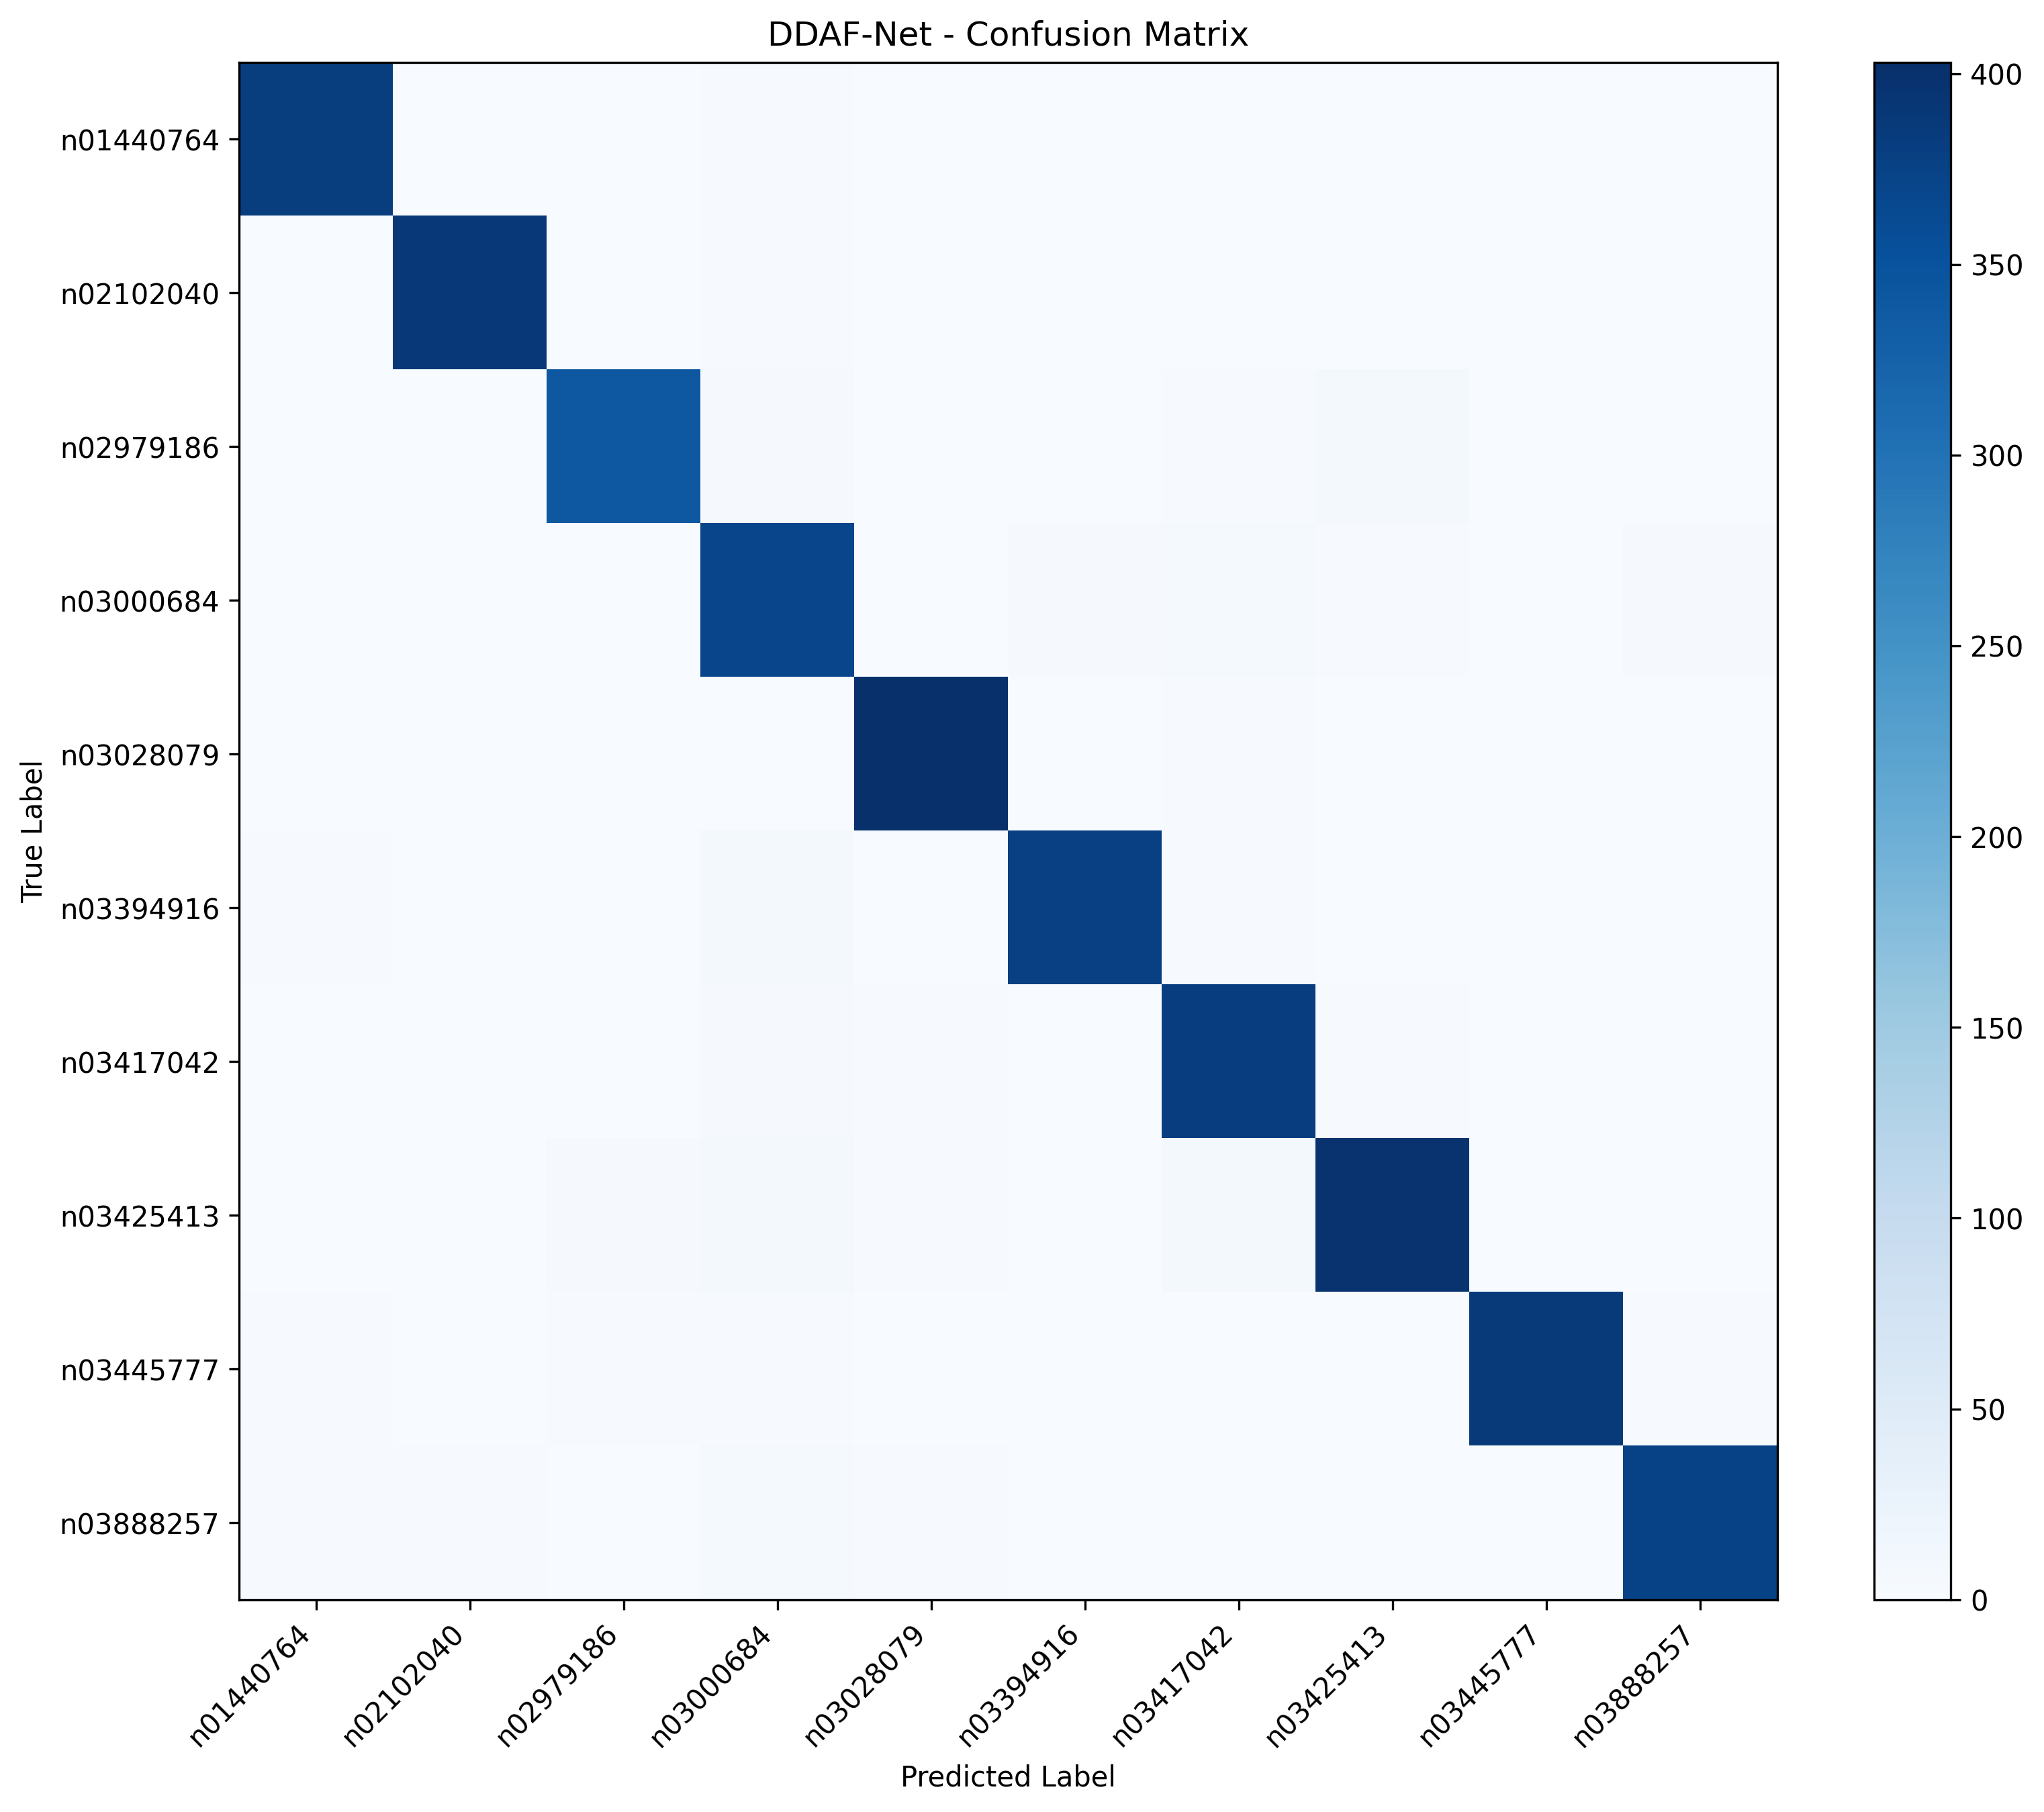

2. Normalized Confusion Matrix


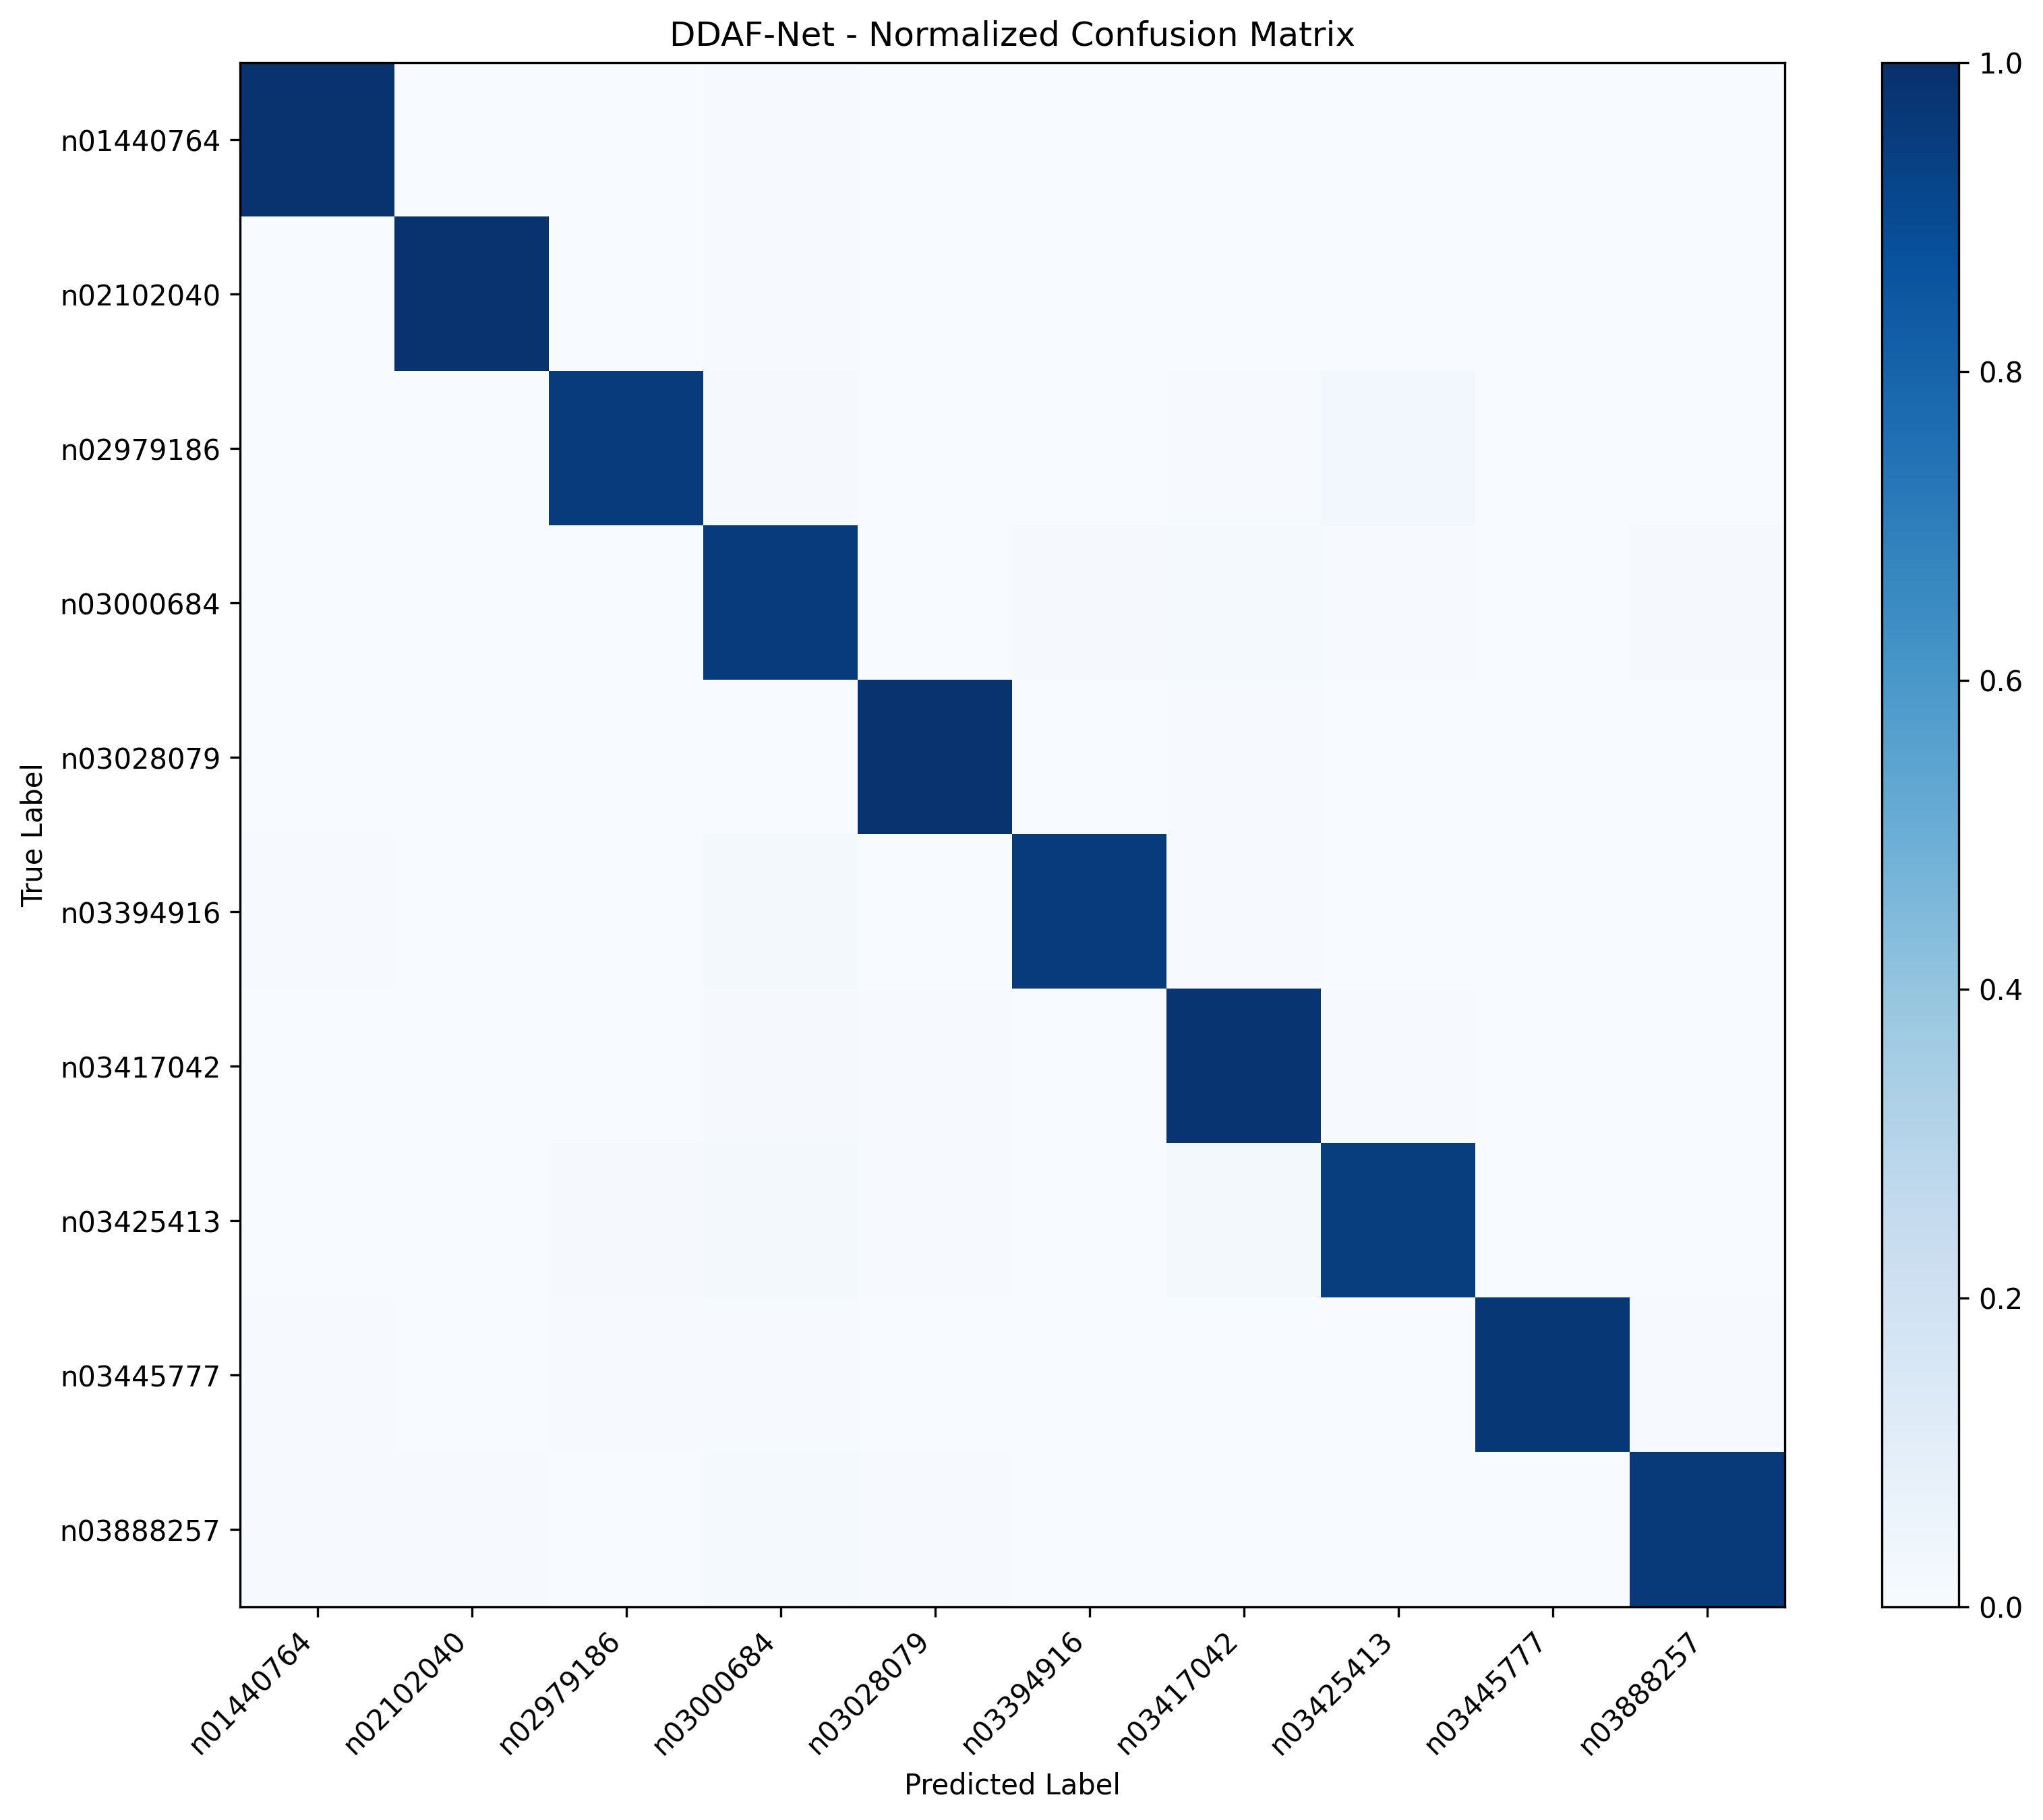

In [36]:
from IPython.display import display, Image

print("1. Confusion Matrix")
display(Image("/kaggle/working/ddaf_training/confusion_matrix.png"))

print("2. Normalized Confusion Matrix")
display(Image("/kaggle/working/ddaf_training/normalized_confusion_matrix.png"))

In [37]:

import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Standard ResNet-18 baseline
resnet18 = models.resnet18(weights=None)

# Replace final classification layer
resnet18.fc = nn.Linear(
    resnet18.fc.in_features,
    10
)

resnet18 = resnet18.to(DEVICE)

# Training configuration
resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.AdamW(
    resnet18.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

resnet_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

# Save directory
RESNET_DIR = Path("/kaggle/working/resnet18_baseline")
RESNET_DIR.mkdir(parents=True, exist_ok=True)

print("ResNet-18 baseline initialized successfully!")
print("Device:", DEVICE)
print("Number of classes:", resnet18.fc.out_features)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_df))
print(
    "Trainable parameters:",
    sum(p.numel() for p in resnet18.parameters() if p.requires_grad)
)
print("Optimizer: AdamW")
print("Learning rate: 1e-5")


ResNet-18 baseline initialized successfully!
Device: cuda
Number of classes: 10
Training images: 8048
Validation images: 1421
Test images: 3925
Trainable parameters: 11181642
Optimizer: AdamW
Learning rate: 1e-5


In [38]:

import torch
import torch.nn as nn

RESNET_EPOCHS = 3

resnet_best_accuracy = 0.0
resnet_global_step = 0

resnet_latest_path = RESNET_DIR / "resnet18_latest.pth"
resnet_best_path = RESNET_DIR / "resnet18_best.pth"

for epoch in range(RESNET_EPOCHS):

    resnet18.train()

    running_loss = 0.0
    correct = 0
    total = 0

    print(f"\n========== RESNET-18 EPOCH {epoch + 1} ==========")

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        resnet_optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = resnet18(images)
            loss = resnet_criterion(outputs, labels)

        resnet_scaler.scale(loss).backward()
        resnet_scaler.step(resnet_optimizer)
        resnet_scaler.update()

        running_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        resnet_global_step += 1

        if resnet_global_step % 100 == 0:
            print(
                f"Step: {resnet_global_step} | "
                f"Loss: {loss.item():.4f}"
            )

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100.0 * correct / total

    # Validation
    resnet18.eval()

    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = resnet18(images)
                loss = resnet_criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_accuracy = 100.0 * val_correct / val_total

    print(f"\nEpoch {epoch + 1} Results")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.2f}%")

    checkpoint = {
        "epoch": epoch + 1,
        "step": resnet_global_step,
        "model_state_dict": resnet18.state_dict(),
        "optimizer_state_dict": resnet_optimizer.state_dict(),
        "scaler_state_dict": resnet_scaler.state_dict(),
        "class_names": class_names,
        "class_to_idx": class_to_idx,
        "val_accuracy": val_accuracy
    }

    # Save latest checkpoint after each completed epoch
    torch.save(checkpoint, resnet_latest_path)

    if val_accuracy > resnet_best_accuracy:
        resnet_best_accuracy = val_accuracy
        torch.save(checkpoint, resnet_best_path)
        print("New best ResNet-18 checkpoint saved!")

    print("Latest checkpoint saved.")

print("\n========== RESNET-18 TRAINING COMPLETED ==========")
print("Total steps:", resnet_global_step)
print(f"Best validation accuracy: {resnet_best_accuracy:.2f}%")
print("Best checkpoint:", resnet_best_path)
print("Latest checkpoint:", resnet_latest_path)



========== RESNET-18 EPOCH 1 ==========
Step: 100 | Loss: 2.1693
Step: 200 | Loss: 2.0605
Step: 300 | Loss: 1.8126
Step: 400 | Loss: 1.6787
Step: 500 | Loss: 1.7764
Step: 600 | Loss: 2.0713
Step: 700 | Loss: 1.7553
Step: 800 | Loss: 2.0717
Step: 900 | Loss: 1.8210
Step: 1000 | Loss: 1.3950

Epoch 1 Results
Training Loss: 1.9478
Training Accuracy: 32.42%
Validation Loss: 1.6411
Validation Accuracy: 45.18%
New best ResNet-18 checkpoint saved!
Latest checkpoint saved.

========== RESNET-18 EPOCH 2 ==========
Step: 1100 | Loss: 1.6405
Step: 1200 | Loss: 1.2522
Step: 1300 | Loss: 2.1797
Step: 1400 | Loss: 1.9382
Step: 1500 | Loss: 1.3528
Step: 1600 | Loss: 1.5529
Step: 1700 | Loss: 1.3215
Step: 1800 | Loss: 1.6816
Step: 1900 | Loss: 0.9350
Step: 2000 | Loss: 0.9544

Epoch 2 Results
Training Loss: 1.5604
Training Accuracy: 47.97%
Validation Loss: 1.3769
Validation Accuracy: 54.68%
New best ResNet-18 checkpoint saved!
Latest checkpoint saved.

========== RESNET-18 EPOCH 3 ==========
Step: 21

In [39]:
from pathlib import Path
import torch

INITIAL_PATH = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

print("Initial checkpoint exists:", INITIAL_PATH.exists())

if INITIAL_PATH.exists():
    initial = torch.load(
        INITIAL_PATH,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint type:", type(initial).__name__)

    if isinstance(initial, dict):
        print("Checkpoint keys:", list(initial.keys()))

        state = initial.get(
            "model_state_dict",
            initial.get("state_dict", initial)
        )

        if isinstance(state, dict):
            print("\nFirst 20 weight names:")
            for key in list(state.keys())[:20]:
                value = state[key]
                if torch.is_tensor(value):
                    print(key, tuple(value.shape))

Initial checkpoint exists: True
Checkpoint type: OrderedDict
Checkpoint keys: ['shared.0.weight', 'shared.1.weight', 'shared.1.bias', 'shared.1.running_mean', 'shared.1.running_var', 'shared.1.num_batches_tracked', 'shared.4.0.conv1.weight', 'shared.4.0.bn1.weight', 'shared.4.0.bn1.bias', 'shared.4.0.bn1.running_mean', 'shared.4.0.bn1.running_var', 'shared.4.0.bn1.num_batches_tracked', 'shared.4.0.conv2.weight', 'shared.4.0.bn2.weight', 'shared.4.0.bn2.bias', 'shared.4.0.bn2.running_mean', 'shared.4.0.bn2.running_var', 'shared.4.0.bn2.num_batches_tracked', 'shared.4.1.conv1.weight', 'shared.4.1.bn1.weight', 'shared.4.1.bn1.bias', 'shared.4.1.bn1.running_mean', 'shared.4.1.bn1.running_var', 'shared.4.1.bn1.num_batches_tracked', 'shared.4.1.conv2.weight', 'shared.4.1.bn2.weight', 'shared.4.1.bn2.bias', 'shared.4.1.bn2.running_mean', 'shared.4.1.bn2.running_var', 'shared.4.1.bn2.num_batches_tracked', 'compression_branch.0.0.conv1.weight', 'compression_branch.0.0.bn1.weight', 'compression_

In [40]:
from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

text = source_path.read_text(encoding="utf-8", errors="ignore")
lines = text.splitlines()

keywords = [
    "ddaf_net_initial.pt",
    "load_state_dict",
    "CHECKPOINT"
]

for i, line in enumerate(lines):
    if any(word in line for word in keywords):
        print(f"\n--- Line {i + 1} ---")
        start = max(0, i - 5)
        end = min(len(lines), i + 8)

        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Line 358 ---
353: 
354: BASE = Path(
355:     "/content/drive/MyDrive/CartoonizationResearchBackup/Advanced_Project"
356: )
357: 
358: CHECKPOINT_DIR = BASE / "checkpoints"
359: 
360: REPORT_DIR = Path(
361:     "/content/drive/MyDrive/CartoonizationResearchBackup/"
362:     "Reproducibility_Audit"
363: )
364: REPORT_DIR.mkdir(parents=True, exist_ok=True)
365: 

--- Line 465 ---
460: 
461: print("\nTraining source report saved:")
462: print(source_report_path)
463: 
464: # ------------------------------------------------------------
465: # 5. CHECKPOINT METADATA AUDIT
466: # ------------------------------------------------------------
467: 
468: checkpoint_names = [
469:     "resnet18_standard_best.pt",
470:     "resnet18_standard_latest.pt",
471:     "resnet18_jpeg_augmented_best.pt",
472:     "resnet18_jpeg_augmented_latest.pt",

--- Line 480 ---
475: checkpoint_rows = []
476: checkpoint_details = {}
477: 
478: for filename in checkpoint_names:
479: 
480:     path = CHECKPOINT_D

In [41]:
from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

lines = source_path.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()

print("DDAF-NET INITIAL CHECKPOINT CREATION CODE")
print("=" * 65)

for i in range(1230, 1312):
    print(f"{i + 1}: {lines[i]}")

DDAF-NET INITIAL CHECKPOINT CREATION CODE
1231:             weights[:, 1:2].unsqueeze(-1).unsqueeze(-1)
1232:             * style_map
1233:         )
1234: 
1235:         refined_map = self.refinement(fused_map)
1236: 
1237:         refined_features = F.adaptive_avg_pool2d(
1238:             refined_map, 1
1239:         ).flatten(1)
1240: 
1241:         # Combine global branch fusion and refined features
1242:         final_features = fused_features + refined_features
1243: 
1244:         output = self.classifier(final_features)
1245: 
1246:         if return_weights:
1247:             return output, weights
1248: 
1249:         return output
1250: 
1251: 
1252: 
1253: 
1254: device = torch.device(
1255:     "cuda" if torch.cuda.is_available() else "cpu"
1256: )
1257: 
1258: model = DDAFNet(
1259:     num_classes=10,
1260:     pretrained=True
1261: ).to(device)
1262: 
1263: dummy_input = torch.randn(4, 3, 224, 224).to(device)
1264: 
1265: model.eval()
1266: 
1267: with torch.no_grad():

In [42]:
from pathlib import Path

source_path = Path(
    "/kaggle/working/.virtual_documents/__notebook_source__.ipynb"
)

lines = source_path.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()

print("DDAF-Net architecture and backbone initialization")
print("=" * 65)

for i in range(1080, 1230):
    print(f"{i + 1}: {lines[i]}")

DDAF-Net architecture and backbone initialization
1081:     def forward(self, compression_features, style_features):
1082: 
1083:         combined = torch.cat(
1084:             [compression_features, style_features],
1085:             dim=1
1086:         )
1087: 
1088:         weights = F.softmax(self.gate(combined), dim=1)
1089: 
1090:         compression_weight = weights[:, 0:1]
1091:         style_weight = weights[:, 1:2]
1092: 
1093:         fused = (
1094:             compression_weight * compression_features
1095:             + style_weight * style_features
1096:         )
1097: 
1098:         return fused, weights
1099: 
1100: 
1101: class MultiScaleFeatureRefinement(nn.Module):
1102:     """
1103:     Refines fused features using multiple receptive fields.
1104:     """
1105: 
1106:     def __init__(self, channels=512):
1107:         super().__init__()
1108: 
1109:         self.branch1 = nn.Sequential(
1110:             nn.Conv2d(channels, 256, kernel_size=1),
1111:           

In [43]:

import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet-pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
resnet18_pretrained = models.resnet18(weights=weights)

# Replace classification head for 10 classes
resnet18_pretrained.fc = nn.Linear(
    resnet18_pretrained.fc.in_features,
    10
)

resnet18_pretrained = resnet18_pretrained.to(DEVICE)

# Same optimizer configuration as DDAF-Net
pretrained_criterion = nn.CrossEntropyLoss()

pretrained_optimizer = torch.optim.AdamW(
    resnet18_pretrained.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

pretrained_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

# Separate experiment directory
PRETRAINED_DIR = Path(
    "/kaggle/working/resnet18_pretrained_baseline"
)
PRETRAINED_DIR.mkdir(parents=True, exist_ok=True)

print("PRETRAINED RESNET-18 INITIALIZED")
print("Device:", DEVICE)
print("Weights:", "ImageNet pretrained")
print("Classes:", resnet18_pretrained.fc.out_features)
print(
    "Trainable parameters:",
    sum(p.numel() for p in resnet18_pretrained.parameters()
        if p.requires_grad)
)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_df))
print("Optimizer: AdamW")
print("Learning rate: 1e-5")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s] 


PRETRAINED RESNET-18 INITIALIZED
Device: cuda
Weights: ImageNet pretrained
Classes: 10
Trainable parameters: 11181642
Training images: 8048
Validation images: 1421
Test images: 3925
Optimizer: AdamW
Learning rate: 1e-5


In [44]:

import torch
from tqdm.auto import tqdm

PRETRAINED_EPOCHS = 3
best_pretrained_val_acc = 0.0
pretrained_history = []

for epoch in range(PRETRAINED_EPOCHS):
    # Training
    resnet18_pretrained.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{PRETRAINED_EPOCHS}")

    for images, labels in progress:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        pretrained_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = resnet18_pretrained(images)
            loss = pretrained_criterion(outputs, labels)

        pretrained_scaler.scale(loss).backward()
        pretrained_scaler.step(pretrained_optimizer)
        pretrained_scaler.update()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # Validation
    resnet18_pretrained.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = resnet18_pretrained(images)
                loss = pretrained_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    pretrained_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    # Save latest checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": resnet18_pretrained.state_dict(),
        "optimizer_state_dict": pretrained_optimizer.state_dict(),
        "scaler_state_dict": pretrained_scaler.state_dict(),
        "val_accuracy": val_acc
    }, PRETRAINED_DIR / "resnet18_pretrained_latest.pth")

    # Save best checkpoint
    if val_acc > best_pretrained_val_acc:
        best_pretrained_val_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": resnet18_pretrained.state_dict(),
            "optimizer_state_dict": pretrained_optimizer.state_dict(),
            "scaler_state_dict": pretrained_scaler.state_dict(),
            "val_accuracy": val_acc
        }, PRETRAINED_DIR / "resnet18_pretrained_best.pth")

    print(f"\nEpoch {epoch+1}/{PRETRAINED_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc:.2f}%")
    print("-" * 55)

print("\nPRETRAINED RESNET-18 TRAINING COMPLETED")
print(f"Best Validation Accuracy: {best_pretrained_val_acc:.2f}%")


Epoch 1/3:   0%|          | 0/1006 [00:00<?, ?it/s]


Epoch 1/3
Train Loss: 0.8287 | Train Accuracy: 77.68%
Val Loss:   0.2315 | Val Accuracy:   94.09%
-------------------------------------------------------


Epoch 2/3:   0%|          | 0/1006 [00:00<?, ?it/s]


Epoch 2/3
Train Loss: 0.3432 | Train Accuracy: 90.89%
Val Loss:   0.1615 | Val Accuracy:   95.07%
-------------------------------------------------------


Epoch 3/3:   0%|          | 0/1006 [00:00<?, ?it/s]


Epoch 3/3
Train Loss: 0.2420 | Train Accuracy: 93.38%
Val Loss:   0.1356 | Val Accuracy:   95.78%
-------------------------------------------------------

PRETRAINED RESNET-18 TRAINING COMPLETED
Best Validation Accuracy: 95.78%


In [47]:

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoint
checkpoint_path = PRETRAINED_DIR / "resnet18_pretrained_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

resnet18_pretrained.load_state_dict(
    checkpoint["model_state_dict"]
)
resnet18_pretrained.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation accuracy:", checkpoint["val_accuracy"])

# Evaluate on test set
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing ResNet-18"):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = resnet18_pretrained(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_recall = recall_score(
    all_labels, all_predictions, average="macro", zero_division=0
)
test_f1 = f1_score(
    all_labels, all_predictions, average="macro", zero_division=0
)

print("\nPRETRAINED RESNET-18 TEST RESULTS")
print("=" * 50)
print(f"Test images: {len(all_labels)}")
print(f"Correct predictions: {sum(np.array(all_labels) == np.array(all_predictions))}")
print(f"Incorrect predictions: {sum(np.array(all_labels) != np.array(all_predictions))}")
print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0
))

# Save results
pretrained_results = pd.DataFrame([{
    "Model": "ResNet-18 ImageNet Pretrained",
    "Test Accuracy": test_accuracy * 100,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1": test_f1
}])

pretrained_results.to_csv(
    PRETRAINED_DIR / "resnet18_pretrained_test_results.csv",
    index=False
)

print("\nResults saved successfully.")


Best checkpoint epoch: 3
Best validation accuracy: 95.77762139338493


Testing ResNet-18:   0%|          | 0/491 [00:00<?, ?it/s]


PRETRAINED RESNET-18 TEST RESULTS
Test images: 3925
Correct predictions: 3749
Incorrect predictions: 176
Accuracy:  95.52%
Precision: 0.9555
Recall:    0.9555
F1-score:  0.9552

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   n01440764       0.97      0.97      0.97       387
   n02102040       0.99      0.99      0.99       395
   n02979186       0.96      0.95      0.95       357
   n03000684       0.89      0.93      0.91       386
   n03028079       0.98      0.97      0.97       409
   n03394916       0.95      0.98      0.96       394
   n03417042       0.92      0.97      0.95       389
   n03425413       0.96      0.88      0.92       419
   n03445777       0.99      0.95      0.97       399
   n03888257       0.94      0.96      0.95       390

    accuracy                           0.96      3925
   macro avg       0.96      0.96      0.96      3925
weighted avg       0.96      0.96      0.96      3925


Results saved successfully.


In [46]:
from PIL import Image as PILImage

# Restore the Image reference used by your dataset class
Image = PILImage

print("PIL Image restored:", Image)
print("Image.open available:", hasattr(Image, "open"))

PIL Image restored: <module 'PIL.Image' from '/usr/local/lib/python3.13/dist-packages/PIL/Image.py'>
Image.open available: True


In [48]:

import torch
import numpy as np
from tqdm.auto import tqdm
from scipy.stats import binomtest

# Both models must already be loaded
model.eval()                 # DDAF-Net
resnet18_pretrained.eval()   # Pretrained ResNet-18

ddaf_predictions = []
resnet_predictions = []
true_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Paired model evaluation"):
        images = images.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            ddaf_outputs = model(images)
            resnet_outputs = resnet18_pretrained(images)

        # Handle models that return tuples or dictionaries
        if isinstance(ddaf_outputs, (tuple, list)):
            ddaf_outputs = ddaf_outputs[0]
        if isinstance(ddaf_outputs, dict):
            ddaf_outputs = ddaf_outputs["logits"]

        if isinstance(resnet_outputs, (tuple, list)):
            resnet_outputs = resnet_outputs[0]
        if isinstance(resnet_outputs, dict):
            resnet_outputs = resnet_outputs["logits"]

        ddaf_predictions.extend(
            ddaf_outputs.argmax(1).cpu().numpy()
        )
        resnet_predictions.extend(
            resnet_outputs.argmax(1).cpu().numpy()
        )
        true_labels.extend(labels.numpy())

ddaf_predictions = np.array(ddaf_predictions)
resnet_predictions = np.array(resnet_predictions)
true_labels = np.array(true_labels)

# Identify correct and incorrect predictions
ddaf_correct = ddaf_predictions == true_labels
resnet_correct = resnet_predictions == true_labels

# Discordant pairs
b = int(np.sum(ddaf_correct & ~resnet_correct))
c = int(np.sum(~ddaf_correct & resnet_correct))

# Exact two-sided McNemar test
discordant = b + c

if discordant > 0:
    p_value = binomtest(
        min(b, c),
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue
else:
    p_value = 1.0

print("\nMCNEMAR'S TEST RESULTS")
print("=" * 45)
print("Test images:", len(true_labels))
print("Both models correct:", int(np.sum(ddaf_correct & resnet_correct)))
print("Both models incorrect:", int(np.sum(~ddaf_correct & ~resnet_correct)))
print("DDAF correct, ResNet wrong (b):", b)
print("DDAF wrong, ResNet correct (c):", c)
print("Discordant pairs:", discordant)
print(f"Exact McNemar p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Conclusion: Significant difference at the 0.05 level.")
else:
    print("Conclusion: No statistically significant difference at the 0.05 level.")


Paired model evaluation:   0%|          | 0/491 [00:00<?, ?it/s]


MCNEMAR'S TEST RESULTS
Test images: 3925
Both models correct: 3725
Both models incorrect: 102
DDAF correct, ResNet wrong (b): 74
DDAF wrong, ResNet correct (c): 24
Discordant pairs: 98
Exact McNemar p-value: 0.000000
Conclusion: Significant difference at the 0.05 level.


In [49]:
import pandas as pd

mcnemar_results = pd.DataFrame([{
    "Test": "Exact McNemar Test",
    "DDAF_correct_ResNet_wrong": b,
    "DDAF_wrong_ResNet_correct": c,
    "Discordant_pairs": discordant,
    "P_value": p_value,
    "Significance_level": 0.05,
    "Statistically_significant": p_value < 0.05
}])

mcnemar_results.to_csv(
    "/kaggle/working/mcnemar_test_results.csv",
    index=False
)

print(f"Exact p-value: {p_value:.3e}")
print("Statistical results saved.")

Exact p-value: 4.216e-07
Statistical results saved.


In [50]:

from pathlib import Path
import tarfile
import urllib.request

archive_path = Path("/kaggle/working/imagewoof2-320.tgz")
dataset_root = Path("/kaggle/working/imagewoof2-320")

if not dataset_root.exists():
    if not archive_path.exists():
        url = "https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-320.tgz"
        print("Downloading ImageWoof2-320...")
        urllib.request.urlretrieve(url, archive_path)

    print("Extracting ImageWoof2-320...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall("/kaggle/working")

print("Dataset exists:", dataset_root.exists())
print("Training folder:", (dataset_root / "train").exists())
print("Validation folder:", (dataset_root / "val").exists())


Extracting ImageWoof2-320...
Dataset exists: True
Training folder: True
Validation folder: True


/tmp/ipykernel_49/3141376401.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/kaggle/working")
IOStream.flush timed out


In [51]:

from pathlib import Path
from torchvision import datasets
from PIL import Image as PILImage

root = Path("/kaggle/working/imagewoof2-320")

train_path = root / "train"
test_path = root / "val"

# Load folder structure
train_data = datasets.ImageFolder(train_path)
test_data = datasets.ImageFolder(test_path)

print("IMAGEWOOF DATASET VERIFICATION")
print("=" * 45)

print("Number of classes:", len(train_data.classes))
print("Classes:", train_data.classes)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

print("\nClass-wise image counts:")
for class_name in train_data.classes:
    train_count = sum(
        1 for _, label in train_data.samples
        if train_data.classes[label] == class_name
    )
    test_count = sum(
        1 for _, label in test_data.samples
        if test_data.classes[label] == class_name
    )
    print(f"{class_name}: Train={train_count}, Test={test_count}")

# Verify an actual image can be opened
sample_path, sample_label = train_data.samples[0]

with PILImage.open(sample_path) as img:
    print("\nSample image size:", img.size)
    print("Sample image format:", img.format)

print("\nDATASET VERIFICATION COMPLETED")


IMAGEWOOF DATASET VERIFICATION
Number of classes: 10
Classes: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Training images: 9025
Test images: 3929

Class-wise image counts:
n02086240: Train=941, Test=409
n02087394: Train=942, Test=408
n02088364: Train=932, Test=418
n02089973: Train=580, Test=224
n02093754: Train=949, Test=401
n02096294: Train=943, Test=407
n02099601: Train=949, Test=401
n02105641: Train=928, Test=422
n02111889: Train=921, Test=429
n02115641: Train=940, Test=410

Sample image size: (320, 333)
Sample image format: JPEG

DATASET VERIFICATION COMPLETED


In [52]:

import torch
import random
import numpy as np
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

IMAGEWOOF_ROOT = Path("/kaggle/working/imagewoof2-320")

# Training transformations
train_transform_woof = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test transformations
eval_transform_woof = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Separate dataset objects for different transforms
train_full_woof = datasets.ImageFolder(
    IMAGEWOOF_ROOT / "train",
    transform=train_transform_woof
)

train_eval_full_woof = datasets.ImageFolder(
    IMAGEWOOF_ROOT / "train",
    transform=eval_transform_woof
)

test_dataset_woof = datasets.ImageFolder(
    IMAGEWOOF_ROOT / "val",
    transform=eval_transform_woof
)

# Verify identical class mapping
assert train_full_woof.classes == test_dataset_woof.classes

class_names_woof = train_full_woof.classes
num_classes_woof = len(class_names_woof)

# Stratified 90:10 split
all_indices = np.arange(len(train_full_woof))
all_labels = np.array([
    label for _, label in train_full_woof.samples
])

train_indices_woof, val_indices_woof = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=all_labels
)

train_dataset_woof = Subset(
    train_full_woof,
    train_indices_woof
)

val_dataset_woof = Subset(
    train_eval_full_woof,
    val_indices_woof
)

# Data loaders
train_loader_woof = DataLoader(
    train_dataset_woof,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_woof = DataLoader(
    val_dataset_woof,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_woof = DataLoader(
    test_dataset_woof,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("IMAGEWOOF DATA LOADERS READY")
print("=" * 45)
print("Classes:", num_classes_woof)
print("Class names:", class_names_woof)
print("Training images:", len(train_dataset_woof))
print("Validation images:", len(val_dataset_woof))
print("Test images:", len(test_dataset_woof))
print("Training batches:", len(train_loader_woof))
print("Validation batches:", len(val_loader_woof))
print("Test batches:", len(test_loader_woof))
print("Device:", DEVICE)

# Verify a batch
images, labels = next(iter(train_loader_woof))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


IMAGEWOOF DATA LOADERS READY
Classes: 10
Class names: ['n02086240', 'n02087394', 'n02088364', 'n02089973', 'n02093754', 'n02096294', 'n02099601', 'n02105641', 'n02111889', 'n02115641']
Training images: 8122
Validation images: 903
Test images: 3929
Training batches: 1016
Validation batches: 113
Test batches: 492
Device: cuda
Batch image shape: torch.Size([8, 3, 160, 160])
Batch label shape: torch.Size([8])


In [53]:

import torch
import torch.nn as nn
from torchvision import models
from pathlib import Path

# Reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 1. INITIALIZE DDAF-NET
# ==========================================

ddaf_initial_path = (
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

ddaf_woof = DDAFNet(num_classes=10).to(DEVICE)

initial_state = torch.load(
    ddaf_initial_path,
    map_location="cpu",
    weights_only=True
)

ddaf_woof.load_state_dict(initial_state, strict=True)

# ==========================================
# 2. INITIALIZE PRETRAINED RESNET-18
# ==========================================

resnet_woof = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

resnet_woof.fc = nn.Linear(
    resnet_woof.fc.in_features,
    num_classes_woof
)

resnet_woof = resnet_woof.to(DEVICE)

# ==========================================
# 3. OPTIMIZERS
# ==========================================

ddaf_optimizer_woof = torch.optim.AdamW(
    ddaf_woof.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

resnet_optimizer_woof = torch.optim.AdamW(
    resnet_woof.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

criterion_woof = nn.CrossEntropyLoss()

ddaf_scaler_woof = torch.amp.GradScaler(
    "cuda", enabled=(DEVICE.type == "cuda")
)

resnet_scaler_woof = torch.amp.GradScaler(
    "cuda", enabled=(DEVICE.type == "cuda")
)

# ==========================================
# 4. CHECKPOINT DIRECTORIES
# ==========================================

WOOF_DIR = Path("/kaggle/working/imagewoof_experiments")
DDAF_WOOF_DIR = WOOF_DIR / "ddaf_net"
RESNET_WOOF_DIR = WOOF_DIR / "resnet18"

DDAF_WOOF_DIR.mkdir(parents=True, exist_ok=True)
RESNET_WOOF_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 5. DISPLAY CONFIGURATION
# ==========================================

print("IMAGEWOOF MODELS INITIALIZED")
print("=" * 50)

print("Dataset classes:", num_classes_woof)
print("Device:", DEVICE)

print("\nDDAF-Net:")
print("Initialization: Original pretrained initial checkpoint")
print("Parameters:", sum(p.numel() for p in ddaf_woof.parameters()))

print("\nResNet-18:")
print("Initialization: ImageNet pretrained")
print("Parameters:", sum(p.numel() for p in resnet_woof.parameters()))

print("\nOptimizer: AdamW")
print("Learning rate: 1e-5")
print("Weight decay: 1e-4")
print("Batch size: 8")
print("Planned epochs: 3")

print("\nBoth models are ready for ImageWoof training.")


IMAGEWOOF MODELS INITIALIZED
Dataset classes: 10
Device: cuda

DDAF-Net:
Initialization: Original pretrained initial checkpoint
Parameters: 25479756

ResNet-18:
Initialization: ImageNet pretrained
Parameters: 11181642

Optimizer: AdamW
Learning rate: 1e-5
Weight decay: 1e-4
Batch size: 8
Planned epochs: 3

Both models are ready for ImageWoof training.


In [54]:

import torch
from tqdm.auto import tqdm

WOOF_EPOCHS = 3
best_ddaf_woof_acc = 0.0
ddaf_woof_history = []

for epoch in range(WOOF_EPOCHS):

    # ---------------- TRAINING ----------------
    ddaf_woof.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader_woof,
        desc=f"DDAF-Net Epoch {epoch+1}/{WOOF_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        ddaf_optimizer_woof.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = ddaf_woof(images)

            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]
            if isinstance(outputs, dict):
                outputs = outputs["logits"]

            loss = criterion_woof(outputs, labels)

        ddaf_scaler_woof.scale(loss).backward()
        ddaf_scaler_woof.step(ddaf_optimizer_woof)
        ddaf_scaler_woof.update()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # ---------------- VALIDATION ----------------
    ddaf_woof.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader_woof:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = ddaf_woof(images)

                if isinstance(outputs, (tuple, list)):
                    outputs = outputs[0]
                if isinstance(outputs, dict):
                    outputs = outputs["logits"]

                loss = criterion_woof(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    ddaf_woof_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    # Save latest checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": ddaf_woof.state_dict(),
        "optimizer_state_dict": ddaf_optimizer_woof.state_dict(),
        "scaler_state_dict": ddaf_scaler_woof.state_dict(),
        "val_accuracy": val_acc,
        "class_names": class_names_woof
    }, DDAF_WOOF_DIR / "ddaf_woof_latest.pth")

    # Save best checkpoint
    if val_acc > best_ddaf_woof_acc:

        best_ddaf_woof_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": ddaf_woof.state_dict(),
            "optimizer_state_dict": ddaf_optimizer_woof.state_dict(),
            "scaler_state_dict": ddaf_scaler_woof.state_dict(),
            "val_accuracy": val_acc,
            "class_names": class_names_woof
        }, DDAF_WOOF_DIR / "ddaf_woof_best.pth")

    print(f"\nDDAF-Net Epoch {epoch+1}/{WOOF_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print("-" * 55)

print("\nDDAF-NET IMAGEWOOF TRAINING COMPLETED")
print(f"Best Validation Accuracy: {best_ddaf_woof_acc:.2f}%")


DDAF-Net Epoch 1/3:   0%|          | 0/1016 [00:00<?, ?it/s]


DDAF-Net Epoch 1/3
Train Loss: 1.3410
Train Accuracy: 61.09%
Validation Loss: 0.5400
Validation Accuracy: 84.16%
-------------------------------------------------------


DDAF-Net Epoch 2/3:   0%|          | 0/1016 [00:00<?, ?it/s]


DDAF-Net Epoch 2/3
Train Loss: 0.7079
Train Accuracy: 78.60%
Validation Loss: 0.4164
Validation Accuracy: 86.49%
-------------------------------------------------------


DDAF-Net Epoch 3/3:   0%|          | 0/1016 [00:00<?, ?it/s]


DDAF-Net Epoch 3/3
Train Loss: 0.5538
Train Accuracy: 83.07%
Validation Loss: 0.3865
Validation Accuracy: 87.71%
-------------------------------------------------------

DDAF-NET IMAGEWOOF TRAINING COMPLETED
Best Validation Accuracy: 87.71%


In [55]:

from tqdm.auto import tqdm
import torch

best_resnet_woof_acc = 0.0
resnet_woof_history = []

for epoch in range(3):

    resnet_woof.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader_woof,
        desc=f"ResNet Epoch {epoch+1}/3"
    ):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        resnet_optimizer_woof.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = resnet_woof(images)
            loss = criterion_woof(outputs, labels)

        resnet_scaler_woof.scale(loss).backward()
        resnet_scaler_woof.step(resnet_optimizer_woof)
        resnet_scaler_woof.update()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = 100 * train_correct / train_total

    # Validation
    resnet_woof.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_woof:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = resnet_woof(images)
                loss = criterion_woof(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = 100 * val_correct / val_total

    resnet_woof_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": resnet_woof.state_dict(),
        "optimizer_state_dict": resnet_optimizer_woof.state_dict(),
        "scaler_state_dict": resnet_scaler_woof.state_dict(),
        "val_accuracy": val_acc,
        "class_names": class_names_woof
    }

    torch.save(
        checkpoint,
        RESNET_WOOF_DIR / "resnet_woof_latest.pth"
    )

    if val_acc > best_resnet_woof_acc:
        best_resnet_woof_acc = val_acc
        torch.save(
            checkpoint,
            RESNET_WOOF_DIR / "resnet_woof_best.pth"
        )

    print(f"\nResNet-18 Epoch {epoch+1}/3")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print("-" * 50)

print("\nRESNET-18 IMAGEWOOF TRAINING COMPLETED")
print(f"Best Validation Accuracy: {best_resnet_woof_acc:.2f}%")


ResNet Epoch 1/3:   0%|          | 0/1016 [00:00<?, ?it/s]


ResNet-18 Epoch 1/3
Train Loss: 1.1561
Train Accuracy: 65.48%
Validation Loss: 0.5409
Validation Accuracy: 82.95%
--------------------------------------------------


ResNet Epoch 2/3:   0%|          | 0/1016 [00:00<?, ?it/s]


ResNet-18 Epoch 2/3
Train Loss: 0.6173
Train Accuracy: 81.32%
Validation Loss: 0.4192
Validation Accuracy: 85.60%
--------------------------------------------------


ResNet Epoch 3/3:   0%|          | 0/1016 [00:00<?, ?it/s]


ResNet-18 Epoch 3/3
Train Loss: 0.4911
Train Accuracy: 84.99%
Validation Loss: 0.3915
Validation Accuracy: 87.26%
--------------------------------------------------

RESNET-18 IMAGEWOOF TRAINING COMPLETED
Best Validation Accuracy: 87.26%


In [56]:

import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best checkpoints
ddaf_ckpt = torch.load(
    DDAF_WOOF_DIR / "ddaf_woof_best.pth",
    map_location=DEVICE,
    weights_only=True
)

resnet_ckpt = torch.load(
    RESNET_WOOF_DIR / "resnet_woof_best.pth",
    map_location=DEVICE,
    weights_only=True
)

ddaf_woof.load_state_dict(ddaf_ckpt["model_state_dict"])
resnet_woof.load_state_dict(resnet_ckpt["model_state_dict"])

ddaf_woof.eval()
resnet_woof.eval()

print("DDAF-Net best epoch:", ddaf_ckpt["epoch"])
print("ResNet-18 best epoch:", resnet_ckpt["epoch"])

# Collect paired predictions
ddaf_preds = []
resnet_preds = []
true_labels = []

def get_logits(output):
    if isinstance(output, (tuple, list)):
        output = output[0]
    if isinstance(output, dict):
        output = output["logits"]
    return output

with torch.no_grad():
    for images, labels in tqdm(
        test_loader_woof,
        desc="Evaluating ImageWoof models"
    ):
        images = images.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            ddaf_out = get_logits(ddaf_woof(images))
            resnet_out = get_logits(resnet_woof(images))

        ddaf_preds.extend(ddaf_out.argmax(1).cpu().numpy())
        resnet_preds.extend(resnet_out.argmax(1).cpu().numpy())
        true_labels.extend(labels.numpy())

ddaf_preds = np.array(ddaf_preds)
resnet_preds = np.array(resnet_preds)
true_labels = np.array(true_labels)

# Calculate metrics
def calculate_metrics(y_true, y_pred, name):
    return {
        "Model": name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Correct": int((y_true == y_pred).sum()),
        "Incorrect": int((y_true != y_pred).sum())
    }

results = pd.DataFrame([
    calculate_metrics(true_labels, ddaf_preds, "DDAF-Net"),
    calculate_metrics(true_labels, resnet_preds, "ResNet-18")
])

print("\nIMAGEWOOF TEST RESULTS")
print("=" * 65)
print(results.to_string(index=False))

print("\nDDAF-NET CLASSIFICATION REPORT")
print(classification_report(
    true_labels,
    ddaf_preds,
    target_names=class_names_woof,
    zero_division=0
))

print("\nRESNET-18 CLASSIFICATION REPORT")
print(classification_report(
    true_labels,
    resnet_preds,
    target_names=class_names_woof,
    zero_division=0
))

# Save results
results.to_csv(
    WOOF_DIR / "imagewoof_test_comparison.csv",
    index=False
)

pd.DataFrame(
    confusion_matrix(true_labels, ddaf_preds),
    index=class_names_woof,
    columns=class_names_woof
).to_csv(WOOF_DIR / "ddaf_woof_confusion_matrix.csv")

pd.DataFrame(
    confusion_matrix(true_labels, resnet_preds),
    index=class_names_woof,
    columns=class_names_woof
).to_csv(WOOF_DIR / "resnet_woof_confusion_matrix.csv")

# Save paired predictions for statistical analysis
prediction_df = pd.DataFrame({
    "image_path": [p for p, _ in test_dataset_woof.samples],
    "true_label": true_labels,
    "ddaf_prediction": ddaf_preds,
    "resnet_prediction": resnet_preds
})

prediction_df.to_csv(
    WOOF_DIR / "imagewoof_paired_predictions.csv",
    index=False
)

print("\nAll ImageWoof evaluation results saved.")
print("Output directory:", WOOF_DIR)


DDAF-Net best epoch: 3
ResNet-18 best epoch: 3


Evaluating ImageWoof models:   0%|          | 0/492 [00:00<?, ?it/s]


IMAGEWOOF TEST RESULTS
    Model  Accuracy (%)  Macro Precision  Macro Recall  Macro F1  Correct  Incorrect
 DDAF-Net     88.572156         0.882315      0.878075  0.879284     3480        449
ResNet-18     87.630440         0.874101      0.865897  0.868248     3443        486

DDAF-NET CLASSIFICATION REPORT
              precision    recall  f1-score   support

   n02086240       0.84      0.92      0.88       409
   n02087394       0.85      0.93      0.89       408
   n02088364       0.88      0.82      0.85       418
   n02089973       0.80      0.72      0.76       224
   n02093754       0.89      0.87      0.88       401
   n02096294       0.90      0.89      0.90       407
   n02099601       0.92      0.88      0.90       401
   n02105641       0.95      0.89      0.92       422
   n02111889       0.89      0.97      0.93       429
   n02115641       0.89      0.90      0.89       410

    accuracy                           0.89      3929
   macro avg       0.88      0.88      

In [57]:

from scipy.stats import binomtest
import numpy as np
import pandas as pd

# Paired correctness results
ddaf_correct_woof = (ddaf_preds == true_labels)
resnet_correct_woof = (resnet_preds == true_labels)

# Discordant pairs
b_woof = int(np.sum(ddaf_correct_woof & ~resnet_correct_woof))
c_woof = int(np.sum(~ddaf_correct_woof & resnet_correct_woof))

discordant_woof = b_woof + c_woof

if discordant_woof > 0:
    p_woof = binomtest(
        min(b_woof, c_woof),
        n=discordant_woof,
        p=0.5,
        alternative="two-sided"
    ).pvalue
else:
    p_woof = 1.0

print("IMAGEWOOF MCNEMAR TEST")
print("=" * 45)
print("Test images:", len(true_labels))
print("DDAF correct, ResNet wrong:", b_woof)
print("DDAF wrong, ResNet correct:", c_woof)
print("Discordant pairs:", discordant_woof)
print(f"Exact p-value: {p_woof:.8e}")

print(
    "Statistically significant"
    if p_woof < 0.05
    else "Not statistically significant"
)

pd.DataFrame([{
    "Dataset": "ImageWoof2-320",
    "Test": "Exact McNemar",
    "DDAF_correct_ResNet_wrong": b_woof,
    "DDAF_wrong_ResNet_correct": c_woof,
    "P_value": p_woof
}]).to_csv(
    WOOF_DIR / "imagewoof_mcnemar_results.csv",
    index=False
)

print("Statistical results saved.")


IMAGEWOOF MCNEMAR TEST
Test images: 3929
DDAF correct, ResNet wrong: 135
DDAF wrong, ResNet correct: 98
Discordant pairs: 233
Exact p-value: 1.81610921e-02
Statistically significant
Statistical results saved.


In [58]:

import torch
import torch.nn as nn
import pandas as pd

ddaf_woof.eval()

# Total and trainable parameters
total_params = sum(
    p.numel() for p in ddaf_woof.parameters()
)

trainable_params = sum(
    p.numel() for p in ddaf_woof.parameters()
    if p.requires_grad
)

non_trainable_params = total_params - trainable_params

# Module-wise parameters
module_results = []

for name, module in ddaf_woof.named_children():
    params = sum(p.numel() for p in module.parameters())
    trainable = sum(
        p.numel() for p in module.parameters()
        if p.requires_grad
    )

    module_results.append({
        "Module": name,
        "Parameters": params,
        "Trainable Parameters": trainable
    })

module_df = pd.DataFrame(module_results)

print("DDAF-NET ARCHITECTURE ANALYSIS")
print("=" * 55)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")
print(f"Model size (FP32): {total_params * 4 / (1024**2):.2f} MB")

print("\nMODULE-WISE PARAMETER DISTRIBUTION")
print(module_df.to_string(index=False))

# Forward-pass verification
sample_images, sample_labels = next(iter(val_loader_woof))
sample_images = sample_images[:2].to(DEVICE)

with torch.no_grad():
    output = ddaf_woof(sample_images)

    if isinstance(output, (tuple, list)):
        output = output[0]
    if isinstance(output, dict):
        output = output["logits"]

print("\nFORWARD PASS VERIFICATION")
print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(output.shape))
print("Expected output:", (2, num_classes_woof))
print("Forward pass successful:", output.shape == (2, num_classes_woof))

module_df.to_csv(
    WOOF_DIR / "ddaf_architecture_parameters.csv",
    index=False
)


DDAF-NET ARCHITECTURE ANALYSIS
Total parameters: 25,479,756
Trainable parameters: 25,479,756
Non-trainable parameters: 0
Model size (FP32): 97.20 MB

MODULE-WISE PARAMETER DISTRIBUTION
            Module  Parameters  Trainable Parameters
            shared      157504                157504
compression_branch    11019008              11019008
      style_branch    11019008              11019008
   adaptive_fusion      262914                262914
        refinement     2887424               2887424
        classifier      133898                133898

FORWARD PASS VERIFICATION
Input shape: (2, 3, 160, 160)
Output shape: (2, 10)
Expected output: (2, 10)
Forward pass successful: True


In [59]:
!pip -q install fvcore

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [60]:

import torch
import pandas as pd
from fvcore.nn import FlopCountAnalysis, parameter_count_table

# Use the best ImageWoof models
ddaf_woof.eval()
resnet_woof.eval()

dummy_input = torch.randn(
    1, 3, 160, 160,
    device=DEVICE
)

# FLOPs
with torch.no_grad():
    ddaf_flops = FlopCountAnalysis(
        ddaf_woof, dummy_input
    ).total()

    resnet_flops = FlopCountAnalysis(
        resnet_woof, dummy_input
    ).total()

# Parameters
ddaf_params = sum(
    p.numel() for p in ddaf_woof.parameters()
)

resnet_params = sum(
    p.numel() for p in resnet_woof.parameters()
)

complexity_results = pd.DataFrame([
    {
        "Model": "DDAF-Net",
        "Parameters (M)": ddaf_params / 1e6,
        "FLOPs (G)": ddaf_flops / 1e9,
        "Estimated FP32 Size (MB)": ddaf_params * 4 / 1024**2
    },
    {
        "Model": "ResNet-18",
        "Parameters (M)": resnet_params / 1e6,
        "FLOPs (G)": resnet_flops / 1e9,
        "Estimated FP32 Size (MB)": resnet_params * 4 / 1024**2
    }
])

print("COMPUTATIONAL COMPLEXITY COMPARISON")
print("=" * 65)
print(complexity_results.to_string(index=False))

complexity_results.to_csv(
    WOOF_DIR / "model_complexity_comparison.csv",
    index=False
)

print("\nComplexity results saved.")


Unsupported operator aten::max_pool2d encountered 1 time(s)
Unsupported operator aten::add_ encountered 14 time(s)
Unsupported operator aten::softmax encountered 1 time(s)
Unsupported operator aten::mul encountered 2 time(s)
Unsupported operator aten::add encountered 3 time(s)
Unsupported operator aten::max_pool2d encountered 1 time(s)
Unsupported operator aten::add_ encountered 8 time(s)


COMPUTATIONAL COMPLEXITY COMPARISON
    Model  Parameters (M)  FLOPs (G)  Estimated FP32 Size (MB)
 DDAF-Net       25.479756   1.630451                 97.197556
ResNet-18       11.181642   0.927839                 42.654579

Complexity results saved.


In [61]:

import torch
import pandas as pd

def benchmark_model(model, model_name, batch_size, use_amp=True,
                    warmup=30, iterations=100):

    model.eval()

    sample_images, _ = next(iter(test_loader_woof))
    sample_images = sample_images[:batch_size].to(DEVICE)

    amp_enabled = use_amp and DEVICE.type == "cuda"

    # Warm-up
    with torch.no_grad():
        for _ in range(warmup):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                model(sample_images)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    # Timed inference
    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)

    start_event.record()

    with torch.no_grad():
        for _ in range(iterations):
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=amp_enabled
            ):
                model(sample_images)

    end_event.record()
    torch.cuda.synchronize()

    total_ms = start_event.elapsed_time(end_event)
    avg_batch_ms = total_ms / iterations
    avg_image_ms = avg_batch_ms / batch_size
    throughput = (batch_size * iterations * 1000) / total_ms

    peak_memory = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE.type == "cuda" else 0
    )

    return {
        "Model": model_name,
        "Batch Size": batch_size,
        "Precision": "AMP FP16" if amp_enabled else "FP32",
        "Batch Latency (ms)": avg_batch_ms,
        "Latency/Image (ms)": avg_image_ms,
        "Throughput (images/sec)": throughput,
        "Peak GPU Memory (MB)": peak_memory
    }


benchmark_results = []

for current_model, model_name in [
    (ddaf_woof, "DDAF-Net"),
    (resnet_woof, "ResNet-18")
]:
    for batch_size in [1, 8]:
        for use_amp in [False, True]:
            result = benchmark_model(
                current_model,
                model_name,
                batch_size,
                use_amp
            )
            benchmark_results.append(result)

benchmark_df = pd.DataFrame(benchmark_results)

print("INFERENCE PERFORMANCE COMPARISON")
print(benchmark_df.round(3).to_string(index=False))

benchmark_df.to_csv(
    WOOF_DIR / "inference_benchmark.csv",
    index=False
)

print("\nInference benchmark saved.")


INFERENCE PERFORMANCE COMPARISON
    Model  Batch Size Precision  Batch Latency (ms)  Latency/Image (ms)  Throughput (images/sec)  Peak GPU Memory (MB)
 DDAF-Net           1      FP32               4.910               4.910                  203.652              2070.053
 DDAF-Net           1  AMP FP16               7.245               7.245                  138.030              2121.453
 DDAF-Net           8      FP32              13.012               1.626                  614.826              2119.573
 DDAF-Net           8  AMP FP16               7.437               0.930                 1075.723              2126.517
ResNet-18           1      FP32               2.310               2.310                  432.854              2070.053
ResNet-18           1  AMP FP16               3.834               3.834                  260.815              2094.649
ResNet-18           8      FP32               7.237               0.905                 1105.366              2116.057
ResNet-18      

In [62]:

import io
from PIL import Image, ImageFilter
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class CorruptedImageDataset(Dataset):

    def __init__(self, image_folder, corruption, severity):
        self.samples = image_folder.samples
        self.classes = image_folder.classes
        self.corruption = corruption
        self.severity = severity

        self.resize = transforms.Resize((160, 160))
        self.to_tensor = transforms.ToTensor()

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        image_path, label = self.samples[index]

        with Image.open(image_path) as source:
            image = source.convert("RGB")

        # JPEG compression
        if self.corruption == "jpeg":
            buffer = io.BytesIO()
            image.save(
                buffer,
                format="JPEG",
                quality=self.severity
            )
            buffer.seek(0)

            with Image.open(buffer) as compressed:
                image = compressed.convert("RGB")

        # Gaussian blur
        elif self.corruption == "blur":
            image = image.filter(
                ImageFilter.GaussianBlur(radius=self.severity)
            )

        image = self.resize(image)
        image = self.to_tensor(image)

        # Gaussian noise on [0, 1] pixels
        if self.corruption == "noise":
            noise = torch.randn_like(image) * self.severity
            image = torch.clamp(image + noise, 0, 1)

        image = self.normalize(image)

        return image, label


def make_corruption_loader(corruption, severity):
    dataset = CorruptedImageDataset(
        test_dataset_woof,
        corruption,
        severity
    )

    return DataLoader(
        dataset,
        batch_size=8,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )


print("Corruption dataset generator ready.")


Corruption dataset generator ready.


In [63]:

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

def evaluate_corruption(model, loader):

    model.eval()
    predictions = []
    labels_all = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)

                if isinstance(outputs, (tuple, list)):
                    outputs = outputs[0]
                if isinstance(outputs, dict):
                    outputs = outputs["logits"]

            predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            labels_all.extend(labels.numpy())

    return {
        "accuracy": accuracy_score(labels_all, predictions) * 100,
        "macro_f1": f1_score(
            labels_all,
            predictions,
            average="macro",
            zero_division=0
        )
    }


# Corruption settings
experiments = [
    ("jpeg", 90),
    ("jpeg", 70),
    ("jpeg", 50),
    ("jpeg", 30),
    ("noise", 0.05),
    ("noise", 0.10),
    ("noise", 0.20),
    ("blur", 0.5),
    ("blur", 1.0),
    ("blur", 2.0)
]

robustness_results = []

for corruption, severity in experiments:

    print(f"\nTesting {corruption}, severity={severity}")

    loader = make_corruption_loader(
        corruption,
        severity
    )

    for current_model, model_name in [
        (ddaf_woof, "DDAF-Net"),
        (resnet_woof, "ResNet-18")
    ]:

        metrics = evaluate_corruption(
            current_model,
            loader
        )

        robustness_results.append({
            "Model": model_name,
            "Corruption": corruption,
            "Severity": severity,
            "Accuracy (%)": metrics["accuracy"],
            "Macro F1": metrics["macro_f1"]
        })

        print(
            model_name,
            f"Accuracy: {metrics['accuracy']:.2f}%",
            f"F1: {metrics['macro_f1']:.4f}"
        )

robustness_df = pd.DataFrame(robustness_results)

robustness_df.to_csv(
    WOOF_DIR / "robustness_results.csv",
    index=False
)

print("\nROBUSTNESS EXPERIMENTS COMPLETED")
print(robustness_df.to_string(index=False))
print("\nResults saved.")



Testing jpeg, severity=90
DDAF-Net Accuracy: 88.67% F1: 0.8799
ResNet-18 Accuracy: 87.53% F1: 0.8671

Testing jpeg, severity=70
DDAF-Net Accuracy: 89.06% F1: 0.8838


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78e2b0382f20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78e2b0382f20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

ResNet-18 Accuracy: 87.78% F1: 0.8697

Testing jpeg, severity=50
DDAF-Net Accuracy: 88.57% F1: 0.8789
ResNet-18 Accuracy: 87.53% F1: 0.8668

Testing jpeg, severity=30
DDAF-Net Accuracy: 88.11% F1: 0.8745
ResNet-18 Accuracy: 87.58% F1: 0.8678

Testing noise, severity=0.05
DDAF-Net Accuracy: 77.07% F1: 0.7667
ResNet-18 Accuracy: 77.32% F1: 0.7651

Testing noise, severity=0.1
DDAF-Net Accuracy: 64.01% F1: 0.6369
ResNet-18 Accuracy: 60.68% F1: 0.5996

Testing noise, severity=0.2
DDAF-Net Accuracy: 30.31% F1: 0.2916
ResNet-18 Accuracy: 23.62% F1: 0.1924

Testing blur, severity=0.5
DDAF-Net Accuracy: 88.50% F1: 0.8781
ResNet-18 Accuracy: 87.35% F1: 0.8657

Testing blur, severity=1.0
DDAF-Net Accuracy: 87.02% F1: 0.8630
ResNet-18 Accuracy: 86.00% F1: 0.8533

Testing blur, severity=2.0
DDAF-Net Accuracy: 80.40% F1: 0.7971
ResNet-18 Accuracy: 80.20% F1: 0.7954

ROBUSTNESS EXPERIMENTS COMPLETED
    Model Corruption  Severity  Accuracy (%)  Macro F1
 DDAF-Net       jpeg     90.00     88.673963  0

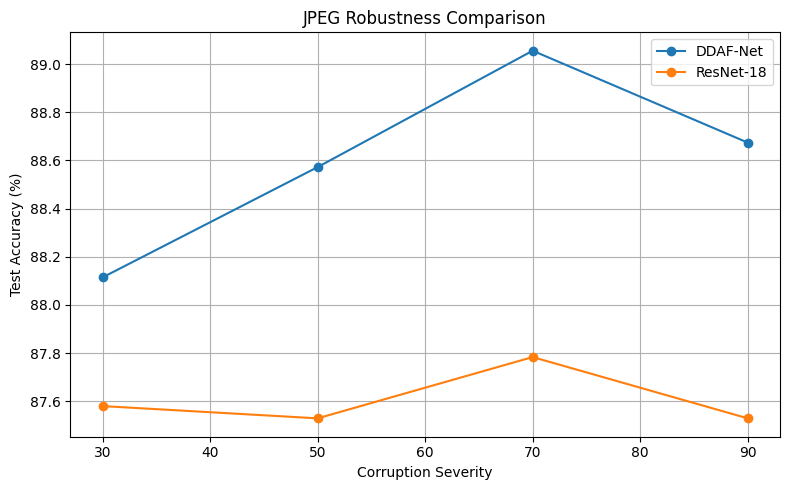

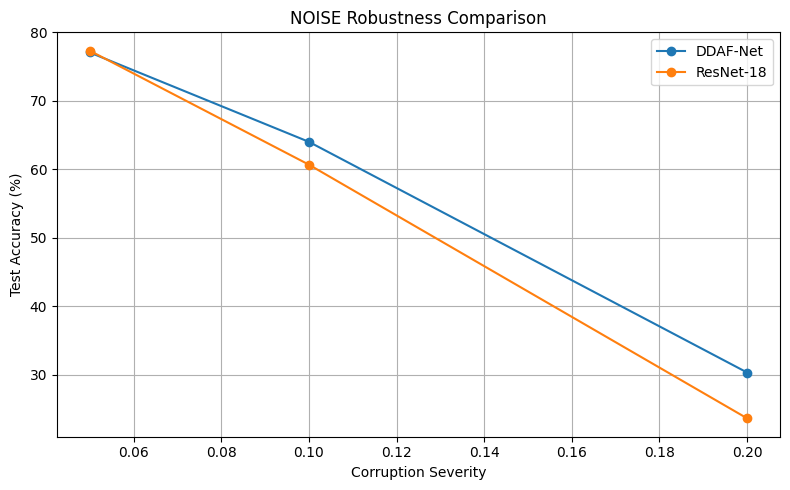

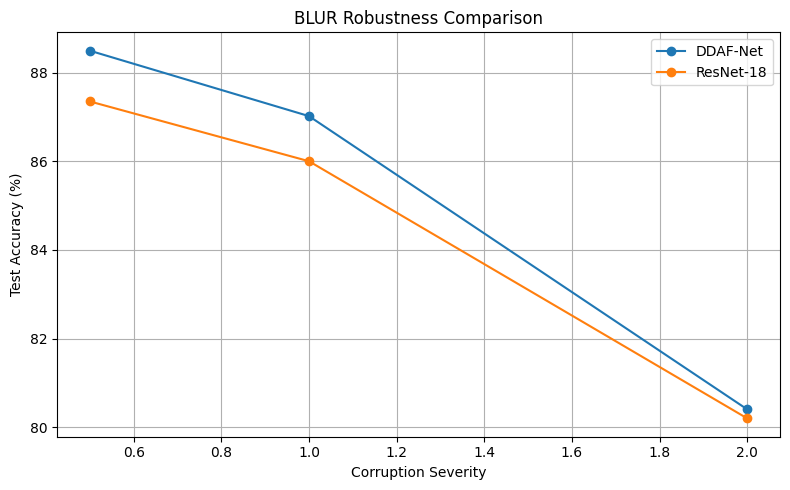

Robustness graphs saved.


In [64]:

import matplotlib.pyplot as plt

for corruption in robustness_df["Corruption"].unique():

    subset = robustness_df[
        robustness_df["Corruption"] == corruption
    ]

    plt.figure(figsize=(8, 5))

    for model_name in ["DDAF-Net", "ResNet-18"]:

        model_data = subset[
            subset["Model"] == model_name
        ]

        plt.plot(
            model_data["Severity"],
            model_data["Accuracy (%)"],
            marker="o",
            label=model_name
        )

    plt.title(f"{corruption.upper()} Robustness Comparison")
    plt.xlabel("Corruption Severity")
    plt.ylabel("Test Accuracy (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        WOOF_DIR / f"{corruption}_robustness.png",
        dpi=300
    )

    plt.show()

print("Robustness graphs saved.")


In [65]:

import pandas as pd
from pathlib import Path

final_results = pd.DataFrame([
    {
        "Dataset": "Imagenette2-320",
        "Model": "DDAF-Net",
        "Accuracy (%)": 96.79,
        "Macro Precision": 0.9683,
        "Macro Recall": 0.9678,
        "Macro F1": 0.9679,
        "McNemar p-value": 4.216e-7
    },
    {
        "Dataset": "Imagenette2-320",
        "Model": "ResNet-18",
        "Accuracy (%)": 95.52,
        "Macro Precision": 0.9555,
        "Macro Recall": 0.9555,
        "Macro F1": 0.9552,
        "McNemar p-value": 4.216e-7
    },
    {
        "Dataset": "ImageWoof2-320",
        "Model": "DDAF-Net",
        "Accuracy (%)": 88.572156,
        "Macro Precision": 0.882315,
        "Macro Recall": 0.878075,
        "Macro F1": 0.879284,
        "McNemar p-value": 0.0181610921
    },
    {
        "Dataset": "ImageWoof2-320",
        "Model": "ResNet-18",
        "Accuracy (%)": 87.630440,
        "Macro Precision": 0.874101,
        "Macro Recall": 0.865897,
        "Macro F1": 0.868248,
        "McNemar p-value": 0.0181610921
    }
])

final_results.to_csv(
    "/kaggle/working/final_research_results.csv",
    index=False
)

print(final_results.to_string(index=False))
print("\nFinal research results saved.")


        Dataset     Model  Accuracy (%)  Macro Precision  Macro Recall  Macro F1  McNemar p-value
Imagenette2-320  DDAF-Net     96.790000         0.968300      0.967800  0.967900     4.216000e-07
Imagenette2-320 ResNet-18     95.520000         0.955500      0.955500  0.955200     4.216000e-07
 ImageWoof2-320  DDAF-Net     88.572156         0.882315      0.878075  0.879284     1.816109e-02
 ImageWoof2-320 ResNet-18     87.630440         0.874101      0.865897  0.868248     1.816109e-02

Final research results saved.


In [70]:
from pathlib import Path

backup = Path("/kaggle/working/DDAF_Net_Research_Backup.zip")
backup_dir = Path("/kaggle/working/research_backup")

print("Backup folder exists:", backup_dir.exists())

if backup_dir.exists():
    for item in backup_dir.iterdir():
        print(item.name, "-", round(item.stat().st_size / (1024**2), 2), "MB")

print("\nZIP exists:", backup.exists())

if backup.exists():
    print("ZIP size:", round(backup.stat().st_size / (1024**2), 2), "MB")

Backup folder exists: True
imagewoof_experiments - 0.0 MB
ddaf_training - 0.0 MB
resnet18_pretrained_baseline - 0.0 MB
mcnemar_test_results.csv - 0.0 MB
final_research_results.csv - 0.0 MB

ZIP exists: True
ZIP size: 1538.48 MB


In [71]:
# ============================================================
# CELL 6: CREATE COMPLETE RESEARCH BACKUP ZIP
# ============================================================

import shutil
from pathlib import Path

# 1. Define research folders and result files
backup_items = [
    "/kaggle/working/ddaf_training",
    "/kaggle/working/resnet18_pretrained_baseline",
    "/kaggle/working/imagewoof_experiments",
    "/kaggle/working/mcnemar_test_results.csv",
    "/kaggle/working/final_research_results.csv"
]

# 2. Create backup directory
backup_dir = Path("/kaggle/working/research_backup")
backup_dir.mkdir(parents=True, exist_ok=True)

# 3. Copy research files and folders
for item in backup_items:
    source = Path(item)

    if source.exists():
        destination = backup_dir / source.name

        if source.is_dir():
            if destination.exists():
                shutil.rmtree(destination)

            shutil.copytree(source, destination)
            print(f"Copied folder: {source.name}")

        else:
            shutil.copy2(source, destination)
            print(f"Copied file: {source.name}")

    else:
        print(f"WARNING: Not found: {source}")

# 4. Create ZIP archive
zip_path = shutil.make_archive(
    "/kaggle/working/DDAF_Net_Research_Backup",
    "zip",
    backup_dir
)

# 5. Verify ZIP
zip_file = Path(zip_path)

print("\n======================================")
print("RESEARCH BACKUP COMPLETED")
print("======================================")
print("ZIP location:", zip_file)
print("ZIP size:", round(zip_file.stat().st_size / (1024**2), 2), "MB")
print("ZIP exists:", zip_file.exists())
print("======================================")

Copied folder: ddaf_training
Copied folder: resnet18_pretrained_baseline
Copied folder: imagewoof_experiments
Copied file: mcnemar_test_results.csv
Copied file: final_research_results.csv


KeyboardInterrupt: 

In [72]:
import shutil
from pathlib import Path

# Create ZIP archive
zip_path = shutil.make_archive(
    "/kaggle/working/DDAF_Net_Research_Backup",
    "zip",
    "/kaggle/working/research_backup"
)

# Verify backup
backup = Path(zip_path)

print("================================")
print("RESEARCH BACKUP COMPLETED")
print("================================")
print("ZIP location:", backup)
print("ZIP exists:", backup.exists())
print("ZIP size:", round(backup.stat().st_size / (1024**2), 2), "MB")
print("================================")

KeyboardInterrupt: 

In [73]:
from pathlib import Path

zip_path = Path("/kaggle/working/DDAF_Net_Research_Backup.zip")

if zip_path.exists():
    print("ZIP FOUND")
    print("Size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")
else:
    print("ZIP NOT FOUND")

ZIP FOUND
Size: 792.6 MB


In [74]:
import zipfile
from pathlib import Path

zip_path = Path("/kaggle/working/DDAF_Net_Research_Backup.zip")

try:
    with zipfile.ZipFile(zip_path, "r") as z:
        bad_file = z.testzip()

    if bad_file is None:
        print("ZIP INTEGRITY: PASSED")
        print("Archive is readable.")
    else:
        print("ZIP INTEGRITY: FAILED")
        print("Problem file:", bad_file)

except Exception as e:
    print("ZIP INTEGRITY: FAILED")
    print(e)

ZIP INTEGRITY: PASSED
Archive is readable.


In [75]:
import zipfile

zip_path = "/kaggle/working/DDAF_Net_Research_Backup.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    files = z.namelist()

    keywords = [
        "ddaf_best.pth",
        "resnet18_pretrained_best.pth",
        "ddaf_woof_best.pth",
        "resnet_woof_best.pth",
        "robustness_results.csv",
        "imagewoof_mcnemar_results.csv",
        "final_research_results.csv"
    ]

    print("CHECKPOINT AND RESULTS VERIFICATION")

    for keyword in keywords:
        matches = [f for f in files if f.endswith(keyword)]
        print(("FOUND" if matches else "MISSING"), "-", keyword)

CHECKPOINT AND RESULTS VERIFICATION
MISSING - ddaf_best.pth
MISSING - resnet18_pretrained_best.pth
FOUND - ddaf_woof_best.pth
FOUND - resnet_woof_best.pth
FOUND - robustness_results.csv
FOUND - imagewoof_mcnemar_results.csv
FOUND - final_research_results.csv


In [76]:
from pathlib import Path

checkpoints = [
    Path("/kaggle/working/ddaf_training/ddaf_best.pth"),
    Path("/kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth")
]

for file in checkpoints:
    if file.exists():
        print("FOUND:", file)
        print("Size:", round(file.stat().st_size / (1024**2), 2), "MB")
    else:
        print("NOT FOUND:", file)

FOUND: /kaggle/working/ddaf_training/ddaf_best.pth
Size: 291.86 MB
FOUND: /kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth
Size: 128.09 MB


In [77]:
import zipfile
from pathlib import Path

checkpoint_files = [
    Path("/kaggle/working/ddaf_training/ddaf_best.pth"),
    Path("/kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth")
]

zip_path = Path("/kaggle/working/Imagenette_Model_Checkpoints.zip")

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED) as z:
    for file in checkpoint_files:
        z.write(file, arcname=file.name)
        print("Added:", file.name)

print("\nCHECKPOINT BACKUP CREATED")
print("Location:", zip_path)
print("Size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

Added: ddaf_best.pth
Added: resnet18_pretrained_best.pth

CHECKPOINT BACKUP CREATED
Location: /kaggle/working/Imagenette_Model_Checkpoints.zip
Size: 419.96 MB


In [78]:
import zipfile

with zipfile.ZipFile("/kaggle/working/Imagenette_Model_Checkpoints.zip", "r") as z:
    print("ZIP integrity:", "PASSED" if z.testzip() is None else "FAILED")
    print("Files:", z.namelist())

ZIP integrity: PASSED
Files: ['ddaf_best.pth', 'resnet18_pretrained_best.pth']


Device: cuda
Test images: 3929

GAUSSIAN NOISE SEVERITY: 0.05
DDAF-Net  | Accuracy: 56.12% | Macro F1: 0.5544
ResNet-18 | Accuracy: 50.73% | Macro F1: 0.4943

GAUSSIAN NOISE SEVERITY: 0.1
DDAF-Net  | Accuracy: 53.17% | Macro F1: 0.5266
ResNet-18 | Accuracy: 47.06% | Macro F1: 0.4552

GAUSSIAN NOISE SEVERITY: 0.2
DDAF-Net  | Accuracy: 45.08% | Macro F1: 0.4391
ResNet-18 | Accuracy: 40.16% | Macro F1: 0.3807

CONTROLLED GAUSSIAN NOISE EXPERIMENT COMPLETED
 Noise_Severity  DDAF_Accuracy  DDAF_Macro_F1  ResNet_Accuracy  ResNet_Macro_F1
           0.05      56.121150       0.554356        50.725375         0.494263
           0.10      53.168745       0.526585        47.060321         0.455202
           0.20      45.075083       0.439128        40.162891         0.380694

Results saved to:
/kaggle/working/imagewoof_experiments/controlled_gaussian_noise_results.csv


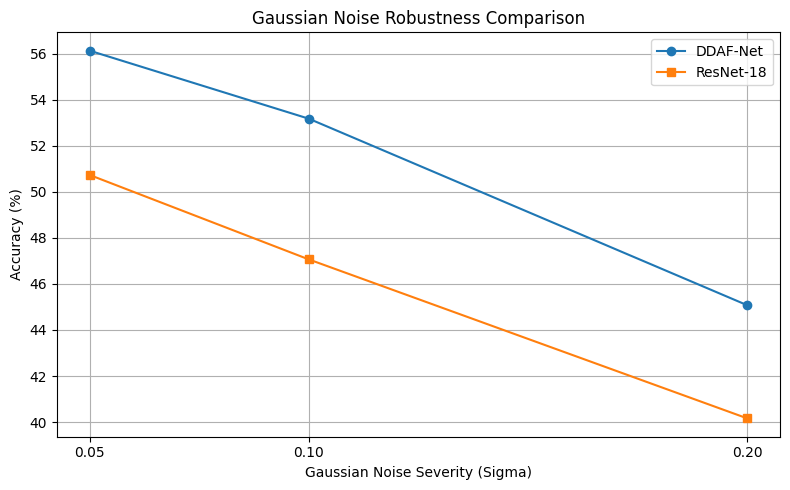

Graph saved: /kaggle/working/imagewoof_experiments/controlled_gaussian_noise_comparison.png


In [80]:

# ============================================================
# CONTROLLED GAUSSIAN NOISE ROBUSTNESS EXPERIMENT
# DDAF-Net vs ResNet-18 | ImageWoof2-320
# ============================================================

import torch
import pandas as pd
import numpy as np
from PIL import Image as PILImage
from pathlib import Path

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

NOISE_LEVELS = [0.05, 0.10, 0.20]
BATCH_SIZE = 8
RANDOM_SEED = 2026

OUTPUT_DIR = Path(
    "/kaggle/working/imagewoof_experiments"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Test images:", len(test_dataset_woof))


# ------------------------------------------------------------
# 2. FIXED GAUSSIAN NOISE DATASET
# ------------------------------------------------------------

class FixedNoiseDataset(Dataset):

    def __init__(self, base_dataset, sigma, seed=2026):

        self.base_dataset = base_dataset
        self.sigma = sigma
        self.seed = seed

        self.to_tensor = transforms.Compose([
            transforms.Resize((160, 160)),
            transforms.ToTensor()
        ])

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        # Obtain original image and label
        image, label = self.base_dataset[idx]

        # Convert image to tensor if needed
        if not torch.is_tensor(image):
            image = self.to_tensor(image)

        # Ensure RGB tensor with expected size
        if image.ndim == 3 and image.shape[0] != 3:
            image = image.permute(2, 0, 1)

        image = image.float()

        # Generate reproducible noise for this image
        generator = torch.Generator()
        generator.manual_seed(self.seed + idx)

        noise = torch.randn(
            image.shape,
            generator=generator,
            dtype=image.dtype
        ) * self.sigma

        # Apply noise before normalization
        noisy_image = torch.clamp(
            image + noise, 0.0, 1.0
        )

        noisy_image = self.normalize(noisy_image)

        return noisy_image, int(label)


# ------------------------------------------------------------
# 3. EXTRACT CLASSIFICATION LOGITS
# ------------------------------------------------------------

def extract_logits(outputs):

    if isinstance(outputs, torch.Tensor):
        return outputs

    if isinstance(outputs, (tuple, list)):

        for item in outputs:
            if torch.is_tensor(item) and item.ndim == 2:
                return item

        raise ValueError(
            "No 2D classification logits found in model output."
        )

    if isinstance(outputs, dict):

        for key in ["logits", "out", "output"]:
            if key in outputs:
                return extract_logits(outputs[key])

        raise ValueError(
            "Could not identify logits in dictionary output."
        )

    raise TypeError(
        f"Unsupported model output type: {type(outputs)}"
    )


# ------------------------------------------------------------
# 4. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model.eval()

    predictions = []
    actual_labels = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)

            outputs = model(images)

            logits = extract_logits(outputs)

            predicted = logits.argmax(dim=1)

            predictions.extend(
                predicted.cpu().numpy().tolist()
            )

            actual_labels.extend(
                labels.numpy().tolist()
            )

    accuracy = accuracy_score(
        actual_labels, predictions
    ) * 100

    macro_f1 = f1_score(
        actual_labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# ------------------------------------------------------------
# 5. RUN CONTROLLED EXPERIMENT
# ------------------------------------------------------------

results = []

for sigma in NOISE_LEVELS:

    print("\n" + "=" * 55)
    print(f"GAUSSIAN NOISE SEVERITY: {sigma}")
    print("=" * 55)

    noisy_dataset = FixedNoiseDataset(
        base_dataset=test_dataset_woof,
        sigma=sigma,
        seed=RANDOM_SEED
    )

    noisy_loader = DataLoader(
        noisy_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Evaluate DDAF-Net
    ddaf_accuracy, ddaf_f1 = evaluate_model(
        ddaf_woof,
        noisy_loader
    )

    print(
        f"DDAF-Net  | Accuracy: {ddaf_accuracy:.2f}% "
        f"| Macro F1: {ddaf_f1:.4f}"
    )

    # Evaluate ResNet-18 on exactly the same noisy images
    resnet_accuracy, resnet_f1 = evaluate_model(
        resnet_woof,
        noisy_loader
    )

    print(
        f"ResNet-18 | Accuracy: {resnet_accuracy:.2f}% "
        f"| Macro F1: {resnet_f1:.4f}"
    )

    results.append({
        "Noise_Severity": sigma,
        "DDAF_Accuracy": ddaf_accuracy,
        "DDAF_Macro_F1": ddaf_f1,
        "ResNet_Accuracy": resnet_accuracy,
        "ResNet_Macro_F1": resnet_f1
    })


# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

csv_path = (
    OUTPUT_DIR /
    "controlled_gaussian_noise_results.csv"
)

results_df.to_csv(csv_path, index=False)

print("\n" + "=" * 65)
print("CONTROLLED GAUSSIAN NOISE EXPERIMENT COMPLETED")
print("=" * 65)

print(results_df.to_string(index=False))

print("\nResults saved to:")
print(csv_path)


# ------------------------------------------------------------
# 7. CREATE COMPARISON GRAPH
# ------------------------------------------------------------

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Noise_Severity"],
    results_df["DDAF_Accuracy"],
    marker="o",
    label="DDAF-Net"
)

plt.plot(
    results_df["Noise_Severity"],
    results_df["ResNet_Accuracy"],
    marker="s",
    label="ResNet-18"
)

plt.xlabel("Gaussian Noise Severity (Sigma)")
plt.ylabel("Accuracy (%)")
plt.title("Gaussian Noise Robustness Comparison")
plt.xticks(NOISE_LEVELS)
plt.grid(True)
plt.legend()
plt.tight_layout()

graph_path = (
    OUTPUT_DIR /
    "controlled_gaussian_noise_comparison.png"
)

plt.savefig(graph_path, dpi=300)
plt.show()

print("Graph saved:", graph_path)


Device: cuda
Test images: 3929

Testing Gaussian noise: 0.05
DDAF-Net: 76.41% | F1: 0.7602
ResNet-18: 76.18% | F1: 0.7537

Testing Gaussian noise: 0.1
DDAF-Net: 63.93% | F1: 0.6348
ResNet-18: 60.88% | F1: 0.6022

Testing Gaussian noise: 0.2
DDAF-Net: 30.19% | F1: 0.2921
ResNet-18: 23.08% | F1: 0.1844

FINAL GAUSSIAN NOISE RESULTS
 Noise_Severity  DDAF_Accuracy  DDAF_Macro_F1  ResNet_Accuracy  ResNet_Macro_F1
           0.05      76.406210       0.760203        76.177144         0.753654
           0.10      63.934843       0.634789        60.880631         0.602158
           0.20      30.185798       0.292070        23.084754         0.184375

Saved: /kaggle/working/imagewoof_experiments/corrected_gaussian_noise_results.csv


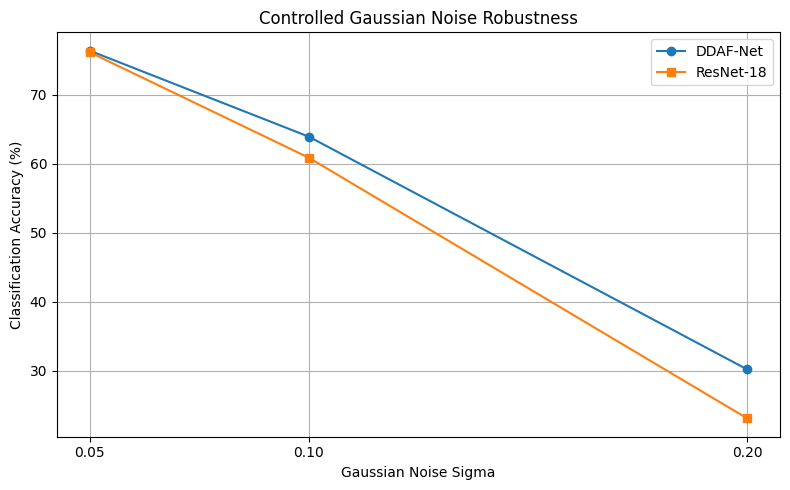

Graph saved: /kaggle/working/imagewoof_experiments/corrected_gaussian_noise.png

EXPERIMENT FINISHED


In [81]:

# ============================================================
# FINAL CORRECTED GAUSSIAN NOISE EXPERIMENT
# DDAF-Net vs ResNet-18 | ImageWoof2-320
# ============================================================

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score

# Configuration
NOISE_LEVELS = [0.05, 0.10, 0.20]
BATCH_SIZE = 8
SEED = 2026

OUTPUT_DIR = Path("/kaggle/working/imagewoof_experiments")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Test images:", len(test_dataset_woof))


# ------------------------------------------------------------
# 1. RAW IMAGE DATASET
# ------------------------------------------------------------

class CorrectGaussianDataset(Dataset):

    def __init__(self, image_folder, sigma, seed=2026):

        self.samples = image_folder.samples
        self.sigma = sigma
        self.seed = seed

        self.resize = transforms.Resize((160, 160))
        self.to_tensor = transforms.ToTensor()

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        path, label = self.samples[idx]

        # Read original, unnormalized image
        image = Image.open(path).convert("RGB")
        image = self.resize(image)
        image = self.to_tensor(image)

        # Generate fixed noise for each image
        generator = torch.Generator()
        generator.manual_seed(self.seed + idx)

        noise = torch.randn(
            image.shape,
            generator=generator
        ) * self.sigma

        # Add noise BEFORE normalization
        noisy_image = torch.clamp(
            image + noise, 0.0, 1.0
        )

        # Normalize exactly once
        noisy_image = self.normalize(noisy_image)

        return noisy_image, label


# ------------------------------------------------------------
# 2. EXTRACT CLASSIFICATION LOGITS
# ------------------------------------------------------------

def get_logits(output):

    if torch.is_tensor(output):
        return output

    if isinstance(output, (tuple, list)):
        for item in output:
            if torch.is_tensor(item) and item.ndim == 2:
                return item

    if isinstance(output, dict):
        for key in ["logits", "out", "output"]:
            if key in output:
                return get_logits(output[key])

    raise ValueError("Classification logits not found.")


# ------------------------------------------------------------
# 3. EVALUATION
# ------------------------------------------------------------

def evaluate_model(model, loader):

    model.eval()

    predictions = []
    actual = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)

            output = model(images)
            logits = get_logits(output)

            predictions.extend(
                logits.argmax(dim=1).cpu().tolist()
            )

            actual.extend(labels.tolist())

    accuracy = accuracy_score(actual, predictions) * 100

    macro_f1 = f1_score(
        actual,
        predictions,
        average="macro",
        zero_division=0
    )

    return accuracy, macro_f1


# ------------------------------------------------------------
# 4. RUN EXPERIMENT
# ------------------------------------------------------------

results = []

for sigma in NOISE_LEVELS:

    print("\nTesting Gaussian noise:", sigma)

    dataset = CorrectGaussianDataset(
        test_dataset_woof,
        sigma=sigma,
        seed=SEED
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Both models use the SAME deterministic dataset
    ddaf_acc, ddaf_f1 = evaluate_model(
        ddaf_woof, loader
    )

    resnet_acc, resnet_f1 = evaluate_model(
        resnet_woof, loader
    )

    results.append({
        "Noise_Severity": sigma,
        "DDAF_Accuracy": ddaf_acc,
        "DDAF_Macro_F1": ddaf_f1,
        "ResNet_Accuracy": resnet_acc,
        "ResNet_Macro_F1": resnet_f1
    })

    print(
        f"DDAF-Net: {ddaf_acc:.2f}% | F1: {ddaf_f1:.4f}"
    )

    print(
        f"ResNet-18: {resnet_acc:.2f}% | F1: {resnet_f1:.4f}"
    )


# ------------------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

csv_path = OUTPUT_DIR / "corrected_gaussian_noise_results.csv"
results_df.to_csv(csv_path, index=False)

print("\nFINAL GAUSSIAN NOISE RESULTS")
print(results_df.to_string(index=False))
print("\nSaved:", csv_path)


# ------------------------------------------------------------
# 6. SAVE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Noise_Severity"],
    results_df["DDAF_Accuracy"],
    marker="o",
    label="DDAF-Net"
)

plt.plot(
    results_df["Noise_Severity"],
    results_df["ResNet_Accuracy"],
    marker="s",
    label="ResNet-18"
)

plt.xlabel("Gaussian Noise Sigma")
plt.ylabel("Classification Accuracy (%)")
plt.title("Controlled Gaussian Noise Robustness")
plt.xticks(NOISE_LEVELS)
plt.grid(True)
plt.legend()
plt.tight_layout()

graph_path = OUTPUT_DIR / "corrected_gaussian_noise.png"
plt.savefig(graph_path, dpi=300)
plt.show()

print("Graph saved:", graph_path)
print("\nEXPERIMENT FINISHED")


In [82]:
import inspect

classes_to_extract = [
    DDAFNet,
    AdaptiveFeatureFusion,
    MultiScaleFeatureRefinement
]

for cls in classes_to_extract:
    print("\n" + "=" * 80)
    print("CLASS:", cls.__name__)
    print("=" * 80)

    try:
        print(inspect.getsource(cls))
    except Exception as e:
        print("Could not extract automatically:", e)


CLASS: DDAFNet
Could not extract automatically: source code not available

CLASS: AdaptiveFeatureFusion
Could not extract automatically: source code not available

CLASS: MultiScaleFeatureRefinement
Could not extract automatically: source code not available


In [83]:
# ============================================================
# RECOVER ORIGINAL DDAF-NET ARCHITECTURE SOURCE
# ============================================================

import re

class_names = [
    "DDAFNet",
    "AdaptiveFeatureFusion",
    "MultiScaleFeatureRefinement"
]

history = globals().get("In", [])

for class_name in class_names:

    print("\n" + "=" * 90)
    print("SEARCHING FOR:", class_name)
    print("=" * 90)

    found = False

    pattern = rf"class\s+{class_name}\s*[\(:]"

    for cell_number, cell_source in enumerate(history):

        if not isinstance(cell_source, str):
            continue

        if re.search(pattern, cell_source):

            print(f"\nFOUND IN NOTEBOOK CELL: {cell_number}")
            print("-" * 90)
            print(cell_source)

            found = True

    if not found:
        print("Source not found in execution history.")


SEARCHING FOR: DDAFNet

FOUND IN NOTEBOOK CELL: 26
------------------------------------------------------------------------------------------
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import ResNet18_Weights
from pathlib import Path

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# 1. Adaptive Feature Fusion
class AdaptiveFeatureFusion(nn.Module):
    def __init__(self, channels=512):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):
        combined = torch.cat(
            [compression_features, style_features], dim=1
        )
        weights = F.softmax(self.gate(combined), dim=1)
        fused = (
            weights[:, 0:1] * c

In [84]:

# ============================================================
# IDENTIFY THE ACTUAL TRAINED DDAF-NET IMPLEMENTATION
# ============================================================

import torch
import inspect

print("MODEL CLASS:", type(ddaf_woof))
print("\nMODEL FORWARD METHOD:")
try:
    print(inspect.getsource(type(ddaf_woof).forward))
except Exception as e:
    print("Source unavailable:", e)

print("\nCHECKING ACTUAL MODEL OUTPUT:")

images, labels = next(iter(test_loader_woof))
images = images[:2].to(DEVICE)

ddaf_woof.eval()

with torch.no_grad():
    output = ddaf_woof(images)

print("Output type:", type(output))

if isinstance(output, (tuple, list)):
    for i, item in enumerate(output):
        if torch.is_tensor(item):
            print(f"Output {i} shape:", item.shape)
        else:
            print(f"Output {i} type:", type(item))

elif torch.is_tensor(output):
    print("Output shape:", output.shape)

print("\nMODEL PARAMETERS:",
      sum(p.numel() for p in ddaf_woof.parameters()))

print("\nDIAGNOSTIC COMPLETED")


MODEL CLASS: <class '__main__.DDAFNet'>

MODEL FORWARD METHOD:
    def forward(self, x):
        shared_features = self.shared(x)

        compression_map = self.compression_branch(shared_features)
        style_map = self.style_branch(shared_features)

        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        fused_features, fusion_weights = self.adaptive_fusion(
            compression_features, style_features
        )

        refined_map = self.refinement(
            compression_map + style_map
        )

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        logits = self.classifier(
            fused_features + refined_features
        )

        return logits, fusion_weights


CHECKING ACTUAL MODEL OUTPUT:
Output type: <class 'tuple'>
Output 0 shape: torch.Size([2, 10])
Output

In [85]:

# ============================================================
# ABLATION STUDY: INITIAL CHECKPOINT VERIFICATION
# ============================================================

from pathlib import Path
import torch

INITIAL_PATH = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

print("Checkpoint exists:", INITIAL_PATH.exists())

if INITIAL_PATH.exists():

    checkpoint = torch.load(
        INITIAL_PATH,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):

        if "model_state_dict" in checkpoint:
            state = checkpoint["model_state_dict"]
        else:
            state = checkpoint

        print("\nTotal parameter tensors:", len(state))

        for prefix in [
            "shared.",
            "compression_branch.",
            "style_branch.",
            "adaptive_fusion.",
            "refinement.",
            "classifier."
        ]:
            count = sum(
                key.startswith(prefix) for key in state
            )
            print(prefix, count)

        print("\nINITIALIZATION CHECK COMPLETED")

else:
    print("Please check the Kaggle input dataset.")


Checkpoint exists: True
Checkpoint type: <class 'collections.OrderedDict'>

Total parameter tensors: 246
shared. 30
compression_branch. 90
style_branch. 90
adaptive_fusion. 4
refinement. 28
classifier. 4

INITIALIZATION CHECK COMPLETED


In [86]:
from pathlib import Path
import torch

# Existing full DDAF-Net checkpoint
full_path = Path(
    "/kaggle/working/imagewoof_experiments/"
    "ddaf_net/ddaf_woof_best.pth"
)

initial_path = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

print("INITIAL CHECKPOINT:", initial_path.exists())
print("FULL MODEL CHECKPOINT:", full_path.exists())

if full_path.exists():
    full_ckpt = torch.load(
        full_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nFull checkpoint type:", type(full_ckpt))

    if isinstance(full_ckpt, dict):
        print("Checkpoint keys:", list(full_ckpt.keys())[:15])

        if "model_state_dict" in full_ckpt:
            print("Model state dict: model_state_dict")
        elif "state_dict" in full_ckpt:
            print("Model state dict: state_dict")
        else:
            print("Checking whether checkpoint itself is a state dict.")

print("\nDATASET CHECK")

for name, loader in [
    ("Train", train_loader_woof),
    ("Validation", val_loader_woof),
    ("Test", test_loader_woof)
]:
    print(name, "batches:", len(loader))

print("\nDEVICE:", DEVICE)
print("\nABLATION PREFLIGHT COMPLETED")

INITIAL CHECKPOINT: True
FULL MODEL CHECKPOINT: True

Full checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'val_accuracy', 'class_names']
Model state dict: model_state_dict

DATASET CHECK
Train batches: 1016
Validation batches: 113
Test batches: 492

DEVICE: cuda

ABLATION PREFLIGHT COMPLETED


Device: cuda
Training batches: 1016
Validation batches: 113
Test batches: 492

Initial checkpoint tensors: 246

TRAINING: A1_without_style
Loaded compatible pretrained weights.
Missing keys: 0
Unused checkpoint keys: 94
Epoch 1/3 | Train Loss: 1.3544 | Train Acc: 60.69% | Val Loss: 0.5496 | Val Acc: 84.72%
Best checkpoint saved.
Epoch 2/3 | Train Loss: 0.7229 | Train Acc: 78.05% | Val Loss: 0.4331 | Val Acc: 85.38%
Best checkpoint saved.
Epoch 3/3 | Train Loss: 0.5651 | Train Acc: 82.78% | Val Loss: 0.4028 | Val Acc: 87.38%
Best checkpoint saved.
Best validation accuracy: 87.37541528239203

TRAINING: A2_without_compression
Loaded compatible pretrained weights.
Missing keys: 0
Unused checkpoint keys: 94
Epoch 1/3 | Train Loss: 1.3655 | Train Acc: 59.39% | Val Loss: 0.5617 | Val Acc: 83.50%
Best checkpoint saved.
Epoch 2/3 | Train Loss: 0.7148 | Train Acc: 78.72% | Val Loss: 0.4079 | Val Acc: 86.49%
Best checkpoint saved.
Epoch 3/3 | Train Loss: 0.5775 | Train Acc: 81.84% | Val Loss: 0.3

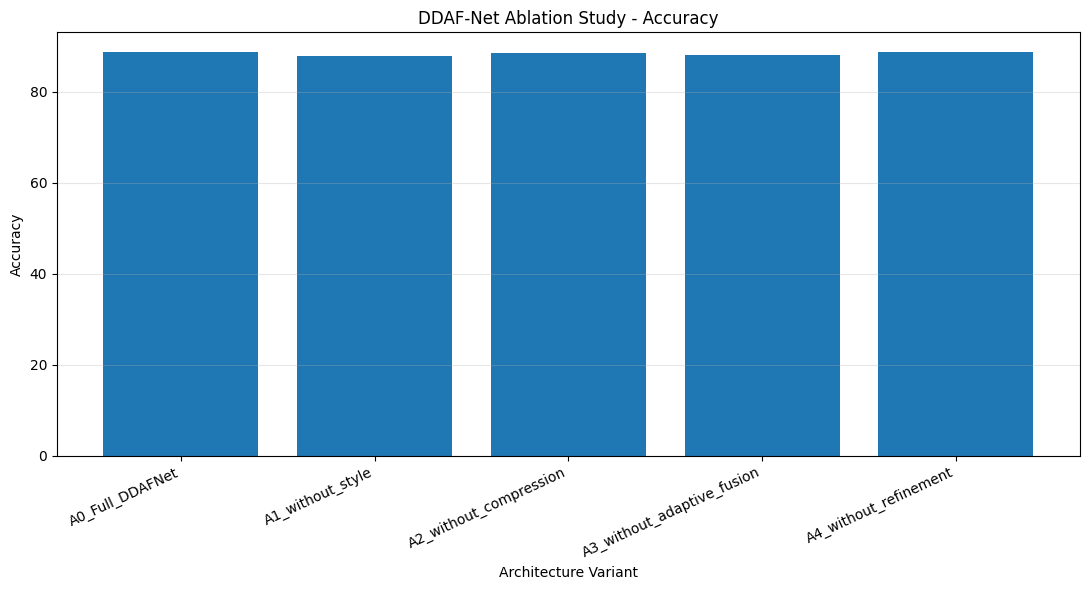

Graph saved: /kaggle/working/imagewoof_experiments/ablation/ablation_accuracy.png


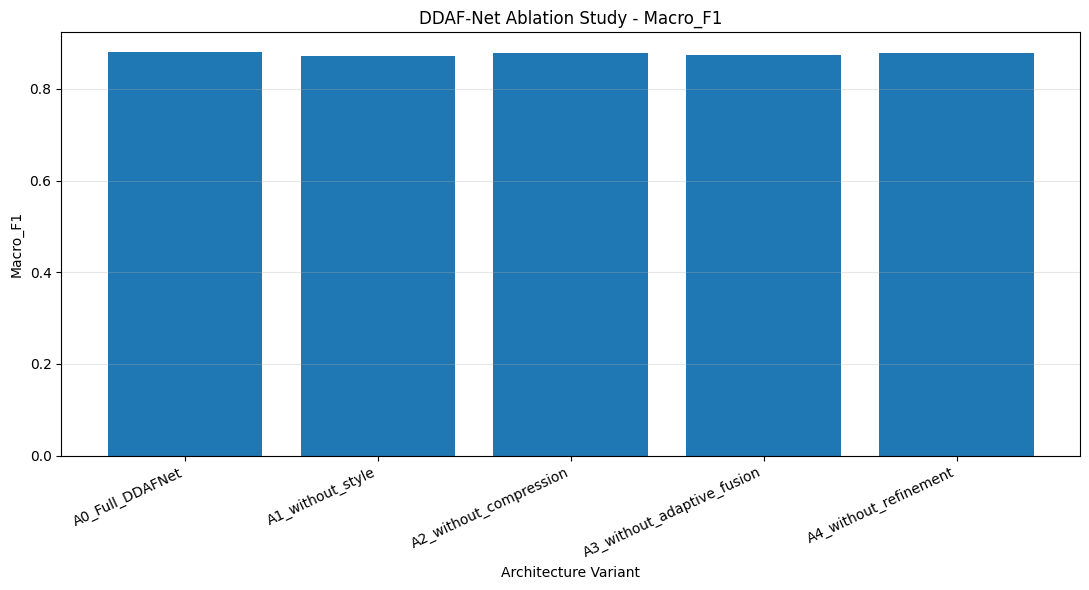

Graph saved: /kaggle/working/imagewoof_experiments/ablation/ablation_macro_f1.png

DDAF-NET ABLATION STUDY COMPLETED
Results: /kaggle/working/imagewoof_experiments/ablation/ablation_results.csv
Checkpoint directory: /kaggle/working/imagewoof_experiments/ablation
Number of evaluated models: 5


In [87]:

# ============================================================
# DDAF-NET ABLATION STUDY
# Four variants + original full-model reference
# Dataset: ImageWoof2-320
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

INITIAL_PATH = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "ddaf-net-initial/ddaf_net_initial.pt"
)

FULL_PATH = Path(
    "/kaggle/working/imagewoof_experiments/"
    "ddaf_net/ddaf_woof_best.pth"
)

ABLATION_DIR = Path(
    "/kaggle/working/imagewoof_experiments/ablation"
)
ABLATION_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 3
LR = 1e-5
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 10

assert INITIAL_PATH.exists(), "Initial checkpoint missing"
assert FULL_PATH.exists(), "Full DDAF checkpoint missing"

print("Device:", DEVICE)
print("Training batches:", len(train_loader_woof))
print("Validation batches:", len(val_loader_woof))
print("Test batches:", len(test_loader_woof))


# ------------------------------------------------------------
# 2. ORIGINAL ADAPTIVE FEATURE FUSION
# ------------------------------------------------------------

class AdaptiveFeatureFusion(nn.Module):

    def __init__(self, channels=512):
        super().__init__()

        self.gate = nn.Sequential(
            nn.Linear(channels * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(256, 2)
        )

    def forward(self, compression_features, style_features):

        combined = torch.cat(
            [compression_features, style_features],
            dim=1
        )

        weights = F.softmax(self.gate(combined), dim=1)

        fused = (
            weights[:, 0:1] * compression_features
            + weights[:, 1:2] * style_features
        )

        return fused, weights


# ------------------------------------------------------------
# 3. ORIGINAL MULTI-SCALE FEATURE REFINEMENT
# ------------------------------------------------------------

class MultiScaleFeatureRefinement(nn.Module):

    def __init__(self, channels=512):
        super().__init__()

        self.branch1 = nn.Sequential(
            nn.Conv2d(channels, 256, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(channels, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(
                channels, 256, 3,
                padding=2, dilation=2
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(768, channels, 1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        f1 = self.branch1(x)
        f2 = self.branch2(x)
        f3 = self.branch3(x)

        return self.fusion(
            torch.cat([f1, f2, f3], dim=1)
        )


# ------------------------------------------------------------
# 4. EXACT FULL DDAF-NET REFERENCE ARCHITECTURE
# ------------------------------------------------------------

class FullDDAFNet(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        backbone = models.resnet18(weights=None)

        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        self.compression_branch = nn.Sequential(
            backbone.layer2,
            backbone.layer3,
            backbone.layer4
        )

        style_backbone = models.resnet18(weights=None)

        self.style_branch = nn.Sequential(
            style_backbone.layer2,
            style_backbone.layer3,
            style_backbone.layer4
        )

        self.adaptive_fusion = AdaptiveFeatureFusion(512)
        self.refinement = MultiScaleFeatureRefinement(512)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        shared_features = self.shared(x)

        compression_map = self.compression_branch(
            shared_features
        )

        style_map = self.style_branch(shared_features)

        compression_features = F.adaptive_avg_pool2d(
            compression_map, 1
        ).flatten(1)

        style_features = F.adaptive_avg_pool2d(
            style_map, 1
        ).flatten(1)

        fused_features, fusion_weights = self.adaptive_fusion(
            compression_features,
            style_features
        )

        refined_map = self.refinement(
            compression_map + style_map
        )

        refined_features = F.adaptive_avg_pool2d(
            refined_map, 1
        ).flatten(1)

        logits = self.classifier(
            fused_features + refined_features
        )

        return logits, fusion_weights


# ------------------------------------------------------------
# 5. ABLATION MODEL
# ------------------------------------------------------------

class DDAFAblation(nn.Module):

    def __init__(
        self,
        num_classes=10,
        use_compression=True,
        use_style=True,
        use_adaptive=True,
        use_refinement=True
    ):

        super().__init__()

        assert use_compression or use_style

        self.use_compression = use_compression
        self.use_style = use_style
        self.use_adaptive = use_adaptive
        self.use_refinement = use_refinement

        backbone = models.resnet18(weights=None)

        self.shared = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1
        )

        if use_compression:

            self.compression_branch = nn.Sequential(
                backbone.layer2,
                backbone.layer3,
                backbone.layer4
            )

        if use_style:

            style_backbone = models.resnet18(weights=None)

            self.style_branch = nn.Sequential(
                style_backbone.layer2,
                style_backbone.layer3,
                style_backbone.layer4
            )

        if use_compression and use_style and use_adaptive:
            self.adaptive_fusion = AdaptiveFeatureFusion(512)

        if use_refinement:
            self.refinement = MultiScaleFeatureRefinement(512)

        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        shared_features = self.shared(x)

        compression_map = None
        style_map = None

        if self.use_compression:
            compression_map = self.compression_branch(
                shared_features
            )

        if self.use_style:
            style_map = self.style_branch(
                shared_features
            )

        # Single-branch ablations
        if self.use_compression and not self.use_style:

            fused_features = F.adaptive_avg_pool2d(
                compression_map, 1
            ).flatten(1)

            refinement_input = compression_map

        elif self.use_style and not self.use_compression:

            fused_features = F.adaptive_avg_pool2d(
                style_map, 1
            ).flatten(1)

            refinement_input = style_map

        # Two-branch ablations
        else:

            compression_features = F.adaptive_avg_pool2d(
                compression_map, 1
            ).flatten(1)

            style_features = F.adaptive_avg_pool2d(
                style_map, 1
            ).flatten(1)

            if self.use_adaptive:

                fused_features, _ = self.adaptive_fusion(
                    compression_features,
                    style_features
                )

            else:

                # Fixed equal-weight feature fusion
                fused_features = (
                    compression_features + style_features
                ) / 2.0

            # Preserve original Cell 30 refinement input
            refinement_input = (
                compression_map + style_map
            )

        if self.use_refinement:

            refined_map = self.refinement(refinement_input)

            refined_features = F.adaptive_avg_pool2d(
                refined_map, 1
            ).flatten(1)

            final_features = (
                fused_features + refined_features
            )

        else:

            final_features = fused_features

        return self.classifier(final_features)


# ------------------------------------------------------------
# 6. LOAD INITIAL PRETRAINED WEIGHTS
# ------------------------------------------------------------

initial_state = torch.load(
    INITIAL_PATH,
    map_location="cpu",
    weights_only=True
)

print("\nInitial checkpoint tensors:", len(initial_state))


# ------------------------------------------------------------
# 7. DEFINE FOUR ABLATION VARIANTS
# ------------------------------------------------------------

variants = {

    "A1_without_style": {
        "use_compression": True,
        "use_style": False,
        "use_adaptive": False,
        "use_refinement": True
    },

    "A2_without_compression": {
        "use_compression": False,
        "use_style": True,
        "use_adaptive": False,
        "use_refinement": True
    },

    "A3_without_adaptive_fusion": {
        "use_compression": True,
        "use_style": True,
        "use_adaptive": False,
        "use_refinement": True
    },

    "A4_without_refinement": {
        "use_compression": True,
        "use_style": True,
        "use_adaptive": True,
        "use_refinement": False
    }
}


# ------------------------------------------------------------
# 8. LOGITS HELPER
# ------------------------------------------------------------

def get_logits(output):

    if torch.is_tensor(output):
        return output

    if isinstance(output, (tuple, list)):
        for item in output:
            if torch.is_tensor(item) and item.ndim == 2:
                return item

    if isinstance(output, dict):
        for key in ["logits", "out", "output"]:
            if key in output:
                return get_logits(output[key])

    raise ValueError("Classification logits not found")


# ------------------------------------------------------------
# 9. TRAINING AND VALIDATION
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

amp_enabled = DEVICE.type == "cuda"


def evaluate_validation(model, loader):

    model.eval()

    correct = 0
    total = 0
    loss_total = 0.0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):

                logits = get_logits(model(images))
                loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            loss_total += loss.item() * labels.size(0)

    return loss_total / total, 100.0 * correct / total


def train_variant(name, config):

    print("\n" + "=" * 65)
    print("TRAINING:", name)
    print("=" * 65)

    model = DDAFAblation(
        num_classes=NUM_CLASSES,
        **config
    ).to(DEVICE)

    # Load all compatible pretrained initialization weights
    incompatible = model.load_state_dict(
        initial_state,
        strict=False
    )

    print("Loaded compatible pretrained weights.")
    print("Missing keys:", len(incompatible.missing_keys))
    print("Unused checkpoint keys:", len(incompatible.unexpected_keys))

    # Verify the essential layers were initialized
    assert any(
        key.startswith("shared.")
        for key in model.state_dict()
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=amp_enabled
    )

    best_val_accuracy = -1.0

    checkpoint_path = ABLATION_DIR / f"{name}_best.pth"

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader_woof:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):

                logits = get_logits(model(images))
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * labels.size(0)

            predictions = logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = 100.0 * correct / total

        val_loss, val_accuracy = evaluate_validation(
            model,
            val_loader_woof
        )

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

        # Save best validation checkpoint
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "epoch": epoch + 1,
                    "val_accuracy": val_accuracy,
                    "variant": name,
                    "config": config
                },
                checkpoint_path
            )

            print("Best checkpoint saved.")

    print("Best validation accuracy:", best_val_accuracy)

    del model
    del optimizer
    del scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return checkpoint_path


# ------------------------------------------------------------
# 10. TRAIN ALL FOUR ABLATION VARIANTS
# ------------------------------------------------------------

trained_checkpoints = {}

for name, config in variants.items():

    # Skip already completed variants if restarting this cell
    checkpoint_path = ABLATION_DIR / f"{name}_best.pth"

    if checkpoint_path.exists():

        print("\nExisting checkpoint found:", name)
        print("Keeping existing checkpoint.")
        trained_checkpoints[name] = checkpoint_path
        continue

    trained_checkpoints[name] = train_variant(
        name,
        config
    )

print("\nALL ABLATION TRAINING RUNS COMPLETED")


# ------------------------------------------------------------
# 11. LOAD FULL MODEL AND ABLATION MODELS
# ------------------------------------------------------------

full_checkpoint = torch.load(
    FULL_PATH,
    map_location="cpu",
    weights_only=False
)

full_model = FullDDAFNet(NUM_CLASSES).to(DEVICE)

full_model.load_state_dict(
    full_checkpoint["model_state_dict"],
    strict=True
)

models_to_evaluate = {
    "A0_Full_DDAFNet": full_model
}

for name, config in variants.items():

    model = DDAFAblation(
        num_classes=NUM_CLASSES,
        **config
    ).to(DEVICE)

    checkpoint = torch.load(
        trained_checkpoints[name],
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    models_to_evaluate[name] = model


# ------------------------------------------------------------
# 12. FINAL TEST EVALUATION
# ------------------------------------------------------------

def evaluate_test(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(DEVICE)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=amp_enabled
            ):

                logits = get_logits(model(images))

            predictions = logits.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    return {
        "Accuracy": accuracy_score(
            all_labels, all_predictions
        ) * 100,

        "Precision": precision_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),

        "Recall": recall_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        ),

        "Macro_F1": f1_score(
            all_labels, all_predictions,
            average="macro", zero_division=0
        )
    }


final_results = []

for name, model in models_to_evaluate.items():

    print("\nTesting:", name)

    metrics = evaluate_test(
        model,
        test_loader_woof
    )

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    row = {
        "Model": name,
        **metrics,
        "Parameters": parameters,
        "Parameters_M": parameters / 1e6
    }

    final_results.append(row)

    print(row)


# ------------------------------------------------------------
# 13. SAVE FINAL RESULTS
# ------------------------------------------------------------

ablation_df = pd.DataFrame(final_results)

results_path = ABLATION_DIR / "ablation_results.csv"

ablation_df.to_csv(
    results_path,
    index=False
)

print("\nFINAL ABLATION RESULTS")
print(ablation_df.to_string(index=False))

print("\nCSV saved:", results_path)


# ------------------------------------------------------------
# 14. COMPARISON GRAPHS
# ------------------------------------------------------------

for metric in ["Accuracy", "Macro_F1"]:

    plt.figure(figsize=(11, 6))

    plt.bar(
        ablation_df["Model"],
        ablation_df[metric]
    )

    plt.ylabel(metric)
    plt.xlabel("Architecture Variant")
    plt.title(f"DDAF-Net Ablation Study - {metric}")

    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    graph_path = (
        ABLATION_DIR / f"ablation_{metric.lower()}.png"
    )

    plt.savefig(graph_path, dpi=300)
    plt.show()

    print("Graph saved:", graph_path)


# ------------------------------------------------------------
# 15. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DDAF-NET ABLATION STUDY COMPLETED")
print("=" * 65)

print("Results:", results_path)
print("Checkpoint directory:", ABLATION_DIR)
print("Number of evaluated models:", len(models_to_evaluate))


In [88]:

from pathlib import Path
import zipfile
import os
from collections import Counter

# Find the uploaded Paprika ZIP
zip_files = list(Path("/kaggle/input").rglob("*.zip"))

paprika_zip = next(
    (p for p in zip_files if "paprika" in p.name.lower()),
    None
)

if paprika_zip is None:
    raise FileNotFoundError(
        "Paprika ZIP not found. Check that its Kaggle dataset is attached."
    )

print("Found ZIP:", paprika_zip)

# Extract images
PAPRIKA_ROOT = Path("/kaggle/working/animegan_paprika")

PAPRIKA_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(paprika_zip, "r") as z:
    z.extractall(PAPRIKA_ROOT)

# Locate PNG images
paprika_images = list(PAPRIKA_ROOT.rglob("*.png"))

# Count images by class prefix
class_counts = Counter(
    p.name.split("_")[0]
    for p in paprika_images
)

print("\nTotal images:", len(paprika_images))
print("\nImages by filename prefix:")

for cls, count in sorted(class_counts.items()):
    print(cls, ":", count)

print("\nSample images:")
for p in paprika_images[:10]:
    print(p.name)


FileNotFoundError: Paprika ZIP not found. Check that its Kaggle dataset is attached.

In [89]:
from pathlib import Path

print("=== KAGGLE INPUT FOLDERS ===")

for item in Path("/kaggle/input").iterdir():
    print("\n", item.name)

    if item.is_dir():
        for child in list(item.iterdir())[:15]:
            print("   ", child.name)

print("\n=== ALL ZIP FILES ===")

for p in Path("/kaggle/input").rglob("*.zip"):
    print(p)

=== KAGGLE INPUT FOLDERS ===

 datasets
    agnihotrampramodh

=== ALL ZIP FILES ===


In [90]:
from pathlib import Path

ROOT = Path("/kaggle/input/datasets/agnihotrampramodh")

print("Dataset contents:\n")

for item in ROOT.iterdir():
    print(f"\n📁 {item.name}")

    if item.is_dir():
        for child in list(item.iterdir())[:20]:
            print("   ", child.name)

Dataset contents:


📁 check-points
    ddaf_best.pth
    ddaf_latest.pth

📁 imagenette2-320
    imagenette2-320 (1).tgz

📁 split-manifest
    split_manifest (1).csv

📁 ddaf-net-research
    DDAF_Net_Research

📁 animeganv2-paprika
    animeganv2_paprika

📁 ddaf-net-initial
    DDAF_Net_Research-20261114T091620Z-1-001
    ddaf_net_initial.pt


In [91]:

from pathlib import Path

PAPRIKA_ROOT = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "animeganv2-paprika/animeganv2_paprika"
)

print("Paprika folder exists:", PAPRIKA_ROOT.exists())

print("\nFolder contents:")
for item in PAPRIKA_ROOT.iterdir():
    print(item.name, " [Folder]" if item.is_dir() else " [File]")

print("\nImage count:")
images = [
    p for p in PAPRIKA_ROOT.rglob("*")
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
]
print(len(images))

print("\nFirst 20 image paths:")
for p in images[:20]:
    print(p)


Paprika folder exists: True

Folder contents:
ILSVRC2012_val_00004912.png  [File]
ILSVRC2012_val_00007460.png  [File]
ILSVRC2012_val_00009191.png  [File]
ILSVRC2012_val_00009902.png  [File]
ILSVRC2012_val_00020781.png  [File]
ILSVRC2012_val_00022172.png  [File]
ILSVRC2012_val_00025121.png  [File]
ILSVRC2012_val_00029930.png  [File]
ILSVRC2012_val_00036171.png  [File]
ILSVRC2012_val_00037182.png  [File]
ILSVRC2012_val_00037861.png  [File]
ILSVRC2012_val_00042802.png  [File]
ILSVRC2012_val_00042982.png  [File]
ILSVRC2012_val_00044370.png  [File]
ILSVRC2012_val_00044850.png  [File]
ILSVRC2012_val_00045110.png  [File]
ILSVRC2012_val_00046232.png  [File]
n01440764_10110.png  [File]
n01440764_10281.png  [File]
n01440764_10361.png  [File]
n01440764_10812.png  [File]
n01440764_10910.png  [File]
n01440764_11612.png  [File]
n01440764_11830.png  [File]
n01440764_12131.png  [File]
n01440764_12151.png  [File]
n01440764_13452.png  [File]
n01440764_13842.png  [File]
n01440764_14490.png  [File]
n01440

In [92]:

from pathlib import Path
import pandas as pd

PAPRIKA_ROOT = Path(
    "/kaggle/input/datasets/agnihotrampramodh/"
    "animeganv2-paprika/animeganv2_paprika"
)

# Inspect the existing test dataframe
print("Test dataframe columns:", test_df.columns.tolist())

# Find the image-path column automatically
path_col = None

for col in test_df.columns:
    values = test_df[col].dropna().astype(str)
    if len(values) and values.str.contains(
        r"\.(jpg|jpeg|png)$", case=False, regex=True
    ).any():
        path_col = col
        break

if path_col is None:
    raise ValueError("Could not identify the image path column.")

print("Image path column:", path_col)

# Build original test image filename lookup
test_basenames = {
    Path(str(p)).stem: str(p)
    for p in test_df[path_col]
}

# Match Paprika files to original test images
matched = []
unmatched = []

for image_path in PAPRIKA_ROOT.glob("*"):
    if image_path.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
        continue

    original_stem = image_path.stem

    if original_stem in test_basenames:
        matched.append({
            "paprika_image": str(image_path),
            "original_image": test_basenames[original_stem],
            "filename": image_path.name
        })
    else:
        unmatched.append(image_path.name)

matched_df = pd.DataFrame(matched)

print("\n========== MATCHING RESULTS ==========")
print("Paprika images:", 500)
print("Matched to Imagenette test:", len(matched))
print("Not matched:", len(unmatched))

print("\nMatched examples:")
display(matched_df.head(10))

print("\nUnmatched examples:")
print(unmatched[:20])


Test dataframe columns: ['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition', 'source_path', 'class_label', 'label_text', 'target', 'image_path_resolved']
Image path column: image_id

========== MATCHING RESULTS ==========
Paprika images: 500
Matched to Imagenette test: 500
Not matched: 0

Matched examples:


/tmp/ipykernel_49/846333681.py:17: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  if len(values) and values.str.contains(


,paprika_image,original_image,filename
0,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03028079/ILSVRC2012_val_00004912.JPEG,ILSVRC2012_val_00004912.png
1,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03000684/ILSVRC2012_val_00007460.JPEG,ILSVRC2012_val_00007460.png
2,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n01440764/ILSVRC2012_val_00009191.JPEG,ILSVRC2012_val_00009191.png
3,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03445777/ILSVRC2012_val_00009902.JPEG,ILSVRC2012_val_00009902.png
4,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03445777/ILSVRC2012_val_00020781.JPEG,ILSVRC2012_val_00020781.png
5,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03417042/ILSVRC2012_val_00022172.JPEG,ILSVRC2012_val_00022172.png
6,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03888257/ILSVRC2012_val_00025121.JPEG,ILSVRC2012_val_00025121.png
7,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n01440764/ILSVRC2012_val_00029930.JPEG,ILSVRC2012_val_00029930.png
8,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n03445777/ILSVRC2012_val_00036171.JPEG,ILSVRC2012_val_00036171.png
9,/kaggle/input/datasets/agnihotrampramodh/anime...,test/val/n02102040/ILSVRC2012_val_00037182.JPEG,ILSVRC2012_val_00037182.png



Unmatched examples:
[]


In [93]:

from pathlib import Path
import pandas as pd

# Create matching keys from image filenames
original_lookup = test_df.copy()

original_lookup["match_key"] = original_lookup["image_id"].apply(
    lambda x: Path(str(x)).stem
)

paprika_check = matched_df.copy()

paprika_check["match_key"] = paprika_check["filename"].apply(
    lambda x: Path(str(x)).stem
)

# Attach original labels and split information
columns_to_keep = [
    "match_key", "split", "partition", "label",
    "class_label", "label_text", "target",
    "image_path_resolved"
]

columns_to_keep = [
    c for c in columns_to_keep if c in original_lookup.columns
]

paprika_eval_df = paprika_check.merge(
    original_lookup[columns_to_keep],
    on="match_key",
    how="left",
    validate="one_to_one"
)

print("========== LABEL VERIFICATION ==========")
print("Total Paprika images:", len(paprika_eval_df))
print("Missing labels:", paprika_eval_df["target"].isna().sum())
print("Duplicate matches:", paprika_eval_df["match_key"].duplicated().sum())

print("\nSplit distribution:")
print(paprika_eval_df["split"].value_counts(dropna=False))

if "partition" in paprika_eval_df.columns:
    print("\nPartition distribution:")
    print(paprika_eval_df["partition"].value_counts(dropna=False))

print("\nClass distribution:")
print(paprika_eval_df["class_label"].value_counts(dropna=False))

print("\nSample verified records:")
display(
    paprika_eval_df[
        ["filename", "label_text", "target", "split"]
    ].head(15)
)


========== LABEL VERIFICATION ==========
Total Paprika images: 500
Missing labels: 0
Duplicate matches: 0

Split distribution:
split
test    500
Name: count, dtype: int64

Partition distribution:
partition
test    500
Name: count, dtype: int64

Class distribution:
class_label
n03028079    50
n03000684    50
n01440764    50
n03445777    50
n03417042    50
n03888257    50
n02102040    50
n02979186    50
n03425413    50
n03394916    50
Name: count, dtype: int64

Sample verified records:


,filename,label_text,target,split
0,ILSVRC2012_val_00004912.png,n03028079,4,test
1,ILSVRC2012_val_00007460.png,n03000684,3,test
2,ILSVRC2012_val_00009191.png,n01440764,0,test
3,ILSVRC2012_val_00009902.png,n03445777,8,test
4,ILSVRC2012_val_00020781.png,n03445777,8,test
5,ILSVRC2012_val_00022172.png,n03417042,6,test
6,ILSVRC2012_val_00025121.png,n03888257,9,test
7,ILSVRC2012_val_00029930.png,n01440764,0,test
8,ILSVRC2012_val_00036171.png,n03445777,8,test
9,ILSVRC2012_val_00037182.png,n02102040,1,test


In [94]:
from pathlib import Path
import torch

checkpoint_paths = {
    "DDAF-Net": Path(
        "/kaggle/working/ddaf_training/ddaf_best.pth"
    ),
    "ResNet-18": Path(
        "/kaggle/working/resnet18_pretrained_baseline/"
        "resnet18_pretrained_best.pth"
    )
}

print("========== CHECKPOINT STATUS ==========")

for name, path in checkpoint_paths.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024**2), 2))

print("\n========== MODEL VARIABLES ==========")

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        print(name, ":", type(obj).__name__)

========== CHECKPOINT STATUS ==========

DDAF-Net
Path: /kaggle/working/ddaf_training/ddaf_best.pth
Exists: True
Size (MB): 291.86

ResNet-18
Path: /kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth
Exists: True
Size (MB): 128.09

========== MODEL VARIABLES ==========
model : DDAFAblation
criterion : CrossEntropyLoss
resnet18 : ResNet
resnet_criterion : CrossEntropyLoss
resnet18_pretrained : ResNet
pretrained_criterion : CrossEntropyLoss
ddaf_woof : DDAFNet
resnet_woof : ResNet
criterion_woof : CrossEntropyLoss
module : Sequential
current_model : ResNet
full_model : FullDDAFNet


In [95]:

import torch
from pathlib import Path

paths = {
    "DDAF": "/kaggle/working/ddaf_training/ddaf_best.pth",
    "ResNet": "/kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth"
}

for name, path in paths.items():
    print("\n" + "=" * 55)
    print(name, "CHECKPOINT")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:20])

        state = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )

        if isinstance(state, dict):
            print("Number of tensors:", len(state))
            print("First 15 parameter names:")
            for key in list(state.keys())[:15]:
                value = state[key]
                if hasattr(value, "shape"):
                    print(key, tuple(value.shape))
                else:
                    print(key, type(value).__name__)
    else:
        print("Checkpoint object:", type(checkpoint))



DDAF CHECKPOINT
Top-level keys: ['epoch', 'step', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'class_names', 'class_to_idx', 'val_accuracy']
Number of tensors: 246
First 15 parameter names:
shared.0.weight (64, 3, 7, 7)
shared.1.weight (64,)
shared.1.bias (64,)
shared.1.running_mean (64,)
shared.1.running_var (64,)
shared.1.num_batches_tracked ()
shared.4.0.conv1.weight (64, 64, 3, 3)
shared.4.0.bn1.weight (64,)
shared.4.0.bn1.bias (64,)
shared.4.0.bn1.running_mean (64,)
shared.4.0.bn1.running_var (64,)
shared.4.0.bn1.num_batches_tracked ()
shared.4.0.conv2.weight (64, 64, 3, 3)
shared.4.0.bn2.weight (64,)
shared.4.0.bn2.bias (64,)

ResNet CHECKPOINT
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'val_accuracy']
Number of tensors: 122
First 15 parameter names:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
bn1.running_mean (64,)
bn1.running_var (64,)
bn1.num_batches_tracked ()
layer1.0.conv1.weight (64, 64, 3

In [96]:

import torch
import copy

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint files
ddaf_ckpt = torch.load(
    "/kaggle/working/ddaf_training/ddaf_best.pth",
    map_location="cpu",
    weights_only=False
)

resnet_ckpt = torch.load(
    "/kaggle/working/resnet18_pretrained_baseline/"
    "resnet18_pretrained_best.pth",
    map_location="cpu",
    weights_only=False
)

# Create independent copies of the existing architectures
paprika_ddaf = copy.deepcopy(full_model)
paprika_resnet = copy.deepcopy(resnet18_pretrained)

# Load exact trained weights
ddaf_result = paprika_ddaf.load_state_dict(
    ddaf_ckpt["model_state_dict"],
    strict=True
)

resnet_result = paprika_resnet.load_state_dict(
    resnet_ckpt["model_state_dict"],
    strict=True
)

# Move models to device and set evaluation mode
paprika_ddaf = paprika_ddaf.to(DEVICE).eval()
paprika_resnet = paprika_resnet.to(DEVICE).eval()

print("========== MODEL LOADING SUCCESS ==========")
print("Device:", DEVICE)
print("DDAF architecture:", type(paprika_ddaf).__name__)
print("ResNet architecture:", type(paprika_resnet).__name__)
print("DDAF missing/unexpected keys:",
      ddaf_result.missing_keys, ddaf_result.unexpected_keys)
print("ResNet missing/unexpected keys:",
      resnet_result.missing_keys, resnet_result.unexpected_keys)

print("\nDDAF checkpoint validation accuracy:",
      ddaf_ckpt.get("val_accuracy"))
print("ResNet checkpoint validation accuracy:",
      resnet_ckpt.get("val_accuracy"))


========== MODEL LOADING SUCCESS ==========
Device: cuda
DDAF architecture: FullDDAFNet
ResNet architecture: ResNet
DDAF missing/unexpected keys: [] []
ResNet missing/unexpected keys: [] []

DDAF checkpoint validation accuracy: 96.62209711470796
ResNet checkpoint validation accuracy: 95.77762139338493


In [97]:

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Prepare the 500-image evaluation dataset
# --------------------------------------------------

paprika_df = paprika_eval_df.reset_index(drop=True).copy()

assert len(paprika_df) == 500, (
    f"Expected 500 images, found {len(paprika_df)}"
)

assert paprika_df["target"].notna().all()
assert paprika_df["paprika_image"].notna().all()
assert paprika_df["original_image"].notna().all()

# Same evaluation preprocessing used for both models
eval_transform = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class PairedPaprikaDataset(Dataset):

    def __init__(self, dataframe, image_column):
        self.df = dataframe.reset_index(drop=True)
        self.image_column = image_column

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = row[self.image_column]
        image = Image.open(image_path).convert("RGB")
        image = eval_transform(image)

        target = int(row["target"])

        return image, target, idx


# Original and transformed images have matching labels and order
clean_dataset = PairedPaprikaDataset(
    paprika_df, "original_image"
)

paprika_dataset = PairedPaprikaDataset(
    paprika_df, "paprika_image"
)

clean_loader = DataLoader(
    clean_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

paprika_loader = DataLoader(
    paprika_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Images:", len(paprika_df))
print("Clean batches:", len(clean_loader))
print("Paprika batches:", len(paprika_loader))


# --------------------------------------------------
# 2. Evaluation function
# --------------------------------------------------

def evaluate_model(model, loader, model_name, condition):

    model.eval()

    all_targets = []
    all_predictions = []

    with torch.no_grad():

        for images, targets, indices in loader:

            images = images.to(DEVICE, non_blocking=True)

            outputs = model(images)

            # DDAF returns (logits, fusion_weights)
            if isinstance(outputs, (tuple, list)):
                logits = outputs[0]
            else:
                logits = outputs

            predictions = torch.argmax(logits, dim=1)

            all_targets.extend(targets.numpy().tolist())
            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

    accuracy = accuracy_score(
        all_targets, all_predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            all_targets,
            all_predictions,
            average="macro",
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Condition": condition,
        "Samples": len(all_targets),
        "Accuracy": accuracy * 100,
        "Macro_Precision": precision,
        "Macro_Recall": recall,
        "Macro_F1": f1
    }

    predictions_df = pd.DataFrame({
        "target": all_targets,
        "prediction": all_predictions,
        "correct": (
            np.array(all_targets) ==
            np.array(all_predictions)
        )
    })

    return result, predictions_df


# --------------------------------------------------
# 3. Run all four evaluations
# --------------------------------------------------

experiments = [
    (paprika_ddaf, clean_loader, "DDAF-Net", "Original"),
    (paprika_ddaf, paprika_loader, "DDAF-Net", "Paprika"),
    (paprika_resnet, clean_loader, "ResNet-18", "Original"),
    (paprika_resnet, paprika_loader, "ResNet-18", "Paprika")
]

results = []
predictions = {}

for model, loader, model_name, condition in experiments:

    print(f"\nEvaluating {model_name} on {condition} images...")

    result, prediction_df = evaluate_model(
        model, loader, model_name, condition
    )

    results.append(result)

    predictions[f"{model_name}_{condition}"] = (
        prediction_df
    )

    print(
        f"Accuracy: {result['Accuracy']:.2f}% | "
        f"Macro F1: {result['Macro_F1']:.4f}"
    )


# --------------------------------------------------
# 4. Display and save results
# --------------------------------------------------

results_df = pd.DataFrame(results)

output_dir = "/kaggle/working/paprika_experiment"
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    f"{output_dir}/paprika_evaluation_results.csv",
    index=False
)

for name, prediction_df in predictions.items():
    prediction_df.to_csv(
        f"{output_dir}/{name.lower().replace('-', '_')}_predictions.csv",
        index=False
    )

print("\n========== FINAL RESULTS ==========")
display(results_df.round(4))


# --------------------------------------------------
# 5. Calculate performance drops
# --------------------------------------------------

for model_name in ["DDAF-Net", "ResNet-18"]:

    clean_acc = results_df[
        (results_df["Model"] == model_name) &
        (results_df["Condition"] == "Original")
    ]["Accuracy"].iloc[0]

    paprika_acc = results_df[
        (results_df["Model"] == model_name) &
        (results_df["Condition"] == "Paprika")
    ]["Accuracy"].iloc[0]

    print(
        f"\n{model_name} style-shift accuracy change: "
        f"{paprika_acc - clean_acc:+.2f} percentage points"
    )


print("\nSaved results to:", output_dir)


Images: 500
Clean batches: 63
Paprika batches: 63

Evaluating DDAF-Net on Original images...


FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_49/1809651541.py", line 54, in __getitem__
    image = Image.open(image_path).convert("RGB")
            ~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3654, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'test/val/n03028079/ILSVRC2012_val_00004912.JPEG'


In [98]:

from pathlib import Path
import os

IMAGENETTE_ROOT = Path("/kaggle/working/imagenette2-320")

# Resolve original image paths
paprika_df = paprika_eval_df.reset_index(drop=True).copy()

def resolve_original_path(path):
    path = Path(str(path))

    if path.is_file():
        return str(path)

    candidate = IMAGENETTE_ROOT / path

    if candidate.is_file():
        return str(candidate)

    # Fallback: find by original filename
    matches = list(IMAGENETTE_ROOT.rglob(path.name))

    if len(matches) == 1:
        return str(matches[0])

    raise FileNotFoundError(
        f"Could not uniquely locate original image: {path}"
    )

paprika_df["original_image"] = (
    paprika_df["original_image"].apply(resolve_original_path)
)

# Verify all 500 paths
missing_original = [
    p for p in paprika_df["original_image"]
    if not os.path.isfile(p)
]

print("Total images:", len(paprika_df))
print("Missing original images:", len(missing_original))
print("\nSample resolved path:")
print(paprika_df["original_image"].iloc[0])

assert len(paprika_df) == 500
assert len(missing_original) == 0

print("\nSUCCESS: All original image paths resolved.")


Total images: 500
Missing original images: 0

Sample resolved path:
/kaggle/working/imagenette2-320/val/n03028079/ILSVRC2012_val_00004912.JPEG

SUCCESS: All original image paths resolved.


In [99]:

clean_dataset = PairedPaprikaDataset(
    paprika_df, "original_image"
)

paprika_dataset = PairedPaprikaDataset(
    paprika_df, "paprika_image"
)

# Use num_workers=0 to make any future path errors easier to diagnose
clean_loader = DataLoader(
    clean_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

paprika_loader = DataLoader(
    paprika_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Test the first batch from each dataset
clean_images, clean_targets, _ = next(iter(clean_loader))
paprika_images, paprika_targets, _ = next(iter(paprika_loader))

print("Original images:", clean_images.shape)
print("Paprika images:", paprika_images.shape)
print("Labels match:", torch.equal(clean_targets, paprika_targets))
print("Original first image:", paprika_df["original_image"].iloc[0])
print("Paprika first image:", paprika_df["paprika_image"].iloc[0])


Original images: torch.Size([8, 3, 160, 160])
Paprika images: torch.Size([8, 3, 160, 160])
Labels match: True
Original first image: /kaggle/working/imagenette2-320/val/n03028079/ILSVRC2012_val_00004912.JPEG
Paprika first image: /kaggle/input/datasets/agnihotrampramodh/animeganv2-paprika/animeganv2_paprika/ILSVRC2012_val_00004912.png


In [100]:
experiments = [
    (paprika_ddaf, clean_loader, "DDAF-Net", "Original"),
    (paprika_ddaf, paprika_loader, "DDAF-Net", "Paprika"),
    (paprika_resnet, clean_loader, "ResNet-18", "Original"),
    (paprika_resnet, paprika_loader, "ResNet-18", "Paprika")
]

In [101]:

experiments = [
    (paprika_ddaf, clean_loader, "DDAF-Net", "Original"),
    (paprika_ddaf, paprika_loader, "DDAF-Net", "Paprika"),
    (paprika_resnet, clean_loader, "ResNet-18", "Original"),
    (paprika_resnet, paprika_loader, "ResNet-18", "Paprika")
]

results = []
predictions = {}

for model, loader, model_name, condition in experiments:
    print(f"\nEvaluating {model_name} on {condition} images...")

    result, prediction_df = evaluate_model(
        model, loader, model_name, condition
    )

    results.append(result)
    predictions[f"{model_name}_{condition}"] = prediction_df

results_df = pd.DataFrame(results)

output_dir = "/kaggle/working/paprika_experiment"
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    f"{output_dir}/paprika_evaluation_results.csv",
    index=False
)

for name, prediction_df in predictions.items():
    filename = name.lower().replace("-", "_")
    prediction_df.to_csv(
        f"{output_dir}/{filename}_predictions.csv",
        index=False
    )

print("\n========== PAPRIKA EXPERIMENT RESULTS ==========")
display(results_df.round(4))

print("\n========== ACCURACY DROP ==========")

for model_name in ["DDAF-Net", "ResNet-18"]:
    clean_acc = results_df[
        (results_df["Model"] == model_name) &
        (results_df["Condition"] == "Original")
    ]["Accuracy"].iloc[0]

    paprika_acc = results_df[
        (results_df["Model"] == model_name) &
        (results_df["Condition"] == "Paprika")
    ]["Accuracy"].iloc[0]

    print(
        f"{model_name}: "
        f"Original={clean_acc:.2f}%, "
        f"Paprika={paprika_acc:.2f}%, "
        f"Change={paprika_acc-clean_acc:+.2f} percentage points"
    )

print("\nSaved at:", output_dir)



Evaluating DDAF-Net on Original images...

Evaluating DDAF-Net on Paprika images...

Evaluating ResNet-18 on Original images...

Evaluating ResNet-18 on Paprika images...

========== PAPRIKA EXPERIMENT RESULTS ==========


,Model,Condition,Samples,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,DDAF-Net,Original,500,96.4,0.9648,0.964,0.9641
1,DDAF-Net,Paprika,500,93.6,0.9401,0.936,0.9365
2,ResNet-18,Original,500,95.8,0.9596,0.958,0.9580
3,ResNet-18,Paprika,500,93.6,0.9429,0.936,0.9371



========== ACCURACY DROP ==========
DDAF-Net: Original=96.40%, Paprika=93.60%, Change=-2.80 percentage points
ResNet-18: Original=95.80%, Paprika=93.60%, Change=-2.20 percentage points

Saved at: /kaggle/working/paprika_experiment


In [102]:

from scipy.stats import binomtest
import pandas as pd
import os

def paired_mcnemar(df_a, df_b, name_a, name_b):

    assert len(df_a) == len(df_b) == 500
    assert (df_a["target"].values == df_b["target"].values).all()

    correct_a = df_a["correct"].astype(bool).values
    correct_b = df_b["correct"].astype(bool).values

    # A correct, B incorrect
    b = int((correct_a & ~correct_b).sum())

    # A incorrect, B correct
    c = int((~correct_a & correct_b).sum())

    discordant = b + c

    p_value = (
        binomtest(
            min(b, c),
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
        if discordant > 0 else 1.0
    )

    return {
        "Comparison": f"{name_a} vs {name_b}",
        "A_correct_B_wrong": b,
        "A_wrong_B_correct": c,
        "Discordant_pairs": discordant,
        "Exact_p_value": p_value,
        "Significant_at_0.05": p_value < 0.05
    }


# Four paired comparisons
comparisons = [
    paired_mcnemar(
        predictions["DDAF-Net_Original"],
        predictions["ResNet-18_Original"],
        "DDAF Original",
        "ResNet Original"
    ),
    paired_mcnemar(
        predictions["DDAF-Net_Paprika"],
        predictions["ResNet-18_Paprika"],
        "DDAF Paprika",
        "ResNet Paprika"
    ),
    paired_mcnemar(
        predictions["DDAF-Net_Original"],
        predictions["DDAF-Net_Paprika"],
        "DDAF Original",
        "DDAF Paprika"
    ),
    paired_mcnemar(
        predictions["ResNet-18_Original"],
        predictions["ResNet-18_Paprika"],
        "ResNet Original",
        "ResNet Paprika"
    )
]

mcnemar_df = pd.DataFrame(comparisons)

output_dir = "/kaggle/working/paprika_experiment"
os.makedirs(output_dir, exist_ok=True)

mcnemar_df.to_csv(
    f"{output_dir}/paprika_mcnemar_results.csv",
    index=False
)

print("========== PAIRED McNEMAR TEST RESULTS ==========")
display(mcnemar_df.round(6))

print("\nSaved: paprika_mcnemar_results.csv")


========== PAIRED McNEMAR TEST RESULTS ==========


,Comparison,A_correct_B_wrong,A_wrong_B_correct,Discordant_pairs,Exact_p_value,Significant_at_0.05
0,DDAF Original vs ResNet Original,7,4,11,0.548828,False
1,DDAF Paprika vs ResNet Paprika,6,6,12,1.000000,False
2,DDAF Original vs DDAF Paprika,18,4,22,0.004344,True
3,ResNet Original vs ResNet Paprika,15,4,19,0.019211,True



Saved: paprika_mcnemar_results.csv


In [103]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

output_dir = "/kaggle/working/paprika_experiment"
os.makedirs(output_dir, exist_ok=True)

# 1. Holm multiple-comparison correction
p_values = mcnemar_df["Exact_p_value"].values
n = len(p_values)

order = np.argsort(p_values)
adjusted = np.empty(n)
running_max = 0

for rank, idx in enumerate(order):
    value = min(1.0, (n - rank) * p_values[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

mcnemar_df["Holm_adjusted_p"] = adjusted
mcnemar_df["Holm_significant_0.05"] = adjusted < 0.05

mcnemar_df.to_csv(
    f"{output_dir}/paprika_mcnemar_holm_results.csv",
    index=False
)

# 2. Confusion matrices and per-class reports
class_labels = list(range(10))

all_reports = []

for name, pred_df in predictions.items():

    y_true = pred_df["target"].to_numpy()
    y_pred = pred_df["prediction"].to_numpy()

    cm = confusion_matrix(
        y_true, y_pred, labels=class_labels
    )

    safe_name = name.lower().replace("-", "_")

    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(
        f"{output_dir}/{safe_name}_confusion_matrix.csv"
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        row = report[class_name]
        all_reports.append({
            "Model_Condition": name,
            "Class": class_name,
            "Precision": row["precision"],
            "Recall": row["recall"],
            "F1": row["f1-score"],
            "Support": row["support"]
        })

per_class_df = pd.DataFrame(all_reports)

per_class_df.to_csv(
    f"{output_dir}/paprika_per_class_metrics.csv",
    index=False
)

# 3. Display results
print("========== HOLM-CORRECTED TESTS ==========")
display(mcnemar_df.round(6))

print("\n========== PER-CLASS METRICS ==========")
display(per_class_df.round(4))

print("\nAll files saved in:", output_dir)


ValueError: Shape of passed values is (10, 10), indices imply (3, 3)

In [104]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

output_dir = "/kaggle/working/paprika_experiment"
os.makedirs(output_dir, exist_ok=True)

# Exact Imagenette class order used by the trained models
imagenette_class_names = [
    "n01440764",
    "n02102040",
    "n02979186",
    "n03000684",
    "n03028079",
    "n03394916",
    "n03417042",
    "n03425413",
    "n03445777",
    "n03888257"
]

class_labels = list(range(10))

# 1. Save confusion matrices and per-class reports
all_reports = []

for name, pred_df in predictions.items():

    y_true = pred_df["target"].to_numpy(dtype=int)
    y_pred = pred_df["prediction"].to_numpy(dtype=int)

    cm = confusion_matrix(
        y_true, y_pred, labels=class_labels
    )

    safe_name = name.lower().replace("-", "_")

    cm_df = pd.DataFrame(
        cm,
        index=imagenette_class_names,
        columns=imagenette_class_names
    )

    cm_df.to_csv(
        f"{output_dir}/{safe_name}_confusion_matrix.csv"
    )

    report = classification_report(
        y_true,
        y_pred,
        labels=class_labels,
        target_names=imagenette_class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in imagenette_class_names:
        row = report[class_name]

        all_reports.append({
            "Model_Condition": name,
            "Class": class_name,
            "Precision": row["precision"],
            "Recall": row["recall"],
            "F1": row["f1-score"],
            "Support": row["support"]
        })

per_class_df = pd.DataFrame(all_reports)

per_class_df.to_csv(
    f"{output_dir}/paprika_per_class_metrics.csv",
    index=False
)

# 2. Recalculate Holm correction and save
p_values = mcnemar_df["Exact_p_value"].to_numpy()
order = np.argsort(p_values)

adjusted = np.empty(len(p_values))
running_max = 0

for rank, idx in enumerate(order):
    value = min(1.0, (len(p_values) - rank) * p_values[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

mcnemar_df["Holm_adjusted_p"] = adjusted
mcnemar_df["Holm_significant_0.05"] = adjusted < 0.05

mcnemar_df.to_csv(
    f"{output_dir}/paprika_mcnemar_holm_results.csv",
    index=False
)

# 3. Display and verify
print("Confusion matrices created:", len(predictions))
print("Per-class metric rows:", len(per_class_df))

print("\n========== HOLM-CORRECTED TESTS ==========")
display(mcnemar_df.round(6))

print("\n========== PER-CLASS METRICS ==========")
display(per_class_df.round(4))

print("\n========== SAVED FILES ==========")
for filename in sorted(os.listdir(output_dir)):
    print(filename)


Confusion matrices created: 4
Per-class metric rows: 40

========== HOLM-CORRECTED TESTS ==========


,Comparison,A_correct_B_wrong,A_wrong_B_correct,Discordant_pairs,Exact_p_value,Significant_at_0.05,Holm_adjusted_p,Holm_significant_0.05
0,DDAF Original vs ResNet Original,7,4,11,0.548828,False,1.000000,False
1,DDAF Paprika vs ResNet Paprika,6,6,12,1.000000,False,1.000000,False
2,DDAF Original vs DDAF Paprika,18,4,22,0.004344,True,0.017374,True
3,ResNet Original vs ResNet Paprika,15,4,19,0.019211,True,0.057632,False



========== PER-CLASS METRICS ==========


,Model_Condition,Class,Precision,Recall,F1,Support
0,DDAF-Net_Original,n01440764,0.9608,0.98,0.9703,50.0
1,DDAF-Net_Original,n02102040,1.0000,0.96,0.9796,50.0
2,DDAF-Net_Original,n02979186,0.9787,0.92,0.9485,50.0
3,DDAF-Net_Original,n03000684,0.9057,0.96,0.9320,50.0
4,DDAF-Net_Original,n03028079,0.9592,0.94,0.9495,50.0
5,DDAF-Net_Original,n03394916,0.9800,0.98,0.9800,50.0
6,DDAF-Net_Original,n03417042,0.9412,0.96,0.9505,50.0
7,DDAF-Net_Original,n03425413,0.9423,0.98,0.9608,50.0
8,DDAF-Net_Original,n03445777,1.0000,0.96,0.9796,50.0
9,DDAF-Net_Original,n03888257,0.9804,1.00,0.9901,50.0



========== SAVED FILES ==========
ddaf_net_original_confusion_matrix.csv
ddaf_net_original_predictions.csv
ddaf_net_paprika_confusion_matrix.csv
ddaf_net_paprika_predictions.csv
paprika_evaluation_results.csv
paprika_mcnemar_holm_results.csv
paprika_mcnemar_results.csv
paprika_per_class_metrics.csv
resnet_18_original_confusion_matrix.csv
resnet_18_original_predictions.csv
resnet_18_paprika_confusion_matrix.csv
resnet_18_paprika_predictions.csv


In [105]:

from pathlib import Path
import pandas as pd
import os

folders = [
    Path("/kaggle/working/ddaf_training"),
    Path("/kaggle/working/resnet18_pretrained_baseline"),
    Path("/kaggle/working/imagewoof_experiments"),
    Path("/kaggle/working/paprika_experiment"),
]

records = []

for folder in folders:
    if not folder.exists():
        continue

    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in [
            ".csv", ".png", ".pth"
        ]:
            records.append({
                "Experiment": folder.name,
                "File": str(path),
                "Type": path.suffix.lower(),
                "Size_MB": round(path.stat().st_size / (1024**2), 2)
            })

inventory_df = pd.DataFrame(records)

inventory_path = "/kaggle/working/research_file_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

print("Total research files:", len(inventory_df))
display(inventory_df)

print("\nInventory saved:", inventory_path)


Total research files: 48


,Experiment,File,Type,Size_MB
0,ddaf_training,/kaggle/working/ddaf_training/ddaf_latest.pth,.pth,291.86
1,ddaf_training,/kaggle/working/ddaf_training/classification_r...,.csv,0.00
2,ddaf_training,/kaggle/working/ddaf_training/confusion_matrix...,.png,0.23
3,ddaf_training,/kaggle/working/ddaf_training/normalized_confu...,.png,0.23
4,ddaf_training,/kaggle/working/ddaf_training/evaluation_summa...,.csv,0.00
5,ddaf_training,/kaggle/working/ddaf_training/ddaf_best.pth,.pth,291.86
6,resnet18_pretrained_baseline,/kaggle/working/resnet18_pretrained_baseline/r...,.pth,128.09
7,resnet18_pretrained_baseline,/kaggle/working/resnet18_pretrained_baseline/r...,.pth,128.10
8,resnet18_pretrained_baseline,/kaggle/working/resnet18_pretrained_baseline/r...,.csv,0.00
9,imagewoof_experiments,/kaggle/working/imagewoof_experiments/imagewoo...,.csv,0.27



Inventory saved: /kaggle/working/research_file_inventory.csv


In [106]:

from pathlib import Path
import pandas as pd

folders = [
    Path("/kaggle/working/ddaf_training"),
    Path("/kaggle/working/resnet18_pretrained_baseline"),
    Path("/kaggle/working/imagewoof_experiments"),
    Path("/kaggle/working/paprika_experiment")
]

audit = []

for folder in folders:
    for path in sorted(folder.rglob("*.csv")):
        try:
            df = pd.read_csv(path)

            audit.append({
                "File": path.name,
                "Folder": folder.name,
                "Rows": len(df),
                "Columns": len(df.columns),
                "Column_Names": ", ".join(df.columns.astype(str))
            })

        except Exception as e:
            audit.append({
                "File": path.name,
                "Folder": folder.name,
                "Rows": "ERROR",
                "Columns": "ERROR",
                "Column_Names": str(e)
            })

audit_df = pd.DataFrame(audit)

display(audit_df)

audit_df.to_csv(
    "/kaggle/working/final_csv_audit.csv",
    index=False
)

print("\nTotal CSV files audited:", len(audit_df))
print("Saved: /kaggle/working/final_csv_audit.csv")


,File,Folder,Rows,Columns,Column_Names
0,classification_report.csv,ddaf_training,13,5,"Unnamed: 0, precision, recall, f1-score, support"
1,evaluation_summary.csv,ddaf_training,1,8,"Model, Best_Epoch, Validation_Accuracy, Test_A..."
2,resnet18_pretrained_test_results.csv,resnet18_pretrained_baseline,1,5,"Model, Test Accuracy, Macro Precision, Macro R..."
3,ablation_results.csv,imagewoof_experiments,5,7,"Model, Accuracy, Precision, Recall, Macro_F1, ..."
4,controlled_gaussian_noise_results.csv,imagewoof_experiments,3,5,"Noise_Severity, DDAF_Accuracy, DDAF_Macro_F1, ..."
5,corrected_gaussian_noise_results.csv,imagewoof_experiments,3,5,"Noise_Severity, DDAF_Accuracy, DDAF_Macro_F1, ..."
6,ddaf_architecture_parameters.csv,imagewoof_experiments,6,3,"Module, Parameters, Trainable Parameters"
7,ddaf_woof_confusion_matrix.csv,imagewoof_experiments,10,11,"Unnamed: 0, n02086240, n02087394, n02088364, n..."
8,imagewoof_mcnemar_results.csv,imagewoof_experiments,1,5,"Dataset, Test, DDAF_correct_ResNet_wrong, DDAF..."
9,imagewoof_paired_predictions.csv,imagewoof_experiments,3929,4,"image_path, true_label, ddaf_prediction, resne..."



Total CSV files audited: 27
Saved: /kaggle/working/final_csv_audit.csv


In [107]:

from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/working")

files_to_check = {
    "Imagenette DDAF": BASE / "ddaf_training/evaluation_summary.csv",
    "Imagenette ResNet": BASE / "resnet18_pretrained_baseline/resnet18_pretrained_test_results.csv",
    "ImageWoof comparison": BASE / "imagewoof_experiments/imagewoof_test_comparison.csv",
    "Ablation": BASE / "imagewoof_experiments/ablation/ablation_results.csv",
    "JPEG and blur": BASE / "imagewoof_experiments/robustness_results.csv",
    "Corrected Gaussian": BASE / "imagewoof_experiments/corrected_gaussian_noise_results.csv",
    "Controlled Gaussian": BASE / "imagewoof_experiments/controlled_gaussian_noise_results.csv",
    "Model complexity": BASE / "imagewoof_experiments/model_complexity_comparison.csv",
    "Inference benchmark": BASE / "imagewoof_experiments/inference_benchmark.csv",
    "ImageWoof McNemar": BASE / "imagewoof_experiments/imagewoof_mcnemar_results.csv",
    "Paprika evaluation": BASE / "paprika_experiment/paprika_evaluation_results.csv",
    "Paprika Holm test": BASE / "paprika_experiment/paprika_mcnemar_holm_results.csv"
}

for title, path in files_to_check.items():

    print("\n" + "=" * 75)
    print(title)
    print("File:", path.name)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Rows:", len(df), "| Columns:", len(df.columns))
    display(df)



Imagenette DDAF
File: evaluation_summary.csv
Rows: 1 | Columns: 8


,Model,Best_Epoch,Validation_Accuracy,Test_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Test_Samples
0,DDAF-Net,3,96.622097,0.967898,0.968267,0.967847,0.967923,3925



Imagenette ResNet
File: resnet18_pretrained_test_results.csv
Rows: 1 | Columns: 5


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet-18 ImageNet Pretrained,95.515924,0.955537,0.955528,0.955167



ImageWoof comparison
File: imagewoof_test_comparison.csv
Rows: 2 | Columns: 7


,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Correct,Incorrect
0,DDAF-Net,88.572156,0.882315,0.878075,0.879284,3480,449
1,ResNet-18,87.630440,0.874101,0.865897,0.868248,3443,486


... (14 outputs left out)


Paprika evaluation
File: paprika_evaluation_results.csv
Rows: 4 | Columns: 7


,Model,Condition,Samples,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,DDAF-Net,Original,500,96.4,0.964823,0.964,0.964085
1,DDAF-Net,Paprika,500,93.6,0.940143,0.936,0.936534
2,ResNet-18,Original,500,95.8,0.959648,0.958,0.957954
3,ResNet-18,Paprika,500,93.6,0.942934,0.936,0.937117



Paprika Holm test
File: paprika_mcnemar_holm_results.csv
Rows: 4 | Columns: 8


,Comparison,A_correct_B_wrong,A_wrong_B_correct,Discordant_pairs,Exact_p_value,Significant_at_0.05,Holm_adjusted_p,Holm_significant_0.05
0,DDAF Original vs ResNet Original,7,4,11,0.548828,False,1.000000,False
1,DDAF Paprika vs ResNet Paprika,6,6,12,1.000000,False,1.000000,False
2,DDAF Original vs DDAF Paprika,18,4,22,0.004344,True,0.017374,True
3,ResNet Original vs ResNet Paprika,15,4,19,0.019211,True,0.057632,False


In [108]:

from pathlib import Path
import pandas as pd

BASE = Path("/kaggle/working")
OUT = BASE / "final_research_package" / "tables"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Imagenette comparison
ddaf = pd.read_csv(
    BASE / "ddaf_training/evaluation_summary.csv"
).iloc[0]

resnet = pd.read_csv(
    BASE / "resnet18_pretrained_baseline/"
    "resnet18_pretrained_test_results.csv"
).iloc[0]

imagenette = pd.DataFrame([
    {
        "Dataset": "Imagenette2-320",
        "Model": "DDAF-Net",
        "Accuracy_pct": ddaf["Test_Accuracy"] * 100,
        "Macro_Precision": ddaf["Macro_Precision"],
        "Macro_Recall": ddaf["Macro_Recall"],
        "Macro_F1": ddaf["Macro_F1"],
        "Samples": int(ddaf["Test_Samples"])
    },
    {
        "Dataset": "Imagenette2-320",
        "Model": "ResNet-18",
        "Accuracy_pct": resnet["Test Accuracy"],
        "Macro_Precision": resnet["Macro Precision"],
        "Macro_Recall": resnet["Macro Recall"],
        "Macro_F1": resnet["Macro F1"],
        "Samples": 3925
    }
])

# 2. ImageWoof comparison
woof = pd.read_csv(
    BASE / "imagewoof_experiments/"
    "imagewoof_test_comparison.csv"
)

woof_table = woof.rename(columns={
    "Accuracy (%)": "Accuracy_pct",
    "Macro Precision": "Macro_Precision",
    "Macro Recall": "Macro_Recall",
    "Macro F1": "Macro_F1"
}).copy()

woof_table["Dataset"] = "ImageWoof2-320"
woof_table["Samples"] = 3929

# 3. Ablation
ablation = pd.read_csv(
    BASE / "imagewoof_experiments/ablation/ablation_results.csv"
)

# Fallback if the file is directly in the experiment folder
if not (BASE / "imagewoof_experiments/ablation/ablation_results.csv").exists():
    ablation = pd.read_csv(
        BASE / "imagewoof_experiments/ablation_results.csv"
    )

# 4. JPEG and blur only
robustness = pd.read_csv(
    BASE / "imagewoof_experiments/robustness_results.csv"
)

jpeg_blur = robustness[
    robustness["Corruption"].isin(["jpeg", "blur"])
].copy()

# 5. Validated Gaussian noise
gaussian = pd.read_csv(
    BASE / "imagewoof_experiments/"
    "corrected_gaussian_noise_results.csv"
)

# 6. Complexity and inference
complexity = pd.read_csv(
    BASE / "imagewoof_experiments/"
    "model_complexity_comparison.csv"
)

inference = pd.read_csv(
    BASE / "imagewoof_experiments/inference_benchmark.csv"
)

# 7. Paprika experiment
paprika = pd.read_csv(
    BASE / "paprika_experiment/"
    "paprika_evaluation_results.csv"
)

paprika_table = paprika.copy()
paprika_table["Dataset"] = "Imagenette Paprika subset"

# 8. Master performance table
master = pd.concat([
    imagenette,
    woof_table[[
        "Dataset", "Model", "Accuracy_pct",
        "Macro_Precision", "Macro_Recall",
        "Macro_F1", "Samples"
    ]],
    pd.DataFrame([
        {
            "Dataset": "Imagenette Paprika subset",
            "Model": row["Model"] + " - " + row["Condition"],
            "Accuracy_pct": row["Accuracy"],
            "Macro_Precision": row["Macro_Precision"],
            "Macro_Recall": row["Macro_Recall"],
            "Macro_F1": row["Macro_F1"],
            "Samples": row["Samples"]
        }
        for _, row in paprika.iterrows()
    ])
], ignore_index=True)

# Save individual tables
tables = {
    "01_imagenette_comparison": imagenette,
    "02_imagewoof_comparison": woof_table,
    "03_ablation_results": ablation,
    "04_jpeg_blur_results": jpeg_blur,
    "05_corrected_gaussian_results": gaussian,
    "06_model_complexity": complexity,
    "07_inference_benchmark": inference,
    "08_paprika_results": paprika_table,
    "09_master_performance": master
}

for filename, table in tables.items():
    table.to_csv(OUT / f"{filename}.csv", index=False)

print("========== MASTER PERFORMANCE TABLE ==========")
display(master.round(4))

print("\n========== CONSOLIDATED TABLES ==========")
for filename, table in tables.items():
    print(filename, ":", len(table), "rows")

print("\nAll tables saved to:", OUT)


========== MASTER PERFORMANCE TABLE ==========


,Dataset,Model,Accuracy_pct,Macro_Precision,Macro_Recall,Macro_F1,Samples
0,Imagenette2-320,DDAF-Net,96.7898,0.9683,0.9678,0.9679,3925
1,Imagenette2-320,ResNet-18,95.5159,0.9555,0.9555,0.9552,3925
2,ImageWoof2-320,DDAF-Net,88.5722,0.8823,0.8781,0.8793,3929
3,ImageWoof2-320,ResNet-18,87.6304,0.8741,0.8659,0.8682,3929
4,Imagenette Paprika subset,DDAF-Net - Original,96.4000,0.9648,0.9640,0.9641,500
5,Imagenette Paprika subset,DDAF-Net - Paprika,93.6000,0.9401,0.9360,0.9365,500
6,Imagenette Paprika subset,ResNet-18 - Original,95.8000,0.9596,0.9580,0.9580,500
7,Imagenette Paprika subset,ResNet-18 - Paprika,93.6000,0.9429,0.9360,0.9371,500



========== CONSOLIDATED TABLES ==========
01_imagenette_comparison : 2 rows
02_imagewoof_comparison : 2 rows
03_ablation_results : 5 rows
04_jpeg_blur_results : 14 rows
05_corrected_gaussian_results : 3 rows
06_model_complexity : 2 rows
07_inference_benchmark : 8 rows
08_paprika_results : 4 rows
09_master_performance : 8 rows

All tables saved to: /kaggle/working/final_research_package/tables


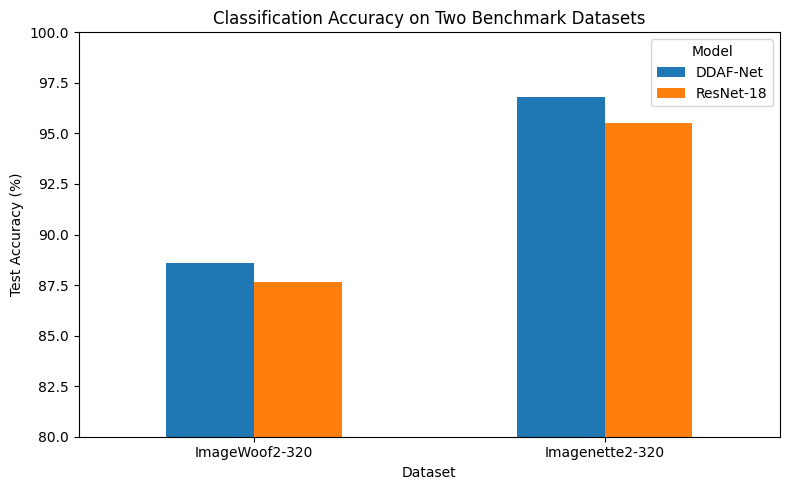

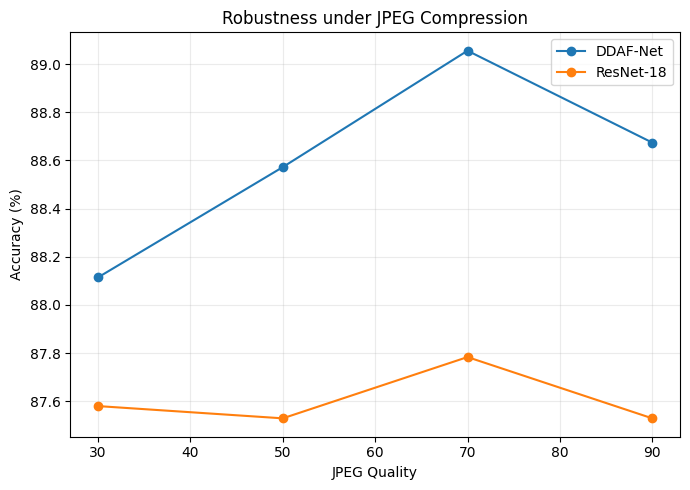

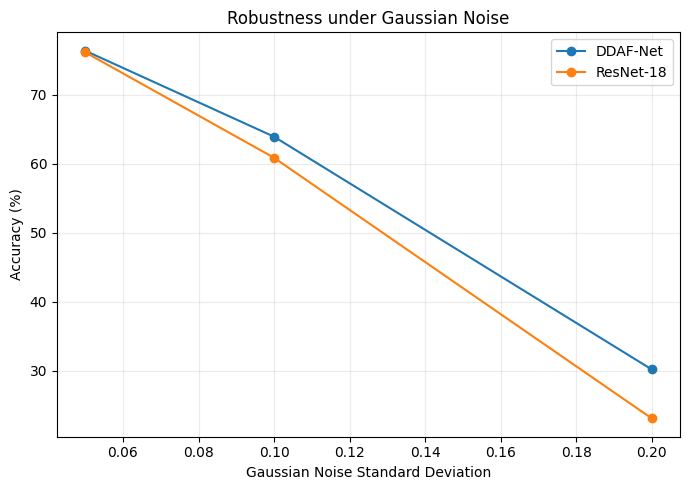

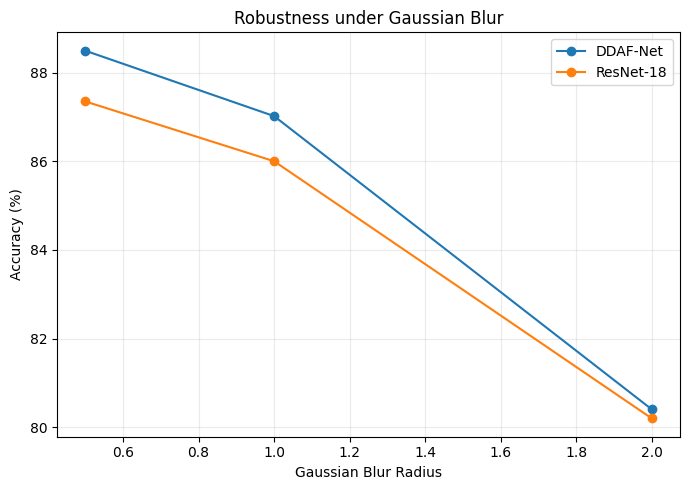

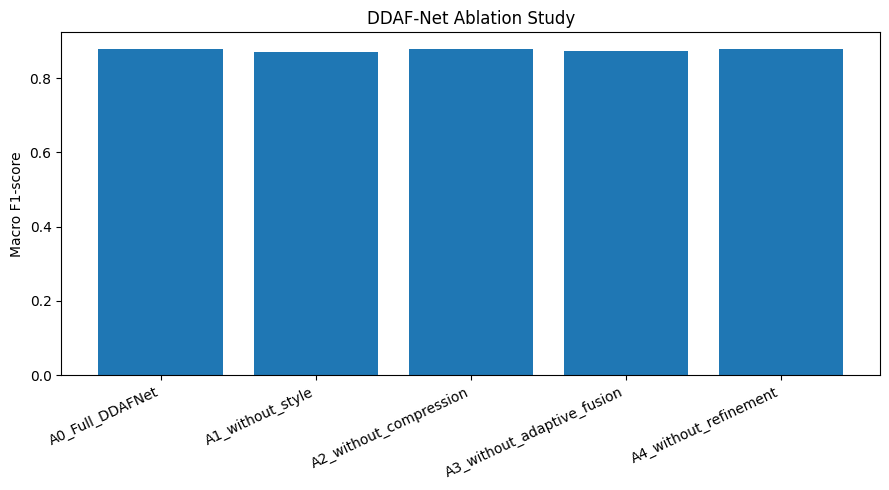

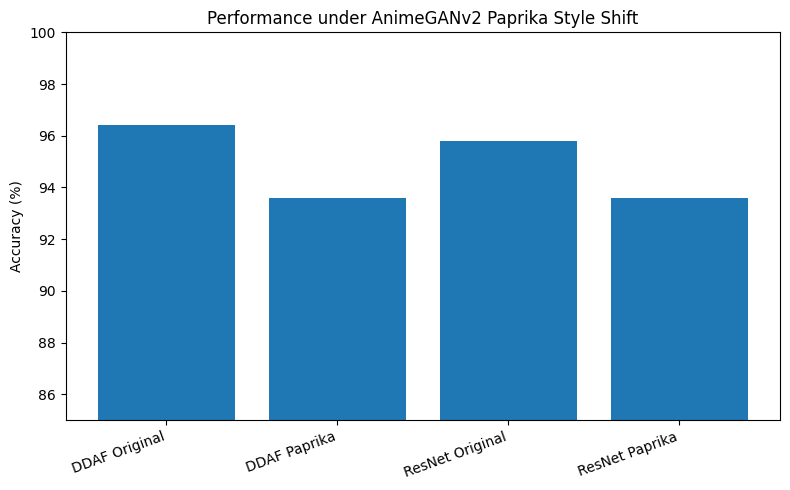


========== PUBLICATION FIGURES ==========
figure1_main_accuracy.png 111.4 KB
figure2_jpeg_robustness.png 148.4 KB
figure3_gaussian_robustness.png 158.2 KB
figure4_blur_robustness.png 153.8 KB
figure5_ablation.png 167.3 KB
figure6_paprika_style_shift.png 126.2 KB

All figures saved to: /kaggle/working/final_research_package/figures


In [109]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

BASE = Path("/kaggle/working")
OUT = BASE / "final_research_package" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

# Load final validated data
master = pd.read_csv(
    BASE / "final_research_package/tables/09_master_performance.csv"
)

robust = pd.read_csv(
    BASE / "imagewoof_experiments/robustness_results.csv"
)

gaussian = pd.read_csv(
    BASE / "imagewoof_experiments/corrected_gaussian_noise_results.csv"
)

ablation_path = BASE / "imagewoof_experiments/ablation/ablation_results.csv"
if not ablation_path.exists():
    ablation_path = BASE / "imagewoof_experiments/ablation_results.csv"

ablation = pd.read_csv(ablation_path)

paprika = pd.read_csv(
    BASE / "paprika_experiment/paprika_evaluation_results.csv"
)

complexity = pd.read_csv(
    BASE / "imagewoof_experiments/model_complexity_comparison.csv"
)

# ------------------------------------------------
# FIGURE 1: Main dataset accuracy comparison
# ------------------------------------------------
main = master[
    master["Dataset"].isin(["Imagenette2-320", "ImageWoof2-320"])
]

pivot = main.pivot(
    index="Dataset", columns="Model", values="Accuracy_pct"
)

ax = pivot[["DDAF-Net", "ResNet-18"]].plot(
    kind="bar", figsize=(8, 5), rot=0
)
ax.set_ylabel("Test Accuracy (%)")
ax.set_xlabel("Dataset")
ax.set_title("Classification Accuracy on Two Benchmark Datasets")
ax.set_ylim(80, 100)
ax.legend(title="Model")
plt.tight_layout()
plt.savefig(OUT / "figure1_main_accuracy.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# FIGURE 2: JPEG robustness
# ------------------------------------------------
jpeg = robust[robust["Corruption"] == "jpeg"]

plt.figure(figsize=(7, 5))
for model in ["DDAF-Net", "ResNet-18"]:
    subset = jpeg[jpeg["Model"] == model].sort_values(
        "Severity", ascending=False
    )
    plt.plot(
        subset["Severity"],
        subset["Accuracy (%)"],
        marker="o",
        label=model
    )

plt.xlabel("JPEG Quality")
plt.ylabel("Accuracy (%)")
plt.title("Robustness under JPEG Compression")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "figure2_jpeg_robustness.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# FIGURE 3: Gaussian noise robustness
# ------------------------------------------------
plt.figure(figsize=(7, 5))
plt.plot(
    gaussian["Noise_Severity"],
    gaussian["DDAF_Accuracy"],
    marker="o",
    label="DDAF-Net"
)
plt.plot(
    gaussian["Noise_Severity"],
    gaussian["ResNet_Accuracy"],
    marker="o",
    label="ResNet-18"
)

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Accuracy (%)")
plt.title("Robustness under Gaussian Noise")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "figure3_gaussian_robustness.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# FIGURE 4: Blur robustness
# ------------------------------------------------
blur = robust[robust["Corruption"] == "blur"]

plt.figure(figsize=(7, 5))
for model in ["DDAF-Net", "ResNet-18"]:
    subset = blur[blur["Model"] == model].sort_values("Severity")
    plt.plot(
        subset["Severity"],
        subset["Accuracy (%)"],
        marker="o",
        label=model
    )

plt.xlabel("Gaussian Blur Radius")
plt.ylabel("Accuracy (%)")
plt.title("Robustness under Gaussian Blur")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "figure4_blur_robustness.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# FIGURE 5: Ablation study
# ------------------------------------------------
plt.figure(figsize=(9, 5))
plt.bar(
    ablation["Model"],
    ablation["Macro_F1"]
)
plt.ylabel("Macro F1-score")
plt.title("DDAF-Net Ablation Study")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUT / "figure5_ablation.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# FIGURE 6: Paprika style-shift comparison
# ------------------------------------------------
plt.figure(figsize=(8, 5))

labels = [
    "DDAF Original", "DDAF Paprika",
    "ResNet Original", "ResNet Paprika"
]

plt.bar(
    labels,
    paprika["Accuracy"]
)

plt.ylabel("Accuracy (%)")
plt.title("Performance under AnimeGANv2 Paprika Style Shift")
plt.xticks(rotation=20, ha="right")
plt.ylim(85, 100)
plt.tight_layout()
plt.savefig(OUT / "figure6_paprika_style_shift.png", dpi=300)
plt.show()
plt.close()

# ------------------------------------------------
# Verify saved figures
# ------------------------------------------------
print("\n========== PUBLICATION FIGURES ==========")
for file in sorted(OUT.glob("*.png")):
    print(file.name, f"{file.stat().st_size / 1024:.1f} KB")

print("\nAll figures saved to:", OUT)


In [110]:

from pathlib import Path
import zipfile
import os

BASE = Path("/kaggle/working")

# -----------------------------------------
# 1. Results and publication package
# -----------------------------------------
results_zip = BASE / "DDAF_Final_Research_Results.zip"

folders_to_include = [
    BASE / "final_research_package",
    BASE / "paprika_experiment"
]

extra_files = [
    BASE / "ddaf_training/evaluation_summary.csv",
    BASE / "ddaf_training/classification_report.csv",
    BASE / "resnet18_pretrained_baseline/resnet18_pretrained_test_results.csv",
    BASE / "imagewoof_experiments/imagewoof_test_comparison.csv",
    BASE / "imagewoof_experiments/ablation",
    BASE / "imagewoof_experiments/robustness_results.csv",
    BASE / "imagewoof_experiments/corrected_gaussian_noise_results.csv",
    BASE / "imagewoof_experiments/model_complexity_comparison.csv",
    BASE / "imagewoof_experiments/inference_benchmark.csv",
    BASE / "imagewoof_experiments/imagewoof_mcnemar_results.csv"
]

with zipfile.ZipFile(
    results_zip, "w", compression=zipfile.ZIP_DEFLATED
) as z:

    for folder in folders_to_include:
        if folder.exists():
            for file in folder.rglob("*"):
                if file.is_file():
                    z.write(file, file.relative_to(BASE))

    for file in extra_files:
        if file.is_file():
            z.write(file, file.relative_to(BASE))
        elif file.is_dir():
            for item in file.rglob("*"):
                if item.is_file():
                    z.write(item, item.relative_to(BASE))

# -----------------------------------------
# 2. Best model checkpoint package
# -----------------------------------------
checkpoint_names = [
    "ddaf_best.pth",
    "resnet18_pretrained_best.pth",
    "ddaf_woof_best.pth",
    "resnet_woof_best.pth"
]

checkpoint_files = []

for name in checkpoint_names:
    matches = list(BASE.rglob(name))
    if matches:
        # Prefer the expected main experiment checkpoint locations
        checkpoint_files.append(matches[0])
    else:
        print("WARNING: Missing checkpoint:", name)

checkpoint_zip = BASE / "DDAF_Final_Model_Checkpoints.zip"

with zipfile.ZipFile(
    checkpoint_zip, "w", compression=zipfile.ZIP_STORED
) as z:

    for file in checkpoint_files:
        z.write(file, file.name)

# -----------------------------------------
# 3. Verify archives
# -----------------------------------------
for archive in [results_zip, checkpoint_zip]:
    with zipfile.ZipFile(archive, "r") as z:
        bad_file = z.testzip()

    print("\nArchive:", archive.name)
    print("Size (MB):", round(archive.stat().st_size / (1024**2), 2))
    print("Integrity:", "PASSED" if bad_file is None else bad_file)

print("\nCheckpoint files included:")
for file in checkpoint_files:
    print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")

print("\nFINAL BACKUP CREATION COMPLETED")



Archive: DDAF_Final_Research_Results.zip
Size (MB): 271.0
Integrity: PASSED

Archive: DDAF_Final_Model_Checkpoints.zip
Size (MB): 839.91
Integrity: PASSED

Checkpoint files included:
ddaf_best.pth 291.86 MB
resnet18_pretrained_best.pth 128.09 MB
ddaf_woof_best.pth 291.86 MB
resnet_woof_best.pth 128.09 MB

FINAL BACKUP CREATION COMPLETED


In [111]:

# Check whether the important research objects
# are still available in the current notebook session.

required_objects = [
    "full_model",
    "resnet18_pretrained",
    "train_loader",
    "val_loader",
    "test_loader",
    "train_loader_woof",
    "val_loader_woof",
    "test_loader_woof",
    "DEVICE",
    "criterion"
]

print("========== RESEARCH ENVIRONMENT CHECK ==========")

for name in required_objects:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE ({type(obj).__name__})")
    else:
        print(f"{name}: NOT AVAILABLE")

print("\n========== CHECKPOINTS ==========")

import os

checkpoint_paths = [
    "/kaggle/working/ddaf_training/ddaf_best.pth",
    "/kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth",
    "/kaggle/working/imagewoof_experiments/ddaf_net/ddaf_woof_best.pth",
    "/kaggle/working/imagewoof_experiments/resnet18/resnet_woof_best.pth"
]

for path in checkpoint_paths:
    print(
        os.path.basename(path),
        "AVAILABLE" if os.path.exists(path) else "NOT FOUND"
    )


========== RESEARCH ENVIRONMENT CHECK ==========
full_model: AVAILABLE (FullDDAFNet)
resnet18_pretrained: AVAILABLE (ResNet)
train_loader: AVAILABLE (DataLoader)
val_loader: AVAILABLE (DataLoader)
test_loader: AVAILABLE (DataLoader)
train_loader_woof: AVAILABLE (DataLoader)
val_loader_woof: AVAILABLE (DataLoader)
test_loader_woof: AVAILABLE (DataLoader)
DEVICE: AVAILABLE (device)
criterion: AVAILABLE (CrossEntropyLoss)

========== CHECKPOINTS ==========
ddaf_best.pth AVAILABLE
resnet18_pretrained_best.pth AVAILABLE
ddaf_woof_best.pth AVAILABLE
resnet_woof_best.pth AVAILABLE


In [112]:

import inspect

print("========== TRAINING / EVALUATION FUNCTIONS ==========")

for name, obj in globals().copy().items():
    if inspect.isfunction(obj):
        if any(word in name.lower() for word in
               ["train", "evaluate", "eval", "validate", "test"]):
            print(f"\nFunction: {name}")
            try:
                print("Signature:", inspect.signature(obj))
            except Exception:
                print("Signature unavailable")

print("\n========== MODEL DETAILS ==========")

print("DDAF model:", type(full_model).__name__)
print("ResNet model:", type(resnet18_pretrained).__name__)

print("\n========== DEVICE ==========")
print(DEVICE)

print("\n========== RANDOM SEED UTILITIES ==========")

import random
import numpy as np
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


========== TRAINING / EVALUATION FUNCTIONS ==========

Function: binomtest
Signature: (k, n, p=0.5, alternative='two-sided')

Function: train_test_split
Signature: (*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)

Function: evaluate_corruption
Signature: (model, loader)

Function: evaluate_noise
Signature: (model, loader)

Function: evaluate_model
Signature: (model, loader, model_name, condition)

Function: evaluate_validation
Signature: (model, loader)

Function: train_variant
Signature: (name, config)

Function: evaluate_test
Signature: (model, loader)

========== MODEL DETAILS ==========
DDAF model: FullDDAFNet
ResNet model: ResNet

========== DEVICE ==========
cuda

========== RANDOM SEED UTILITIES ==========
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [113]:

# ============================================================
# NEW RESEARCH: RELIABILITY-GUIDED FEATURE LEARNING
# Separate experimental workspace
# ============================================================

import os
import random
import numpy as np
import torch

RG_PROJECT_DIR = "/kaggle/working/reliability_guided_research"

RG_CHECKPOINT_DIR = os.path.join(
    RG_PROJECT_DIR, "checkpoints"
)

RG_RESULTS_DIR = os.path.join(
    RG_PROJECT_DIR, "results"
)

RG_FIGURES_DIR = os.path.join(
    RG_PROJECT_DIR, "figures"
)

for folder in [
    RG_PROJECT_DIR,
    RG_CHECKPOINT_DIR,
    RG_RESULTS_DIR,
    RG_FIGURES_DIR
]:
    os.makedirs(folder, exist_ok=True)

# Use the existing GPU device
RG_DEVICE = DEVICE

def rg_set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

rg_set_seed(42)

print("NEW RESEARCH WORKSPACE READY")
print("Device:", RG_DEVICE)
print("Project:", RG_PROJECT_DIR)

print("\nExisting models preserved:")
print("DDAF-Net:", type(full_model).__name__)
print("ResNet-18:", type(resnet18_pretrained).__name__)

print("\nExisting datasets available:")
print("Imagenette:", len(train_loader.dataset))
print("ImageWoof:", len(train_loader_woof.dataset))

print("\nNew checkpoint directory:", RG_CHECKPOINT_DIR)
print("\nNo original checkpoints were modified.")


NEW RESEARCH WORKSPACE READY
Device: cuda
Project: /kaggle/working/reliability_guided_research

Existing models preserved:
DDAF-Net: FullDDAFNet
ResNet-18: ResNet

Existing datasets available:
Imagenette: 8048
ImageWoof: 8122

New checkpoint directory: /kaggle/working/reliability_guided_research/checkpoints

No original checkpoints were modified.


In [114]:

# ============================================================
# CELL 2: DATASET VERIFICATION + RESEARCH METADATA BACKUP
# ============================================================

import os
import json
import torch

RG_loaders = {
    "Imagenette Train": train_loader,
    "Imagenette Validation": val_loader,
    "Imagenette Test": test_loader,
    "ImageWoof Train": train_loader_woof,
    "ImageWoof Validation": val_loader_woof,
    "ImageWoof Test": test_loader_woof
}

print("=" * 60)
print("DATASET VERIFICATION")
print("=" * 60)

for name, loader in RG_loaders.items():
    print(f"{name}: {len(loader.dataset)} images")

# Inspect one batch from each training loader
print("\nBATCH VERIFICATION")

for name in ["Imagenette Train", "ImageWoof Train"]:
    images, labels = next(iter(RG_loaders[name]))
    print(
        name,
        "| Images:", tuple(images.shape),
        "| Labels:", tuple(labels.shape),
        "| Classes:", len(torch.unique(labels))
    )

# Save metadata
RG_metadata = {
    "project": "Reliability-Guided Classification Research",
    "device": str(RG_DEVICE),
    "pytorch": torch.__version__,
    "datasets": {
        name: len(loader.dataset)
        for name, loader in RG_loaders.items()
    },
    "original_models": [
        "DDAF-Net",
        "ResNet-18"
    ],
    "status": "Dataset verification completed"
}

metadata_path = os.path.join(
    RG_PROJECT_DIR, "research_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(RG_metadata, f, indent=4)

print("\nMetadata saved:", metadata_path)
print("\nCELL 2 COMPLETED")


DATASET VERIFICATION
Imagenette Train: 8048 images
Imagenette Validation: 1421 images
Imagenette Test: 3925 images
ImageWoof Train: 8122 images
ImageWoof Validation: 903 images
ImageWoof Test: 3929 images

BATCH VERIFICATION


RuntimeError: DataLoader worker (pid(s) 124, 125) exited unexpectedly

In [115]:

# ============================================================
# CELL 2A: SAFE DATASET BATCH VERIFICATION
# ============================================================

from torch.utils.data import DataLoader
import json
import os

RG_safe_loaders = {}

RG_datasets = {
    "Imagenette Train": train_loader.dataset,
    "ImageWoof Train": train_loader_woof.dataset
}

for name, dataset in RG_datasets.items():
    safe_loader = DataLoader(
        dataset,
        batch_size=4,
        shuffle=False,
        num_workers=0,
        pin_memory=False
    )

    RG_safe_loaders[name] = safe_loader

    images, labels = next(iter(safe_loader))

    print("\n", name)
    print("Image shape:", tuple(images.shape))
    print("Label shape:", tuple(labels.shape))
    print("Number of classes in batch:", len(torch.unique(labels)))
    print("Image dtype:", images.dtype)
    print("Image range:", images.min().item(), images.max().item())

# Save metadata
RG_metadata = {
    "project": "Reliability-Guided Classification Research",
    "device": str(RG_DEVICE),
    "imagenette_train": len(train_loader.dataset),
    "imagenette_validation": len(val_loader.dataset),
    "imagenette_test": len(test_loader.dataset),
    "imagewoof_train": len(train_loader_woof.dataset),
    "imagewoof_validation": len(val_loader_woof.dataset),
    "imagewoof_test": len(test_loader_woof.dataset),
    "batch_verification": "Passed"
}

metadata_path = os.path.join(
    RG_PROJECT_DIR, "research_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(RG_metadata, f, indent=4)

print("\nDATASET VERIFICATION COMPLETED")
print("Metadata:", metadata_path)



 Imagenette Train
Image shape: (4, 3, 160, 160)
Label shape: (4,)
Number of classes in batch: 4
Image dtype: torch.float32
Image range: -2.1179039478302 2.640000104904175

 ImageWoof Train
Image shape: (4, 3, 160, 160)
Label shape: (4,)
Number of classes in batch: 2
Image dtype: torch.float32
Image range: -2.1179039478302 2.640000104904175

DATASET VERIFICATION COMPLETED
Metadata: /kaggle/working/reliability_guided_research/research_metadata.json


In [116]:

# ============================================================
# CELL 3: NEW RELIABILITY-GUIDED ARCHITECTURE
# Spatial + Frequency + Competence-Guided Fusion
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import json
import os

# ------------------------------------------------------------
# 1. Architecture configuration
# ------------------------------------------------------------

RG_NUM_CLASSES = len(class_names) if "class_names" in globals() else 10

RG_CONFIG = {
    "architecture": "Reliability-Supervised Adaptive Feature Learning",
    "input_channels": 3,
    "num_classes": RG_NUM_CLASSES,
    "feature_dim": 256,
    "input_size": 160,
    "normalization": "ImageNet"
}

print("Architecture configuration:", RG_CONFIG)


# ------------------------------------------------------------
# 2. Convolutional feature extractor
# ------------------------------------------------------------

class RGConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, stride=2,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ------------------------------------------------------------
# 3. Spatial feature pathway
# ------------------------------------------------------------

class RGSpatialBranch(nn.Module):
    def __init__(self, feature_dim=256):
        super().__init__()

        self.encoder = nn.Sequential(
            RGConvBlock(3, 32),
            RGConvBlock(32, 64),
            RGConvBlock(64, 128),
            RGConvBlock(128, feature_dim)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        feature_map = self.encoder(x)
        features = self.pool(feature_map).flatten(1)
        return features


# ------------------------------------------------------------
# 4. Frequency feature pathway
# ------------------------------------------------------------

class RGFrequencyBranch(nn.Module):
    def __init__(self, feature_dim=256):
        super().__init__()

        self.encoder = nn.Sequential(
            RGConvBlock(3, 32),
            RGConvBlock(32, 64),
            RGConvBlock(64, 128),
            RGConvBlock(128, feature_dim)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        # Convert normalized images back to RGB range.
        mean = x.new_tensor(
            [0.485, 0.456, 0.406]
        ).view(1, 3, 1, 1)

        std = x.new_tensor(
            [0.229, 0.224, 0.225]
        ).view(1, 3, 1, 1)

        rgb = (x * std + mean).clamp(0, 1)

        # Two-dimensional Fourier transform.
        spectrum = torch.fft.fft2(
            rgb, dim=(-2, -1), norm="ortho"
        )

        spectrum = torch.fft.fftshift(
            spectrum, dim=(-2, -1)
        )

        # Log magnitude spectrum.
        frequency_map = torch.log1p(
            torch.abs(spectrum)
        )

        # Normalize each channel for stable feature extraction.
        batch, channels, height, width = frequency_map.shape

        flat = frequency_map.reshape(batch, channels, -1)

        minimum = flat.amin(dim=-1, keepdim=True)
        maximum = flat.amax(dim=-1, keepdim=True)

        flat = (flat - minimum) / (
            maximum - minimum + 1e-6
        )

        frequency_map = flat.reshape(
            batch, channels, height, width
        )

        feature_map = self.encoder(frequency_map)
        features = self.pool(feature_map).flatten(1)

        return features


# ------------------------------------------------------------
# 5. Main reliability-guided model
# ------------------------------------------------------------

class ReliabilityGuidedNet(nn.Module):

    def __init__(self, num_classes=10, feature_dim=256):
        super().__init__()

        self.spatial_branch = RGSpatialBranch(feature_dim)
        self.frequency_branch = RGFrequencyBranch(feature_dim)

        # Independent branch classifiers.
        self.spatial_classifier = nn.Linear(
            feature_dim, num_classes
        )

        self.frequency_classifier = nn.Linear(
            feature_dim, num_classes
        )

        # Predict branch-level competence.
        self.spatial_reliability = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

        self.frequency_reliability = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

        # Final classifier.
        self.fusion_classifier = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        # Feature extraction.
        spatial_features = self.spatial_branch(x)
        frequency_features = self.frequency_branch(x)

        # Individual branch predictions.
        spatial_logits = self.spatial_classifier(
            spatial_features
        )

        frequency_logits = self.frequency_classifier(
            frequency_features
        )

        # Reliability scores.
        spatial_score = self.spatial_reliability(
            spatial_features
        )

        frequency_score = self.frequency_reliability(
            frequency_features
        )

        # Adaptive reliability weights.
        reliability_scores = torch.cat(
            [spatial_score, frequency_score], dim=1
        )

        reliability_weights = F.softmax(
            reliability_scores, dim=1
        )

        # Reliability-guided feature fusion.
        fused_features = (
            reliability_weights[:, 0:1] * spatial_features
            +
            reliability_weights[:, 1:2] * frequency_features
        )

        # Final prediction.
        final_logits = self.fusion_classifier(
            fused_features
        )

        return {
            "final_logits": final_logits,
            "spatial_logits": spatial_logits,
            "frequency_logits": frequency_logits,
            "spatial_score": spatial_score,
            "frequency_score": frequency_score,
            "reliability_weights": reliability_weights,
            "spatial_features": spatial_features,
            "frequency_features": frequency_features
        }


# ------------------------------------------------------------
# 6. Instantiate model
# ------------------------------------------------------------

RG_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)


# ------------------------------------------------------------
# 7. Model verification
# ------------------------------------------------------------

RG_sample_images, RG_sample_labels = next(
    iter(RG_safe_loaders["Imagenette Train"])
)

RG_sample_images = RG_sample_images.to(RG_DEVICE)

RG_model.eval()

with torch.no_grad():
    RG_output = RG_model(RG_sample_images)

print("\n========== MODEL VERIFICATION ==========")

for key, value in RG_output.items():
    print(key, tuple(value.shape))

RG_parameters = sum(
    p.numel() for p in RG_model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", f"{RG_parameters:,}")
print("Model size (FP32):", round(
    RG_parameters * 4 / (1024 ** 2), 2
), "MB")

# Save architecture configuration.
with open(
    os.path.join(RG_PROJECT_DIR, "architecture_config.json"),
    "w"
) as f:
    json.dump(RG_CONFIG, f, indent=4)

print("\nCELL 3 COMPLETED")


Architecture configuration: {'architecture': 'Reliability-Supervised Adaptive Feature Learning', 'input_channels': 3, 'num_classes': 3, 'feature_dim': 256, 'input_size': 160, 'normalization': 'ImageNet'}

========== MODEL VERIFICATION ==========
final_logits (4, 3)
spatial_logits (4, 3)
frequency_logits (4, 3)
spatial_score (4, 1)
frequency_score (4, 1)
reliability_weights (4, 2)
spatial_features (4, 256)
frequency_features (4, 256)

Trainable parameters: 2,480,587
Model size (FP32): 9.46 MB

CELL 3 COMPLETED


In [117]:

print("Imagenette classes:", len(class_names))
print("ImageWoof classes:", len(class_names_woof))

print("Imagenette mapping:", class_to_idx)
print("ImageWoof mapping:", {
    name: idx for idx, name in enumerate(class_names_woof)
})

print("Imagenette dataset classes:",
      len(train_loader.dataset.dataset.classes)
      if hasattr(train_loader.dataset, "dataset")
      and hasattr(train_loader.dataset.dataset, "classes")
      else "Inspecting mappings instead")


Imagenette classes: 3
ImageWoof classes: 10
Imagenette mapping: {'n01440764': 0, 'n02102040': 1, 'n02979186': 2, 'n03000684': 3, 'n03028079': 4, 'n03394916': 5, 'n03417042': 6, 'n03425413': 7, 'n03445777': 8, 'n03888257': 9}
ImageWoof mapping: {'n02086240': 0, 'n02087394': 1, 'n02088364': 2, 'n02089973': 3, 'n02093754': 4, 'n02096294': 5, 'n02099601': 6, 'n02105641': 7, 'n02111889': 8, 'n02115641': 9}
Imagenette dataset classes: Inspecting mappings instead


In [118]:

# ============================================================
# CELL 4: CORRECT CLASS COUNT AND REINITIALIZE MODEL
# ============================================================

# Use the verified original Imagenette mapping
RG_CLASS_TO_IDX = dict(class_to_idx)

RG_CLASS_NAMES = [
    name for name, idx in sorted(
        RG_CLASS_TO_IDX.items(),
        key=lambda item: item[1]
    )
]

RG_NUM_CLASSES = len(RG_CLASS_NAMES)

assert RG_NUM_CLASSES == 10, "Expected 10 Imagenette classes"

print("Imagenette class count:", RG_NUM_CLASSES)
print("Class names:", RG_CLASS_NAMES)

# Verify actual labels
RG_check_loader = DataLoader(
    train_loader.dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

RG_images, RG_labels = next(iter(RG_check_loader))

print("\nObserved labels:", torch.unique(RG_labels).tolist())
print("Minimum label:", RG_labels.min().item())
print("Maximum label:", RG_labels.max().item())

assert RG_labels.min().item() >= 0
assert RG_labels.max().item() < RG_NUM_CLASSES

# Reinitialize the model with 10 classes
RG_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

# Verify output
RG_model.eval()

with torch.no_grad():
    RG_output = RG_model(
        RG_images.to(RG_DEVICE)
    )

print("\nCorrected output shape:",
      RG_output["final_logits"].shape)

assert RG_output["final_logits"].shape[1] == 10

print("\nMODEL CORRECTED SUCCESSFULLY")


Imagenette class count: 10
Class names: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']

Observed labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Minimum label: 0
Maximum label: 9

Corrected output shape: torch.Size([32, 10])

MODEL CORRECTED SUCCESSFULLY


In [119]:

# ============================================================
# CELL 5: RELIABILITY-SUPERVISED TRAINING LOSS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

# Loss functions
RG_classification_loss = nn.CrossEntropyLoss()
RG_reliability_loss = nn.BCEWithLogitsLoss()

# Training weights (initial values; tune using validation)
RG_AUX_WEIGHT = 0.30
RG_RELIABILITY_WEIGHT = 0.20


def rg_compute_loss(outputs, labels):

    # 1. Final classification loss
    main_loss = RG_classification_loss(
        outputs["final_logits"], labels
    )

    # 2. Auxiliary branch classification losses
    spatial_loss = RG_classification_loss(
        outputs["spatial_logits"], labels
    )

    frequency_loss = RG_classification_loss(
        outputs["frequency_logits"], labels
    )

    auxiliary_loss = (
        spatial_loss + frequency_loss
    ) / 2

    # 3. Branch correctness targets
    # Targets are detached to avoid gradients flowing through argmax.
    spatial_correct = (
        outputs["spatial_logits"].detach().argmax(dim=1)
        == labels
    ).float().unsqueeze(1)

    frequency_correct = (
        outputs["frequency_logits"].detach().argmax(dim=1)
        == labels
    ).float().unsqueeze(1)

    # 4. Reliability supervision
    spatial_reliability_loss = RG_reliability_loss(
        outputs["spatial_score"],
        spatial_correct
    )

    frequency_reliability_loss = RG_reliability_loss(
        outputs["frequency_score"],
        frequency_correct
    )

    reliability_loss = (
        spatial_reliability_loss
        + frequency_reliability_loss
    ) / 2

    # 5. Total objective
    total_loss = (
        main_loss
        + RG_AUX_WEIGHT * auxiliary_loss
        + RG_RELIABILITY_WEIGHT * reliability_loss
    )

    loss_details = {
        "total": total_loss,
        "main": main_loss,
        "auxiliary": auxiliary_loss,
        "spatial": spatial_loss,
        "frequency": frequency_loss,
        "reliability": reliability_loss
    }

    return total_loss, loss_details


# ============================================================
# GRADIENT VERIFICATION — NO MODEL UPDATE
# ============================================================

RG_model.train()
RG_model.zero_grad(set_to_none=True)

RG_images, RG_labels = next(
    iter(RG_safe_loaders["Imagenette Train"])
)

RG_images = RG_images.to(RG_DEVICE)
RG_labels = RG_labels.to(RG_DEVICE)

RG_outputs = RG_model(RG_images)

RG_total_loss, RG_losses = rg_compute_loss(
    RG_outputs, RG_labels
)

RG_total_loss.backward()

print("=" * 55)
print("LOSS AND GRADIENT VERIFICATION")
print("=" * 55)

for name, loss in RG_losses.items():
    print(f"{name} loss: {loss.item():.5f}")

print("\nGRADIENT CHECK")

for name, module in [
    ("Spatial branch", RG_model.spatial_branch),
    ("Frequency branch", RG_model.frequency_branch),
    ("Spatial reliability", RG_model.spatial_reliability),
    ("Frequency reliability", RG_model.frequency_reliability),
    ("Fusion classifier", RG_model.fusion_classifier)
]:
    has_gradient = any(
        p.grad is not None and torch.isfinite(p.grad).all()
        and p.grad.abs().sum().item() > 0
        for p in module.parameters()
    )

    print(name, ":", "PASS" if has_gradient else "CHECK")

RG_model.zero_grad(set_to_none=True)

print("\nCELL 5 COMPLETED")


LOSS AND GRADIENT VERIFICATION
total loss: 3.12402
main loss: 2.28182
auxiliary loss: 2.34343
spatial loss: 2.42595
frequency loss: 2.26090
reliability loss: 0.69585

GRADIENT CHECK
Spatial branch : PASS
Frequency branch : PASS
Spatial reliability : PASS
Frequency reliability : PASS
Fusion classifier : PASS

CELL 5 COMPLETED


In [120]:

# ============================================================
# CELL 6: PILOT TRAINING + VALIDATION + CHECKPOINT SAVING
# ============================================================

import os
import time
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

# Reproducibility
rg_set_seed(42)

# Safe loaders: avoid the previous worker crash
RG_train_pilot = DataLoader(
    train_loader.dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

RG_val_pilot = DataLoader(
    val_loader.dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Optimizer
RG_optimizer = torch.optim.AdamW(
    RG_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Mixed precision
RG_use_amp = RG_DEVICE.type == "cuda"

RG_scaler = torch.amp.GradScaler(
    "cuda", enabled=RG_use_amp
)

RG_EPOCHS = 1
RG_best_accuracy = 0.0

RG_history = []

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

for epoch in range(RG_EPOCHS):

    RG_model.train()

    epoch_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(RG_train_pilot):

        images = images.to(RG_DEVICE, non_blocking=True)
        labels = labels.to(RG_DEVICE, non_blocking=True)

        RG_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=RG_DEVICE.type,
            dtype=torch.float16,
            enabled=RG_use_amp
        ):
            outputs = RG_model(images)
            loss, loss_details = rg_compute_loss(
                outputs, labels
            )

        RG_scaler.scale(loss).backward()

        RG_scaler.step(RG_optimizer)
        RG_scaler.update()

        epoch_loss += loss.item()

        predictions = outputs["final_logits"].argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 25 == 0:
            print(
                f"Epoch {epoch+1} | "
                f"Batch {batch_idx+1}/{len(RG_train_pilot)} | "
                f"Loss {loss.item():.4f}"
            )

    train_accuracy = 100 * correct / total
    average_loss = epoch_loss / len(RG_train_pilot)

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    RG_model.eval()

    val_correct = 0
    val_total = 0

    spatial_correct = 0
    frequency_correct = 0

    reliability_probabilities = []
    reliability_targets = []

    with torch.no_grad():

        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE, non_blocking=True)
            labels = labels.to(RG_DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=RG_DEVICE.type,
                dtype=torch.float16,
                enabled=RG_use_amp
            ):
                outputs = RG_model(images)

            final_pred = outputs["final_logits"].argmax(1)
            spatial_pred = outputs["spatial_logits"].argmax(1)
            frequency_pred = outputs["frequency_logits"].argmax(1)

            val_correct += (final_pred == labels).sum().item()
            spatial_correct += (spatial_pred == labels).sum().item()
            frequency_correct += (frequency_pred == labels).sum().item()

            val_total += labels.size(0)

            targets = torch.stack([
                (spatial_pred == labels).float(),
                (frequency_pred == labels).float()
            ], dim=1)

            probabilities = torch.sigmoid(
                torch.cat([
                    outputs["spatial_score"],
                    outputs["frequency_score"]
                ], dim=1).float()
            )

            reliability_probabilities.append(
                probabilities.cpu()
            )
            reliability_targets.append(targets.cpu())

    val_accuracy = 100 * val_correct / val_total
    spatial_accuracy = 100 * spatial_correct / val_total
    frequency_accuracy = 100 * frequency_correct / val_total

    probabilities = torch.cat(reliability_probabilities)
    targets = torch.cat(reliability_targets)

    reliability_brier = (
        (probabilities - targets) ** 2
    ).mean().item()

    elapsed = time.time() - start_time

    print("\n" + "=" * 55)
    print(f"EPOCH {epoch+1} RESULTS")
    print("=" * 55)
    print(f"Training loss: {average_loss:.4f}")
    print(f"Training accuracy: {train_accuracy:.2f}%")
    print(f"Validation accuracy: {val_accuracy:.2f}%")
    print(f"Spatial branch accuracy: {spatial_accuracy:.2f}%")
    print(f"Frequency branch accuracy: {frequency_accuracy:.2f}%")
    print(f"Reliability Brier score: {reliability_brier:.4f}")
    print(f"Time: {elapsed:.1f} seconds")

    RG_history.append({
        "epoch": epoch + 1,
        "train_loss": average_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "spatial_accuracy": spatial_accuracy,
        "frequency_accuracy": frequency_accuracy,
        "reliability_brier": reliability_brier
    })

    # Save checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": RG_model.state_dict(),
        "optimizer_state_dict": RG_optimizer.state_dict(),
        "scaler_state_dict": RG_scaler.state_dict(),
        "history": RG_history,
        "class_names": RG_CLASS_NAMES,
        "config": RG_CONFIG
    }

    last_path = os.path.join(
        RG_CHECKPOINT_DIR, "rg_pilot_last.pth"
    )

    torch.save(checkpoint, last_path)

    if val_accuracy > RG_best_accuracy:
        RG_best_accuracy = val_accuracy

        best_path = os.path.join(
            RG_CHECKPOINT_DIR, "rg_pilot_best.pth"
        )

        torch.save(checkpoint, best_path)

    print("\nCheckpoint saved:", last_path)

print("\nPILOT TRAINING COMPLETED")
print("Best validation accuracy:", RG_best_accuracy)


Epoch 1 | Batch 25/252 | Loss 2.8735
Epoch 1 | Batch 50/252 | Loss 2.8265
Epoch 1 | Batch 75/252 | Loss 2.8616
Epoch 1 | Batch 100/252 | Loss 2.8486
Epoch 1 | Batch 125/252 | Loss 2.4539
Epoch 1 | Batch 150/252 | Loss 2.5954
Epoch 1 | Batch 175/252 | Loss 2.5706
Epoch 1 | Batch 200/252 | Loss 2.4289
Epoch 1 | Batch 225/252 | Loss 1.9318
Epoch 1 | Batch 250/252 | Loss 2.2840

EPOCH 1 RESULTS
Training loss: 2.5635
Training accuracy: 38.63%
Validation accuracy: 47.29%
Spatial branch accuracy: 41.87%
Frequency branch accuracy: 37.44%
Reliability Brier score: 0.2280
Time: 42.8 seconds

Checkpoint saved: /kaggle/working/reliability_guided_research/checkpoints/rg_pilot_last.pth

PILOT TRAINING COMPLETED
Best validation accuracy: 47.29064039408867


In [121]:

# ============================================================
# CELL 7: CONTINUE PILOT TRAINING (EPOCHS 2-5)
# ============================================================

import time
import os
import torch

RG_model.train()

for epoch in range(2, 6):

    start_time = time.time()
    total_loss = 0.0
    correct = 0
    total = 0

    RG_model.train()

    for batch_idx, (images, labels) in enumerate(RG_train_pilot):

        images = images.to(RG_DEVICE, non_blocking=True)
        labels = labels.to(RG_DEVICE, non_blocking=True)

        RG_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=RG_DEVICE.type,
            dtype=torch.float16,
            enabled=RG_use_amp
        ):
            outputs = RG_model(images)
            loss, loss_details = rg_compute_loss(
                outputs, labels
            )

        RG_scaler.scale(loss).backward()
        RG_scaler.step(RG_optimizer)
        RG_scaler.update()

        total_loss += loss.item()

        predictions = outputs["final_logits"].argmax(1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    train_loss = total_loss / len(RG_train_pilot)

    # Validation
    RG_model.eval()

    val_correct = 0
    val_total = 0
    spatial_correct = 0
    frequency_correct = 0
    probabilities_list = []
    targets_list = []

    with torch.no_grad():
        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE, non_blocking=True)
            labels = labels.to(RG_DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=RG_DEVICE.type,
                dtype=torch.float16,
                enabled=RG_use_amp
            ):
                outputs = RG_model(images)

            final_pred = outputs["final_logits"].argmax(1)
            spatial_pred = outputs["spatial_logits"].argmax(1)
            frequency_pred = outputs["frequency_logits"].argmax(1)

            val_correct += (final_pred == labels).sum().item()
            spatial_correct += (spatial_pred == labels).sum().item()
            frequency_correct += (frequency_pred == labels).sum().item()
            val_total += labels.size(0)

            targets = torch.stack([
                (spatial_pred == labels).float(),
                (frequency_pred == labels).float()
            ], dim=1)

            probs = torch.sigmoid(torch.cat([
                outputs["spatial_score"],
                outputs["frequency_score"]
            ], dim=1).float())

            probabilities_list.append(probs.cpu())
            targets_list.append(targets.cpu())

    val_acc = 100 * val_correct / val_total
    spatial_acc = 100 * spatial_correct / val_total
    frequency_acc = 100 * frequency_correct / val_total

    probs = torch.cat(probabilities_list)
    targets = torch.cat(targets_list)
    brier = ((probs - targets) ** 2).mean().item()

    RG_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "spatial_accuracy": spatial_acc,
        "frequency_accuracy": frequency_acc,
        "reliability_brier": brier
    })

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": RG_model.state_dict(),
        "optimizer_state_dict": RG_optimizer.state_dict(),
        "scaler_state_dict": RG_scaler.state_dict(),
        "history": RG_history,
        "class_names": RG_CLASS_NAMES,
        "config": RG_CONFIG
    }

    # Always save the latest epoch
    torch.save(
        checkpoint,
        os.path.join(RG_CHECKPOINT_DIR, "rg_pilot_last.pth")
    )

    # Preserve the best validation model
    if val_acc > RG_best_accuracy:
        RG_best_accuracy = val_acc
        torch.save(
            checkpoint,
            os.path.join(RG_CHECKPOINT_DIR, "rg_pilot_best.pth")
        )

    print(f"\nEPOCH {epoch}/5")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_acc:.2f}%")
    print(f"Validation accuracy: {val_acc:.2f}%")
    print(f"Spatial accuracy: {spatial_acc:.2f}%")
    print(f"Frequency accuracy: {frequency_acc:.2f}%")
    print(f"Reliability Brier: {brier:.4f}")
    print(f"Time: {time.time()-start_time:.1f}s")
    print("Checkpoint saved.")

print("\nFIVE-EPOCH PILOT FINISHED")
print("Best validation accuracy:", RG_best_accuracy)



EPOCH 2/5
Train loss: 2.0323
Train accuracy: 54.39%
Validation accuracy: 54.19%
Spatial accuracy: 47.78%
Frequency accuracy: 47.15%
Reliability Brier: 0.2470
Time: 43.0s
Checkpoint saved.

EPOCH 3/5
Train loss: 1.7478
Train accuracy: 62.07%
Validation accuracy: 61.86%
Spatial accuracy: 56.02%
Frequency accuracy: 49.47%
Reliability Brier: 0.2440
Time: 42.9s
Checkpoint saved.

EPOCH 4/5
Train loss: 1.5629
Train accuracy: 66.46%
Validation accuracy: 65.94%
Spatial accuracy: 60.10%
Frequency accuracy: 50.53%
Reliability Brier: 0.2358
Time: 42.9s
Checkpoint saved.

EPOCH 5/5
Train loss: 1.4147
Train accuracy: 70.27%
Validation accuracy: 70.09%
Spatial accuracy: 62.42%
Frequency accuracy: 48.56%
Reliability Brier: 0.2385
Time: 42.9s
Checkpoint saved.

FIVE-EPOCH PILOT FINISHED
Best validation accuracy: 70.09148486980999


In [122]:

# ============================================================
# CELL 8: BACKUP PILOT CHECKPOINTS AND RESULTS
# ============================================================

import os
import json
import zipfile
import pandas as pd

RG_backup_dir = os.path.join(
    RG_PROJECT_DIR, "pilot_backup"
)
os.makedirs(RG_backup_dir, exist_ok=True)

# Save training history
RG_history_path = os.path.join(
    RG_backup_dir, "pilot_training_history.csv"
)

pd.DataFrame(RG_history).to_csv(
    RG_history_path, index=False
)

# Save configuration
with open(
    os.path.join(RG_backup_dir, "architecture_config.json"),
    "w"
) as f:
    json.dump(RG_CONFIG, f, indent=4)

# Copy checkpoint files into backup folder
checkpoint_files = [
    "rg_pilot_best.pth",
    "rg_pilot_last.pth"
]

for filename in checkpoint_files:
    source = os.path.join(RG_CHECKPOINT_DIR, filename)

    if os.path.exists(source):
        destination = os.path.join(RG_backup_dir, filename)

        with open(source, "rb") as src:
            with open(destination, "wb") as dst:
                dst.write(src.read())

        print("Backed up:", filename)
    else:
        print("WARNING: Missing:", filename)

# Create ZIP
RG_zip_path = os.path.join(
    PROJECT_DIR if "PROJECT_DIR" in globals() else "/kaggle/working",
    "Reliability_Guided_Pilot_Backup.zip"
)

with zipfile.ZipFile(
    RG_zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, files in os.walk(RG_backup_dir):
        for filename in files:
            full_path = os.path.join(root, filename)
            archive.write(
                full_path,
                arcname=os.path.relpath(full_path, RG_backup_dir)
            )

# Verify ZIP
with zipfile.ZipFile(RG_zip_path, "r") as archive:
    bad_file = archive.testzip()

print("\nBACKUP COMPLETED")
print("ZIP:", RG_zip_path)
print("Size (MB):", round(os.path.getsize(RG_zip_path) / 1e6, 2))
print("ZIP integrity:", "PASSED" if bad_file is None else bad_file)


Backed up: rg_pilot_best.pth
Backed up: rg_pilot_last.pth

BACKUP COMPLETED
ZIP: /kaggle/working/Reliability_Guided_Pilot_Backup.zip
Size (MB): 54.78
ZIP integrity: PASSED


In [123]:

# ============================================================
# CELL 9: BRANCH RELIABILITY VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

# 1. Load the best checkpoint
RG_best_path = os.path.join(
    RG_CHECKPOINT_DIR, "rg_pilot_best.pth"
)

RG_checkpoint = torch.load(
    RG_best_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_model.load_state_dict(
    RG_checkpoint["model_state_dict"]
)
RG_model.eval()

print("Loaded best checkpoint, epoch:",
      RG_checkpoint["epoch"])

# 2. Collect validation predictions
RG_spatial_probs = []
RG_frequency_probs = []
RG_spatial_correct = []
RG_frequency_correct = []
RG_fusion_weights = []

with torch.no_grad():

    for images, labels in RG_val_pilot:

        images = images.to(RG_DEVICE)
        labels = labels.to(RG_DEVICE)

        with torch.autocast(
            device_type=RG_DEVICE.type,
            dtype=torch.float16,
            enabled=RG_use_amp
        ):
            outputs = RG_model(images)

        sp_pred = outputs["spatial_logits"].argmax(1)
        fr_pred = outputs["frequency_logits"].argmax(1)

        sp_correct = (sp_pred == labels).float()
        fr_correct = (fr_pred == labels).float()

        sp_prob = torch.sigmoid(
            outputs["spatial_score"].float()
        ).squeeze(1)

        fr_prob = torch.sigmoid(
            outputs["frequency_score"].float()
        ).squeeze(1)

        RG_spatial_probs.extend(sp_prob.cpu().numpy())
        RG_frequency_probs.extend(fr_prob.cpu().numpy())

        RG_spatial_correct.extend(sp_correct.cpu().numpy())
        RG_frequency_correct.extend(fr_correct.cpu().numpy())

        RG_fusion_weights.extend(
            outputs["reliability_weights"].float().cpu().numpy()
        )

# Convert to arrays
sp_prob = np.asarray(RG_spatial_probs)
fr_prob = np.asarray(RG_frequency_probs)

sp_true = np.asarray(RG_spatial_correct)
fr_true = np.asarray(RG_frequency_correct)

weights = np.asarray(RG_fusion_weights)

# 3. Metric functions
def rg_brier(prob, target):
    return np.mean((prob - target) ** 2)

def rg_ece(prob, target, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for i in range(bins):
        mask = (
            (prob >= edges[i]) &
            (prob < edges[i + 1])
        )

        if mask.any():
            confidence = prob[mask].mean()
            accuracy = target[mask].mean()

            ece += mask.mean() * abs(
                confidence - accuracy
            )

    return ece

def rg_auc(prob, target):
    if len(np.unique(target)) < 2:
        return float("nan")
    return roc_auc_score(target, prob)

def rg_report(name, prob, target):
    prevalence = target.mean()

    baseline = np.full_like(
        prob, prevalence, dtype=float
    )

    print(f"\n{name}")
    print("Actual accuracy:", round(prevalence * 100, 2), "%")
    print("Brier score:", round(rg_brier(prob, target), 5))
    print("Constant baseline Brier:",
          round(rg_brier(baseline, target), 5))
    print("ECE:", round(rg_ece(prob, target), 5))
    print("AUROC:", round(rg_auc(prob, target), 5))

# 4. Evaluate branch reliability
print("\n========== RELIABILITY RESULTS ==========")

rg_report("SPATIAL BRANCH", sp_prob, sp_true)
rg_report("FREQUENCY BRANCH", fr_prob, fr_true)

# 5. Test whether fusion selects the correct branch
only_spatial = (sp_true == 1) & (fr_true == 0)
only_frequency = (sp_true == 0) & (fr_true == 1)

sole_correct = only_spatial | only_frequency

selected_branch = weights.argmax(axis=1)

if sole_correct.sum() > 0:
    selected_correct = (
        (only_spatial & (selected_branch == 0)) |
        (only_frequency & (selected_branch == 1))
    )

    alignment = selected_correct[sole_correct].mean()

    print("\n========== FUSION ALIGNMENT ==========")
    print("Samples where only one branch is correct:",
          int(sole_correct.sum()))
    print("Fusion selects the correct branch:",
          round(alignment * 100, 2), "%")
else:
    alignment = float("nan")
    print("\nNo samples with exactly one correct branch.")

# 6. Average fusion weights by correctness condition
both_correct = (sp_true == 1) & (fr_true == 1)
both_wrong = (sp_true == 0) & (fr_true == 0)

print("\n========== MEAN FUSION WEIGHTS ==========")

for name, mask in [
    ("Both correct", both_correct),
    ("Only spatial correct", only_spatial),
    ("Only frequency correct", only_frequency),
    ("Both wrong", both_wrong)
]:
    if mask.any():
        print(
            name,
            "| Spatial:", round(weights[mask, 0].mean(), 4),
            "| Frequency:", round(weights[mask, 1].mean(), 4)
        )

# 7. Save per-sample predictions and results
RG_analysis_df = pd.DataFrame({
    "spatial_probability": sp_prob,
    "frequency_probability": fr_prob,
    "spatial_correct": sp_true,
    "frequency_correct": fr_true,
    "spatial_fusion_weight": weights[:, 0],
    "frequency_fusion_weight": weights[:, 1]
})

RG_analysis_path = os.path.join(
    RG_RESULTS_DIR, "branch_reliability_validation.csv"
)

RG_analysis_df.to_csv(RG_analysis_path, index=False)

print("\nSaved:", RG_analysis_path)
print("\nRELIABILITY VALIDATION COMPLETED")


Loaded best checkpoint, epoch: 5

========== RELIABILITY RESULTS ==========

SPATIAL BRANCH
Actual accuracy: 62.42 %
Brier score: 0.22445
Constant baseline Brier: 0.23457
ECE: 0.06964
AUROC: 0.64706

FREQUENCY BRANCH
Actual accuracy: 48.56 %
Brier score: 0.25265
Constant baseline Brier: 0.24979
ECE: 0.08191
AUROC: 0.56189

========== FUSION ALIGNMENT ==========
Samples where only one branch is correct: 607
Fusion selects the correct branch: 62.27 %

========== MEAN FUSION WEIGHTS ==========
Both correct | Spatial: 0.6195 | Frequency: 0.3805
Only spatial correct | Spatial: 0.6266 | Frequency: 0.3734
Only frequency correct | Spatial: 0.5852 | Frequency: 0.4148
Both wrong | Spatial: 0.6008 | Frequency: 0.3992

Saved: /kaggle/working/reliability_guided_research/results/branch_reliability_validation.csv

RELIABILITY VALIDATION COMPLETED


In [124]:

# ============================================================
# CELL 10: COMPARE RELIABILITY FUSION STRATEGIES
# ============================================================

import numpy as np
import pandas as pd

sp = RG_analysis_df["spatial_probability"].values
fr = RG_analysis_df["frequency_probability"].values

sp_correct = RG_analysis_df["spatial_correct"].values.astype(bool)
fr_correct = RG_analysis_df["frequency_correct"].values.astype(bool)

# Existing fusion weights
old_weights = RG_analysis_df[
    ["spatial_fusion_weight", "frequency_fusion_weight"]
].values

# Alternative: normalize sigmoid reliability probabilities
denominator = sp + fr + 1e-8

new_sp_weight = sp / denominator
new_fr_weight = fr / denominator

new_weights = np.column_stack([
    new_sp_weight, new_fr_weight
])

# Samples where exactly one branch is correct
only_sp = sp_correct & ~fr_correct
only_fr = fr_correct & ~sp_correct
sole_correct = only_sp | only_fr

old_selected = old_weights.argmax(axis=1)
new_selected = new_weights.argmax(axis=1)

if sole_correct.sum() > 0:

    old_alignment = np.mean(
        (only_sp[sole_correct] & (old_selected[sole_correct] == 0)) |
        (only_fr[sole_correct] & (old_selected[sole_correct] == 1))
    )

    new_alignment = np.mean(
        (only_sp[sole_correct] & (new_selected[sole_correct] == 0)) |
        (only_fr[sole_correct] & (new_selected[sole_correct] == 1))
    )

    print("Samples with only one correct branch:", sole_correct.sum())
    print("Existing fusion alignment:", round(old_alignment * 100, 2), "%")
    print("Normalized sigmoid alignment:", round(new_alignment * 100, 2), "%")

print("\nAVERAGE FUSION WEIGHTS")

print("Existing spatial weight:", old_weights[:, 0].mean())
print("Existing frequency weight:", old_weights[:, 1].mean())

print("\nNormalized sigmoid spatial weight:", new_weights[:, 0].mean())
print("Normalized sigmoid frequency weight:", new_weights[:, 1].mean())

print("\nWEIGHT VARIATION")

print("Existing spatial SD:", old_weights[:, 0].std())
print("New spatial SD:", new_weights[:, 0].std())

print("\nCOMPARISON COMPLETED")


Samples with only one correct branch: 607
Existing fusion alignment: 62.27 %
Normalized sigmoid alignment: 62.27 %

AVERAGE FUSION WEIGHTS
Existing spatial weight: 0.61224985
Existing frequency weight: 0.38775015

Normalized sigmoid spatial weight: 0.5475953
Normalized sigmoid frequency weight: 0.45240468

WEIGHT VARIATION
Existing spatial SD: 0.12491791
New spatial SD: 0.051512964

COMPARISON COMPLETED


In [125]:

# ============================================================
# CELL 11: RELIABILITY SCORE SEPARATION
# ============================================================

import numpy as np
import pandas as pd

def reliability_separation(probabilities, correctness, branch_name):
    probabilities = np.asarray(probabilities)
    correctness = np.asarray(correctness).astype(bool)

    correct_scores = probabilities[correctness]
    incorrect_scores = probabilities[~correctness]

    print(f"\n{branch_name} BRANCH")
    print("-" * 40)
    print("Correct predictions:", len(correct_scores))
    print("Incorrect predictions:", len(incorrect_scores))

    print(
        "Mean reliability when correct:",
        round(float(correct_scores.mean()), 4)
    )

    print(
        "Mean reliability when incorrect:",
        round(float(incorrect_scores.mean()), 4)
    )

    print(
        "Separation:",
        round(float(correct_scores.mean() - incorrect_scores.mean()), 4)
    )

    print(
        "Correct score SD:",
        round(float(correct_scores.std()), 4)
    )

    print(
        "Incorrect score SD:",
        round(float(incorrect_scores.std()), 4)
    )


reliability_separation(
    RG_analysis_df["spatial_probability"],
    RG_analysis_df["spatial_correct"],
    "SPATIAL"
)

reliability_separation(
    RG_analysis_df["frequency_probability"],
    RG_analysis_df["frequency_correct"],
    "FREQUENCY"
)

print("\nRELIABILITY SEPARATION TEST COMPLETED")



SPATIAL BRANCH
----------------------------------------
Correct predictions: 887
Incorrect predictions: 534
Mean reliability when correct: 0.6851
Mean reliability when incorrect: 0.6466
Separation: 0.0385
Correct score SD: 0.0802
Incorrect score SD: 0.0615

FREQUENCY BRANCH
----------------------------------------
Correct predictions: 690
Incorrect predictions: 731
Mean reliability when correct: 0.5707
Mean reliability when incorrect: 0.546
Separation: 0.0247
Correct score SD: 0.1073
Incorrect score SD: 0.0904

RELIABILITY SEPARATION TEST COMPLETED


In [126]:

# ============================================================
# CELL 12: SAFETY CHECK BEFORE RANKING EXPERIMENT
# ============================================================

import os
import torch

RG_BEST_PATH = os.path.join(
    RG_CHECKPOINT_DIR, "rg_pilot_best.pth"
)

assert os.path.exists(RG_BEST_PATH), (
    "Original best checkpoint not found. Stop here."
)

# Load original checkpoint without modifying it
RG_original_checkpoint = torch.load(
    RG_BEST_PATH,
    map_location=RG_DEVICE,
    weights_only=False
)

print("Original checkpoint:", RG_BEST_PATH)
print("Checkpoint epoch:", RG_original_checkpoint.get("epoch", "Unknown"))
print("Checkpoint keys:", list(RG_original_checkpoint.keys()))

print("\nGPU STATUS")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated memory:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )
    print(
        "Reserved memory:",
        round(torch.cuda.memory_reserved(0) / 1024**3, 2),
        "GB"
    )
else:
    print("CUDA is not available.")

print("\nDATASET STATUS")
print("Training batches:", len(RG_train_pilot))
print("Validation batches:", len(RG_val_pilot))

print("\nOriginal pilot checkpoint remains untouched.")
print("SAFETY CHECK COMPLETED")


Original checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_pilot_best.pth
Checkpoint epoch: 5
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'history', 'class_names', 'config']

GPU STATUS
GPU: Tesla T4
Allocated memory: 2.25 GB
Reserved memory: 2.71 GB

DATASET STATUS
Training batches: 252
Validation batches: 45

Original pilot checkpoint remains untouched.
SAFETY CHECK COMPLETED


In [127]:

# ============================================================
# CELL 13: RANKING-BASED RELIABILITY OBJECTIVE
# Original checkpoint remains untouched
# ============================================================

import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

# Create a separate model from the original checkpoint
RG_rank_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES
).to(RG_DEVICE)

RG_rank_model.load_state_dict(
    RG_original_checkpoint["model_state_dict"]
)

# Fresh optimizer
RG_rank_optimizer = torch.optim.AdamW(
    RG_rank_model.parameters(),
    lr=5e-5,
    weight_decay=1e-4
)

RG_rank_ce = nn.CrossEntropyLoss()
RG_rank_bce = nn.BCEWithLogitsLoss()

RG_RANK_WEIGHT = 0.25
RG_RANK_MARGIN = 0.20

def rg_ranking_loss(outputs, labels):

    spatial_logits = outputs["spatial_logits"]
    frequency_logits = outputs["frequency_logits"]

    spatial_score = outputs["spatial_score"].view(-1)
    frequency_score = outputs["frequency_score"].view(-1)

    # Branch correctness targets
    with torch.no_grad():
        spatial_correct = (
            spatial_logits.argmax(dim=1) == labels
        )
        frequency_correct = (
            frequency_logits.argmax(dim=1) == labels
        )

    spatial_target = spatial_correct.float()
    frequency_target = frequency_correct.float()

    # Absolute reliability supervision
    spatial_bce = RG_rank_bce(
        spatial_score, spatial_target
    )

    frequency_bce = RG_rank_bce(
        frequency_score, frequency_target
    )

    bce_loss = (spatial_bce + frequency_bce) / 2

    # Pairwise ranking only when exactly one branch is correct
    only_spatial = spatial_correct & ~frequency_correct
    only_frequency = frequency_correct & ~spatial_correct

    pair_mask = only_spatial | only_frequency

    if pair_mask.any():

        # Positive difference means the correct branch
        # receives a higher reliability score.
        score_difference = torch.where(
            only_spatial,
            spatial_score - frequency_score,
            frequency_score - spatial_score
        )

        ranking = F.softplus(
            RG_RANK_MARGIN - score_difference[pair_mask]
        ).mean()

    else:
        ranking = spatial_score.new_tensor(0.0)

    return bce_loss, ranking, pair_mask.sum()


def rg_rank_total_loss(outputs, labels):

    main_loss = RG_rank_ce(
        outputs["final_logits"], labels
    )

    spatial_loss = RG_rank_ce(
        outputs["spatial_logits"], labels
    )

    frequency_loss = RG_rank_ce(
        outputs["frequency_logits"], labels
    )

    auxiliary_loss = (
        spatial_loss + frequency_loss
    ) / 2

    bce_loss, ranking_loss, pair_count = (
        rg_ranking_loss(outputs, labels)
    )

    total_loss = (
        main_loss
        + 0.30 * auxiliary_loss
        + 0.20 * (
            bce_loss + RG_RANK_WEIGHT * ranking_loss
        )
    )

    return total_loss, {
        "main": main_loss.detach(),
        "auxiliary": auxiliary_loss.detach(),
        "bce": bce_loss.detach(),
        "ranking": ranking_loss.detach(),
        "pairs": pair_count.detach()
    }


# Gradient sanity test
RG_rank_model.train()
RG_rank_optimizer.zero_grad(set_to_none=True)

RG_images, RG_labels = next(iter(RG_train_pilot))

RG_images = RG_images.to(RG_DEVICE)
RG_labels = RG_labels.to(RG_DEVICE)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=(RG_DEVICE.type == "cuda")
):
    RG_test_outputs = RG_rank_model(RG_images)
    RG_test_loss, RG_test_parts = rg_rank_total_loss(
        RG_test_outputs, RG_labels
    )

RG_test_loss.backward()

print("Total loss:", round(RG_test_loss.item(), 4))

for key, value in RG_test_parts.items():
    print(key, ":", round(value.item(), 4))

print(
    "Spatial branch gradient:",
    RG_rank_model.spatial_branch.blocks[0][0].weight.grad is not None
)

print(
    "Frequency branch gradient:",
    RG_rank_model.frequency_branch.blocks[0][0].weight.grad is not None
)

print("\nRANKING LOSS GRADIENT TEST COMPLETED")


Total loss: 1.4956
main : 0.9581
auxiliary : 1.2621
bce : 0.6136
ranking : 0.7225
pairs : 12


AttributeError: 'RGSpatialBranch' object has no attribute 'blocks'

In [128]:

# ============================================================
# CELL 13A: CORRECTED GRADIENT VERIFICATION
# ============================================================

RG_rank_optimizer.zero_grad(set_to_none=True)

RG_rank_model.train()

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=(RG_DEVICE.type == "cuda")
):
    RG_test_outputs = RG_rank_model(RG_images)
    RG_test_loss, RG_test_parts = rg_rank_total_loss(
        RG_test_outputs, RG_labels
    )

RG_test_loss.backward()

for branch_name, branch in [
    ("Spatial", RG_rank_model.spatial_branch),
    ("Frequency", RG_rank_model.frequency_branch)
]:
    gradients = [
        p.grad for p in branch.parameters()
        if p.requires_grad
    ]

    has_gradient = any(
        g is not None and torch.isfinite(g).all()
        and g.abs().sum().item() > 0
        for g in gradients
    )

    print(f"{branch_name} branch gradient:", has_gradient)

for name, module in [
    ("Spatial reliability", RG_rank_model.spatial_reliability),
    ("Frequency reliability", RG_rank_model.frequency_reliability),
    ("Fusion classifier", RG_rank_model.fusion_classifier)
]:
    has_gradient = any(
        p.grad is not None and
        torch.isfinite(p.grad).all() and
        p.grad.abs().sum().item() > 0
        for p in module.parameters()
    )

    print(f"{name} gradient:", has_gradient)

print("\nGradient verification completed.")


Spatial branch gradient: True
Frequency branch gradient: True
Spatial reliability gradient: True
Frequency reliability gradient: True
Fusion classifier gradient: True

Gradient verification completed.


In [129]:

# ============================================================
# CELL 14: TRAIN RANKING-BASED MODEL
# Separate experiment - original checkpoint untouched
# ============================================================

import os
import time
import pandas as pd
import torch

RG_RANK_EPOCHS = 3
RG_rank_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(RG_DEVICE.type == "cuda")
)

RG_RANK_BEST_PATH = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_ranking_best.pth"
)

RG_RANK_LAST_PATH = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_ranking_last.pth"
)

RG_rank_history = []
RG_rank_best_acc = 0.0

for epoch in range(1, RG_RANK_EPOCHS + 1):

    start_time = time.time()
    RG_rank_model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    total_pairs = 0

    for images, labels in RG_train_pilot:

        images = images.to(RG_DEVICE, non_blocking=True)
        labels = labels.to(RG_DEVICE, non_blocking=True)

        RG_rank_optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(RG_DEVICE.type == "cuda")
        ):
            outputs = RG_rank_model(images)
            loss, parts = rg_rank_total_loss(outputs, labels)

        RG_rank_scaler.scale(loss).backward()
        RG_rank_scaler.unscale_(RG_rank_optimizer)

        torch.nn.utils.clip_grad_norm_(
            RG_rank_model.parameters(), max_norm=1.0
        )

        RG_rank_scaler.step(RG_rank_optimizer)
        RG_rank_scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            outputs["final_logits"].argmax(1) == labels
        ).sum().item()

        total_samples += batch_size
        total_pairs += parts["pairs"].item()

    train_loss = total_loss / total_samples
    train_acc = 100 * total_correct / total_samples

    # Validation
    RG_rank_model.eval()

    val_correct = 0
    val_samples = 0
    spatial_correct = 0
    frequency_correct = 0

    with torch.no_grad():

        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE, non_blocking=True)
            labels = labels.to(RG_DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(RG_DEVICE.type == "cuda")
            ):
                outputs = RG_rank_model(images)

            val_correct += (
                outputs["final_logits"].argmax(1) == labels
            ).sum().item()

            spatial_correct += (
                outputs["spatial_logits"].argmax(1) == labels
            ).sum().item()

            frequency_correct += (
                outputs["frequency_logits"].argmax(1) == labels
            ).sum().item()

            val_samples += labels.size(0)

    val_acc = 100 * val_correct / val_samples
    spatial_acc = 100 * spatial_correct / val_samples
    frequency_acc = 100 * frequency_correct / val_samples

    elapsed = time.time() - start_time

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "spatial_accuracy": spatial_acc,
        "frequency_accuracy": frequency_acc,
        "ranking_pairs": total_pairs,
        "time_seconds": elapsed
    }

    RG_rank_history.append(record)

    print(f"\nRANKING EXPERIMENT EPOCH {epoch}/{RG_RANK_EPOCHS}")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_acc:.2f}%")
    print(f"Validation accuracy: {val_acc:.2f}%")
    print(f"Spatial accuracy: {spatial_acc:.2f}%")
    print(f"Frequency accuracy: {frequency_acc:.2f}%")
    print(f"Ranking pairs: {total_pairs}")
    print(f"Time: {elapsed:.1f} seconds")

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": RG_rank_model.state_dict(),
        "optimizer_state_dict": RG_rank_optimizer.state_dict(),
        "scaler_state_dict": RG_rank_scaler.state_dict(),
        "history": RG_rank_history,
        "class_names": RG_CLASS_NAMES,
        "config": {
            "learning_rate": 5e-5,
            "ranking_weight": RG_RANK_WEIGHT,
            "ranking_margin": RG_RANK_MARGIN,
            "epochs": RG_RANK_EPOCHS
        }
    }

    torch.save(checkpoint, RG_RANK_LAST_PATH)

    if val_acc > RG_rank_best_acc:
        RG_rank_best_acc = val_acc
        torch.save(checkpoint, RG_RANK_BEST_PATH)
        print("New best ranking checkpoint saved.")

# Save history
RG_rank_history_df = pd.DataFrame(RG_rank_history)

RG_rank_history_df.to_csv(
    os.path.join(
        RG_RESULTS_DIR,
        "ranking_training_history.csv"
    ),
    index=False
)

print("\nRANKING TRAINING COMPLETED")
print("Best validation accuracy:", round(RG_rank_best_acc, 2), "%")
print("Best checkpoint:", RG_RANK_BEST_PATH)
print("Original pilot checkpoint was not modified.")



RANKING EXPERIMENT EPOCH 1/3
Train loss: 1.2647
Train accuracy: 75.29%
Validation accuracy: 73.54%
Spatial accuracy: 68.40%
Frequency accuracy: 58.13%
Ranking pairs: 2560
Time: 43.4 seconds
New best ranking checkpoint saved.

RANKING EXPERIMENT EPOCH 2/3
Train loss: 1.1895
Train accuracy: 77.57%
Validation accuracy: 70.94%
Spatial accuracy: 66.36%
Frequency accuracy: 55.31%
Ranking pairs: 2555
Time: 43.3 seconds

RANKING EXPERIMENT EPOCH 3/3
Train loss: 1.1195
Train accuracy: 79.13%
Validation accuracy: 72.27%
Spatial accuracy: 70.23%
Frequency accuracy: 55.52%
Ranking pairs: 2535
Time: 43.1 seconds

RANKING TRAINING COMPLETED
Best validation accuracy: 73.54 %
Best checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_best.pth
Original pilot checkpoint was not modified.


In [130]:

# ============================================================
# CELL 15: RANKING MODEL RELIABILITY VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score

# Load best ranking checkpoint
RG_rank_best = torch.load(
    RG_RANK_BEST_PATH,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_rank_model.load_state_dict(
    RG_rank_best["model_state_dict"]
)
RG_rank_model.eval()

RG_records = []

with torch.no_grad():

    for images, labels in RG_val_pilot:

        images = images.to(RG_DEVICE)
        labels = labels.to(RG_DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(RG_DEVICE.type == "cuda")
        ):
            outputs = RG_rank_model(images)

        sp_correct = (
            outputs["spatial_logits"].argmax(1) == labels
        )
        fr_correct = (
            outputs["frequency_logits"].argmax(1) == labels
        )

        sp_prob = torch.sigmoid(
            outputs["spatial_score"].view(-1)
        )
        fr_prob = torch.sigmoid(
            outputs["frequency_score"].view(-1)
        )

        weights = outputs["reliability_weights"]

        for i in range(len(labels)):
            RG_records.append({
                "spatial_probability": sp_prob[i].item(),
                "frequency_probability": fr_prob[i].item(),
                "spatial_correct": int(sp_correct[i].item()),
                "frequency_correct": int(fr_correct[i].item()),
                "spatial_fusion_weight": weights[i, 0].item(),
                "frequency_fusion_weight": weights[i, 1].item()
            })

RG_rank_analysis_df = pd.DataFrame(RG_records)


# Metrics
def rg_ece(probabilities, targets, bins=10):
    ece = 0.0

    for i in range(bins):
        lower = i / bins
        upper = (i + 1) / bins

        mask = (
            (probabilities >= lower) &
            (probabilities < upper)
        )

        if mask.any():
            confidence = probabilities[mask].mean()
            accuracy = targets[mask].mean()

            ece += (
                mask.mean() *
                abs(confidence - accuracy)
            )

    return float(ece)


def rg_report_branch(df, branch):

    probabilities = df[f"{branch}_probability"].values
    targets = df[f"{branch}_correct"].values

    accuracy = targets.mean()
    brier = np.mean((probabilities - targets) ** 2)
    baseline = accuracy * (1 - accuracy)
    ece = rg_ece(probabilities, targets)

    auroc = (
        roc_auc_score(targets, probabilities)
        if len(np.unique(targets)) == 2 else float("nan")
    )

    print(f"\n{branch.upper()} BRANCH")
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Brier:", round(brier, 5))
    print("Baseline Brier:", round(baseline, 5))
    print("ECE:", round(ece, 5))
    print("AUROC:", round(auroc, 5))

    return {
        "accuracy": accuracy,
        "brier": brier,
        "baseline": baseline,
        "ece": ece,
        "auroc": auroc
    }


print("BEST CHECKPOINT EPOCH:", RG_rank_best["epoch"])
print("\n========== RANKING MODEL RELIABILITY ==========")

RG_rank_sp_metrics = rg_report_branch(
    RG_rank_analysis_df, "spatial"
)

RG_rank_fr_metrics = rg_report_branch(
    RG_rank_analysis_df, "frequency"
)


# Fusion alignment
sp_correct = RG_rank_analysis_df["spatial_correct"].values.astype(bool)
fr_correct = RG_rank_analysis_df["frequency_correct"].values.astype(bool)

only_sp = sp_correct & ~fr_correct
only_fr = fr_correct & ~sp_correct
sole_correct = only_sp | only_fr

fusion_weights = RG_rank_analysis_df[
    ["spatial_fusion_weight", "frequency_fusion_weight"]
].values

selected_branch = fusion_weights.argmax(axis=1)

if sole_correct.sum() > 0:

    alignment = np.mean(
        (only_sp[sole_correct] & (selected_branch[sole_correct] == 0)) |
        (only_fr[sole_correct] & (selected_branch[sole_correct] == 1))
    )

    print("\n========== FUSION ALIGNMENT ==========")
    print("Single-correct samples:", sole_correct.sum())
    print("Correct branch selected:", round(alignment * 100, 2), "%")

print("\n========== MEAN FUSION WEIGHTS ==========")

for condition, mask in [
    ("Both correct", sp_correct & fr_correct),
    ("Only spatial correct", only_sp),
    ("Only frequency correct", only_fr),
    ("Both wrong", ~sp_correct & ~fr_correct)
]:
    if mask.any():
        print(
            condition,
            "| Spatial:", round(fusion_weights[mask, 0].mean(), 4),
            "| Frequency:", round(fusion_weights[mask, 1].mean(), 4)
        )

# Save results
RG_rank_analysis_path = os.path.join(
    RG_RESULTS_DIR,
    "ranking_reliability_validation.csv"
)

RG_rank_analysis_df.to_csv(
    RG_rank_analysis_path,
    index=False
)

print("\nSaved:", RG_rank_analysis_path)
print("RANKING RELIABILITY VALIDATION COMPLETED")


BEST CHECKPOINT EPOCH: 1

========== RANKING MODEL RELIABILITY ==========

SPATIAL BRANCH
Accuracy: 68.4 %
Brier: 0.20771
Baseline Brier: 0.21613
ECE: 0.08786
AUROC: 0.64058

FREQUENCY BRANCH
Accuracy: 58.13 %
Brier: 0.23708
Baseline Brier: 0.24339
ECE: 0.03419
AUROC: 0.60013

========== FUSION ALIGNMENT ==========
Single-correct samples: 472
Correct branch selected: 70.13 %

========== MEAN FUSION WEIGHTS ==========
Both correct | Spatial: 0.6672 | Frequency: 0.3328
Only spatial correct | Spatial: 0.6824 | Frequency: 0.3176
Only frequency correct | Spatial: 0.583 | Frequency: 0.417
Both wrong | Spatial: 0.6515 | Frequency: 0.3485

Saved: /kaggle/working/reliability_guided_research/results/ranking_reliability_validation.csv
RANKING RELIABILITY VALIDATION COMPLETED


In [131]:

# ============================================================
# CELL 16: CLEAN vs GAUSSIAN NOISE vs GAUSSIAN BLUR
# No training; uses best ranking checkpoint
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score
from torchvision.transforms.functional import gaussian_blur

RG_rank_model.eval()

RG_corruption_results = []
RG_generator = torch.Generator(device=RG_DEVICE)
RG_generator.manual_seed(42)

conditions = ["clean", "gaussian_noise", "gaussian_blur"]

with torch.no_grad():

    for condition in conditions:

        final_correct = 0
        spatial_correct_total = 0
        frequency_correct_total = 0
        total = 0

        sp_scores = []
        fr_scores = []
        sp_targets = []
        fr_targets = []
        align_correct = 0
        align_total = 0

        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE)
            labels = labels.to(RG_DEVICE)

            if condition == "gaussian_noise":
                noise = torch.randn(
                    images.shape,
                    generator=RG_generator,
                    device=RG_DEVICE,
                    dtype=images.dtype
                )
                images = images + 0.15 * noise

            elif condition == "gaussian_blur":
                images = gaussian_blur(
                    images,
                    kernel_size=[5, 5],
                    sigma=[1.2, 1.2]
                )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(RG_DEVICE.type == "cuda")
            ):
                outputs = RG_rank_model(images)

            sp_ok = outputs["spatial_logits"].argmax(1) == labels
            fr_ok = outputs["frequency_logits"].argmax(1) == labels
            final_ok = outputs["final_logits"].argmax(1) == labels

            sp_prob = torch.sigmoid(
                outputs["spatial_score"].view(-1)
            )
            fr_prob = torch.sigmoid(
                outputs["frequency_score"].view(-1)
            )

            weights = outputs["reliability_weights"]
            selected = weights.argmax(1)

            sole = sp_ok ^ fr_ok

            align_correct += (
                ((sp_ok & (selected == 0)) |
                 (fr_ok & (selected == 1)))[sole]
            ).sum().item()

            align_total += sole.sum().item()

            final_correct += final_ok.sum().item()
            spatial_correct_total += sp_ok.sum().item()
            frequency_correct_total += fr_ok.sum().item()
            total += labels.size(0)

            sp_scores.extend(sp_prob.cpu().numpy())
            fr_scores.extend(fr_prob.cpu().numpy())
            sp_targets.extend(sp_ok.cpu().numpy())
            fr_targets.extend(fr_ok.cpu().numpy())

        sp_auc = roc_auc_score(sp_targets, sp_scores)
        fr_auc = roc_auc_score(fr_targets, fr_scores)

        result = {
            "condition": condition,
            "final_accuracy": 100 * final_correct / total,
            "spatial_accuracy": 100 * spatial_correct_total / total,
            "frequency_accuracy": 100 * frequency_correct_total / total,
            "spatial_auroc": sp_auc,
            "frequency_auroc": fr_auc,
            "fusion_alignment": (
                100 * align_correct / align_total
                if align_total else float("nan")
            )
        }

        RG_corruption_results.append(result)

        print("\n", condition.upper())
        for key, value in result.items():
            if key != "condition":
                print(f"{key}: {value:.4f}")

RG_corruption_df = pd.DataFrame(RG_corruption_results)

RG_corruption_path = os.path.join(
    RG_RESULTS_DIR,
    "ranking_corruption_validation.csv"
)

RG_corruption_df.to_csv(RG_corruption_path, index=False)

print("\nSaved:", RG_corruption_path)
print("CORRUPTION EVALUATION COMPLETED")



 CLEAN
final_accuracy: 73.5398
spatial_accuracy: 68.4025
frequency_accuracy: 58.1281
spatial_auroc: 0.6406
frequency_auroc: 0.6001
fusion_alignment: 70.1271

 GAUSSIAN_NOISE
final_accuracy: 63.3357
spatial_accuracy: 65.4469
frequency_accuracy: 22.6601
spatial_auroc: 0.6485
frequency_auroc: 0.7138
fusion_alignment: 77.4485

 GAUSSIAN_BLUR
final_accuracy: 47.6425
spatial_accuracy: 51.0908
frequency_accuracy: 23.9268
spatial_auroc: 0.6640
frequency_auroc: 0.6060
fusion_alignment: 79.4212

Saved: /kaggle/working/reliability_guided_research/results/ranking_corruption_validation.csv
CORRUPTION EVALUATION COMPLETED


In [132]:

# ============================================================
# CELL 17: ORIGINAL vs RANKING MODEL CORRUPTION COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import torch
from torchvision.transforms.functional import gaussian_blur
from sklearn.metrics import roc_auc_score

RG_original_state = RG_original_checkpoint["model_state_dict"]
RG_ranking_state = RG_rank_best["model_state_dict"]

def rg_evaluate_checkpoint(state_dict, model_name, condition):

    RG_rank_model.load_state_dict(state_dict)
    RG_rank_model.eval()

    generator = torch.Generator(device=RG_DEVICE)
    generator.manual_seed(42)

    final_correct = 0
    spatial_correct = 0
    frequency_correct = 0
    total = 0

    sp_scores, fr_scores = [], []
    sp_targets, fr_targets = [], []

    aligned = 0
    alignment_total = 0

    with torch.no_grad():

        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE)
            labels = labels.to(RG_DEVICE)

            if condition == "gaussian_noise":
                noise = torch.randn(
                    images.shape,
                    generator=generator,
                    device=RG_DEVICE,
                    dtype=images.dtype
                )
                images = images + 0.15 * noise

            elif condition == "gaussian_blur":
                images = gaussian_blur(
                    images,
                    kernel_size=[5, 5],
                    sigma=[1.2, 1.2]
                )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(RG_DEVICE.type == "cuda")
            ):
                out = RG_rank_model(images)

            sp_ok = out["spatial_logits"].argmax(1) == labels
            fr_ok = out["frequency_logits"].argmax(1) == labels
            final_ok = out["final_logits"].argmax(1) == labels

            sp_prob = torch.sigmoid(
                out["spatial_score"].view(-1)
            )
            fr_prob = torch.sigmoid(
                out["frequency_score"].view(-1)
            )

            weights = out["reliability_weights"]
            selected = weights.argmax(1)

            sole = sp_ok ^ fr_ok

            aligned += (
                ((sp_ok & (selected == 0)) |
                 (fr_ok & (selected == 1)))[sole]
            ).sum().item()

            alignment_total += sole.sum().item()

            final_correct += final_ok.sum().item()
            spatial_correct += sp_ok.sum().item()
            frequency_correct += fr_ok.sum().item()
            total += labels.size(0)

            sp_scores.extend(sp_prob.cpu().numpy())
            fr_scores.extend(fr_prob.cpu().numpy())
            sp_targets.extend(sp_ok.cpu().numpy())
            fr_targets.extend(fr_ok.cpu().numpy())

    return {
        "model": model_name,
        "condition": condition,
        "final_accuracy": 100 * final_correct / total,
        "spatial_accuracy": 100 * spatial_correct / total,
        "frequency_accuracy": 100 * frequency_correct / total,
        "spatial_auroc": roc_auc_score(sp_targets, sp_scores),
        "frequency_auroc": roc_auc_score(fr_targets, fr_scores),
        "fusion_alignment": (
            100 * aligned / alignment_total
            if alignment_total else np.nan
        )
    }


RG_comparison_records = []

for condition in ["clean", "gaussian_noise", "gaussian_blur"]:

    for model_name, state in [
        ("Original", RG_original_state),
        ("Ranking", RG_ranking_state)
    ]:

        result = rg_evaluate_checkpoint(
            state, model_name, condition
        )

        RG_comparison_records.append(result)

        print("\n", model_name, "|", condition.upper())

        for key, value in result.items():
            if key not in ["model", "condition"]:
                print(f"{key}: {value:.4f}")


# Restore ranking model
RG_rank_model.load_state_dict(RG_ranking_state)
RG_rank_model.eval()

RG_comparison_df = pd.DataFrame(RG_comparison_records)

RG_comparison_path = os.path.join(
    RG_RESULTS_DIR,
    "original_vs_ranking_corruption_comparison.csv"
)

RG_comparison_df.to_csv(
    RG_comparison_path,
    index=False
)

print("\nCOMPARISON TABLE")
print(RG_comparison_df.round(4).to_string(index=False))

print("\nSaved:", RG_comparison_path)
print("Ranking checkpoint restored.")
print("COMPARISON COMPLETED")



 Original | CLEAN
final_accuracy: 70.0915
spatial_accuracy: 62.4208
frequency_accuracy: 48.5574
spatial_auroc: 0.6471
frequency_auroc: 0.5619
fusion_alignment: 62.2735

 Ranking | CLEAN
final_accuracy: 73.5398
spatial_accuracy: 68.4025
frequency_accuracy: 58.1281
spatial_auroc: 0.6406
frequency_auroc: 0.6001
fusion_alignment: 70.1271

 Original | GAUSSIAN_NOISE
final_accuracy: 53.6946
spatial_accuracy: 60.6615
frequency_accuracy: 18.2266
spatial_auroc: 0.6623
frequency_auroc: 0.6824
fusion_alignment: 74.6497

 Ranking | GAUSSIAN_NOISE
final_accuracy: 63.3357
spatial_accuracy: 65.4469
frequency_accuracy: 22.6601
spatial_auroc: 0.6485
frequency_auroc: 0.7138
fusion_alignment: 77.4485

 Original | GAUSSIAN_BLUR
final_accuracy: 44.1239
spatial_accuracy: 50.8093
frequency_accuracy: 17.2414
spatial_auroc: 0.6201
frequency_auroc: 0.6565
fusion_alignment: 67.1033

 Ranking | GAUSSIAN_BLUR
final_accuracy: 47.6425
spatial_accuracy: 51.0908
frequency_accuracy: 23.9268
spatial_auroc: 0.6640
frequ

In [133]:

# ============================================================
# CELL 18: COMPLETE RESEARCH EXPERIMENT BACKUP
# ============================================================

import os
import zipfile
import json

RG_BACKUP_PATH = (
    "/kaggle/working/Reliability_Guided_Complete_Backup.zip"
)

RG_backup_files = [
    RG_BEST_PATH,
    RG_RANK_BEST_PATH,
    RG_RANK_LAST_PATH,
    os.path.join(RG_RESULTS_DIR, "branch_reliability_validation.csv"),
    os.path.join(RG_RESULTS_DIR, "ranking_training_history.csv"),
    os.path.join(RG_RESULTS_DIR, "ranking_reliability_validation.csv"),
    os.path.join(RG_RESULTS_DIR, "ranking_corruption_validation.csv"),
    os.path.join(RG_RESULTS_DIR, "original_vs_ranking_corruption_comparison.csv")
]

# Include architecture and experiment configuration
RG_backup_config = {
    "research_direction": "Reliability-Guided Adaptive Feature Learning",
    "dataset": "Imagenette",
    "num_classes": RG_NUM_CLASSES,
    "original_checkpoint": RG_BEST_PATH,
    "ranking_checkpoint": RG_RANK_BEST_PATH,
    "ranking_loss_weight": RG_RANK_WEIGHT,
    "ranking_margin": RG_RANK_MARGIN,
    "ranking_best_epoch": RG_rank_best["epoch"],
    "random_seed": 42,
    "evaluation_conditions": [
        "clean",
        "gaussian_noise",
        "gaussian_blur"
    ]
}

RG_config_path = os.path.join(
    RG_PROJECT_DIR, "complete_experiment_config.json"
)

with open(RG_config_path, "w") as f:
    json.dump(RG_backup_config, f, indent=4)

RG_backup_files.append(RG_config_path)

with zipfile.ZipFile(
    RG_BACKUP_PATH, "w", zipfile.ZIP_DEFLATED
) as archive:

    for file_path in RG_backup_files:
        if os.path.exists(file_path):
            archive.write(
                file_path,
                arcname=os.path.relpath(
                    file_path, RG_PROJECT_DIR
                )
            )
        else:
            print("Missing optional file:", file_path)

# Verify ZIP integrity
with zipfile.ZipFile(RG_BACKUP_PATH, "r") as archive:
    bad_file = archive.testzip()
    print("ZIP integrity:", "PASSED" if bad_file is None else bad_file)
    print("\nFiles included:")

    for name in archive.namelist():
        print(name)

print("\nBackup size:", round(os.path.getsize(RG_BACKUP_PATH) / 1024**2, 2), "MB")
print("Backup saved:", RG_BACKUP_PATH)


ZIP integrity: PASSED

Files included:
checkpoints/rg_pilot_best.pth
checkpoints/rg_ranking_best.pth
checkpoints/rg_ranking_last.pth
results/branch_reliability_validation.csv
results/ranking_training_history.csv
results/ranking_reliability_validation.csv
results/ranking_corruption_validation.csv
results/original_vs_ranking_corruption_comparison.csv
complete_experiment_config.json

Backup size: 78.35 MB
Backup saved: /kaggle/working/Reliability_Guided_Complete_Backup.zip


In [134]:

import torch
import inspect
import os

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("\n--- DATA LOADERS ---")

for name in [
    "RG_train_pilot", "RG_val_pilot",
    "train_loader", "val_loader", "test_loader",
    "train_loader_woof", "val_loader_woof", "test_loader_woof"
]:
    obj = globals().get(name)
    if obj is not None:
        print(
            name,
            "| batches:", len(obj),
            "| dataset size:", len(obj.dataset),
            "| batch size:", getattr(obj, "batch_size", None)
        )

print("\n--- MODEL AND TRAINING FUNCTIONS ---")

for name in [
    "ReliabilityGuidedNet",
    "rg_compute_loss",
    "rg_set_seed"
]:
    obj = globals().get(name)
    if obj is not None:
        print(name, "|", inspect.signature(obj) if callable(obj) else type(obj))

print("\n--- RANKING EXPERIMENT SETTINGS ---")

for name in sorted(globals()):
    if name.startswith("RG_RANK") or name.startswith("RG_rank"):
        value = globals()[name]
        if not callable(value):
            print(name, "=", value)

print("\n--- CHECKPOINTS ---")

for name in [
    "RG_BEST_PATH", "RG_RANK_BEST_PATH", "RG_RANK_LAST_PATH"
]:
    path = globals().get(name)
    if path:
        print(name, "|", path, "| exists:", os.path.exists(path))

print("\nDiagnostic completed. No training or checkpoint modifications.")


GPU: Tesla T4

--- DATA LOADERS ---
RG_train_pilot | batches: 252 | dataset size: 8048 | batch size: 32
RG_val_pilot | batches: 45 | dataset size: 1421 | batch size: 32
train_loader | batches: 1006 | dataset size: 8048 | batch size: 8
val_loader | batches: 178 | dataset size: 1421 | batch size: 8
test_loader | batches: 491 | dataset size: 3925 | batch size: 8
train_loader_woof | batches: 1016 | dataset size: 8122 | batch size: 8
val_loader_woof | batches: 113 | dataset size: 903 | batch size: 8
test_loader_woof | batches: 492 | dataset size: 3929 | batch size: 8

--- MODEL AND TRAINING FUNCTIONS ---
ReliabilityGuidedNet | (num_classes=10, feature_dim=256)
rg_compute_loss | (outputs, labels)
rg_set_seed | (seed=42)

--- RANKING EXPERIMENT SETTINGS ---
RG_RANK_BEST_PATH = /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_best.pth
RG_RANK_EPOCHS = 3
RG_RANK_LAST_PATH = /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_last.pth
RG_RANK_MARGIN = 0.2
RG_RANK

In [135]:

import torch
import inspect
import os

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("\n--- DATA LOADERS ---")

for name in [
    "RG_train_pilot", "RG_val_pilot",
    "train_loader", "val_loader", "test_loader",
    "train_loader_woof", "val_loader_woof", "test_loader_woof"
]:
    obj = globals().get(name)
    if obj is not None:
        print(
            name,
            "| batches:", len(obj),
            "| dataset size:", len(obj.dataset),
            "| batch size:", getattr(obj, "batch_size", None)
        )

print("\n--- MODEL AND TRAINING FUNCTIONS ---")

for name in [
    "ReliabilityGuidedNet",
    "rg_compute_loss",
    "rg_set_seed"
]:
    obj = globals().get(name)
    if obj is not None:
        print(name, "|", inspect.signature(obj) if callable(obj) else type(obj))

print("\n--- RANKING EXPERIMENT SETTINGS ---")

for name in sorted(globals()):
    if name.startswith("RG_RANK") or name.startswith("RG_rank"):
        value = globals()[name]
        if not callable(value):
            print(name, "=", value)

print("\n--- CHECKPOINTS ---")

for name in [
    "RG_BEST_PATH", "RG_RANK_BEST_PATH", "RG_RANK_LAST_PATH"
]:
    path = globals().get(name)
    if path:
        print(name, "|", path, "| exists:", os.path.exists(path))

print("\nDiagnostic completed. No training or checkpoint modifications.")


GPU: Tesla T4

--- DATA LOADERS ---
RG_train_pilot | batches: 252 | dataset size: 8048 | batch size: 32
RG_val_pilot | batches: 45 | dataset size: 1421 | batch size: 32
train_loader | batches: 1006 | dataset size: 8048 | batch size: 8
val_loader | batches: 178 | dataset size: 1421 | batch size: 8
test_loader | batches: 491 | dataset size: 3925 | batch size: 8
train_loader_woof | batches: 1016 | dataset size: 8122 | batch size: 8
val_loader_woof | batches: 113 | dataset size: 903 | batch size: 8
test_loader_woof | batches: 492 | dataset size: 3929 | batch size: 8

--- MODEL AND TRAINING FUNCTIONS ---
ReliabilityGuidedNet | (num_classes=10, feature_dim=256)
rg_compute_loss | (outputs, labels)
rg_set_seed | (seed=42)

--- RANKING EXPERIMENT SETTINGS ---
RG_RANK_BEST_PATH = /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_best.pth
RG_RANK_EPOCHS = 3
RG_RANK_LAST_PATH = /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_last.pth
RG_RANK_MARGIN = 0.2
RG_RANK

In [136]:
import os

print("=== EXPERIMENT RESULT FILES ===")

files = [
    "ranking_corruption_validation.csv",
    "original_vs_ranking_corruption_comparison.csv",
    "ranking_reliability_validation.csv",
    "ranking_training_history.csv"
]

for file in files:
    path = os.path.join(RG_RESULTS_DIR, file)
    print(file, "->", "AVAILABLE" if os.path.exists(path) else "MISSING")

=== EXPERIMENT RESULT FILES ===
ranking_corruption_validation.csv -> AVAILABLE
original_vs_ranking_corruption_comparison.csv -> AVAILABLE
ranking_reliability_validation.csv -> AVAILABLE
ranking_training_history.csv -> AVAILABLE


In [137]:
import pandas as pd
import os

RG_comparison_path = os.path.join(
    RG_RESULTS_DIR,
    "original_vs_ranking_corruption_comparison.csv"
)

RG_comparison_df = pd.read_csv(RG_comparison_path)

print("=== COMPARISON RESULTS ===")
print("Rows:", len(RG_comparison_df))
print("Columns:", list(RG_comparison_df.columns))

display(RG_comparison_df)

=== COMPARISON RESULTS ===
Rows: 6
Columns: ['model', 'condition', 'final_accuracy', 'spatial_accuracy', 'frequency_accuracy', 'spatial_auroc', 'frequency_auroc', 'fusion_alignment']


,model,condition,final_accuracy,spatial_accuracy,frequency_accuracy,spatial_auroc,frequency_auroc,fusion_alignment
0,Original,clean,70.091485,62.420830,48.557354,0.647085,0.561927,62.273476
1,Ranking,clean,73.539761,68.402533,58.128079,0.640583,0.600134,70.127119
2,Original,gaussian_noise,53.694581,60.661506,18.226601,0.662263,0.682424,74.649682
3,Ranking,gaussian_noise,63.335679,65.446868,22.660099,0.648493,0.713786,77.448454
4,Original,gaussian_blur,44.123856,50.809289,17.241379,0.620113,0.656537,67.103348
5,Ranking,gaussian_blur,47.642505,51.090781,23.926812,0.663975,0.605986,79.421222


In [138]:
import pandas as pd
import os

RG_detail_path = os.path.join(
    RG_RESULTS_DIR,
    "ranking_corruption_validation.csv"
)

RG_detail_df = pd.read_csv(RG_detail_path)

print("=== DETAILED CORRUPTION RESULTS ===")
print("Total records:", len(RG_detail_df))
print("\nColumns:")
print(RG_detail_df.columns.tolist())

print("\nFirst 10 records:")
display(RG_detail_df.head(10))

print("\nModel and condition counts:")
display(
    RG_detail_df.groupby(["model", "condition"]).size().reset_index(name="count")
)

=== DETAILED CORRUPTION RESULTS ===
Total records: 3

Columns:
['condition', 'final_accuracy', 'spatial_accuracy', 'frequency_accuracy', 'spatial_auroc', 'frequency_auroc', 'fusion_alignment']

First 10 records:


,condition,final_accuracy,spatial_accuracy,frequency_accuracy,spatial_auroc,frequency_auroc,fusion_alignment
0,clean,73.539761,68.402533,58.128079,0.640583,0.600134,70.127119
1,gaussian_noise,63.335679,65.446868,22.660099,0.648493,0.713786,77.448454
2,gaussian_blur,47.642505,51.090781,23.926812,0.663975,0.605986,79.421222



Model and condition counts:


KeyError: 'model'

In [139]:
import pandas as pd
import os

RG_path = os.path.join(
    RG_RESULTS_DIR,
    "original_vs_ranking_corruption_comparison.csv"
)

RG_df = pd.read_csv(RG_path)

print("=== COMPARISON CSV AUDIT ===")
print("Shape:", RG_df.shape)
print("Columns:", RG_df.columns.tolist())

print("\nRecords:")
display(RG_df)

print("\nData types:")
print(RG_df.dtypes)

=== COMPARISON CSV AUDIT ===
Shape: (6, 8)
Columns: ['model', 'condition', 'final_accuracy', 'spatial_accuracy', 'frequency_accuracy', 'spatial_auroc', 'frequency_auroc', 'fusion_alignment']

Records:


,model,condition,final_accuracy,spatial_accuracy,frequency_accuracy,spatial_auroc,frequency_auroc,fusion_alignment
0,Original,clean,70.091485,62.420830,48.557354,0.647085,0.561927,62.273476
1,Ranking,clean,73.539761,68.402533,58.128079,0.640583,0.600134,70.127119
2,Original,gaussian_noise,53.694581,60.661506,18.226601,0.662263,0.682424,74.649682
3,Ranking,gaussian_noise,63.335679,65.446868,22.660099,0.648493,0.713786,77.448454
4,Original,gaussian_blur,44.123856,50.809289,17.241379,0.620113,0.656537,67.103348
5,Ranking,gaussian_blur,47.642505,51.090781,23.926812,0.663975,0.605986,79.421222



Data types:
model                  object
condition              object
final_accuracy        float64
spatial_accuracy      float64
frequency_accuracy    float64
spatial_auroc         float64
frequency_auroc       float64
fusion_alignment      float64
dtype: object


In [140]:
import inspect

print("=== EVALUATION FUNCTION SOURCE ===")

print(inspect.getsource(rg_evaluate_checkpoint))

=== EVALUATION FUNCTION SOURCE ===
def rg_evaluate_checkpoint(state_dict, model_name, condition):

    RG_rank_model.load_state_dict(state_dict)
    RG_rank_model.eval()

    generator = torch.Generator(device=RG_DEVICE)
    generator.manual_seed(42)

    final_correct = 0
    spatial_correct = 0
    frequency_correct = 0
    total = 0

    sp_scores, fr_scores = [], []
    sp_targets, fr_targets = [], []

    aligned = 0
    alignment_total = 0

    with torch.no_grad():

        for images, labels in RG_val_pilot:

            images = images.to(RG_DEVICE)
            labels = labels.to(RG_DEVICE)

            if condition == "gaussian_noise":
                noise = torch.randn(
                    images.shape,
                    generator=generator,
                    device=RG_DEVICE,
                    dtype=images.dtype
                )
                images = images + 0.15 * noise

            elif condition == "gaussian_blur":
                images = gaussian_blur(
    

In [141]:
print("=== VALIDATION DATASET AUDIT ===")

print("Dataset size:", len(RG_val_pilot.dataset))
print("Sampler:", type(RG_val_pilot.sampler).__name__)
print("Shuffle enabled:",
      isinstance(RG_val_pilot.sampler, torch.utils.data.RandomSampler))

print("\nValidation transforms:")
print(RG_val_pilot.dataset.transform)

print("\nBatch size:", RG_val_pilot.batch_size)
print("Number of batches:", len(RG_val_pilot))

=== VALIDATION DATASET AUDIT ===
Dataset size: 1421
Sampler: SequentialSampler
Shuffle enabled: False

Validation transforms:
Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Batch size: 32
Number of batches: 45


In [142]:
RG_val_dataset = RG_val_pilot.dataset

print("Dataset type:", type(RG_val_dataset).__name__)
print("Dataset attributes:")

for attr in ["root", "samples", "imgs", "transform", "dataset"]:
    if hasattr(RG_val_dataset, attr):
        value = getattr(RG_val_dataset, attr)
        if attr in ["samples", "imgs"]:
            print(attr, "count:", len(value))
            print("First sample:", value[0])
        else:
            print(attr, value)

Dataset type: CartoonRobustnessDataset
Dataset attributes:
transform Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [143]:
import inspect

print("=== DATASET CLASS SOURCE ===")
print(inspect.getsource(CartoonRobustnessDataset))

print("\n=== FIRST VALIDATION SAMPLE ===")
RG_img, RG_label = RG_val_pilot.dataset[0]

print("Image shape:", RG_img.shape)
print("Image dtype:", RG_img.dtype)
print("Image range:", RG_img.min().item(), RG_img.max().item())
print("Label:", RG_label)

=== DATASET CLASS SOURCE ===


OSError: source code not available

In [144]:
print("=== VALIDATION SAMPLE CHECK ===")

RG_img, RG_label = RG_val_pilot.dataset[0]

print("Image shape:", RG_img.shape)
print("Image dtype:", RG_img.dtype)
print("Image range:", RG_img.min().item(), RG_img.max())
print("Label:", RG_label)

print("\nDataset attributes:")
print(RG_val_pilot.dataset.__dict__.keys())

=== VALIDATION SAMPLE CHECK ===
Image shape: torch.Size([3, 160, 160])
Image dtype: torch.float32
Image range: -2.0494048595428467 tensor(2.6400)
Label: 1

Dataset attributes:
dict_keys(['dataframe', 'transform', 'training'])


In [145]:
print("=== DATASET DATAFRAME ===")

print("Columns:", RG_val_pilot.dataset.dataframe.columns.tolist())

display(RG_val_pilot.dataset.dataframe.head())

print("\nNumber of validation records:",
      len(RG_val_pilot.dataset.dataframe))

=== DATASET DATAFRAME ===
Columns: ['image_id', 'split', 'label', 'image_path', 'extension', 'sha256', 'audit_status', 'partition', 'source_path', 'class_label', 'label_text', 'target', 'image_path_resolved']


,image_id,split,label,image_path,extension,sha256,audit_status,partition,source_path,class_label,label_text,target,image_path_resolved
0,validation/train/n02102040/n02102040_1595.JPEG,validation,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,737c3dd22fc6f0b466c1d037629a7f9bfd6fcd0bac9d0e...,valid,validation,/content/drive/MyDrive/CartoonizationResearchB...,n02102040,n02102040,1,/kaggle/working/imagenette2-320/train/n0210204...
1,validation/train/n03028079/n03028079_34727.JPEG,validation,n03028079,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,a62a48401e6de3a13d9e97a24a3c5fdfb8994a4e225f26...,valid,validation,/content/drive/MyDrive/CartoonizationResearchB...,n03028079,n03028079,4,/kaggle/working/imagenette2-320/train/n0302807...
2,validation/train/n03888257/n03888257_226.JPEG,validation,n03888257,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,d445f917970f27961295756ff975182f1bf324ad4d9662...,valid,validation,/content/drive/MyDrive/CartoonizationResearchB...,n03888257,n03888257,9,/kaggle/working/imagenette2-320/train/n0388825...
3,validation/train/n02979186/n02979186_1587.JPEG,validation,n02979186,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,b955484d27dbf0282cc8942f7e9266a3b8302bb7b57292...,valid,validation,/content/drive/MyDrive/CartoonizationResearchB...,n02979186,n02979186,2,/kaggle/working/imagenette2-320/train/n0297918...
4,validation/train/n02102040/n02102040_3974.JPEG,validation,n02102040,/content/drive/MyDrive/CartoonizationResearchB...,.jpeg,be131f81c0dca7e8d2fe0bba5bcd4427757fd9f848ac04...,valid,validation,/content/drive/MyDrive/CartoonizationResearchB...,n02102040,n02102040,1,/kaggle/working/imagenette2-320/train/n0210204...



Number of validation records: 1421


In [146]:
RG_df_audit = RG_val_pilot.dataset.dataframe

print("=== IMAGE PATH AUDIT ===")
print("Total images:", len(RG_df_audit))
print("Missing image paths:",
      RG_df_audit["image_path_resolved"].isna().sum())
print("Empty image paths:",
      (RG_df_audit["image_path_resolved"].fillna("").str.strip() == "").sum())
print("Unique image hashes:",
      RG_df_audit["sha256"].nunique())

print("\nImage path examples:")
display(RG_df_audit[
    ["image_id", "sha256", "image_path_resolved"]
].head(5))

=== IMAGE PATH AUDIT ===
Total images: 1421
Missing image paths: 0
Empty image paths: 0
Unique image hashes: 1421

Image path examples:


,image_id,sha256,image_path_resolved
0,validation/train/n02102040/n02102040_1595.JPEG,737c3dd22fc6f0b466c1d037629a7f9bfd6fcd0bac9d0e...,/kaggle/working/imagenette2-320/train/n0210204...
1,validation/train/n03028079/n03028079_34727.JPEG,a62a48401e6de3a13d9e97a24a3c5fdfb8994a4e225f26...,/kaggle/working/imagenette2-320/train/n0302807...
2,validation/train/n03888257/n03888257_226.JPEG,d445f917970f27961295756ff975182f1bf324ad4d9662...,/kaggle/working/imagenette2-320/train/n0388825...
3,validation/train/n02979186/n02979186_1587.JPEG,b955484d27dbf0282cc8942f7e9266a3b8302bb7b57292...,/kaggle/working/imagenette2-320/train/n0297918...
4,validation/train/n02102040/n02102040_3974.JPEG,be131f81c0dca7e8d2fe0bba5bcd4427757fd9f848ac04...,/kaggle/working/imagenette2-320/train/n0210204...


In [147]:
import torchvision.transforms.functional as TF
from PIL import Image
import io
import torch

print("Torchvision functional:", "READY")
print("PIL:", "READY")
print("Validation samples:", len(RG_val_pilot.dataset))
print("Original checkpoint:", RG_BEST_PATH)
print("Ranking checkpoint:", RG_RANK_BEST_PATH)

Torchvision functional: READY
PIL: READY
Validation samples: 1421
Original checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_pilot_best.pth
Ranking checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_ranking_best.pth


In [148]:

import os, io
import numpy as np
import pandas as pd
import torch
import torchvision.transforms.functional as TF
from PIL import Image
from sklearn.metrics import roc_auc_score

RG_MEAN = torch.tensor(
    [0.485, 0.456, 0.406], device=RG_DEVICE
).view(1, 3, 1, 1)

RG_STD = torch.tensor(
    [0.229, 0.224, 0.225], device=RG_DEVICE
).view(1, 3, 1, 1)

def RG_corrupt_batch(images, condition, generator):
    if condition == "clean":
        return images

    if condition == "gaussian_noise":
        noise = torch.randn(
            images.shape, generator=generator,
            device=RG_DEVICE, dtype=images.dtype
        )
        return images + 0.15 * noise

    if condition == "gaussian_blur":
        return gaussian_blur(
            images, kernel_size=[5, 5], sigma=[1.2, 1.2]
        )

    # Convert normalized tensors back to RGB [0, 1].
    rgb = (images * RG_STD + RG_MEAN).clamp(0, 1)

    if condition == "brightness":
        rgb = TF.adjust_brightness(rgb, 0.6)

    elif condition == "contrast":
        rgb = TF.adjust_contrast(rgb, 0.6)

    elif condition == "jpeg":
        jpeg_images = []
        for image in rgb:
            array = (
                image.permute(1, 2, 0) * 255
            ).round().byte().cpu().numpy()

            pil_image = Image.fromarray(array, mode="RGB")
            buffer = io.BytesIO()
            pil_image.save(buffer, format="JPEG", quality=30)
            buffer.seek(0)

            with Image.open(buffer) as decoded:
                decoded_array = np.array(
                    decoded.convert("RGB"), copy=True
                )

            tensor_image = torch.from_numpy(
                decoded_array
            ).permute(2, 0, 1).float() / 255.0

            jpeg_images.append(tensor_image)

        rgb = torch.stack(jpeg_images).to(RG_DEVICE)

    return (rgb - RG_MEAN) / RG_STD


def RG_evaluate_expanded(state_dict, model_name, condition):
    RG_rank_model.load_state_dict(state_dict)
    RG_rank_model.eval()

    generator = torch.Generator(device=RG_DEVICE)
    generator.manual_seed(42)

    final_correct = spatial_correct = frequency_correct = 0
    total = aligned = alignment_total = 0
    sp_scores, fr_scores = [], []
    sp_targets, fr_targets = [], []

    with torch.inference_mode():
        for images, labels in RG_val_pilot:
            images = images.to(RG_DEVICE)
            labels = labels.to(RG_DEVICE)

            images = RG_corrupt_batch(
                images, condition, generator
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(RG_DEVICE.type == "cuda")
            ):
                out = RG_rank_model(images)

            sp_ok = out["spatial_logits"].argmax(1) == labels
            fr_ok = out["frequency_logits"].argmax(1) == labels
            final_ok = out["final_logits"].argmax(1) == labels

            sp_prob = torch.sigmoid(
                out["spatial_score"].view(-1)
            )
            fr_prob = torch.sigmoid(
                out["frequency_score"].view(-1)
            )

            selected = out["reliability_weights"].argmax(1)
            sole = sp_ok ^ fr_ok

            aligned += (
                ((sp_ok & (selected == 0)) |
                 (fr_ok & (selected == 1)))[sole]
            ).sum().item()

            alignment_total += sole.sum().item()

            final_correct += final_ok.sum().item()
            spatial_correct += sp_ok.sum().item()
            frequency_correct += fr_ok.sum().item()
            total += labels.size(0)

            sp_scores.extend(sp_prob.float().cpu().numpy())
            fr_scores.extend(fr_prob.float().cpu().numpy())
            sp_targets.extend(sp_ok.cpu().numpy())
            fr_targets.extend(fr_ok.cpu().numpy())

    return {
        "model": model_name,
        "condition": condition,
        "final_accuracy": 100 * final_correct / total,
        "spatial_accuracy": 100 * spatial_correct / total,
        "frequency_accuracy": 100 * frequency_correct / total,
        "spatial_auroc": roc_auc_score(sp_targets, sp_scores),
        "frequency_auroc": roc_auc_score(fr_targets, fr_scores),
        "fusion_alignment": (
            100 * aligned / alignment_total
            if alignment_total else np.nan
        )
    }


RG_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_states = [
    ("Original", RG_original_state),
    ("Ranking", RG_ranking_state)
]

RG_expanded_results = []

print("STARTING EXPANDED ROBUSTNESS EVALUATION")

for RG_condition in RG_conditions:
    for RG_model_name, RG_state in RG_states:

        print(
            "\nEvaluating:", RG_model_name,
            "| Condition:", RG_condition
        )

        RG_result = RG_evaluate_expanded(
            RG_state, RG_model_name, RG_condition
        )

        RG_expanded_results.append(RG_result)
        print(
            "Final accuracy:",
            round(RG_result["final_accuracy"], 2), "%"
        )

# Restore ranking model in memory.
RG_rank_model.load_state_dict(RG_ranking_state)
RG_rank_model.eval()

RG_expanded_df = pd.DataFrame(RG_expanded_results)

RG_expanded_path = os.path.join(
    RG_RESULTS_DIR,
    "expanded_corruption_comparison.csv"
)

RG_expanded_df.to_csv(RG_expanded_path, index=False)

print("\n=== EXPANDED ROBUSTNESS RESULTS ===")
display(RG_expanded_df.round(4))

print("\nSaved:", RG_expanded_path)
print("EXPANDED ROBUSTNESS EVALUATION COMPLETED")


STARTING EXPANDED ROBUSTNESS EVALUATION

Evaluating: Original | Condition: clean
Final accuracy: 70.09 %

Evaluating: Ranking | Condition: clean
Final accuracy: 73.54 %

Evaluating: Original | Condition: gaussian_noise
Final accuracy: 53.69 %

Evaluating: Ranking | Condition: gaussian_noise
Final accuracy: 63.34 %

Evaluating: Original | Condition: gaussian_blur
Final accuracy: 44.12 %

Evaluating: Ranking | Condition: gaussian_blur
Final accuracy: 47.64 %

Evaluating: Original | Condition: brightness
Final accuracy: 56.65 %

Evaluating: Ranking | Condition: brightness
Final accuracy: 64.11 %

Evaluating: Original | Condition: contrast
Final accuracy: 53.91 %

Evaluating: Ranking | Condition: contrast
Final accuracy: 60.17 %

Evaluating: Original | Condition: jpeg
Final accuracy: 65.94 %

Evaluating: Ranking | Condition: jpeg
Final accuracy: 70.09 %

=== EXPANDED ROBUSTNESS RESULTS ===


,model,condition,final_accuracy,spatial_accuracy,frequency_accuracy,spatial_auroc,frequency_auroc,fusion_alignment
0,Original,clean,70.0915,62.4208,48.5574,0.6471,0.5619,62.2735
1,Ranking,clean,73.5398,68.4025,58.1281,0.6406,0.6001,70.1271
2,Original,gaussian_noise,53.6946,60.6615,18.2266,0.6623,0.6824,74.6497
3,Ranking,gaussian_noise,63.3357,65.4469,22.6601,0.6485,0.7138,77.4485
4,Original,gaussian_blur,44.1239,50.8093,17.2414,0.6201,0.6565,67.1033
5,Ranking,gaussian_blur,47.6425,51.0908,23.9268,0.6640,0.6060,79.4212
6,Original,brightness,56.6502,52.0056,38.4940,0.6244,0.5431,56.2696
7,Ranking,brightness,64.1098,58.4799,51.2315,0.6189,0.6223,64.0177
8,Original,contrast,53.9057,52.9909,34.5531,0.5881,0.5460,57.4074
9,Ranking,contrast,60.1689,51.5130,46.6573,0.5790,0.6056,60.3037



Saved: /kaggle/working/reliability_guided_research/results/expanded_corruption_comparison.csv
EXPANDED ROBUSTNESS EVALUATION COMPLETED


In [149]:

import os
import pandas as pd
import torch

RG_fusion_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_fusion_records = []

print("=" * 65)
print("INFERENCE-TIME FUSION ABLATION")
print("=" * 65)

for RG_model_name, RG_state in [
    ("Original", RG_original_state),
    ("Ranking", RG_ranking_state)
]:

    RG_rank_model.load_state_dict(RG_state)
    RG_rank_model.eval()

    for RG_condition in RG_fusion_conditions:

        RG_generator = torch.Generator(device=RG_DEVICE)
        RG_generator.manual_seed(42)

        RG_correct = {
            "learned_reliability": 0,
            "equal_weight": 0,
            "spatial_only": 0,
            "frequency_only": 0
        }

        RG_total = 0

        with torch.inference_mode():

            for RG_images, RG_labels in RG_val_pilot:

                RG_images = RG_images.to(RG_DEVICE)
                RG_labels = RG_labels.to(RG_DEVICE)

                RG_images = RG_corrupt_batch(
                    RG_images,
                    RG_condition,
                    RG_generator
                )

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=(RG_DEVICE.type == "cuda")
                ):
                    RG_out = RG_rank_model(RG_images)

                    # Existing learned adaptive fusion
                    RG_learned_logits = RG_out["final_logits"]

                    # Equal 50:50 feature fusion
                    RG_equal_features = (
                        RG_out["spatial_features"]
                        + RG_out["frequency_features"]
                    ) / 2.0

                    RG_equal_logits = (
                        RG_rank_model.fusion_classifier(
                            RG_equal_features
                        )
                    )

                    # Individual branch predictions
                    RG_spatial_logits = RG_out["spatial_logits"]
                    RG_frequency_logits = RG_out["frequency_logits"]

                RG_correct["learned_reliability"] += (
                    RG_learned_logits.argmax(1) == RG_labels
                ).sum().item()

                RG_correct["equal_weight"] += (
                    RG_equal_logits.argmax(1) == RG_labels
                ).sum().item()

                RG_correct["spatial_only"] += (
                    RG_spatial_logits.argmax(1) == RG_labels
                ).sum().item()

                RG_correct["frequency_only"] += (
                    RG_frequency_logits.argmax(1) == RG_labels
                ).sum().item()

                RG_total += RG_labels.size(0)

        RG_record = {
            "model": RG_model_name,
            "condition": RG_condition,
            "samples": RG_total
        }

        for RG_mode, RG_count in RG_correct.items():
            RG_record[RG_mode + "_accuracy"] = (
                100 * RG_count / RG_total
            )

        RG_fusion_records.append(RG_record)

        print(
            RG_model_name,
            "|", RG_condition,
            "| Learned:",
            round(RG_record["learned_reliability_accuracy"], 2),
            "| Equal:",
            round(RG_record["equal_weight_accuracy"], 2)
        )

# Restore ranking model
RG_rank_model.load_state_dict(RG_ranking_state)
RG_rank_model.eval()

# Save results separately
RG_fusion_df = pd.DataFrame(RG_fusion_records)

RG_fusion_path = os.path.join(
    RG_RESULTS_DIR,
    "fusion_ablation_inference.csv"
)

RG_fusion_df.to_csv(RG_fusion_path, index=False)

print("\n=== COMPLETE FUSION ABLATION RESULTS ===")
display(RG_fusion_df.round(3))

print("\nSaved:", RG_fusion_path)
print("FUSION ABLATION COMPLETED")


INFERENCE-TIME FUSION ABLATION
Original | clean | Learned: 70.09 | Equal: 70.02
Original | gaussian_noise | Learned: 53.69 | Equal: 48.49
Original | gaussian_blur | Learned: 44.12 | Equal: 41.1
Original | brightness | Learned: 56.65 | Equal: 57.35
Original | contrast | Learned: 53.91 | Equal: 55.45
Original | jpeg | Learned: 65.94 | Equal: 65.52
Ranking | clean | Learned: 73.54 | Equal: 72.55
Ranking | gaussian_noise | Learned: 63.34 | Equal: 60.8
Ranking | gaussian_blur | Learned: 47.64 | Equal: 44.19
Ranking | brightness | Learned: 64.11 | Equal: 64.11
Ranking | contrast | Learned: 60.17 | Equal: 59.68
Ranking | jpeg | Learned: 70.09 | Equal: 69.32

=== COMPLETE FUSION ABLATION RESULTS ===


,model,condition,samples,learned_reliability_accuracy,equal_weight_accuracy,spatial_only_accuracy,frequency_only_accuracy
0,Original,clean,1421,70.091,70.021,62.421,48.557
1,Original,gaussian_noise,1421,53.695,48.487,60.662,18.227
2,Original,gaussian_blur,1421,44.124,41.098,50.809,17.241
3,Original,brightness,1421,56.650,57.354,52.006,38.494
4,Original,contrast,1421,53.906,55.454,52.991,34.553
5,Original,jpeg,1421,65.939,65.517,62.069,41.590
6,Ranking,clean,1421,73.540,72.555,68.403,58.128
7,Ranking,gaussian_noise,1421,63.336,60.802,65.447,22.660
8,Ranking,gaussian_blur,1421,47.643,44.194,51.091,23.927
9,Ranking,brightness,1421,64.110,64.110,58.480,51.232



Saved: /kaggle/working/reliability_guided_research/results/fusion_ablation_inference.csv
FUSION ABLATION COMPLETED


In [151]:

# ============================================================
# CONTROLLED ABLATION EXPERIMENT
# RELIABILITY GUIDED NET WITHOUT PAIRWISE RANKING LOSS
# ============================================================

import os
import time
import copy
import torch
import torch.nn as nn
import pandas as pd

# ============================================================
# 1. ENVIRONMENT AND SAFETY CHECKS
# ============================================================

RG_required_variables = [
    "ReliabilityGuidedNet",
    "RG_train_pilot",
    "RG_val_pilot",
    "RG_NUM_CLASSES",
    "RG_CLASS_NAMES",
    "RG_DEVICE",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "RG_RANK_MARGIN",
    "rg_ranking_loss",
    "RG_rank_ce"
]

RG_missing_variables = [
    name for name in RG_required_variables
    if name not in globals()
]

if RG_missing_variables:
    raise RuntimeError(
        "Missing notebook variables: "
        + ", ".join(RG_missing_variables)
        + ". Run the earlier model and ranking-loss setup cells first."
    )

assert len(RG_train_pilot.dataset) == 8048
assert len(RG_val_pilot.dataset) == 1421

os.makedirs(RG_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RG_RESULTS_DIR, exist_ok=True)

print("=" * 65)
print("CONTROLLED ABLATION SAFETY CHECK")
print("=" * 65)

print("Device:", RG_DEVICE)
print("Training samples:", len(RG_train_pilot.dataset))
print("Validation samples:", len(RG_val_pilot.dataset))
print("Training batches:", len(RG_train_pilot))
print("Validation batches:", len(RG_val_pilot))

# Verify original checkpoints exist.
RG_original_checkpoint_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_pilot_best.pth"
)

RG_ranking_checkpoint_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_ranking_best.pth"
)

assert os.path.exists(RG_original_checkpoint_path), (
    "Original pilot checkpoint missing."
)

assert os.path.exists(RG_ranking_checkpoint_path), (
    "Ranking checkpoint missing."
)

print("Original pilot checkpoint: SAFE")
print("Ranking checkpoint: SAFE")

# ============================================================
# 2. UNIQUE OUTPUT PATHS
# ============================================================

RG_ablation_base = "rg_no_ranking_loss_control"

RG_ablation_version = 1

while os.path.exists(
    os.path.join(
        RG_CHECKPOINT_DIR,
        f"{RG_ablation_base}_best_v{RG_ablation_version}.pth"
    )
):
    RG_ablation_version += 1

RG_ablation_best_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"{RG_ablation_base}_best_v{RG_ablation_version}.pth"
)

RG_ablation_last_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"{RG_ablation_base}_last_v{RG_ablation_version}.pth"
)

RG_ablation_history_path = os.path.join(
    RG_RESULTS_DIR,
    f"{RG_ablation_base}_history_v{RG_ablation_version}.csv"
)

# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================

RG_ABLATION_SEED = 42
RG_ABLATION_EPOCHS = 3

RG_ABLATION_LR = 5e-5
RG_ABLATION_WEIGHT_DECAY = 1e-4

RG_AUX_WEIGHT = 0.30
RG_RELIABILITY_WEIGHT = 0.20

RG_USE_AMP = RG_DEVICE.type == "cuda"

torch.manual_seed(RG_ABLATION_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RG_ABLATION_SEED)

# ============================================================
# 4. INITIALIZE A FRESH MODEL
# ============================================================

RG_ablation_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_ablation_optimizer = torch.optim.AdamW(
    RG_ablation_model.parameters(),
    lr=RG_ABLATION_LR,
    weight_decay=RG_ABLATION_WEIGHT_DECAY
)

RG_ablation_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=RG_USE_AMP
)

RG_ablation_ce = nn.CrossEntropyLoss()

RG_ablation_best_acc = 0.0
RG_ablation_history = []

print("\n" + "=" * 65)
print("NO-RANKING-LOSS MODEL INITIALIZED")
print("=" * 65)

print("Architecture: ReliabilityGuidedNet")
print("Optimizer: AdamW")
print("Learning rate:", RG_ABLATION_LR)
print("Weight decay:", RG_ABLATION_WEIGHT_DECAY)
print("Epochs:", RG_ABLATION_EPOCHS)
print("Auxiliary weight:", RG_AUX_WEIGHT)
print("Reliability BCE weight:", RG_RELIABILITY_WEIGHT)
print("Pairwise ranking weight: 0.0")

# ============================================================
# 5. CONTROLLED TRAINING
# ============================================================

RG_ablation_start = time.time()

for RG_epoch in range(RG_ABLATION_EPOCHS):

    RG_ablation_model.train()

    RG_running_loss = 0.0
    RG_running_correct = 0
    RG_running_total = 0

    RG_total_pairs_diagnostic = 0

    RG_epoch_start = time.time()

    print("\n" + "=" * 65)
    print(
        f"NO-RANKING ABLATION EPOCH "
        f"{RG_epoch + 1}/{RG_ABLATION_EPOCHS}"
    )
    print("=" * 65)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    for RG_batch_idx, (RG_images, RG_labels) in enumerate(
        RG_train_pilot
    ):

        RG_images = RG_images.to(
            RG_DEVICE,
            non_blocking=True
        )

        RG_labels = RG_labels.to(
            RG_DEVICE,
            non_blocking=True
        )

        RG_ablation_optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=RG_DEVICE.type,
            dtype=torch.float16,
            enabled=RG_USE_AMP
        ):

            RG_outputs = RG_ablation_model(RG_images)

            # Main classification loss
            RG_main_loss = RG_ablation_ce(
                RG_outputs["final_logits"],
                RG_labels
            )

            # Spatial branch auxiliary loss
            RG_spatial_loss = RG_ablation_ce(
                RG_outputs["spatial_logits"],
                RG_labels
            )

            # Frequency branch auxiliary loss
            RG_frequency_loss = RG_ablation_ce(
                RG_outputs["frequency_logits"],
                RG_labels
            )

            RG_auxiliary_loss = (
                RG_spatial_loss + RG_frequency_loss
            ) / 2.0

            # Reuse the existing reliability BCE and targets.
            # The ranking loss is calculated only as a diagnostic.
            RG_bce_loss, RG_diagnostic_rank_loss, RG_pair_count = (
                rg_ranking_loss(
                    RG_outputs,
                    RG_labels
                )
            )

            # IMPORTANT:
            # Ranking loss is excluded from the objective.
            RG_total_loss = (
                RG_main_loss
                + RG_AUX_WEIGHT * RG_auxiliary_loss
                + RG_RELIABILITY_WEIGHT * RG_bce_loss
            )

        RG_ablation_scaler.scale(
            RG_total_loss
        ).backward()

        RG_ablation_scaler.step(
            RG_ablation_optimizer
        )

        RG_ablation_scaler.update()

        RG_running_loss += RG_total_loss.item()

        RG_predictions = RG_outputs[
            "final_logits"
        ].argmax(dim=1)

        RG_running_correct += (
            RG_predictions == RG_labels
        ).sum().item()

        RG_running_total += RG_labels.size(0)

        RG_total_pairs_diagnostic += int(
            RG_pair_count.item()
        )

        if (RG_batch_idx + 1) % 50 == 0:

            RG_current_accuracy = (
                100 * RG_running_correct / RG_running_total
            )

            print(
                f"Batch {RG_batch_idx + 1}/"
                f"{len(RG_train_pilot)} | "
                f"Loss: "
                f"{RG_running_loss / (RG_batch_idx + 1):.4f} | "
                f"Accuracy: {RG_current_accuracy:.2f}%"
            )

    RG_train_loss = (
        RG_running_loss / len(RG_train_pilot)
    )

    RG_train_accuracy = (
        100 * RG_running_correct / RG_running_total
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    RG_ablation_model.eval()

    RG_val_correct = 0
    RG_spatial_correct = 0
    RG_frequency_correct = 0

    RG_val_total = 0

    with torch.inference_mode():

        for RG_images, RG_labels in RG_val_pilot:

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type=RG_DEVICE.type,
                dtype=torch.float16,
                enabled=RG_USE_AMP
            ):

                RG_val_outputs = RG_ablation_model(
                    RG_images
                )

            RG_val_correct += (
                RG_val_outputs["final_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_spatial_correct += (
                RG_val_outputs["spatial_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_frequency_correct += (
                RG_val_outputs["frequency_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_val_total += RG_labels.size(0)

    RG_val_accuracy = (
        100 * RG_val_correct / RG_val_total
    )

    RG_spatial_accuracy = (
        100 * RG_spatial_correct / RG_val_total
    )

    RG_frequency_accuracy = (
        100 * RG_frequency_correct / RG_val_total
    )

    RG_elapsed = time.time() - RG_epoch_start

    # --------------------------------------------------------
    # SAVE METRICS
    # --------------------------------------------------------

    RG_record = {
        "epoch": RG_epoch + 1,
        "train_loss": RG_train_loss,
        "train_accuracy": RG_train_accuracy,
        "val_accuracy": RG_val_accuracy,
        "spatial_accuracy": RG_spatial_accuracy,
        "frequency_accuracy": RG_frequency_accuracy,
        "ranking_weight": 0.0,
        "ranking_pairs_diagnostic": RG_total_pairs_diagnostic,
        "time_seconds": RG_elapsed
    }

    RG_ablation_history.append(RG_record)

    print("\nEPOCH RESULTS")
    print("-" * 45)

    print("Training loss:", round(RG_train_loss, 4))
    print("Training accuracy:", round(RG_train_accuracy, 2), "%")
    print("Validation accuracy:", round(RG_val_accuracy, 2), "%")
    print("Spatial accuracy:", round(RG_spatial_accuracy, 2), "%")
    print("Frequency accuracy:", round(RG_frequency_accuracy, 2), "%")
    print("Time:", round(RG_elapsed, 1), "seconds")

    # --------------------------------------------------------
    # CHECKPOINT SAVING
    # --------------------------------------------------------

    RG_checkpoint = {
        "epoch": RG_epoch + 1,

        "model_state_dict": copy.deepcopy(
            RG_ablation_model.state_dict()
        ),

        "optimizer_state_dict": RG_ablation_optimizer.state_dict(),

        "scaler_state_dict": RG_ablation_scaler.state_dict(),

        "history": copy.deepcopy(
            RG_ablation_history
        ),

        "class_names": RG_CLASS_NAMES,

        "config": {
            "seed": RG_ABLATION_SEED,
            "learning_rate": RG_ABLATION_LR,
            "weight_decay": RG_ABLATION_WEIGHT_DECAY,
            "epochs": RG_ABLATION_EPOCHS,
            "auxiliary_weight": RG_AUX_WEIGHT,
            "reliability_weight": RG_RELIABILITY_WEIGHT,
            "ranking_weight": 0.0,
            "ranking_margin": RG_RANK_MARGIN,
            "batch_size": 32,
            "experiment": "controlled_no_ranking_loss"
        }
    }

    # Save latest checkpoint
    torch.save(
        RG_checkpoint,
        RG_ablation_last_path
    )

    # Save best checkpoint
    if RG_val_accuracy > RG_ablation_best_acc:

        RG_ablation_best_acc = RG_val_accuracy

        torch.save(
            RG_checkpoint,
            RG_ablation_best_path
        )

        print("New best checkpoint saved.")

    # Save history after each epoch
    pd.DataFrame(
        RG_ablation_history
    ).to_csv(
        RG_ablation_history_path,
        index=False
    )

# ============================================================
# 6. RESTORE BEST MODEL
# ============================================================

RG_ablation_best_checkpoint = torch.load(
    RG_ablation_best_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_ablation_model.load_state_dict(
    RG_ablation_best_checkpoint["model_state_dict"],
    strict=True
)

RG_ablation_model.eval()

# ============================================================
# 7. FINAL SUMMARY
# ============================================================

RG_ablation_total_time = (
    time.time() - RG_ablation_start
)

RG_ablation_results_df = pd.DataFrame(
    RG_ablation_history
)

print("\n" + "=" * 65)
print("CONTROLLED ABLATION COMPLETED")
print("=" * 65)

display(
    RG_ablation_results_df.round(3)
)

print(
    "\nBest validation accuracy:",
    round(RG_ablation_best_acc, 2),
    "%"
)

print(
    "Best epoch:",
    RG_ablation_best_checkpoint["epoch"]
)

print(
    "\nBest checkpoint:",
    RG_ablation_best_path
)

print(
    "Latest checkpoint:",
    RG_ablation_last_path
)

print(
    "History CSV:",
    RG_ablation_history_path
)

print(
    "Total training time:",
    round(RG_ablation_total_time, 1),
    "seconds"
)

print("\nOriginal pilot checkpoint remains untouched.")
print("Original ranking checkpoint remains untouched.")
print("\nNO-RANKING ABLATION FINISHED SUCCESSFULLY")


CONTROLLED ABLATION SAFETY CHECK
Device: cuda
Training samples: 8048
Validation samples: 1421
Training batches: 252
Validation batches: 45
Original pilot checkpoint: SAFE
Ranking checkpoint: SAFE

NO-RANKING-LOSS MODEL INITIALIZED
Architecture: ReliabilityGuidedNet
Optimizer: AdamW
Learning rate: 5e-05
Weight decay: 0.0001
Epochs: 3
Auxiliary weight: 0.3
Reliability BCE weight: 0.2
Pairwise ranking weight: 0.0

NO-RANKING ABLATION EPOCH 1/3
Batch 50/252 | Loss: 3.0235 | Accuracy: 21.94%
Batch 100/252 | Loss: 2.9161 | Accuracy: 28.25%
Batch 150/252 | Loss: 2.8454 | Accuracy: 30.46%
Batch 200/252 | Loss: 2.7802 | Accuracy: 32.36%
Batch 250/252 | Loss: 2.7228 | Accuracy: 34.31%

EPOCH RESULTS
---------------------------------------------
Training loss: 2.7202
Training accuracy: 34.41 %
Validation accuracy: 43.07 %
Spatial accuracy: 41.45 %
Frequency accuracy: 38.63 %
Time: 45.2 seconds
New best checkpoint saved.

NO-RANKING ABLATION EPOCH 2/3
Batch 50/252 | Loss: 2.4168 | Accuracy: 44.69%

,epoch,train_loss,train_accuracy,val_accuracy,spatial_accuracy,frequency_accuracy,ranking_weight,ranking_pairs_diagnostic,time_seconds
0,1,2.72,34.406,43.068,41.450,38.635,0.0,2106,45.169
1,2,2.25,49.031,54.328,45.531,46.446,0.0,2505,44.817
2,3,2.00,55.952,60.873,52.287,50.739,0.0,2566,44.170



Best validation accuracy: 60.87 %
Best epoch: 3

Best checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_no_ranking_loss_control_best_v1.pth
Latest checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_no_ranking_loss_control_last_v1.pth
History CSV: /kaggle/working/reliability_guided_research/results/rg_no_ranking_loss_control_history_v1.csv
Total training time: 134.6 seconds

Original pilot checkpoint remains untouched.
Original ranking checkpoint remains untouched.

NO-RANKING ABLATION FINISHED SUCCESSFULLY


In [153]:

# ============================================================
# INFERENCE-TIME FUSION ABLATION
# ORIGINAL PILOT vs RANKING MODEL
# FP16 / FP32 DTYPE MISMATCH FIX INCLUDED
# ============================================================

import os
import time
import torch
import pandas as pd
from collections import defaultdict

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

RG_fusion_required = [
    "ReliabilityGuidedNet",
    "RG_val_pilot",
    "RG_DEVICE",
    "RG_NUM_CLASSES",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "RG_corrupt_batch"
]

RG_fusion_missing = [
    name for name in RG_fusion_required
    if name not in globals()
]

if RG_fusion_missing:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(RG_fusion_missing)
        + ". Run the earlier setup and corruption evaluation cells."
    )

RG_fusion_original_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_pilot_best.pth"
)

RG_fusion_ranking_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_ranking_best.pth"
)

assert os.path.exists(RG_fusion_original_path), (
    "Original pilot checkpoint not found."
)

assert os.path.exists(RG_fusion_ranking_path), (
    "Ranking checkpoint not found."
)

os.makedirs(RG_RESULTS_DIR, exist_ok=True)

print("=" * 65)
print("INFERENCE-TIME FUSION ABLATION")
print("=" * 65)

print("Device:", RG_DEVICE)
print("Validation images:", len(RG_val_pilot.dataset))

# ============================================================
# 2. LOAD CHECKPOINTS WITHOUT MODIFYING ORIGINAL FILES
# ============================================================

RG_fusion_original_checkpoint = torch.load(
    RG_fusion_original_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_fusion_ranking_checkpoint = torch.load(
    RG_fusion_ranking_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_fusion_original_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_fusion_ranking_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_fusion_original_model.load_state_dict(
    RG_fusion_original_checkpoint["model_state_dict"],
    strict=True
)

RG_fusion_ranking_model.load_state_dict(
    RG_fusion_ranking_checkpoint["model_state_dict"],
    strict=True
)

RG_fusion_original_model.eval()
RG_fusion_ranking_model.eval()

assert hasattr(
    RG_fusion_original_model,
    "fusion_classifier"
)

assert hasattr(
    RG_fusion_ranking_model,
    "fusion_classifier"
)

RG_fusion_models = {
    "Original": RG_fusion_original_model,
    "Ranking": RG_fusion_ranking_model
}

print("\nBoth models loaded successfully.")
print("Original pilot checkpoint: PRESERVED")
print("Ranking checkpoint: PRESERVED")

# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================

RG_fusion_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_fusion_modes = [
    "learned_reliability",
    "equal_weight",
    "spatial_only",
    "frequency_only"
]

RG_fusion_amp = RG_DEVICE.type == "cuda"

RG_fusion_results = []

RG_fusion_counts = defaultdict(int)

RG_fusion_total_images = len(
    RG_val_pilot.dataset
)

RG_fusion_total_combinations = (
    len(RG_fusion_models)
    * len(RG_fusion_conditions)
    * len(RG_fusion_modes)
)

print("\nConditions:", RG_fusion_conditions)
print("Fusion methods:", RG_fusion_modes)
print(
    "Total model-condition-method combinations:",
    RG_fusion_total_combinations
)

# ============================================================
# 4. CORRECTED FUSION LOGITS FUNCTION
# ============================================================

def RG_get_fusion_logits(
    RG_model,
    RG_outputs,
    RG_mode
):

    if RG_mode == "learned_reliability":

        return RG_outputs["final_logits"]

    elif RG_mode == "equal_weight":

        RG_equal_features = (
            RG_outputs["spatial_features"]
            + RG_outputs["frequency_features"]
        ) / 2.0

        # IMPORTANT DTYPE FIX:
        # Match input features to classifier parameter dtype.
        RG_classifier_dtype = next(
            RG_model.fusion_classifier.parameters()
        ).dtype

        RG_classifier_device = next(
            RG_model.fusion_classifier.parameters()
        ).device

        RG_equal_features = RG_equal_features.to(
            device=RG_classifier_device,
            dtype=RG_classifier_dtype
        )

        return RG_model.fusion_classifier(
            RG_equal_features
        )

    elif RG_mode == "spatial_only":

        return RG_outputs["spatial_logits"]

    elif RG_mode == "frequency_only":

        return RG_outputs["frequency_logits"]

    else:

        raise ValueError(
            "Unknown fusion mode: " + str(RG_mode)
        )

# ============================================================
# 5. VERIFY DTYPE FIX BEFORE FULL EVALUATION
# ============================================================

RG_fusion_test_images, RG_fusion_test_labels = next(
    iter(RG_val_pilot)
)

RG_fusion_test_images = RG_fusion_test_images.to(
    RG_DEVICE
)

RG_fusion_test_labels = RG_fusion_test_labels.to(
    RG_DEVICE
)

with torch.inference_mode():

    with torch.autocast(
        device_type=RG_DEVICE.type,
        dtype=torch.float16,
        enabled=RG_fusion_amp
    ):

        RG_fusion_test_outputs = (
            RG_fusion_ranking_model(
                RG_fusion_test_images
            )
        )

    for RG_test_mode in RG_fusion_modes:

        RG_test_logits = RG_get_fusion_logits(
            RG_fusion_ranking_model,
            RG_fusion_test_outputs,
            RG_test_mode
        )

        assert RG_test_logits.shape == (
            RG_fusion_test_images.size(0),
            RG_NUM_CLASSES
        )

        assert torch.isfinite(
            RG_test_logits
        ).all()

        print(
            RG_test_mode,
            "| dtype:",
            RG_test_logits.dtype,
            "| shape:",
            tuple(RG_test_logits.shape)
        )

print("\nAll four fusion methods passed the dtype and shape test.")

# ============================================================
# 6. RUN ALL CORRUPTION CONDITIONS
# ============================================================

RG_fusion_start_time = time.time()

for RG_condition_index, RG_condition in enumerate(
    RG_fusion_conditions
):

    print("\n" + "=" * 65)

    print(
        f"CONDITION {RG_condition_index + 1}/"
        f"{len(RG_fusion_conditions)}: "
        f"{RG_condition}"
    )

    print("=" * 65)

    # Same random seed for repeatable corruption.
    RG_fusion_generator = torch.Generator(
        device=RG_DEVICE
    )

    RG_fusion_generator.manual_seed(42)

    # --------------------------------------------------------
    # Evaluate validation images
    # --------------------------------------------------------

    for RG_batch_index, (
        RG_images,
        RG_labels
    ) in enumerate(RG_val_pilot):

        RG_images = RG_images.to(
            RG_DEVICE,
            non_blocking=True
        )

        RG_labels = RG_labels.to(
            RG_DEVICE,
            non_blocking=True
        )

        # Generate each corrupted batch once so both models
        # receive identical images.
        if RG_condition == "clean":

            RG_eval_images = RG_images

        else:

            RG_eval_images = RG_corrupt_batch(
                RG_images,
                RG_condition,
                RG_fusion_generator
            )

        # ----------------------------------------------------
        # Evaluate both models
        # ----------------------------------------------------

        for RG_model_name, RG_model in (
            RG_fusion_models.items()
        ):

            with torch.autocast(
                device_type=RG_DEVICE.type,
                dtype=torch.float16,
                enabled=RG_fusion_amp
            ):

                RG_outputs = RG_model(
                    RG_eval_images
                )

            # ------------------------------------------------
            # Evaluate all four fusion methods
            # ------------------------------------------------

            for RG_mode in RG_fusion_modes:

                RG_logits = RG_get_fusion_logits(
                    RG_model,
                    RG_outputs,
                    RG_mode
                )

                RG_predictions = RG_logits.argmax(
                    dim=1
                )

                RG_correct = (
                    RG_predictions == RG_labels
                ).sum().item()

                RG_key = (
                    RG_model_name,
                    RG_condition,
                    RG_mode
                )

                RG_fusion_counts[RG_key] += RG_correct

        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (RG_batch_index + 1) % 15 == 0:

            print(
                f"Processed batches: "
                f"{RG_batch_index + 1}/"
                f"{len(RG_val_pilot)}"
            )

    # --------------------------------------------------------
    # Save completed condition results in memory
    # --------------------------------------------------------

    for RG_model_name in RG_fusion_models:

        for RG_mode in RG_fusion_modes:

            RG_key = (
                RG_model_name,
                RG_condition,
                RG_mode
            )

            RG_correct = RG_fusion_counts[RG_key]

            RG_accuracy = (
                100.0
                * RG_correct
                / RG_fusion_total_images
            )

            RG_fusion_results.append({

                "model": RG_model_name,

                "condition": RG_condition,

                "fusion_method": RG_mode,

                "correct_predictions": RG_correct,

                "total_images": RG_fusion_total_images,

                "accuracy": RG_accuracy

            })

            print(
                f"{RG_model_name:8s} | "
                f"{RG_mode:22s} | "
                f"{RG_accuracy:.2f}%"
            )

# ============================================================
# 7. CREATE RESULTS DATAFRAME
# ============================================================

RG_fusion_df = pd.DataFrame(
    RG_fusion_results
)

RG_fusion_csv_path = os.path.join(
    RG_RESULTS_DIR,
    "fusion_ablation_inference.csv"
)

RG_fusion_df.to_csv(
    RG_fusion_csv_path,
    index=False
)

# ============================================================
# 8. COMPARISON TABLE
# ============================================================

print("\n" + "=" * 65)
print("FUSION ABLATION ACCURACY TABLE")
print("=" * 65)

RG_fusion_pivot = RG_fusion_df.pivot_table(
    index=["model", "condition"],
    columns="fusion_method",
    values="accuracy"
)

display(
    RG_fusion_pivot.round(2)
)

# ============================================================
# 9. LEARNED FUSION VS EQUAL-WEIGHT FUSION
# ============================================================

RG_fusion_comparison = (
    RG_fusion_pivot.reset_index()
)

RG_fusion_comparison[
    "learned_vs_equal_gain"
] = (
    RG_fusion_comparison["learned_reliability"]
    - RG_fusion_comparison["equal_weight"]
)

RG_fusion_comparison[
    "learned_vs_spatial_gain"
] = (
    RG_fusion_comparison["learned_reliability"]
    - RG_fusion_comparison["spatial_only"]
)

RG_fusion_comparison[
    "learned_vs_frequency_gain"
] = (
    RG_fusion_comparison["learned_reliability"]
    - RG_fusion_comparison["frequency_only"]
)

print("\n" + "=" * 65)
print("LEARNED FUSION ADVANTAGE")
print("=" * 65)

display(
    RG_fusion_comparison[
        [
            "model",
            "condition",
            "learned_reliability",
            "equal_weight",
            "learned_vs_equal_gain",
            "spatial_only",
            "frequency_only"
        ]
    ].round(2)
)

# ============================================================
# 10. OVERALL SUMMARY
# ============================================================

RG_fusion_overall = (
    RG_fusion_df.groupby(
        ["model", "fusion_method"]
    )["accuracy"]
    .mean()
    .reset_index()
    .rename(
        columns={"accuracy": "mean_accuracy_across_conditions"}
    )
)

print("\nOVERALL MEAN ACCURACY ACROSS SIX CONDITIONS")

display(
    RG_fusion_overall.round(2)
)

# ============================================================
# 11. SAVE COMPARISON FILES
# ============================================================

RG_fusion_comparison_path = os.path.join(
    RG_RESULTS_DIR,
    "fusion_ablation_comparison.csv"
)

RG_fusion_overall_path = os.path.join(
    RG_RESULTS_DIR,
    "fusion_ablation_overall.csv"
)

RG_fusion_comparison.to_csv(
    RG_fusion_comparison_path,
    index=False
)

RG_fusion_overall.to_csv(
    RG_fusion_overall_path,
    index=False
)

# ============================================================
# 12. FINAL REPORT
# ============================================================

RG_fusion_elapsed = (
    time.time() - RG_fusion_start_time
)

print("\n" + "=" * 65)
print("INFERENCE-TIME FUSION ABLATION COMPLETED")
print("=" * 65)

print("Total result rows:", len(RG_fusion_df))

print(
    "Validation images per condition:",
    RG_fusion_total_images
)

print(
    "Conditions evaluated:",
    len(RG_fusion_conditions)
)

print(
    "Fusion methods evaluated:",
    len(RG_fusion_modes)
)

print(
    "Models evaluated:",
    len(RG_fusion_models)
)

print(
    "Total evaluation time:",
    round(RG_fusion_elapsed, 2),
    "seconds"
)

print("\nSaved files:")

print(RG_fusion_csv_path)
print(RG_fusion_comparison_path)
print(RG_fusion_overall_path)

print("\nOriginal and ranking checkpoints remain untouched.")

print("\nALL FUSION ABLATION TESTS FINISHED SUCCESSFULLY")


INFERENCE-TIME FUSION ABLATION
Device: cuda
Validation images: 1421

Both models loaded successfully.
Original pilot checkpoint: PRESERVED
Ranking checkpoint: PRESERVED

Conditions: ['clean', 'gaussian_noise', 'gaussian_blur', 'brightness', 'contrast', 'jpeg']
Fusion methods: ['learned_reliability', 'equal_weight', 'spatial_only', 'frequency_only']
Total model-condition-method combinations: 48
learned_reliability | dtype: torch.float16 | shape: (32, 10)
equal_weight | dtype: torch.float32 | shape: (32, 10)
spatial_only | dtype: torch.float16 | shape: (32, 10)
frequency_only | dtype: torch.float16 | shape: (32, 10)

All four fusion methods passed the dtype and shape test.

CONDITION 1/6: clean
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Original | learned_reliability    | 70.09%
Original | equal_weight           | 69.95%
Original | spatial_only           | 62.42%
Original | frequency_only         | 48.56%
Ranking  | learned_reliability    | 73.54%
Ranking 

fusion_method            equal_weight  frequency_only  learned_reliability  \
model    condition                                                           
Original brightness             57.35           38.49                56.65   
         clean                  69.95           48.56                70.09   
         contrast               55.45           34.55                53.91   
         gaussian_blur          41.10           17.24                44.12   
         gaussian_noise         48.49           18.23                53.69   
         jpeg                   65.52           41.59                65.94   
Ranking  brightness             64.11           51.23                64.11   
         clean                  72.55           58.13                73.54   
         contrast               59.75           46.66                60.17   
         gaussian_blur          44.19           23.93                47.64   
         gaussian_noise         60.80           22.66                63.34   
         jpeg                   69.32           51.72                70.09   

fusion_method            spatial_only  
model    condition                     
Original brightness             52.01  
         clean                  62.42  
         contrast               52.99  
         gaussian_blur          50.81  
         gaussian_noise         60.66  
         jpeg                   62.07  
Ranking  brightness             58.48  
         clean                  68.40  
         contrast               51.51  
         gaussian_blur          51.09  
         gaussian_noise         65.45  
         jpeg                   67.56


LEARNED FUSION ADVANTAGE


fusion_method,model,condition,learned_reliability,equal_weight,learned_vs_equal_gain,spatial_only,frequency_only
0,Original,brightness,56.65,57.35,-0.70,52.01,38.49
1,Original,clean,70.09,69.95,0.14,62.42,48.56
2,Original,contrast,53.91,55.45,-1.55,52.99,34.55
3,Original,gaussian_blur,44.12,41.10,3.03,50.81,17.24
4,Original,gaussian_noise,53.69,48.49,5.21,60.66,18.23
5,Original,jpeg,65.94,65.52,0.42,62.07,41.59
6,Ranking,brightness,64.11,64.11,0.00,58.48,51.23
7,Ranking,clean,73.54,72.55,0.99,68.40,58.13
8,Ranking,contrast,60.17,59.75,0.42,51.51,46.66
9,Ranking,gaussian_blur,47.64,44.19,3.45,51.09,23.93



OVERALL MEAN ACCURACY ACROSS SIX CONDITIONS


,model,fusion_method,mean_accuracy_across_conditions
0,Original,equal_weight,56.31
1,Original,frequency_only,33.11
2,Original,learned_reliability,57.40
3,Original,spatial_only,56.83
4,Ranking,equal_weight,61.79
5,Ranking,frequency_only,42.39
6,Ranking,learned_reliability,63.15
7,Ranking,spatial_only,60.42



INFERENCE-TIME FUSION ABLATION COMPLETED
Total result rows: 48
Validation images per condition: 1421
Conditions evaluated: 6
Fusion methods evaluated: 4
Models evaluated: 2
Total evaluation time: 32.27 seconds

Saved files:
/kaggle/working/reliability_guided_research/results/fusion_ablation_inference.csv
/kaggle/working/reliability_guided_research/results/fusion_ablation_comparison.csv
/kaggle/working/reliability_guided_research/results/fusion_ablation_overall.csv

Original and ranking checkpoints remain untouched.

ALL FUSION ABLATION TESTS FINISHED SUCCESSFULLY


In [154]:

# ============================================================
# MATCHED RANKING-LOSS ABLATION
# MODEL A: WITHOUT PAIRWISE RANKING LOSS
# MODEL B: WITH PAIRWISE RANKING LOSS
# SAME INITIAL CHECKPOINT + SAME TRAINING BATCHES
# ============================================================

import os
import time
import copy
import torch
import torch.nn as nn
import pandas as pd

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

RG_matched_required = [
    "ReliabilityGuidedNet",
    "RG_train_pilot",
    "RG_val_pilot",
    "RG_NUM_CLASSES",
    "RG_CLASS_NAMES",
    "RG_DEVICE",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "rg_ranking_loss"
]

RG_matched_missing = [
    name for name in RG_matched_required
    if name not in globals()
]

if RG_matched_missing:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(RG_matched_missing)
        + ". Run the model, dataset and ranking-loss setup cells."
    )

RG_matched_initial_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_pilot_best.pth"
)

assert os.path.exists(RG_matched_initial_path), (
    "Original pilot checkpoint not found."
)

os.makedirs(RG_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RG_RESULTS_DIR, exist_ok=True)

print("=" * 70)
print("MATCHED RANKING-LOSS ABLATION")
print("=" * 70)

print("Device:", RG_DEVICE)
print("Training images:", len(RG_train_pilot.dataset))
print("Validation images:", len(RG_val_pilot.dataset))
print("Initial checkpoint:", RG_matched_initial_path)

# ============================================================
# 2. EXPERIMENT CONFIGURATION
# ============================================================

RG_MATCHED_SEED = 42
RG_MATCHED_EPOCHS = 3

RG_MATCHED_LR = 5e-5
RG_MATCHED_WEIGHT_DECAY = 1e-4

RG_MATCHED_AUX_WEIGHT = 0.30
RG_MATCHED_RELIABILITY_WEIGHT = 0.20
RG_MATCHED_RANKING_WEIGHT = 0.25

RG_MATCHED_USE_AMP = RG_DEVICE.type == "cuda"

torch.manual_seed(RG_MATCHED_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RG_MATCHED_SEED)

# ============================================================
# 3. CREATE UNIQUE OUTPUT FILES
# ============================================================

RG_matched_version = 1

while os.path.exists(
    os.path.join(
        RG_CHECKPOINT_DIR,
        f"rg_matched_no_ranking_best_v{RG_matched_version}.pth"
    )
) or os.path.exists(
    os.path.join(
        RG_CHECKPOINT_DIR,
        f"rg_matched_with_ranking_best_v{RG_matched_version}.pth"
    )
):
    RG_matched_version += 1

RG_matched_no_best_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"rg_matched_no_ranking_best_v{RG_matched_version}.pth"
)

RG_matched_no_last_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"rg_matched_no_ranking_last_v{RG_matched_version}.pth"
)

RG_matched_yes_best_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"rg_matched_with_ranking_best_v{RG_matched_version}.pth"
)

RG_matched_yes_last_path = os.path.join(
    RG_CHECKPOINT_DIR,
    f"rg_matched_with_ranking_last_v{RG_matched_version}.pth"
)

RG_matched_history_path = os.path.join(
    RG_RESULTS_DIR,
    f"rg_matched_ablation_history_v{RG_matched_version}.csv"
)

RG_matched_comparison_path = os.path.join(
    RG_RESULTS_DIR,
    f"rg_matched_ablation_comparison_v{RG_matched_version}.csv"
)

# ============================================================
# 4. LOAD THE SAME INITIAL WEIGHTS INTO BOTH MODELS
# ============================================================

RG_matched_initial_checkpoint = torch.load(
    RG_matched_initial_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_matched_initial_state = (
    RG_matched_initial_checkpoint["model_state_dict"]
)

RG_matched_no_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_matched_yes_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_matched_no_model.load_state_dict(
    RG_matched_initial_state,
    strict=True
)

RG_matched_yes_model.load_state_dict(
    RG_matched_initial_state,
    strict=True
)

# Verify identical starting weights.
RG_matched_initial_identical = all(
    torch.equal(
        RG_matched_no_model.state_dict()[RG_key],
        RG_matched_yes_model.state_dict()[RG_key]
    )
    for RG_key in RG_matched_no_model.state_dict()
)

assert RG_matched_initial_identical, (
    "The two models do not have identical initial weights."
)

print("\nBoth models initialized from the same pilot checkpoint.")
print("Initial parameter equality:", RG_matched_initial_identical)

# ============================================================
# 5. SEPARATE OPTIMIZERS AND AMP SCALERS
# ============================================================

RG_matched_no_optimizer = torch.optim.AdamW(
    RG_matched_no_model.parameters(),
    lr=RG_MATCHED_LR,
    weight_decay=RG_MATCHED_WEIGHT_DECAY
)

RG_matched_yes_optimizer = torch.optim.AdamW(
    RG_matched_yes_model.parameters(),
    lr=RG_MATCHED_LR,
    weight_decay=RG_MATCHED_WEIGHT_DECAY
)

RG_matched_no_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=RG_MATCHED_USE_AMP
)

RG_matched_yes_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=RG_MATCHED_USE_AMP
)

RG_matched_ce = nn.CrossEntropyLoss()

# ============================================================
# 6. COMMON TRAINING STEP
# ============================================================

def RG_matched_train_step(
    RG_model,
    RG_optimizer,
    RG_scaler,
    RG_images,
    RG_labels,
    RG_use_ranking
):

    RG_model.train()

    RG_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type=RG_DEVICE.type,
        dtype=torch.float16,
        enabled=RG_MATCHED_USE_AMP
    ):

        RG_outputs = RG_model(RG_images)

        # Main classification loss
        RG_main_loss = RG_matched_ce(
            RG_outputs["final_logits"],
            RG_labels
        )

        # Auxiliary branch classification losses
        RG_spatial_loss = RG_matched_ce(
            RG_outputs["spatial_logits"],
            RG_labels
        )

        RG_frequency_loss = RG_matched_ce(
            RG_outputs["frequency_logits"],
            RG_labels
        )

        RG_auxiliary_loss = (
            RG_spatial_loss + RG_frequency_loss
        ) / 2.0

        # Reliability BCE and pairwise ranking diagnostic
        RG_bce_loss, RG_rank_loss, RG_pair_count = (
            rg_ranking_loss(
                RG_outputs,
                RG_labels
            )
        )

        if RG_use_ranking:

            RG_total_loss = (
                RG_main_loss
                + RG_MATCHED_AUX_WEIGHT * RG_auxiliary_loss
                + RG_MATCHED_RELIABILITY_WEIGHT * (
                    RG_bce_loss
                    + RG_MATCHED_RANKING_WEIGHT * RG_rank_loss
                )
            )

        else:

            # Ranking contribution is excluded.
            RG_total_loss = (
                RG_main_loss
                + RG_MATCHED_AUX_WEIGHT * RG_auxiliary_loss
                + RG_MATCHED_RELIABILITY_WEIGHT * RG_bce_loss
            )

    RG_scaler.scale(
        RG_total_loss
    ).backward()

    RG_scaler.step(RG_optimizer)
    RG_scaler.update()

    RG_predictions = RG_outputs[
        "final_logits"
    ].argmax(dim=1)

    RG_correct = (
        RG_predictions == RG_labels
    ).sum().item()

    RG_pair_count_value = (
        int(RG_pair_count.item())
        if torch.is_tensor(RG_pair_count)
        else int(RG_pair_count)
    )

    return (
        RG_total_loss.item(),
        RG_correct,
        RG_pair_count_value
    )

# ============================================================
# 7. VALIDATION FUNCTION
# ============================================================

def RG_matched_validate(RG_model):

    RG_model.eval()

    RG_total_correct = 0
    RG_spatial_correct = 0
    RG_frequency_correct = 0
    RG_total_samples = 0

    with torch.inference_mode():

        for RG_images, RG_labels in RG_val_pilot:

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            with torch.autocast(
                device_type=RG_DEVICE.type,
                dtype=torch.float16,
                enabled=RG_MATCHED_USE_AMP
            ):

                RG_outputs = RG_model(RG_images)

            RG_total_correct += (
                RG_outputs["final_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_spatial_correct += (
                RG_outputs["spatial_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_frequency_correct += (
                RG_outputs["frequency_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_total_samples += RG_labels.size(0)

    return {
        "val_accuracy": (
            100 * RG_total_correct / RG_total_samples
        ),
        "spatial_accuracy": (
            100 * RG_spatial_correct / RG_total_samples
        ),
        "frequency_accuracy": (
            100 * RG_frequency_correct / RG_total_samples
        )
    }

# ============================================================
# 8. TRAIN BOTH MODELS ON IDENTICAL BATCHES
# ============================================================

RG_matched_history = []

RG_matched_no_best_acc = -1.0
RG_matched_yes_best_acc = -1.0

RG_matched_start_time = time.time()

for RG_epoch in range(RG_MATCHED_EPOCHS):

    print("\n" + "=" * 70)
    print(
        f"MATCHED TRAINING EPOCH "
        f"{RG_epoch + 1}/{RG_MATCHED_EPOCHS}"
    )
    print("=" * 70)

    RG_no_loss_sum = 0.0
    RG_yes_loss_sum = 0.0

    RG_no_correct = 0
    RG_yes_correct = 0

    RG_total_samples = 0
    RG_no_pairs = 0
    RG_yes_pairs = 0

    RG_epoch_start = time.time()

    # IMPORTANT:
    # The training loader is iterated only once.
    # Both models receive the exact same image batch and labels.

    for RG_batch_index, (
        RG_images,
        RG_labels
    ) in enumerate(RG_train_pilot):

        RG_images = RG_images.to(
            RG_DEVICE,
            non_blocking=True
        )

        RG_labels = RG_labels.to(
            RG_DEVICE,
            non_blocking=True
        )

        # ----------------------------------------------------
        # MODEL A: WITHOUT RANKING LOSS
        # ----------------------------------------------------

        (
            RG_no_loss,
            RG_no_batch_correct,
            RG_no_batch_pairs
        ) = RG_matched_train_step(
            RG_matched_no_model,
            RG_matched_no_optimizer,
            RG_matched_no_scaler,
            RG_images,
            RG_labels,
            RG_use_ranking=False
        )

        # ----------------------------------------------------
        # MODEL B: WITH RANKING LOSS
        # ----------------------------------------------------

        (
            RG_yes_loss,
            RG_yes_batch_correct,
            RG_yes_batch_pairs
        ) = RG_matched_train_step(
            RG_matched_yes_model,
            RG_matched_yes_optimizer,
            RG_matched_yes_scaler,
            RG_images,
            RG_labels,
            RG_use_ranking=True
        )

        RG_no_loss_sum += RG_no_loss
        RG_yes_loss_sum += RG_yes_loss

        RG_no_correct += RG_no_batch_correct
        RG_yes_correct += RG_yes_batch_correct

        RG_total_samples += RG_labels.size(0)

        RG_no_pairs += RG_no_batch_pairs
        RG_yes_pairs += RG_yes_batch_pairs

        if (RG_batch_index + 1) % 50 == 0:

            print(
                f"Batch {RG_batch_index + 1}/"
                f"{len(RG_train_pilot)} | "
                f"No-ranking acc: "
                f"{100 * RG_no_correct / RG_total_samples:.2f}% | "
                f"Ranking acc: "
                f"{100 * RG_yes_correct / RG_total_samples:.2f}%"
            )

    # --------------------------------------------------------
    # TRAINING METRICS
    # --------------------------------------------------------

    RG_no_train_loss = (
        RG_no_loss_sum / len(RG_train_pilot)
    )

    RG_yes_train_loss = (
        RG_yes_loss_sum / len(RG_train_pilot)
    )

    RG_no_train_acc = (
        100 * RG_no_correct / RG_total_samples
    )

    RG_yes_train_acc = (
        100 * RG_yes_correct / RG_total_samples
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    RG_no_val = RG_matched_validate(
        RG_matched_no_model
    )

    RG_yes_val = RG_matched_validate(
        RG_matched_yes_model
    )

    RG_epoch_time = time.time() - RG_epoch_start

    # --------------------------------------------------------
    # RECORD RESULTS
    # --------------------------------------------------------

    RG_matched_record = {

        "epoch": RG_epoch + 1,

        "no_ranking_train_loss": RG_no_train_loss,
        "no_ranking_train_accuracy": RG_no_train_acc,
        "no_ranking_val_accuracy": RG_no_val["val_accuracy"],
        "no_ranking_spatial_accuracy": RG_no_val["spatial_accuracy"],
        "no_ranking_frequency_accuracy": RG_no_val["frequency_accuracy"],

        "ranking_train_loss": RG_yes_train_loss,
        "ranking_train_accuracy": RG_yes_train_acc,
        "ranking_val_accuracy": RG_yes_val["val_accuracy"],
        "ranking_spatial_accuracy": RG_yes_val["spatial_accuracy"],
        "ranking_frequency_accuracy": RG_yes_val["frequency_accuracy"],

        "ranking_pairs_diagnostic": RG_yes_pairs,

        "ranking_minus_no_ranking_pp": (
            RG_yes_val["val_accuracy"]
            - RG_no_val["val_accuracy"]
        ),

        "time_seconds": RG_epoch_time
    }

    RG_matched_history.append(
        RG_matched_record
    )

    print("\nEPOCH COMPARISON")
    print("-" * 60)

    print(
        f"No-ranking | Train: {RG_no_train_acc:.2f}% | "
        f"Validation: {RG_no_val['val_accuracy']:.2f}%"
    )

    print(
        f"Ranking    | Train: {RG_yes_train_acc:.2f}% | "
        f"Validation: {RG_yes_val['val_accuracy']:.2f}%"
    )

    print(
        "Validation difference:",
        round(
            RG_yes_val["val_accuracy"]
            - RG_no_val["val_accuracy"],
            2
        ),
        "percentage points"
    )

    print("Training time:", round(RG_epoch_time, 1), "seconds")

    # --------------------------------------------------------
    # CHECKPOINTS
    # --------------------------------------------------------

    RG_no_checkpoint = {
        "epoch": RG_epoch + 1,
        "model_state_dict": copy.deepcopy(
            RG_matched_no_model.state_dict()
        ),
        "optimizer_state_dict": (
            RG_matched_no_optimizer.state_dict()
        ),
        "history": copy.deepcopy(RG_matched_history),
        "experiment": "matched_without_ranking_loss"
    }

    RG_yes_checkpoint = {
        "epoch": RG_epoch + 1,
        "model_state_dict": copy.deepcopy(
            RG_matched_yes_model.state_dict()
        ),
        "optimizer_state_dict": (
            RG_matched_yes_optimizer.state_dict()
        ),
        "history": copy.deepcopy(RG_matched_history),
        "experiment": "matched_with_ranking_loss"
    }

    torch.save(
        RG_no_checkpoint,
        RG_matched_no_last_path
    )

    torch.save(
        RG_yes_checkpoint,
        RG_matched_yes_last_path
    )

    if RG_no_val["val_accuracy"] > RG_matched_no_best_acc:

        RG_matched_no_best_acc = RG_no_val["val_accuracy"]

        torch.save(
            RG_no_checkpoint,
            RG_matched_no_best_path
        )

        print("Best no-ranking checkpoint saved.")

    if RG_yes_val["val_accuracy"] > RG_matched_yes_best_acc:

        RG_matched_yes_best_acc = RG_yes_val["val_accuracy"]

        torch.save(
            RG_yes_checkpoint,
            RG_matched_yes_best_path
        )

        print("Best ranking checkpoint saved.")

    # Save history after each epoch.
    pd.DataFrame(
        RG_matched_history
    ).to_csv(
        RG_matched_history_path,
        index=False
    )

# ============================================================
# 9. LOAD BEST MODELS
# ============================================================

RG_matched_no_best_checkpoint = torch.load(
    RG_matched_no_best_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_matched_yes_best_checkpoint = torch.load(
    RG_matched_yes_best_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_matched_no_model.load_state_dict(
    RG_matched_no_best_checkpoint["model_state_dict"],
    strict=True
)

RG_matched_yes_model.load_state_dict(
    RG_matched_yes_best_checkpoint["model_state_dict"],
    strict=True
)

RG_matched_no_model.eval()
RG_matched_yes_model.eval()

# ============================================================
# 10. FINAL COMPARISON
# ============================================================

RG_matched_df = pd.DataFrame(
    RG_matched_history
)

RG_matched_df.to_csv(
    RG_matched_history_path,
    index=False
)

RG_matched_best_comparison = pd.DataFrame([

    {
        "model": "Without ranking loss",
        "best_validation_accuracy": RG_matched_no_best_acc,
        "best_epoch": RG_matched_no_best_checkpoint["epoch"]
    },

    {
        "model": "With ranking loss",
        "best_validation_accuracy": RG_matched_yes_best_acc,
        "best_epoch": RG_matched_yes_best_checkpoint["epoch"]
    }

])

RG_matched_best_comparison.to_csv(
    RG_matched_comparison_path,
    index=False
)

RG_matched_total_time = (
    time.time() - RG_matched_start_time
)

print("\n" + "=" * 70)
print("MATCHED RANKING-LOSS ABLATION COMPLETED")
print("=" * 70)

print("\nEPOCH-WISE RESULTS")
display(RG_matched_df.round(3))

print("\nBEST MODEL COMPARISON")
display(RG_matched_best_comparison.round(3))

print(
    "\nBest validation difference:",
    round(
        RG_matched_yes_best_acc
        - RG_matched_no_best_acc,
        2
    ),
    "percentage points"
)

print("\nSAVED CHECKPOINTS:")
print(RG_matched_no_best_path)
print(RG_matched_yes_best_path)

print("\nSAVED RESULT FILES:")
print(RG_matched_history_path)
print(RG_matched_comparison_path)

print(
    "\nTotal experiment time:",
    round(RG_matched_total_time, 1),
    "seconds"
)

print("\nOriginal pilot and previous ranking checkpoints remain untouched.")
print("MATCHED ABLATION FINISHED SUCCESSFULLY")


MATCHED RANKING-LOSS ABLATION
Device: cuda
Training images: 8048
Validation images: 1421
Initial checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_pilot_best.pth

Both models initialized from the same pilot checkpoint.
Initial parameter equality: True

MATCHED TRAINING EPOCH 1/3
Batch 50/252 | No-ranking acc: 74.50% | Ranking acc: 75.50%
Batch 100/252 | No-ranking acc: 74.84% | Ranking acc: 75.06%
Batch 150/252 | No-ranking acc: 74.96% | Ranking acc: 75.54%
Batch 200/252 | No-ranking acc: 74.84% | Ranking acc: 75.41%
Batch 250/252 | No-ranking acc: 75.21% | Ranking acc: 75.71%

EPOCH COMPARISON
------------------------------------------------------------
No-ranking | Train: 75.17% | Validation: 74.74%
Ranking    | Train: 75.72% | Validation: 74.67%
Validation difference: -0.07 percentage points
Training time: 54.4 seconds
Best no-ranking checkpoint saved.
Best ranking checkpoint saved.

MATCHED TRAINING EPOCH 2/3
Batch 50/252 | No-ranking acc: 78.25% | Ranking acc:

,epoch,no_ranking_train_loss,no_ranking_train_accuracy,no_ranking_val_accuracy,no_ranking_spatial_accuracy,no_ranking_frequency_accuracy,ranking_train_loss,ranking_train_accuracy,ranking_val_accuracy,ranking_spatial_accuracy,ranking_frequency_accuracy,ranking_pairs_diagnostic,ranking_minus_no_ranking_pp,time_seconds
0,1,1.229,75.174,74.736,69.810,57.072,1.265,75.721,74.666,69.317,57.072,2620,-0.070,54.441
1,2,1.157,77.348,71.851,66.714,55.735,1.201,77.274,72.203,66.854,56.087,2514,0.352,54.798
2,3,1.103,78.243,75.440,70.232,56.580,1.139,78.355,74.173,70.584,56.158,2609,-1.267,54.046



BEST MODEL COMPARISON


,model,best_validation_accuracy,best_epoch
0,Without ranking loss,75.440,3
1,With ranking loss,74.666,1



Best validation difference: -0.77 percentage points

SAVED CHECKPOINTS:
/kaggle/working/reliability_guided_research/checkpoints/rg_matched_no_ranking_best_v1.pth
/kaggle/working/reliability_guided_research/checkpoints/rg_matched_with_ranking_best_v1.pth

SAVED RESULT FILES:
/kaggle/working/reliability_guided_research/results/rg_matched_ablation_history_v1.csv
/kaggle/working/reliability_guided_research/results/rg_matched_ablation_comparison_v1.csv

Total experiment time: 163.9 seconds

Original pilot and previous ranking checkpoints remain untouched.
MATCHED ABLATION FINISHED SUCCESSFULLY


In [155]:

# ============================================================
# MATCHED CORRUPTION ROBUSTNESS EVALUATION
# WITHOUT RANKING LOSS vs WITH RANKING LOSS
# ============================================================

import os
import time
import torch
import pandas as pd

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

RG_robust_required = [
    "ReliabilityGuidedNet",
    "RG_val_pilot",
    "RG_DEVICE",
    "RG_NUM_CLASSES",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "RG_corrupt_batch"
]

RG_robust_missing = [
    x for x in RG_robust_required if x not in globals()
]

if RG_robust_missing:
    raise RuntimeError(
        "Missing variables: "
        + ", ".join(RG_robust_missing)
    )

RG_robust_no_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_no_ranking_best_v1.pth"
)

RG_robust_yes_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_with_ranking_best_v1.pth"
)

assert os.path.exists(RG_robust_no_path), (
    "Matched no-ranking checkpoint missing."
)

assert os.path.exists(RG_robust_yes_path), (
    "Matched ranking checkpoint missing."
)

os.makedirs(RG_RESULTS_DIR, exist_ok=True)

print("=" * 65)
print("MATCHED CORRUPTION ROBUSTNESS EVALUATION")
print("=" * 65)

# ============================================================
# 2. LOAD BEST CHECKPOINTS
# ============================================================

RG_robust_no_checkpoint = torch.load(
    RG_robust_no_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_robust_yes_checkpoint = torch.load(
    RG_robust_yes_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_robust_no_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_robust_yes_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_robust_no_model.load_state_dict(
    RG_robust_no_checkpoint["model_state_dict"],
    strict=True
)

RG_robust_yes_model.load_state_dict(
    RG_robust_yes_checkpoint["model_state_dict"],
    strict=True
)

RG_robust_no_model.eval()
RG_robust_yes_model.eval()

RG_robust_models = {
    "Without_ranking": RG_robust_no_model,
    "With_ranking": RG_robust_yes_model
}

print("No-ranking best epoch:",
      RG_robust_no_checkpoint["epoch"])

print("Ranking best epoch:",
      RG_robust_yes_checkpoint["epoch"])

print("Both matched checkpoints loaded.")

# ============================================================
# 3. CONDITIONS
# ============================================================

RG_robust_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_robust_amp = RG_DEVICE.type == "cuda"

RG_robust_results = []

RG_robust_total_images = len(
    RG_val_pilot.dataset
)

RG_robust_start = time.time()

# ============================================================
# 4. EVALUATE BOTH MODELS ON IDENTICAL BATCHES
# ============================================================

for RG_condition_index, RG_condition in enumerate(
    RG_robust_conditions
):

    print("\n" + "=" * 65)

    print(
        f"CONDITION {RG_condition_index + 1}/"
        f"{len(RG_robust_conditions)}: {RG_condition}"
    )

    print("=" * 65)

    # Reset seed for reproducible corruption.
    RG_robust_generator = torch.Generator(
        device=RG_DEVICE
    )

    RG_robust_generator.manual_seed(42)

    # Running counters for both models.
    RG_condition_counts = {
        model_name: {
            "final_correct": 0,
            "spatial_correct": 0,
            "frequency_correct": 0
        }
        for model_name in RG_robust_models
    }

    RG_condition_total = 0

    with torch.inference_mode():

        for RG_batch_index, (
            RG_images,
            RG_labels
        ) in enumerate(RG_val_pilot):

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            # Create corruption once per batch.
            # Both models receive exactly the same images.
            if RG_condition == "clean":

                RG_eval_images = RG_images

            else:

                RG_eval_images = RG_corrupt_batch(
                    RG_images,
                    RG_condition,
                    RG_robust_generator
                )

            RG_condition_total += RG_labels.size(0)

            # ------------------------------------------------
            # Evaluate both matched models
            # ------------------------------------------------

            for RG_model_name, RG_model in (
                RG_robust_models.items()
            ):

                with torch.autocast(
                    device_type=RG_DEVICE.type,
                    dtype=torch.float16,
                    enabled=RG_robust_amp
                ):

                    RG_outputs = RG_model(
                        RG_eval_images
                    )

                RG_final_predictions = (
                    RG_outputs["final_logits"].argmax(dim=1)
                )

                RG_spatial_predictions = (
                    RG_outputs["spatial_logits"].argmax(dim=1)
                )

                RG_frequency_predictions = (
                    RG_outputs["frequency_logits"].argmax(dim=1)
                )

                RG_condition_counts[
                    RG_model_name
                ]["final_correct"] += (
                    RG_final_predictions == RG_labels
                ).sum().item()

                RG_condition_counts[
                    RG_model_name
                ]["spatial_correct"] += (
                    RG_spatial_predictions == RG_labels
                ).sum().item()

                RG_condition_counts[
                    RG_model_name
                ]["frequency_correct"] += (
                    RG_frequency_predictions == RG_labels
                ).sum().item()

            if (RG_batch_index + 1) % 15 == 0:

                print(
                    f"Processed batches: "
                    f"{RG_batch_index + 1}/"
                    f"{len(RG_val_pilot)}"
                )

    # ========================================================
    # 5. STORE CONDITION RESULTS
    # ========================================================

    for RG_model_name in RG_robust_models:

        RG_counts = RG_condition_counts[
            RG_model_name
        ]

        RG_final_acc = (
            100 * RG_counts["final_correct"]
            / RG_condition_total
        )

        RG_spatial_acc = (
            100 * RG_counts["spatial_correct"]
            / RG_condition_total
        )

        RG_frequency_acc = (
            100 * RG_counts["frequency_correct"]
            / RG_condition_total
        )

        RG_robust_results.append({

            "model": RG_model_name,

            "condition": RG_condition,

            "final_accuracy": RG_final_acc,

            "spatial_accuracy": RG_spatial_acc,

            "frequency_accuracy": RG_frequency_acc,

            "correct_predictions": RG_counts["final_correct"],

            "total_images": RG_condition_total

        })

        print(
            f"{RG_model_name:20s} | "
            f"Final: {RG_final_acc:.2f}% | "
            f"Spatial: {RG_spatial_acc:.2f}% | "
            f"Frequency: {RG_frequency_acc:.2f}%"
        )

# ============================================================
# 6. CREATE RESULTS DATAFRAME
# ============================================================

RG_robust_df = pd.DataFrame(
    RG_robust_results
)

RG_robust_version = 1

while os.path.exists(
    os.path.join(
        RG_RESULTS_DIR,
        f"matched_corruption_comparison_v{RG_robust_version}.csv"
    )
):
    RG_robust_version += 1

RG_robust_csv_path = os.path.join(
    RG_RESULTS_DIR,
    f"matched_corruption_comparison_v{RG_robust_version}.csv"
)

RG_robust_df.to_csv(
    RG_robust_csv_path,
    index=False
)

# ============================================================
# 7. FINAL ACCURACY COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("MATCHED CORRUPTION ACCURACY COMPARISON")
print("=" * 65)

RG_robust_pivot = RG_robust_df.pivot_table(
    index="condition",
    columns="model",
    values="final_accuracy"
)

RG_robust_pivot["ranking_minus_no_ranking"] = (
    RG_robust_pivot["With_ranking"]
    - RG_robust_pivot["Without_ranking"]
)

display(
    RG_robust_pivot.round(2)
)

# ============================================================
# 8. BRANCH ACCURACY COMPARISON
# ============================================================

print("\nSPATIAL BRANCH ACCURACY")

display(
    RG_robust_df.pivot_table(
        index="condition",
        columns="model",
        values="spatial_accuracy"
    ).round(2)
)

print("\nFREQUENCY BRANCH ACCURACY")

display(
    RG_robust_df.pivot_table(
        index="condition",
        columns="model",
        values="frequency_accuracy"
    ).round(2)
)

# ============================================================
# 9. MEAN ACCURACY ACROSS CONDITIONS
# ============================================================

RG_robust_mean = (
    RG_robust_df.groupby("model")[
        [
            "final_accuracy",
            "spatial_accuracy",
            "frequency_accuracy"
        ]
    ]
    .mean()
    .reset_index()
)

print("\nMEAN ACCURACY ACROSS SIX CONDITIONS")

display(
    RG_robust_mean.round(2)
)

# ============================================================
# 10. SAVE SUMMARY
# ============================================================

RG_robust_summary_path = os.path.join(
    RG_RESULTS_DIR,
    f"matched_corruption_summary_v{RG_robust_version}.csv"
)

RG_robust_mean.to_csv(
    RG_robust_summary_path,
    index=False
)

# ============================================================
# 11. FINAL REPORT
# ============================================================

RG_robust_elapsed = (
    time.time() - RG_robust_start
)

print("\n" + "=" * 65)
print("MATCHED CORRUPTION EVALUATION COMPLETED")
print("=" * 65)

print("Conditions:", len(RG_robust_conditions))
print("Models:", len(RG_robust_models))
print("Images per condition:", RG_robust_total_images)

print(
    "Total evaluation time:",
    round(RG_robust_elapsed, 2),
    "seconds"
)

print("\nSaved files:")
print(RG_robust_csv_path)
print(RG_robust_summary_path)

print("\nAll original checkpoints remain untouched.")
print("MATCHED CORRUPTION EXPERIMENT FINISHED")


MATCHED CORRUPTION ROBUSTNESS EVALUATION
No-ranking best epoch: 3
Ranking best epoch: 1
Both matched checkpoints loaded.

CONDITION 1/6: clean
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking      | Final: 75.44% | Spatial: 70.23% | Frequency: 56.58%
With_ranking         | Final: 74.67% | Spatial: 69.32% | Frequency: 57.07%

CONDITION 2/6: gaussian_noise
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking      | Final: 63.34% | Spatial: 67.14% | Frequency: 29.98%
With_ranking         | Final: 62.07% | Spatial: 66.01% | Frequency: 29.35%

CONDITION 3/6: gaussian_blur
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking      | Final: 51.72% | Spatial: 55.88% | Frequency: 22.59%
With_ranking         | Final: 47.99% | Spatial: 54.68% | Frequency: 22.52%

CONDITION 4/6: brightness
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    

model,With_ranking,Without_ranking,ranking_minus_no_ranking
condition,,,
brightness,65.02,63.90,1.13
clean,74.67,75.44,-0.77
contrast,61.15,64.25,-3.10
gaussian_blur,47.99,51.72,-3.73
gaussian_noise,62.07,63.34,-1.27
jpeg,71.85,71.57,0.28



SPATIAL BRANCH ACCURACY


model,With_ranking,Without_ranking
condition,,
brightness,56.72,56.09
clean,69.32,70.23
contrast,54.26,57.78
gaussian_blur,54.68,55.88
gaussian_noise,66.01,67.14
jpeg,68.68,68.82



FREQUENCY BRANCH ACCURACY


model,With_ranking,Without_ranking
condition,,
brightness,49.12,50.53
clean,57.07,56.58
contrast,44.83,46.94
gaussian_blur,22.52,22.59
gaussian_noise,29.35,29.98
jpeg,51.02,48.14



MEAN ACCURACY ACROSS SIX CONDITIONS


,model,final_accuracy,spatial_accuracy,frequency_accuracy
0,With_ranking,63.79,61.61,42.32
1,Without_ranking,65.04,62.66,42.46



MATCHED CORRUPTION EVALUATION COMPLETED
Conditions: 6
Models: 2
Images per condition: 1421
Total evaluation time: 30.95 seconds

Saved files:
/kaggle/working/reliability_guided_research/results/matched_corruption_comparison_v1.csv
/kaggle/working/reliability_guided_research/results/matched_corruption_summary_v1.csv

All original checkpoints remain untouched.
MATCHED CORRUPTION EXPERIMENT FINISHED


In [156]:

# ============================================================
# MATCHED RELIABILITY CALIBRATION AND DISCRIMINATION
# WITHOUT RANKING LOSS vs WITH RANKING LOSS
# ============================================================

import os
import time
import numpy as np
import torch
import pandas as pd

from sklearn.metrics import roc_auc_score

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

RG_cal_required = [
    "ReliabilityGuidedNet",
    "RG_val_pilot",
    "RG_DEVICE",
    "RG_NUM_CLASSES",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "RG_corrupt_batch"
]

RG_cal_missing = [
    x for x in RG_cal_required if x not in globals()
]

if RG_cal_missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(RG_cal_missing)
    )

RG_cal_no_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_no_ranking_best_v1.pth"
)

RG_cal_yes_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_with_ranking_best_v1.pth"
)

assert os.path.exists(RG_cal_no_path)
assert os.path.exists(RG_cal_yes_path)

os.makedirs(RG_RESULTS_DIR, exist_ok=True)

print("=" * 70)
print("MATCHED RELIABILITY CALIBRATION EXPERIMENT")
print("=" * 70)

# ============================================================
# 2. LOAD BOTH MATCHED MODELS
# ============================================================

RG_cal_no_checkpoint = torch.load(
    RG_cal_no_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_cal_yes_checkpoint = torch.load(
    RG_cal_yes_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_cal_no_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_cal_yes_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_cal_no_model.load_state_dict(
    RG_cal_no_checkpoint["model_state_dict"],
    strict=True
)

RG_cal_yes_model.load_state_dict(
    RG_cal_yes_checkpoint["model_state_dict"],
    strict=True
)

RG_cal_no_model.eval()
RG_cal_yes_model.eval()

RG_cal_models = {
    "Without_ranking": RG_cal_no_model,
    "With_ranking": RG_cal_yes_model
}

print("No-ranking best epoch:",
      RG_cal_no_checkpoint["epoch"])

print("Ranking best epoch:",
      RG_cal_yes_checkpoint["epoch"])

print("Both checkpoints loaded successfully.")

# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================

RG_cal_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_cal_branches = [
    "spatial",
    "frequency"
]

RG_CAL_ECE_BINS = 15

RG_cal_amp = RG_DEVICE.type == "cuda"

RG_cal_start = time.time()

RG_cal_records = []

# ============================================================
# 4. ECE CALCULATION FUNCTION
# ============================================================

def RG_calculate_ece(
    RG_probabilities,
    RG_targets,
    RG_bins=15
):

    RG_probabilities = np.asarray(
        RG_probabilities,
        dtype=np.float64
    )

    RG_targets = np.asarray(
        RG_targets,
        dtype=np.float64
    )

    RG_bin_edges = np.linspace(
        0.0,
        1.0,
        RG_bins + 1
    )

    RG_ece = 0.0
    RG_total = len(RG_probabilities)

    for RG_bin_index in range(RG_bins):

        RG_lower = RG_bin_edges[RG_bin_index]
        RG_upper = RG_bin_edges[RG_bin_index + 1]

        if RG_bin_index == 0:
            RG_mask = (
                (RG_probabilities >= RG_lower)
                & (RG_probabilities <= RG_upper)
            )
        else:
            RG_mask = (
                (RG_probabilities > RG_lower)
                & (RG_probabilities <= RG_upper)
            )

        RG_count = RG_mask.sum()

        if RG_count == 0:
            continue

        RG_bin_confidence = (
            RG_probabilities[RG_mask].mean()
        )

        RG_bin_accuracy = (
            RG_targets[RG_mask].mean()
        )

        RG_ece += (
            RG_count / RG_total
        ) * abs(
            RG_bin_confidence - RG_bin_accuracy
        )

    return float(RG_ece)

# ============================================================
# 5. RUN RELIABILITY EVALUATION
# ============================================================

for RG_condition_index, RG_condition in enumerate(
    RG_cal_conditions
):

    print("\n" + "=" * 70)

    print(
        f"CONDITION {RG_condition_index + 1}/"
        f"{len(RG_cal_conditions)}: {RG_condition}"
    )

    print("=" * 70)

    RG_cal_generator = torch.Generator(
        device=RG_DEVICE
    )

    RG_cal_generator.manual_seed(42)

    # Storage for each model and branch.
    RG_condition_data = {}

    for RG_model_name in RG_cal_models:

        for RG_branch in RG_cal_branches:

            RG_condition_data[
                (RG_model_name, RG_branch)
            ] = {
                "probabilities": [],
                "targets": []
            }

    # --------------------------------------------------------
    # Evaluate all validation batches
    # --------------------------------------------------------

    with torch.inference_mode():

        for RG_batch_index, (
            RG_images,
            RG_labels
        ) in enumerate(RG_val_pilot):

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            if RG_condition == "clean":

                RG_eval_images = RG_images

            else:

                RG_eval_images = RG_corrupt_batch(
                    RG_images,
                    RG_condition,
                    RG_cal_generator
                )

            for RG_model_name, RG_model in (
                RG_cal_models.items()
            ):

                with torch.autocast(
                    device_type=RG_DEVICE.type,
                    dtype=torch.float16,
                    enabled=RG_cal_amp
                ):

                    RG_outputs = RG_model(
                        RG_eval_images
                    )

                # ------------------------------------------------
                # Spatial branch reliability
                # ------------------------------------------------

                RG_spatial_probability = torch.sigmoid(
                    RG_outputs["spatial_score"].float()
                ).reshape(-1)

                RG_spatial_correct = (
                    RG_outputs["spatial_logits"].argmax(dim=1)
                    == RG_labels
                ).float()

                # ------------------------------------------------
                # Frequency branch reliability
                # ------------------------------------------------

                RG_frequency_probability = torch.sigmoid(
                    RG_outputs["frequency_score"].float()
                ).reshape(-1)

                RG_frequency_correct = (
                    RG_outputs["frequency_logits"].argmax(dim=1)
                    == RG_labels
                ).float()

                # ------------------------------------------------
                # Store predictions and targets
                # ------------------------------------------------

                RG_condition_data[
                    (RG_model_name, "spatial")
                ]["probabilities"].append(
                    RG_spatial_probability.cpu().numpy()
                )

                RG_condition_data[
                    (RG_model_name, "spatial")
                ]["targets"].append(
                    RG_spatial_correct.cpu().numpy()
                )

                RG_condition_data[
                    (RG_model_name, "frequency")
                ]["probabilities"].append(
                    RG_frequency_probability.cpu().numpy()
                )

                RG_condition_data[
                    (RG_model_name, "frequency")
                ]["targets"].append(
                    RG_frequency_correct.cpu().numpy()
                )

            if (RG_batch_index + 1) % 15 == 0:

                print(
                    f"Processed batches: "
                    f"{RG_batch_index + 1}/"
                    f"{len(RG_val_pilot)}"
                )

    # ========================================================
    # 6. CALCULATE RELIABILITY METRICS
    # ========================================================

    for RG_model_name in RG_cal_models:

        for RG_branch in RG_cal_branches:

            RG_data = RG_condition_data[
                (RG_model_name, RG_branch)
            ]

            RG_probabilities = np.concatenate(
                RG_data["probabilities"]
            )

            RG_targets = np.concatenate(
                RG_data["targets"]
            )

            # Brier score
            RG_brier = np.mean(
                (RG_probabilities - RG_targets) ** 2
            )

            # Expected Calibration Error
            RG_ece = RG_calculate_ece(
                RG_probabilities,
                RG_targets,
                RG_bins=RG_CAL_ECE_BINS
            )

            # AUROC
            if len(np.unique(RG_targets)) == 2:

                RG_auc = roc_auc_score(
                    RG_targets,
                    RG_probabilities
                )

            else:

                RG_auc = np.nan

            # Actual branch correctness
            RG_branch_accuracy = (
                RG_targets.mean() * 100
            )

            # Average predicted reliability
            RG_mean_reliability = (
                RG_probabilities.mean() * 100
            )

            RG_record = {

                "model": RG_model_name,

                "condition": RG_condition,

                "branch": RG_branch,

                "branch_accuracy": RG_branch_accuracy,

                "mean_predicted_reliability": RG_mean_reliability,

                "brier_score": RG_brier,

                "ece": RG_ece,

                "auroc": RG_auc,

                "samples": len(RG_targets)

            }

            RG_cal_records.append(
                RG_record
            )

            print(
                f"{RG_model_name:18s} | "
                f"{RG_branch:10s} | "
                f"Accuracy: {RG_branch_accuracy:.2f}% | "
                f"Brier: {RG_brier:.4f} | "
                f"ECE: {RG_ece:.4f} | "
                f"AUROC: {RG_auc:.4f}"
            )

# ============================================================
# 7. CREATE RESULTS DATAFRAME
# ============================================================

RG_cal_df = pd.DataFrame(
    RG_cal_records
)

RG_cal_version = 1

while os.path.exists(
    os.path.join(
        RG_RESULTS_DIR,
        f"matched_reliability_metrics_v{RG_cal_version}.csv"
    )
):
    RG_cal_version += 1

RG_cal_csv_path = os.path.join(
    RG_RESULTS_DIR,
    f"matched_reliability_metrics_v{RG_cal_version}.csv"
)

RG_cal_df.to_csv(
    RG_cal_csv_path,
    index=False
)

# ============================================================
# 8. BRIER SCORE COMPARISON
# LOWER IS BETTER
# ============================================================

print("\n" + "=" * 70)
print("BRIER SCORE COMPARISON - LOWER IS BETTER")
print("=" * 70)

RG_cal_brier_pivot = RG_cal_df.pivot_table(
    index=["condition", "branch"],
    columns="model",
    values="brier_score"
)

RG_cal_brier_pivot[
    "ranking_brier_change"
] = (
    RG_cal_brier_pivot["With_ranking"]
    - RG_cal_brier_pivot["Without_ranking"]
)

display(
    RG_cal_brier_pivot.round(4)
)

# ============================================================
# 9. ECE COMPARISON
# LOWER IS BETTER
# ============================================================

print("\nECE COMPARISON - LOWER IS BETTER")

RG_cal_ece_pivot = RG_cal_df.pivot_table(
    index=["condition", "branch"],
    columns="model",
    values="ece"
)

RG_cal_ece_pivot[
    "ranking_ece_change"
] = (
    RG_cal_ece_pivot["With_ranking"]
    - RG_cal_ece_pivot["Without_ranking"]
)

display(
    RG_cal_ece_pivot.round(4)
)

# ============================================================
# 10. AUROC COMPARISON
# HIGHER IS BETTER
# ============================================================

print("\nAUROC COMPARISON - HIGHER IS BETTER")

RG_cal_auc_pivot = RG_cal_df.pivot_table(
    index=["condition", "branch"],
    columns="model",
    values="auroc"
)

RG_cal_auc_pivot[
    "ranking_auc_change"
] = (
    RG_cal_auc_pivot["With_ranking"]
    - RG_cal_auc_pivot["Without_ranking"]
)

display(
    RG_cal_auc_pivot.round(4)
)

# ============================================================
# 11. MEAN METRICS ACROSS CONDITIONS
# ============================================================

print("\nMEAN RELIABILITY METRICS ACROSS SIX CONDITIONS")

RG_cal_mean = (
    RG_cal_df.groupby(
        ["model", "branch"]
    )[
        [
            "branch_accuracy",
            "mean_predicted_reliability",
            "brier_score",
            "ece",
            "auroc"
        ]
    ]
    .mean()
    .reset_index()
)

display(
    RG_cal_mean.round(4)
)

# ============================================================
# 12. SAVE SUMMARY
# ============================================================

RG_cal_summary_path = os.path.join(
    RG_RESULTS_DIR,
    f"matched_reliability_summary_v{RG_cal_version}.csv"
)

RG_cal_mean.to_csv(
    RG_cal_summary_path,
    index=False
)

# ============================================================
# 13. FINAL REPORT
# ============================================================

RG_cal_elapsed = (
    time.time() - RG_cal_start
)

print("\n" + "=" * 70)
print("RELIABILITY CALIBRATION EVALUATION COMPLETED")
print("=" * 70)

print("Models:", len(RG_cal_models))
print("Conditions:", len(RG_cal_conditions))
print("Branches:", len(RG_cal_branches))
print("Result rows:", len(RG_cal_df))

print(
    "Evaluation time:",
    round(RG_cal_elapsed, 2),
    "seconds"
)

print("\nSaved files:")
print(RG_cal_csv_path)
print(RG_cal_summary_path)

print("\nOriginal checkpoints remain untouched.")
print("RELIABILITY EVALUATION FINISHED")


MATCHED RELIABILITY CALIBRATION EXPERIMENT
No-ranking best epoch: 3
Ranking best epoch: 1
Both checkpoints loaded successfully.

CONDITION 1/6: clean
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    | spatial    | Accuracy: 70.23% | Brier: 0.1965 | ECE: 0.0813 | AUROC: 0.6713
Without_ranking    | frequency  | Accuracy: 56.58% | Brier: 0.2368 | ECE: 0.0465 | AUROC: 0.6108
With_ranking       | spatial    | Accuracy: 69.32% | Brier: 0.2038 | ECE: 0.0732 | AUROC: 0.6376
With_ranking       | frequency  | Accuracy: 57.07% | Brier: 0.2376 | ECE: 0.0345 | AUROC: 0.5966

CONDITION 2/6: gaussian_noise
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    | spatial    | Accuracy: 67.14% | Brier: 0.2065 | ECE: 0.0908 | AUROC: 0.6808
Without_ranking    | frequency  | Accuracy: 29.98% | Brier: 0.3344 | ECE: 0.3731 | AUROC: 0.6995
With_ranking       | spatial    | Accuracy: 66.01% | Brier: 0.2124 | ECE: 0.0775 | AURO

model                     With_ranking  Without_ranking  ranking_brier_change
condition      branch                                                        
brightness     frequency        0.2448           0.2470               -0.0022
               spatial          0.2426           0.2485               -0.0059
clean          frequency        0.2376           0.2368                0.0008
               spatial          0.2038           0.1965                0.0073
contrast       frequency        0.2531           0.2525                0.0006
               spatial          0.2557           0.2492                0.0064
gaussian_blur  frequency        0.3443           0.3179                0.0264
               spatial          0.2647           0.2611                0.0037
gaussian_noise frequency        0.3049           0.3344               -0.0295
               spatial          0.2124           0.2065                0.0059
jpeg           frequency        0.2416           0.2474               -0.0058
               spatial          0.2063           0.2019                0.0044


ECE COMPARISON - LOWER IS BETTER


model                     With_ranking  Without_ranking  ranking_ece_change
condition      branch                                                      
brightness     frequency        0.0905           0.0959             -0.0055
               spatial          0.1020           0.1347             -0.0327
clean          frequency        0.0345           0.0465             -0.0120
               spatial          0.0732           0.0813             -0.0081
contrast       frequency        0.1346           0.1282              0.0064
               spatial          0.1410           0.1435             -0.0025
gaussian_blur  frequency        0.4211           0.3874              0.0338
               spatial          0.1850           0.2066             -0.0216
gaussian_noise frequency        0.3372           0.3731             -0.0359
               spatial          0.0775           0.0908             -0.0133
jpeg           frequency        0.0474           0.1003             -0.0529
               spatial          0.0796           0.0934             -0.0139


AUROC COMPARISON - HIGHER IS BETTER


model                     With_ranking  Without_ranking  ranking_auc_change
condition      branch                                                      
brightness     frequency        0.6250           0.6224              0.0026
               spatial          0.6408           0.6600             -0.0192
clean          frequency        0.5966           0.6108             -0.0142
               spatial          0.6376           0.6713             -0.0337
contrast       frequency        0.6190           0.6269             -0.0079
               spatial          0.6075           0.6362             -0.0287
gaussian_blur  frequency        0.6232           0.5924              0.0308
               spatial          0.6648           0.7222             -0.0574
gaussian_noise frequency        0.7001           0.6995              0.0006
               spatial          0.6586           0.6808             -0.0222
jpeg           frequency        0.6048           0.6236             -0.0187
               spatial          0.6380           0.6756             -0.0376


MEAN RELIABILITY METRICS ACROSS SIX CONDITIONS


,model,branch,branch_accuracy,mean_predicted_reliability,brier_score,ece,auroc
0,With_ranking,frequency,42.317600,59.002399,0.2710,0.1776,0.6281
1,With_ranking,spatial,61.611500,68.212402,0.2309,0.1097,0.6412
2,Without_ranking,frequency,42.458401,60.841400,0.2727,0.1886,0.6293
3,Without_ranking,spatial,62.655399,70.675598,0.2273,0.1251,0.6744



RELIABILITY CALIBRATION EVALUATION COMPLETED
Models: 2
Conditions: 6
Branches: 2
Result rows: 24
Evaluation time: 31.37 seconds

Saved files:
/kaggle/working/reliability_guided_research/results/matched_reliability_metrics_v1.csv
/kaggle/working/reliability_guided_research/results/matched_reliability_summary_v1.csv

Original checkpoints remain untouched.
RELIABILITY EVALUATION FINISHED


In [157]:

# ============================================================
# RELIABILITY GATE SELECTION EFFECTIVENESS
# MATCHED MODELS: WITH vs WITHOUT RANKING LOSS
# ============================================================

import os
import time
import numpy as np
import torch
import pandas as pd

# ============================================================
# 1. SAFETY CHECKS
# ============================================================

RG_gate_required = [
    "ReliabilityGuidedNet",
    "RG_val_pilot",
    "RG_DEVICE",
    "RG_NUM_CLASSES",
    "RG_CHECKPOINT_DIR",
    "RG_RESULTS_DIR",
    "RG_corrupt_batch"
]

RG_gate_missing = [
    x for x in RG_gate_required if x not in globals()
]

if RG_gate_missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(RG_gate_missing)
    )

RG_gate_no_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_no_ranking_best_v1.pth"
)

RG_gate_yes_path = os.path.join(
    RG_CHECKPOINT_DIR,
    "rg_matched_with_ranking_best_v1.pth"
)

assert os.path.exists(RG_gate_no_path)
assert os.path.exists(RG_gate_yes_path)

os.makedirs(RG_RESULTS_DIR, exist_ok=True)

# ============================================================
# 2. LOAD MATCHED MODELS
# ============================================================

RG_gate_no_checkpoint = torch.load(
    RG_gate_no_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_gate_yes_checkpoint = torch.load(
    RG_gate_yes_path,
    map_location=RG_DEVICE,
    weights_only=False
)

RG_gate_no_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_gate_yes_model = ReliabilityGuidedNet(
    num_classes=RG_NUM_CLASSES,
    feature_dim=256
).to(RG_DEVICE)

RG_gate_no_model.load_state_dict(
    RG_gate_no_checkpoint["model_state_dict"],
    strict=True
)

RG_gate_yes_model.load_state_dict(
    RG_gate_yes_checkpoint["model_state_dict"],
    strict=True
)

RG_gate_no_model.eval()
RG_gate_yes_model.eval()

RG_gate_models = {
    "Without_ranking": RG_gate_no_model,
    "With_ranking": RG_gate_yes_model
}

print("=" * 70)
print("RELIABILITY GATE SELECTION EFFECTIVENESS")
print("=" * 70)

print("No-ranking best epoch:",
      RG_gate_no_checkpoint["epoch"])

print("Ranking best epoch:",
      RG_gate_yes_checkpoint["epoch"])

# ============================================================
# 3. CONDITIONS
# ============================================================

RG_gate_conditions = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_gate_amp = RG_DEVICE.type == "cuda"

RG_gate_records = []

RG_gate_start = time.time()

# ============================================================
# 4. EVALUATE GATE BEHAVIOUR
# ============================================================

for RG_condition_index, RG_condition in enumerate(
    RG_gate_conditions
):

    print("\n" + "=" * 70)
    print(
        f"CONDITION {RG_condition_index + 1}/"
        f"{len(RG_gate_conditions)}: {RG_condition}"
    )
    print("=" * 70)

    RG_gate_generator = torch.Generator(
        device=RG_DEVICE
    )

    RG_gate_generator.manual_seed(42)

    RG_condition_data = {
        RG_model_name: {
            "spatial_correct": [],
            "frequency_correct": [],
            "spatial_weight": [],
            "frequency_weight": []
        }
        for RG_model_name in RG_gate_models
    }

    with torch.inference_mode():

        for RG_batch_index, (
            RG_images,
            RG_labels
        ) in enumerate(RG_val_pilot):

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            if RG_condition == "clean":
                RG_eval_images = RG_images
            else:
                RG_eval_images = RG_corrupt_batch(
                    RG_images,
                    RG_condition,
                    RG_gate_generator
                )

            for RG_model_name, RG_model in (
                RG_gate_models.items()
            ):

                with torch.autocast(
                    device_type=RG_DEVICE.type,
                    dtype=torch.float16,
                    enabled=RG_gate_amp
                ):

                    RG_outputs = RG_model(
                        RG_eval_images
                    )

                # Branch correctness
                RG_spatial_correct = (
                    RG_outputs["spatial_logits"].argmax(dim=1)
                    == RG_labels
                )

                RG_frequency_correct = (
                    RG_outputs["frequency_logits"].argmax(dim=1)
                    == RG_labels
                )

                # Reliability gate weights
                RG_weights = (
                    RG_outputs["reliability_weights"]
                    .float()
                    .reshape(RG_labels.size(0), -1)
                )

                if RG_weights.shape[1] != 2:
                    raise RuntimeError(
                        "Expected two reliability weights "
                        "in spatial/frequency order. "
                        f"Received shape: {tuple(RG_weights.shape)}"
                    )

                # Verify weights are valid.
                if not torch.isfinite(RG_weights).all():
                    raise RuntimeError(
                        "Non-finite reliability weights detected."
                    )

                RG_weight_sums = RG_weights.sum(dim=1)

                if not torch.allclose(
                    RG_weight_sums,
                    torch.ones_like(RG_weight_sums),
                    atol=1e-3
                ):
                    raise RuntimeError(
                        "Reliability weights do not sum to one."
                    )

                RG_condition_data[
                    RG_model_name
                ]["spatial_correct"].append(
                    RG_spatial_correct.cpu().numpy()
                )

                RG_condition_data[
                    RG_model_name
                ]["frequency_correct"].append(
                    RG_frequency_correct.cpu().numpy()
                )

                RG_condition_data[
                    RG_model_name
                ]["spatial_weight"].append(
                    RG_weights[:, 0].cpu().numpy()
                )

                RG_condition_data[
                    RG_model_name
                ]["frequency_weight"].append(
                    RG_weights[:, 1].cpu().numpy()
                )

            if (RG_batch_index + 1) % 15 == 0:
                print(
                    f"Processed batches: "
                    f"{RG_batch_index + 1}/"
                    f"{len(RG_val_pilot)}"
                )

    # ========================================================
    # 5. CALCULATE GATE METRICS
    # ========================================================

    for RG_model_name in RG_gate_models:

        RG_data = RG_condition_data[RG_model_name]

        RG_spatial_correct = np.concatenate(
            RG_data["spatial_correct"]
        ).astype(bool)

        RG_frequency_correct = np.concatenate(
            RG_data["frequency_correct"]
        ).astype(bool)

        RG_spatial_weight = np.concatenate(
            RG_data["spatial_weight"]
        )

        RG_frequency_weight = np.concatenate(
            RG_data["frequency_weight"]
        )

        # Exactly one branch correct.
        RG_discordant = (
            RG_spatial_correct != RG_frequency_correct
        )

        RG_discordant_count = int(
            RG_discordant.sum()
        )

        # Gate selects spatial branch when its weight is larger.
        RG_gate_selects_spatial = (
            RG_spatial_weight > RG_frequency_weight
        )

        # Gate selection is correct only when it selects
        # the branch that is actually correct.
        RG_gate_correct_selection = (
            (
                RG_gate_selects_spatial
                == RG_spatial_correct
            )
            & RG_discordant
        )

        if RG_discordant_count > 0:

            RG_gate_selection_accuracy = (
                100.0
                * RG_gate_correct_selection.sum()
                / RG_discordant_count
            )

        else:

            RG_gate_selection_accuracy = np.nan

        RG_total = len(RG_spatial_correct)

        RG_gate_coverage = (
            100.0 * RG_discordant_count / RG_total
        )

        # Weighted branch competence:
        # diagnostic expected correctness under gate weights.
        RG_weighted_competence = 100.0 * np.mean(
            RG_spatial_weight * RG_spatial_correct.astype(float)
            + RG_frequency_weight * RG_frequency_correct.astype(float)
        )

        # Equal-weight branch competence.
        RG_equal_competence = 100.0 * np.mean(
            0.5 * RG_spatial_correct.astype(float)
            + 0.5 * RG_frequency_correct.astype(float)
        )

        # Oracle competence: always choose a correct branch
        # whenever at least one branch is correct.
        RG_oracle_competence = 100.0 * np.mean(
            np.maximum(
                RG_spatial_correct.astype(float),
                RG_frequency_correct.astype(float)
            )
        )

        RG_gate_advantage = (
            RG_weighted_competence
            - RG_equal_competence
        )

        RG_gate_record = {

            "model": RG_model_name,
            "condition": RG_condition,

            "gate_selection_accuracy": RG_gate_selection_accuracy,

            "gate_coverage": RG_gate_coverage,

            "discordant_samples": RG_discordant_count,

            "total_samples": RG_total,

            "spatial_weight_mean": (
                100.0 * RG_spatial_weight.mean()
            ),

            "frequency_weight_mean": (
                100.0 * RG_frequency_weight.mean()
            ),

            "weighted_branch_competence": RG_weighted_competence,

            "equal_weight_competence": RG_equal_competence,

            "oracle_branch_competence": RG_oracle_competence,

            "gate_vs_equal_advantage": RG_gate_advantage

        }

        RG_gate_records.append(
            RG_gate_record
        )

        print(
            f"{RG_model_name:18s} | "
            f"Selection: {RG_gate_selection_accuracy:.2f}% | "
            f"Coverage: {RG_gate_coverage:.2f}% | "
            f"Gate advantage: {RG_gate_advantage:+.2f} pp"
        )

# ============================================================
# 6. RESULTS DATAFRAME
# ============================================================

RG_gate_df = pd.DataFrame(
    RG_gate_records
)

RG_gate_version = 1

while os.path.exists(
    os.path.join(
        RG_RESULTS_DIR,
        f"reliability_gate_effectiveness_v{RG_gate_version}.csv"
    )
):
    RG_gate_version += 1

RG_gate_csv_path = os.path.join(
    RG_RESULTS_DIR,
    f"reliability_gate_effectiveness_v{RG_gate_version}.csv"
)

RG_gate_df.to_csv(
    RG_gate_csv_path,
    index=False
)

# ============================================================
# 7. GATE SELECTION COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("GATE SELECTION ACCURACY")
print("=" * 70)

display(
    RG_gate_df.pivot_table(
        index="condition",
        columns="model",
        values="gate_selection_accuracy"
    ).round(2)
)

# ============================================================
# 8. GATE ADVANTAGE COMPARISON
# ============================================================

print("\nGATE-WEIGHTED COMPETENCE VS EQUAL WEIGHT")

display(
    RG_gate_df.pivot_table(
        index="condition",
        columns="model",
        values="gate_vs_equal_advantage"
    ).round(2)
)

# ============================================================
# 9. MEAN METRICS
# ============================================================

RG_gate_mean = (
    RG_gate_df.groupby("model")[
        [
            "gate_selection_accuracy",
            "gate_coverage",
            "spatial_weight_mean",
            "frequency_weight_mean",
            "weighted_branch_competence",
            "equal_weight_competence",
            "oracle_branch_competence",
            "gate_vs_equal_advantage"
        ]
    ]
    .mean()
    .reset_index()
)

print("\nMEAN GATE EFFECTIVENESS ACROSS CONDITIONS")

display(
    RG_gate_mean.round(3)
)

# ============================================================
# 10. SAVE SUMMARY
# ============================================================

RG_gate_summary_path = os.path.join(
    RG_RESULTS_DIR,
    f"reliability_gate_summary_v{RG_gate_version}.csv"
)

RG_gate_mean.to_csv(
    RG_gate_summary_path,
    index=False
)

# ============================================================
# 11. FINAL REPORT
# ============================================================

RG_gate_elapsed = time.time() - RG_gate_start

print("\n" + "=" * 70)
print("RELIABILITY GATE EVALUATION COMPLETED")
print("=" * 70)

print("Models:", len(RG_gate_models))
print("Conditions:", len(RG_gate_conditions))
print("Result rows:", len(RG_gate_df))

print(
    "Evaluation time:",
    round(RG_gate_elapsed, 2),
    "seconds"
)

print("\nSaved files:")
print(RG_gate_csv_path)
print(RG_gate_summary_path)

print("\nAll checkpoints remain untouched.")
print("RELIABILITY GATE EVALUATION FINISHED")


RELIABILITY GATE SELECTION EFFECTIVENESS
No-ranking best epoch: 3
Ranking best epoch: 1

CONDITION 1/6: clean
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    | Selection: 69.12% | Coverage: 35.33% | Gate advantage: +2.72 pp
With_ranking       | Selection: 72.37% | Coverage: 32.09% | Gate advantage: +2.39 pp

CONDITION 2/6: gaussian_noise
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    | Selection: 71.01% | Coverage: 48.56% | Gate advantage: +3.08 pp
With_ranking       | Selection: 76.41% | Coverage: 51.30% | Gate advantage: +4.38 pp

CONDITION 3/6: gaussian_blur
Processed batches: 15/45
Processed batches: 30/45
Processed batches: 45/45
Without_ranking    | Selection: 81.07% | Coverage: 47.22% | Gate advantage: +5.98 pp
With_ranking       | Selection: 76.12% | Coverage: 48.63% | Gate advantage: +3.95 pp

CONDITION 4/6: brightness
Processed batches: 15/45
Processed batches: 30/45
Processed batches

model,With_ranking,Without_ranking
condition,,
brightness,62.87,56.06
clean,72.37,69.12
contrast,63.14,64.26
gaussian_blur,76.12,81.07
gaussian_noise,76.41,71.01
jpeg,75.97,76.88



GATE-WEIGHTED COMPETENCE VS EQUAL WEIGHT


model,With_ranking,Without_ranking
condition,,
brightness,1.40,0.80
clean,2.39,2.72
contrast,1.31,1.83
gaussian_blur,3.95,5.98
gaussian_noise,4.38,3.08
jpeg,3.36,4.19



MEAN GATE EFFECTIVENESS ACROSS CONDITIONS


,model,gate_selection_accuracy,gate_coverage,spatial_weight_mean,frequency_weight_mean,weighted_branch_competence,equal_weight_competence,oracle_branch_competence,gate_vs_equal_advantage
0,With_ranking,71.145,38.858,59.398998,40.601002,54.763,51.965,71.393,2.799
1,Without_ranking,69.736,40.136,60.562000,39.438000,55.657,52.557,72.625,3.100



RELIABILITY GATE EVALUATION COMPLETED
Models: 2
Conditions: 6
Result rows: 12
Evaluation time: 31.63 seconds

Saved files:
/kaggle/working/reliability_guided_research/results/reliability_gate_effectiveness_v1.csv
/kaggle/working/reliability_guided_research/results/reliability_gate_summary_v1.csv

All checkpoints remain untouched.
RELIABILITY GATE EVALUATION FINISHED


In [158]:

# ============================================================
# RELIABILITYGUIDEDNET: MATCHED MULTI-SEED EXPERIMENT
# Seeds: 123, 2026
# Comparison: Without Ranking vs With Ranking
# Existing checkpoints will NOT be overwritten.
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, RandomSampler

# -------------------- CONFIGURATION --------------------

RG_MULTI_SEEDS = [123, 2026]
RG_MULTI_EPOCHS = 3

RG_MULTI_LR = 5e-5
RG_MULTI_WEIGHT_DECAY = 1e-4
RG_MULTI_AUX_WEIGHT = 0.30
RG_MULTI_RELIABILITY_WEIGHT = 0.20
RG_MULTI_RANK_WEIGHT = 0.25
RG_MULTI_RANK_MARGIN = 0.20

RG_MULTI_AMP = (RG_DEVICE.type == "cuda")

RG_MULTI_INITIAL_CHECKPOINT = os.path.join(
    RG_CHECKPOINT_DIR, "rg_pilot_best.pth"
)

RG_MULTI_HISTORY_PATH = os.path.join(
    RG_RESULTS_DIR, "rg_multiseed_history_v1.csv"
)

RG_MULTI_SUMMARY_PATH = os.path.join(
    RG_RESULTS_DIR, "rg_multiseed_summary_v1.csv"
)

assert os.path.exists(RG_MULTI_INITIAL_CHECKPOINT), (
    "Initial pilot checkpoint not found."
)

# -------------------- REPRODUCIBILITY --------------------

def RG_set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# -------------------- LOAD INITIAL WEIGHTS --------------------

RG_checkpoint = torch.load(
    RG_MULTI_INITIAL_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

if "model_state_dict" in RG_checkpoint:
    RG_initial_state = RG_checkpoint["model_state_dict"]
elif "state_dict" in RG_checkpoint:
    RG_initial_state = RG_checkpoint["state_dict"]
else:
    RG_initial_state = RG_checkpoint

# -------------------- LOSS FUNCTION --------------------

RG_CE = nn.CrossEntropyLoss()
RG_BCE = nn.BCEWithLogitsLoss()

def RG_multiseed_loss(outputs, labels, use_ranking):

    RG_main_loss = RG_CE(
        outputs["final_logits"], labels
    )

    RG_spatial_aux = RG_CE(
        outputs["spatial_logits"], labels
    )

    RG_frequency_aux = RG_CE(
        outputs["frequency_logits"], labels
    )

    RG_aux_loss = (
        RG_spatial_aux + RG_frequency_aux
    ) / 2.0

    RG_spatial_correct = (
        outputs["spatial_logits"].argmax(dim=1) == labels
    ).float()

    RG_frequency_correct = (
        outputs["frequency_logits"].argmax(dim=1) == labels
    ).float()

    RG_spatial_score = outputs["spatial_score"].reshape(-1)
    RG_frequency_score = outputs["frequency_score"].reshape(-1)

    RG_spatial_rel_loss = RG_BCE(
        RG_spatial_score, RG_spatial_correct
    )

    RG_frequency_rel_loss = RG_BCE(
        RG_frequency_score, RG_frequency_correct
    )

    RG_reliability_loss = (
        RG_spatial_rel_loss + RG_frequency_rel_loss
    ) / 2.0

    RG_ranking_loss = torch.zeros(
        (), device=labels.device
    )

    if use_ranking:

        # Only compare samples where exactly one branch is correct.
        RG_spatial_better = (
            RG_spatial_correct > RG_frequency_correct
        )

        RG_frequency_better = (
            RG_frequency_correct > RG_spatial_correct
        )

        RG_discordant = (
            RG_spatial_better | RG_frequency_better
        )

        if RG_discordant.any():

            RG_score_difference = torch.where(
                RG_spatial_better,
                RG_spatial_score - RG_frequency_score,
                RG_frequency_score - RG_spatial_score
            )

            RG_ranking_loss = F.relu(
                RG_MULTI_RANK_MARGIN -
                RG_score_difference[RG_discordant]
            ).mean()

    RG_total_loss = (
        RG_main_loss
        + RG_MULTI_AUX_WEIGHT * RG_aux_loss
        + RG_MULTI_RELIABILITY_WEIGHT * (
            RG_reliability_loss
            + (RG_MULTI_RANK_WEIGHT * RG_ranking_loss)
        )
    )

    return RG_total_loss

# -------------------- VALIDATION --------------------

def RG_validate_multiseed(model):

    model.eval()

    RG_total = 0
    RG_final_correct = 0
    RG_spatial_correct = 0
    RG_frequency_correct = 0

    with torch.no_grad():

        for RG_images, RG_labels in RG_val_pilot:

            RG_images = RG_images.to(RG_DEVICE)
            RG_labels = RG_labels.to(RG_DEVICE)

            with torch.amp.autocast(
                device_type=RG_DEVICE.type,
                enabled=RG_MULTI_AMP
            ):

                RG_outputs = model(RG_images)

            RG_total += RG_labels.size(0)

            RG_final_correct += (
                RG_outputs["final_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_spatial_correct += (
                RG_outputs["spatial_logits"].argmax(1)
                == RG_labels
            ).sum().item()

            RG_frequency_correct += (
                RG_outputs["frequency_logits"].argmax(1)
                == RG_labels
            ).sum().item()

    return {
        "val_accuracy": 100 * RG_final_correct / RG_total,
        "spatial_accuracy": 100 * RG_spatial_correct / RG_total,
        "frequency_accuracy": 100 * RG_frequency_correct / RG_total
    }

# -------------------- TRAINING SETUP --------------------

RG_MULTI_HISTORY = []

RG_train_dataset = RG_train_pilot.dataset
RG_train_batch_size = RG_train_pilot.batch_size or 32

print("=" * 65)
print("MATCHED MULTI-SEED EXPERIMENT")
print("=" * 65)
print("Seeds:", RG_MULTI_SEEDS)
print("Initial checkpoint:", RG_MULTI_INITIAL_CHECKPOINT)
print("AMP:", RG_MULTI_AMP)

# -------------------- RUN EACH SEED --------------------

for RG_seed in RG_MULTI_SEEDS:

    print("\n" + "=" * 65)
    print(f"STARTING SEED: {RG_seed}")
    print("=" * 65)

    RG_set_seed(RG_seed)

    # Both models start from exactly identical weights.
    RG_no_rank_model = ReliabilityGuidedNet(
        num_classes=RG_NUM_CLASSES
    ).to(RG_DEVICE)

    RG_rank_model = ReliabilityGuidedNet(
        num_classes=RG_NUM_CLASSES
    ).to(RG_DEVICE)

    RG_no_rank_model.load_state_dict(
        RG_initial_state, strict=True
    )

    RG_rank_model.load_state_dict(
        RG_initial_state, strict=True
    )

    RG_initial_equal = all(
        torch.equal(
            RG_no_rank_model.state_dict()[RG_key],
            RG_rank_model.state_dict()[RG_key]
        )
        for RG_key in RG_no_rank_model.state_dict()
    )

    assert RG_initial_equal, "Initial weights are not identical!"

    print("Initial parameter equality:", RG_initial_equal)

    RG_no_rank_optimizer = torch.optim.AdamW(
        RG_no_rank_model.parameters(),
        lr=RG_MULTI_LR,
        weight_decay=RG_MULTI_WEIGHT_DECAY
    )

    RG_rank_optimizer = torch.optim.AdamW(
        RG_rank_model.parameters(),
        lr=RG_MULTI_LR,
        weight_decay=RG_MULTI_WEIGHT_DECAY
    )

    RG_no_rank_scaler = torch.amp.GradScaler(
        "cuda", enabled=RG_MULTI_AMP
    )

    RG_rank_scaler = torch.amp.GradScaler(
        "cuda", enabled=RG_MULTI_AMP
    )

    RG_best_no_rank = -1.0
    RG_best_rank = -1.0

    RG_no_rank_best_path = os.path.join(
        RG_CHECKPOINT_DIR,
        f"rg_multiseed_seed{RG_seed}_no_rank_v1.pth"
    )

    RG_rank_best_path = os.path.join(
        RG_CHECKPOINT_DIR,
        f"rg_multiseed_seed{RG_seed}_with_rank_v1.pth"
    )

    # Never overwrite an earlier experiment.
    assert not os.path.exists(RG_no_rank_best_path), (
        f"Checkpoint already exists: {RG_no_rank_best_path}"
    )

    assert not os.path.exists(RG_rank_best_path), (
        f"Checkpoint already exists: {RG_rank_best_path}"
    )

    # -------------------- EPOCHS --------------------

    for RG_epoch in range(1, RG_MULTI_EPOCHS + 1):

        RG_no_rank_model.train()
        RG_rank_model.train()

        RG_no_rank_total = 0
        RG_rank_total = 0

        RG_no_rank_correct = 0
        RG_rank_correct = 0

        # One shared shuffled loader ensures identical input batches.
        RG_epoch_generator = torch.Generator()
        RG_epoch_generator.manual_seed(
            RG_seed + RG_epoch * 1000
        )

        RG_epoch_sampler = RandomSampler(
            RG_train_dataset,
            generator=RG_epoch_generator
        )

        RG_shared_loader = DataLoader(
            RG_train_dataset,
            batch_size=RG_train_batch_size,
            sampler=RG_epoch_sampler,
            num_workers=0,
            pin_memory=RG_DEVICE.type == "cuda",
            drop_last=RG_train_pilot.drop_last
        )

        for RG_batch_index, (RG_images, RG_labels) in enumerate(
            RG_shared_loader, start=1
        ):

            RG_images = RG_images.to(
                RG_DEVICE, non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE, non_blocking=True
            )

            # Train no-ranking model.
            RG_no_rank_optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=RG_DEVICE.type,
                enabled=RG_MULTI_AMP
            ):

                RG_no_outputs = RG_no_rank_model(RG_images)

                RG_no_loss = RG_multiseed_loss(
                    RG_no_outputs,
                    RG_labels,
                    use_ranking=False
                )

            RG_no_rank_scaler.scale(
                RG_no_loss
            ).backward()

            RG_no_rank_scaler.step(
                RG_no_rank_optimizer
            )

            RG_no_rank_scaler.update()

            RG_no_rank_total += RG_labels.size(0)

            RG_no_rank_correct += (
                RG_no_outputs["final_logits"].detach().argmax(1)
                == RG_labels
            ).sum().item()

            # Train ranking model using the SAME batch.
            RG_rank_optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=RG_DEVICE.type,
                enabled=RG_MULTI_AMP
            ):

                RG_rank_outputs = RG_rank_model(RG_images)

                RG_rank_loss = RG_multiseed_loss(
                    RG_rank_outputs,
                    RG_labels,
                    use_ranking=True
                )

            RG_rank_scaler.scale(
                RG_rank_loss
            ).backward()

            RG_rank_scaler.step(
                RG_rank_optimizer
            )

            RG_rank_scaler.update()

            RG_rank_total += RG_labels.size(0)

            RG_rank_correct += (
                RG_rank_outputs["final_logits"].detach().argmax(1)
                == RG_labels
            ).sum().item()

            if RG_batch_index % 50 == 0:
                print(
                    f"Epoch {RG_epoch} | "
                    f"Batch {RG_batch_index} | "
                    f"No-rank: {100*RG_no_rank_correct/RG_no_rank_total:.2f}% | "
                    f"Rank: {100*RG_rank_correct/RG_rank_total:.2f}%"
                )

        # -------------------- VALIDATION --------------------

        RG_no_metrics = RG_validate_multiseed(
            RG_no_rank_model
        )

        RG_rank_metrics = RG_validate_multiseed(
            RG_rank_model
        )

        RG_no_train_acc = (
            100 * RG_no_rank_correct / RG_no_rank_total
        )

        RG_rank_train_acc = (
            100 * RG_rank_correct / RG_rank_total
        )

        RG_difference = (
            RG_rank_metrics["val_accuracy"]
            - RG_no_metrics["val_accuracy"]
        )

        print("\nSEED:", RG_seed, "| EPOCH:", RG_epoch)

        print(
            f"No ranking | Train: {RG_no_train_acc:.2f}% | "
            f"Val: {RG_no_metrics['val_accuracy']:.2f}%"
        )

        print(
            f"With ranking | Train: {RG_rank_train_acc:.2f}% | "
            f"Val: {RG_rank_metrics['val_accuracy']:.2f}%"
        )

        print(
            f"Ranking minus no-ranking: {RG_difference:+.2f} pp"
        )

        # Record both models.
        for RG_method, RG_train_acc, RG_metrics in [
            ("Without_ranking", RG_no_train_acc, RG_no_metrics),
            ("With_ranking", RG_rank_train_acc, RG_rank_metrics)
        ]:

            RG_MULTI_HISTORY.append({
                "seed": RG_seed,
                "epoch": RG_epoch,
                "model": RG_method,
                "train_accuracy": RG_train_acc,
                "val_accuracy": RG_metrics["val_accuracy"],
                "spatial_accuracy": RG_metrics["spatial_accuracy"],
                "frequency_accuracy": RG_metrics["frequency_accuracy"]
            })

        # Save best checkpoint separately.
        if RG_no_metrics["val_accuracy"] > RG_best_no_rank:

            RG_best_no_rank = RG_no_metrics["val_accuracy"]

            torch.save({
                "model_state_dict": RG_no_rank_model.state_dict(),
                "seed": RG_seed,
                "epoch": RG_epoch,
                "val_accuracy": RG_best_no_rank,
                "model_type": "without_ranking"
            }, RG_no_rank_best_path)

        if RG_rank_metrics["val_accuracy"] > RG_best_rank:

            RG_best_rank = RG_rank_metrics["val_accuracy"]

            torch.save({
                "model_state_dict": RG_rank_model.state_dict(),
                "seed": RG_seed,
                "epoch": RG_epoch,
                "val_accuracy": RG_best_rank,
                "model_type": "with_ranking"
            }, RG_rank_best_path)

    print("\nSEED COMPLETED:", RG_seed)
    print("Best no-ranking:", round(RG_best_no_rank, 3))
    print("Best ranking:", round(RG_best_rank, 3))

    del RG_no_rank_model, RG_rank_model
    del RG_no_rank_optimizer, RG_rank_optimizer
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

# -------------------- SAVE RESULTS --------------------

RG_MULTI_HISTORY_DF = pd.DataFrame(RG_MULTI_HISTORY)

RG_MULTI_HISTORY_DF.to_csv(
    RG_MULTI_HISTORY_PATH, index=False
)

# Select each model's best validation epoch per seed.
RG_MULTI_BEST_DF = (
    RG_MULTI_HISTORY_DF
    .sort_values("val_accuracy", ascending=False)
    .groupby(["seed", "model"], as_index=False)
    .first()
)

RG_MULTI_PIVOT = RG_MULTI_BEST_DF.pivot(
    index="seed",
    columns="model",
    values="val_accuracy"
)

RG_MULTI_PIVOT["ranking_minus_no_ranking"] = (
    RG_MULTI_PIVOT["With_ranking"]
    - RG_MULTI_PIVOT["Without_ranking"]
)

RG_MULTI_SUMMARY = pd.DataFrame({
    "model": ["Without_ranking", "With_ranking"],
    "mean_best_val_accuracy": [
        RG_MULTI_BEST_DF[
            RG_MULTI_BEST_DF["model"] == "Without_ranking"
        ]["val_accuracy"].mean(),

        RG_MULTI_BEST_DF[
            RG_MULTI_BEST_DF["model"] == "With_ranking"
        ]["val_accuracy"].mean()
    ],
    "std_best_val_accuracy": [
        RG_MULTI_BEST_DF[
            RG_MULTI_BEST_DF["model"] == "Without_ranking"
        ]["val_accuracy"].std(ddof=1),

        RG_MULTI_BEST_DF[
            RG_MULTI_BEST_DF["model"] == "With_ranking"
        ]["val_accuracy"].std(ddof=1)
    ]
})

RG_MULTI_SUMMARY.to_csv(
    RG_MULTI_SUMMARY_PATH, index=False
)

print("\n" + "=" * 65)
print("MULTI-SEED EXPERIMENT COMPLETED")
print("=" * 65)

print("\nBEST VALIDATION ACCURACY BY SEED:")
print(RG_MULTI_PIVOT.round(3).to_string())

print("\nOVERALL SUMMARY:")
print(RG_MULTI_SUMMARY.round(3).to_string())

print("\nSaved files:")
print(RG_MULTI_HISTORY_PATH)
print(RG_MULTI_SUMMARY_PATH)

print("\nAll previous checkpoints remain untouched.")


MATCHED MULTI-SEED EXPERIMENT
Seeds: [123, 2026]
Initial checkpoint: /kaggle/working/reliability_guided_research/checkpoints/rg_pilot_best.pth
AMP: True

STARTING SEED: 123
Initial parameter equality: True
Epoch 1 | Batch 50 | No-rank: 73.00% | Rank: 73.44%
Epoch 1 | Batch 100 | No-rank: 74.19% | Rank: 74.16%
Epoch 1 | Batch 150 | No-rank: 74.69% | Rank: 75.00%
Epoch 1 | Batch 200 | No-rank: 75.02% | Rank: 75.28%
Epoch 1 | Batch 250 | No-rank: 74.81% | Rank: 74.96%

SEED: 123 | EPOCH: 1
No ranking | Train: 74.85% | Val: 72.20%
With ranking | Train: 74.99% | Val: 71.57%
Ranking minus no-ranking: -0.63 pp
Epoch 2 | Batch 50 | No-rank: 76.81% | Rank: 76.50%
Epoch 2 | Batch 100 | No-rank: 77.97% | Rank: 77.94%
Epoch 2 | Batch 150 | No-rank: 77.56% | Rank: 77.69%
Epoch 2 | Batch 200 | No-rank: 77.17% | Rank: 77.20%
Epoch 2 | Batch 250 | No-rank: 77.25% | Rank: 77.47%

SEED: 123 | EPOCH: 2
No ranking | Train: 77.21% | Val: 72.98%
With ranking | Train: 77.49% | Val: 72.70%
Ranking minus no-ra

In [159]:

# ============================================================
# RELIABILITYGUIDEDNET: MATCHED MULTI-SEED CORRUPTION EVALUATION
# Seeds: 42, 123, 2026
# Models: Without Ranking vs With Ranking
# 6 conditions x 3 seeds x 2 models
#
# No training. No existing checkpoint is modified.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from torchvision.transforms import functional as TVF
from torch.utils.data import DataLoader

# -------------------- CONFIGURATION --------------------

RG_CORRUPTION_SEEDS = [42, 123, 2026]

RG_CORRUPTION_CONDITIONS = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

# Corruption strengths
RG_NOISE_STD = 0.15
RG_BLUR_KERNEL = 5
RG_BLUR_SIGMA = 1.2
RG_BRIGHTNESS_FACTOR = 1.5
RG_CONTRAST_FACTOR = 1.5
RG_JPEG_QUALITY = 30

RG_CORRUPTION_AMP = (RG_DEVICE.type == "cuda")

RG_CORRUPTION_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=RG_DEVICE
).view(1, 3, 1, 1)

RG_CORRUPTION_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=RG_DEVICE
).view(1, 3, 1, 1)

# -------------------- CHECKPOINT PATHS --------------------

RG_CORRUPTION_CHECKPOINTS = {
    42: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_matched_no_ranking_best_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_matched_with_ranking_best_v1.pth"
        )
    },
    123: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed123_no_rank_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed123_with_rank_v1.pth"
        )
    },
    2026: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed2026_no_rank_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed2026_with_rank_v1.pth"
        )
    }
}

RG_CORRUPTION_RESULTS_PATH = os.path.join(
    RG_RESULTS_DIR,
    "rg_multiseed_corruption_results_v1.csv"
)

RG_CORRUPTION_SUMMARY_PATH = os.path.join(
    RG_RESULTS_DIR,
    "rg_multiseed_corruption_summary_v1.csv"
)

RG_CORRUPTION_DELTA_PATH = os.path.join(
    RG_RESULTS_DIR,
    "rg_multiseed_corruption_deltas_v1.csv"
)

# Validate all files before starting.
for RG_seed in RG_CORRUPTION_SEEDS:
    for RG_model_name, RG_path in RG_CORRUPTION_CHECKPOINTS[RG_seed].items():
        assert os.path.exists(RG_path), (
            f"Missing checkpoint for seed {RG_seed}, "
            f"{RG_model_name}: {RG_path}"
        )

print("All six model checkpoints found.")
print("Validation batches:", len(RG_val_pilot))

# -------------------- CORRUPTION FUNCTIONS --------------------

def RG_denormalize(images):
    return (
        images * RG_CORRUPTION_STD
        + RG_CORRUPTION_MEAN
    ).clamp(0, 1)


def RG_normalize(images):
    return (
        images - RG_CORRUPTION_MEAN
    ) / RG_CORRUPTION_STD


def RG_apply_corruption(images, condition):

    if condition == "clean":
        return images

    if condition == "gaussian_noise":
        RG_noise = torch.randn_like(images) * RG_NOISE_STD
        return images + RG_noise

    RG_rgb = RG_denormalize(images)

    if condition == "gaussian_blur":

        RG_rgb = TVF.gaussian_blur(
            RG_rgb,
            kernel_size=[RG_BLUR_KERNEL, RG_BLUR_KERNEL],
            sigma=[RG_BLUR_SIGMA, RG_BLUR_SIGMA]
        )

    elif condition == "brightness":

        RG_rgb = TVF.adjust_brightness(
            RG_rgb,
            RG_BRIGHTNESS_FACTOR
        )

    elif condition == "contrast":

        RG_rgb = TVF.adjust_contrast(
            RG_rgb,
            RG_CONTRAST_FACTOR
        )

    elif condition == "jpeg":

        RG_jpeg_images = []

        for RG_image in RG_rgb:

            RG_array = (
                RG_image.detach()
                .cpu()
                .permute(1, 2, 0)
                .numpy()
            )

            RG_array = np.uint8(
                np.clip(RG_array * 255, 0, 255)
            )

            RG_pil = Image.fromarray(RG_array)

            # JPEG round-trip at the specified quality.
            import io
            RG_buffer = io.BytesIO()

            RG_pil.save(
                RG_buffer,
                format="JPEG",
                quality=RG_JPEG_QUALITY
            )

            RG_buffer.seek(0)

            RG_reconstructed = Image.open(
                RG_buffer
            ).convert("RGB")

            RG_tensor = TVF.to_tensor(
                RG_reconstructed
            )

            RG_jpeg_images.append(RG_tensor)

        RG_rgb = torch.stack(
            RG_jpeg_images
        ).to(images.device)

    else:
        raise ValueError(
            f"Unknown corruption condition: {condition}"
        )

    return RG_normalize(RG_rgb)


# -------------------- MODEL LOADING --------------------

def RG_load_corruption_model(checkpoint_path):

    RG_model = ReliabilityGuidedNet(
        num_classes=RG_NUM_CLASSES
    )

    RG_checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    if "model_state_dict" in RG_checkpoint:
        RG_state = RG_checkpoint["model_state_dict"]
    elif "state_dict" in RG_checkpoint:
        RG_state = RG_checkpoint["state_dict"]
    else:
        RG_state = RG_checkpoint

    RG_model.load_state_dict(
        RG_state,
        strict=True
    )

    RG_model = RG_model.to(RG_DEVICE)
    RG_model.eval()

    return RG_model


# -------------------- EVALUATION FUNCTION --------------------

def RG_evaluate_corruption_pair(
    no_rank_model,
    rank_model,
    condition,
    seed
):

    RG_models = {
        "Without_ranking": no_rank_model,
        "With_ranking": rank_model
    }

    RG_counts = {
        name: {
            "total": 0,
            "final_correct": 0,
            "spatial_correct": 0,
            "frequency_correct": 0
        }
        for name in RG_models
    }

    # Same corruption realization is supplied to both models.
    RG_rng_seed = (
        seed * 10000
        + RG_CORRUPTION_CONDITIONS.index(condition) * 100
    )

    torch.manual_seed(RG_rng_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RG_rng_seed)

    with torch.inference_mode():

        for RG_batch_index, (RG_images, RG_labels) in enumerate(
            RG_val_pilot, start=1
        ):

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_corrupted = RG_apply_corruption(
                RG_images,
                condition
            )

            for RG_model_name, RG_model in RG_models.items():

                with torch.amp.autocast(
                    device_type=RG_DEVICE.type,
                    enabled=RG_CORRUPTION_AMP
                ):

                    RG_outputs = RG_model(
                        RG_corrupted
                    )

                RG_counts[RG_model_name]["total"] += (
                    RG_labels.size(0)
                )

                RG_counts[RG_model_name]["final_correct"] += (
                    RG_outputs["final_logits"]
                    .argmax(dim=1)
                    .eq(RG_labels)
                    .sum()
                    .item()
                )

                RG_counts[RG_model_name]["spatial_correct"] += (
                    RG_outputs["spatial_logits"]
                    .argmax(dim=1)
                    .eq(RG_labels)
                    .sum()
                    .item()
                )

                RG_counts[RG_model_name]["frequency_correct"] += (
                    RG_outputs["frequency_logits"]
                    .argmax(dim=1)
                    .eq(RG_labels)
                    .sum()
                    .item()
                )

            if RG_batch_index % 15 == 0:
                print(
                    f"Seed {seed} | {condition} | "
                    f"Processed {RG_batch_index}/"
                    f"{len(RG_val_pilot)} batches"
                )

    RG_rows = []

    for RG_model_name, RG_values in RG_counts.items():

        RG_total = RG_values["total"]

        RG_rows.append({
            "seed": seed,
            "condition": condition,
            "model": RG_model_name,
            "final_accuracy": (
                100 * RG_values["final_correct"] / RG_total
            ),
            "spatial_accuracy": (
                100 * RG_values["spatial_correct"] / RG_total
            ),
            "frequency_accuracy": (
                100 * RG_values["frequency_correct"] / RG_total
            ),
            "samples": RG_total
        })

    return RG_rows


# -------------------- MAIN EXPERIMENT --------------------

RG_CORRUPTION_ALL_RESULTS = []

print("\n" + "=" * 70)
print("STARTING MATCHED MULTI-SEED CORRUPTION EVALUATION")
print("=" * 70)

for RG_seed in RG_CORRUPTION_SEEDS:

    print("\n" + "=" * 70)
    print("LOADING SEED:", RG_seed)
    print("=" * 70)

    RG_no_rank_model = RG_load_corruption_model(
        RG_CORRUPTION_CHECKPOINTS[RG_seed]["Without_ranking"]
    )

    RG_rank_model = RG_load_corruption_model(
        RG_CORRUPTION_CHECKPOINTS[RG_seed]["With_ranking"]
    )

    for RG_condition in RG_CORRUPTION_CONDITIONS:

        print("\nCondition:", RG_condition)

        RG_rows = RG_evaluate_corruption_pair(
            RG_no_rank_model,
            RG_rank_model,
            RG_condition,
            RG_seed
        )

        RG_CORRUPTION_ALL_RESULTS.extend(RG_rows)

        RG_current = pd.DataFrame(RG_rows)

        print(
            RG_current[
                ["model", "final_accuracy",
                 "spatial_accuracy", "frequency_accuracy"]
            ].round(2).to_string(index=False)
        )

    del RG_no_rank_model, RG_rank_model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# -------------------- SAVE RAW RESULTS --------------------

RG_CORRUPTION_DF = pd.DataFrame(
    RG_CORRUPTION_ALL_RESULTS
)

RG_CORRUPTION_DF.to_csv(
    RG_CORRUPTION_RESULTS_PATH,
    index=False
)

# -------------------- MEAN AND STANDARD DEVIATION --------------------

RG_CORRUPTION_SUMMARY = (
    RG_CORRUPTION_DF
    .groupby(["condition", "model"])
    .agg(
        mean_final_accuracy=("final_accuracy", "mean"),
        std_final_accuracy=("final_accuracy", "std"),
        mean_spatial_accuracy=("spatial_accuracy", "mean"),
        std_spatial_accuracy=("spatial_accuracy", "std"),
        mean_frequency_accuracy=("frequency_accuracy", "mean"),
        std_frequency_accuracy=("frequency_accuracy", "std")
    )
    .reset_index()
)

RG_CORRUPTION_SUMMARY.to_csv(
    RG_CORRUPTION_SUMMARY_PATH,
    index=False
)

# -------------------- PAIRED MODEL DIFFERENCES --------------------

RG_FINAL_PIVOT = RG_CORRUPTION_DF.pivot(
    index=["seed", "condition"],
    columns="model",
    values="final_accuracy"
).reset_index()

RG_FINAL_PIVOT["ranking_minus_no_ranking"] = (
    RG_FINAL_PIVOT["With_ranking"]
    - RG_FINAL_PIVOT["Without_ranking"]
)

RG_DELTA_SUMMARY = (
    RG_FINAL_PIVOT
    .groupby("condition")
    .agg(
        mean_difference=("ranking_minus_no_ranking", "mean"),
        std_difference=("ranking_minus_no_ranking", "std"),
        ranking_wins=("ranking_minus_no_ranking",
                      lambda x: int((x > 0).sum())),
        no_ranking_wins=("ranking_minus_no_ranking",
                         lambda x: int((x < 0).sum())),
        ties=("ranking_minus_no_ranking",
              lambda x: int((x == 0).sum()))
    )
    .reset_index()
)

RG_DELTA_SUMMARY.to_csv(
    RG_CORRUPTION_DELTA_PATH,
    index=False
)

# -------------------- OVERALL SUMMARY --------------------

RG_OVERALL = (
    RG_CORRUPTION_DF
    .groupby(["seed", "model"])["final_accuracy"]
    .mean()
    .reset_index(name="mean_six_condition_accuracy")
)

RG_OVERALL_SUMMARY = (
    RG_OVERALL
    .groupby("model")["mean_six_condition_accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

# -------------------- DISPLAY RESULTS --------------------

print("\n" + "=" * 70)
print("MULTI-SEED CORRUPTION EVALUATION COMPLETED")
print("=" * 70)

print("\nMEAN ACCURACY ± STANDARD DEVIATION:")
print(
    RG_CORRUPTION_SUMMARY[
        ["condition", "model",
         "mean_final_accuracy", "std_final_accuracy"]
    ].round(3).to_string(index=False)
)

print("\nRANKING MINUS NO-RANKING BY CONDITION:")
print(
    RG_DELTA_SUMMARY.round(3).to_string(index=False)
)

print("\nOVERALL MEAN ACROSS SIX CONDITIONS:")
print(
    RG_OVERALL_SUMMARY.round(3).to_string(index=False)
)

print("\nSaved files:")
print(RG_CORRUPTION_RESULTS_PATH)
print(RG_CORRUPTION_SUMMARY_PATH)
print(RG_CORRUPTION_DELTA_PATH)

print("\nAll existing checkpoints remain untouched.")


All six model checkpoints found.
Validation batches: 45

STARTING MATCHED MULTI-SEED CORRUPTION EVALUATION

LOADING SEED: 42

Condition: clean
Seed 42 | clean | Processed 15/45 batches
Seed 42 | clean | Processed 30/45 batches
Seed 42 | clean | Processed 45/45 batches
          model  final_accuracy  spatial_accuracy  frequency_accuracy
Without_ranking           75.44             70.23               56.58
   With_ranking           74.67             69.32               57.07

Condition: gaussian_noise
Seed 42 | gaussian_noise | Processed 15/45 batches
Seed 42 | gaussian_noise | Processed 30/45 batches
Seed 42 | gaussian_noise | Processed 45/45 batches
          model  final_accuracy  spatial_accuracy  frequency_accuracy
Without_ranking           63.62             67.28               30.82
   With_ranking           61.93             65.94               29.13

Condition: gaussian_blur
Seed 42 | gaussian_blur | Processed 15/45 batches
Seed 42 | gaussian_blur | Processed 30/45 batches
Seed 

In [160]:

# ============================================================
# RELIABILITYGUIDEDNET: BASELINE ARCHITECTURE COMPARISON
#
# Models:
# 1. ResNet-18 (fresh, trained from scratch)
# 2. ReliabilityGuidedNet without ranking
# 3. ReliabilityGuidedNet with ranking
#
# Seeds: 42, 123, 2026
# Training: ResNet-18 for 8 epochs
# Evaluation: 6 image conditions
#
# Existing DDAF-Net / ResNet-18 checkpoints are untouched.
# Existing ReliabilityGuidedNet checkpoints are untouched.
# ============================================================

import os
import io
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torchvision import models
from torchvision.transforms import functional as TVF
from torch.utils.data import DataLoader

# -------------------- CONFIGURATION --------------------

RG_BASELINE_SEEDS = [42, 123, 2026]
RG_BASELINE_EPOCHS = 8
RG_BASELINE_BATCH_SIZE = RG_train_pilot.batch_size or 32

RG_BASELINE_WEIGHT_DECAY = 1e-4
RG_BASELINE_AMP = (RG_DEVICE.type == "cuda")

RG_BASELINE_CONDITIONS = [
    "clean",
    "gaussian_noise",
    "gaussian_blur",
    "brightness",
    "contrast",
    "jpeg"
]

RG_BASELINE_DIR = os.path.join(
    RG_CHECKPOINT_DIR,
    "baseline_resnet18"
)

os.makedirs(RG_BASELINE_DIR, exist_ok=True)

RG_BASELINE_TRAIN_DIR = os.path.join(
    RG_RESULTS_DIR,
    "resnet18_baseline_training_v1.csv"
)

RG_BASELINE_RESULTS_PATH = os.path.join(
    RG_RESULTS_DIR,
    "architecture_comparison_v1.csv"
)

RG_BASELINE_SUMMARY_PATH = os.path.join(
    RG_RESULTS_DIR,
    "architecture_comparison_summary_v1.csv"
)

# -------------------- CHECKPOINT PATHS --------------------

RG_BASELINE_RG_PATHS = {
    42: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_matched_no_ranking_best_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_matched_with_ranking_best_v1.pth"
        )
    },
    123: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed123_no_rank_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed123_with_rank_v1.pth"
        )
    },
    2026: {
        "Without_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed2026_no_rank_v1.pth"
        ),
        "With_ranking": os.path.join(
            RG_CHECKPOINT_DIR,
            "rg_multiseed_seed2026_with_rank_v1.pth"
        )
    }
}

RG_BASELINE_RESNET_PATHS = {
    seed: os.path.join(
        RG_BASELINE_DIR,
        f"resnet18_seed{seed}_best_v1.pth"
    )
    for seed in RG_BASELINE_SEEDS
}

# -------------------- SAFETY CHECKS --------------------

for RG_seed in RG_BASELINE_SEEDS:

    for RG_name, RG_path in RG_BASELINE_RG_PATHS[RG_seed].items():

        assert os.path.exists(RG_path), (
            f"Missing ReliabilityGuidedNet checkpoint: {RG_path}"
        )

    assert not os.path.exists(
        RG_BASELINE_RESNET_PATHS[RG_seed]
    ), (
        "A ResNet baseline checkpoint already exists. "
        "Stopping to prevent overwriting."
    )

print("All ReliabilityGuidedNet checkpoints found.")
print("New ResNet-18 checkpoints will be saved separately.")
print("Device:", RG_DEVICE)
print("Training batches:", len(RG_train_pilot))
print("Validation batches:", len(RG_val_pilot))


# ============================================================
# PART A: RESNET-18 TRAINING
# ============================================================

def RG_baseline_set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def RG_create_resnet18():

    RG_model = models.resnet18(weights=None)

    RG_model.fc = nn.Linear(
        RG_model.fc.in_features,
        RG_NUM_CLASSES
    )

    return RG_model


def RG_resnet_validate(model):

    model.eval()

    RG_total = 0
    RG_correct = 0

    with torch.inference_mode():

        for RG_images, RG_labels in RG_val_pilot:

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=RG_DEVICE.type,
                enabled=RG_BASELINE_AMP
            ):

                RG_logits = model(RG_images)

            RG_correct += (
                RG_logits.argmax(1)
                .eq(RG_labels)
                .sum()
                .item()
            )

            RG_total += RG_labels.size(0)

    return 100 * RG_correct / RG_total


RG_BASELINE_TRAIN_HISTORY = []

print("\n" + "=" * 70)
print("PART A: TRAINING RESNET-18")
print("=" * 70)

for RG_seed in RG_BASELINE_SEEDS:

    print("\n" + "=" * 60)
    print("RESNET-18 SEED:", RG_seed)
    print("=" * 60)

    RG_baseline_set_seed(RG_seed)

    RG_resnet_model = RG_create_resnet18().to(RG_DEVICE)

    RG_resnet_optimizer = torch.optim.AdamW(
        RG_resnet_model.parameters(),
        lr=1e-4,
        weight_decay=RG_BASELINE_WEIGHT_DECAY
    )

    RG_resnet_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=RG_BASELINE_AMP
    )

    RG_best_resnet_accuracy = -1.0
    RG_best_resnet_epoch = -1

    RG_resnet_checkpoint_path = (
        RG_BASELINE_RESNET_PATHS[RG_seed]
    )

    for RG_epoch in range(1, RG_BASELINE_EPOCHS + 1):

        # Match the two-phase learning-rate schedule.
        RG_epoch_lr = (
            1e-4 if RG_epoch <= 5 else 5e-5
        )

        for RG_group in RG_resnet_optimizer.param_groups:
            RG_group["lr"] = RG_epoch_lr

        RG_resnet_model.train()

        RG_train_correct = 0
        RG_train_total = 0
        RG_train_loss_total = 0.0

        RG_generator = torch.Generator()
        RG_generator.manual_seed(
            RG_seed + RG_epoch * 1000
        )

        RG_epoch_loader = DataLoader(
            RG_train_pilot.dataset,
            batch_size=RG_BASELINE_BATCH_SIZE,
            shuffle=True,
            generator=RG_generator,
            num_workers=0,
            pin_memory=(RG_DEVICE.type == "cuda"),
            drop_last=RG_train_pilot.drop_last
        )

        for RG_batch_index, (RG_images, RG_labels) in enumerate(
            RG_epoch_loader,
            start=1
        ):

            RG_images = RG_images.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_labels = RG_labels.to(
                RG_DEVICE,
                non_blocking=True
            )

            RG_resnet_optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                device_type=RG_DEVICE.type,
                enabled=RG_BASELINE_AMP
            ):

                RG_logits = RG_resnet_model(RG_images)

                RG_loss = F.cross_entropy(
                    RG_logits,
                    RG_labels
                )

            RG_resnet_scaler.scale(
                RG_loss
            ).backward()

            RG_resnet_scaler.step(
                RG_resnet_optimizer
            )

            RG_resnet_scaler.update()

            RG_batch_size_actual = RG_labels.size(0)

            RG_train_total += RG_batch_size_actual

            RG_train_correct += (
                RG_logits.detach().argmax(1)
                .eq(RG_labels)
                .sum()
                .item()
            )

            RG_train_loss_total += (
                RG_loss.detach().item()
                * RG_batch_size_actual
            )

        RG_train_accuracy = (
            100 * RG_train_correct / RG_train_total
        )

        RG_train_loss = (
            RG_train_loss_total / RG_train_total
        )

        RG_val_accuracy = RG_resnet_validate(
            RG_resnet_model
        )

        print(
            f"Seed {RG_seed} | Epoch {RG_epoch}/"
            f"{RG_BASELINE_EPOCHS} | "
            f"LR {RG_epoch_lr:.6f} | "
            f"Loss {RG_train_loss:.4f} | "
            f"Train {RG_train_accuracy:.2f}% | "
            f"Val {RG_val_accuracy:.2f}%"
        )

        RG_BASELINE_TRAIN_HISTORY.append({
            "seed": RG_seed,
            "epoch": RG_epoch,
            "learning_rate": RG_epoch_lr,
            "train_loss": RG_train_loss,
            "train_accuracy": RG_train_accuracy,
            "val_accuracy": RG_val_accuracy
        })

        if RG_val_accuracy > RG_best_resnet_accuracy:

            RG_best_resnet_accuracy = RG_val_accuracy
            RG_best_resnet_epoch = RG_epoch

            torch.save({
                "model_state_dict": RG_resnet_model.state_dict(),
                "seed": RG_seed,
                "epoch": RG_epoch,
                "val_accuracy": RG_val_accuracy,
                "model_type": "ResNet18_scratch",
                "num_classes": RG_NUM_CLASSES
            }, RG_resnet_checkpoint_path)

    print("\nBest ResNet-18 validation accuracy:",
          round(RG_best_resnet_accuracy, 3))

    print("Best epoch:", RG_best_resnet_epoch)

    del RG_resnet_model
    del RG_resnet_optimizer
    del RG_resnet_scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Save training history.
RG_BASELINE_TRAIN_DF = pd.DataFrame(
    RG_BASELINE_TRAIN_HISTORY
)

RG_BASELINE_TRAIN_DF.to_csv(
    RG_BASELINE_TRAIN_DIR,
    index=False
)


# ============================================================
# PART B: CORRUPTION FUNCTIONS
# ============================================================

RG_BASELINE_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=RG_DEVICE
).view(1, 3, 1, 1)

RG_BASELINE_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=RG_DEVICE
).view(1, 3, 1, 1)


def RG_baseline_corrupt(images, condition):

    if condition == "clean":
        return images

    if condition == "gaussian_noise":

        return images + (
            torch.randn_like(images) * 0.15
        )

    RG_rgb = (
        images * RG_BASELINE_STD
        + RG_BASELINE_MEAN
    ).clamp(0, 1)

    if condition == "gaussian_blur":

        RG_rgb = TVF.gaussian_blur(
            RG_rgb,
            kernel_size=[5, 5],
            sigma=[1.2, 1.2]
        )

    elif condition == "brightness":

        RG_rgb = TVF.adjust_brightness(
            RG_rgb,
            1.5
        )

    elif condition == "contrast":

        RG_rgb = TVF.adjust_contrast(
            RG_rgb,
            1.5
        )

    elif condition == "jpeg":

        RG_jpeg_batch = []

        for RG_image in RG_rgb:

            RG_array = (
                RG_image.detach()
                .cpu()
                .permute(1, 2, 0)
                .numpy()
            )

            RG_array = np.uint8(
                np.clip(RG_array * 255, 0, 255)
            )

            RG_pil = Image.fromarray(RG_array)

            RG_buffer = io.BytesIO()

            RG_pil.save(
                RG_buffer,
                format="JPEG",
                quality=30
            )

            RG_buffer.seek(0)

            RG_reconstructed = Image.open(
                RG_buffer
            ).convert("RGB")

            RG_jpeg_batch.append(
                TVF.to_tensor(RG_reconstructed)
            )

        RG_rgb = torch.stack(
            RG_jpeg_batch
        ).to(images.device)

    else:
        raise ValueError(condition)

    return (
        RG_rgb - RG_BASELINE_MEAN
    ) / RG_BASELINE_STD


# ============================================================
# PART C: LOAD MODELS
# ============================================================

def RG_load_rg_model(path):

    RG_model = ReliabilityGuidedNet(
        num_classes=RG_NUM_CLASSES
    )

    RG_checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    RG_model.load_state_dict(
        RG_checkpoint["model_state_dict"],
        strict=True
    )

    return RG_model.to(RG_DEVICE).eval()


def RG_load_resnet_model(path):

    RG_model = RG_create_resnet18()

    RG_checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    RG_model.load_state_dict(
        RG_checkpoint["model_state_dict"],
        strict=True
    )

    return RG_model.to(RG_DEVICE).eval()


# ============================================================
# PART D: THREE-MODEL COMPARISON
# ============================================================

RG_ARCHITECTURE_RESULTS = []

print("\n" + "=" * 70)
print("PART D: ARCHITECTURE COMPARISON")
print("=" * 70)

for RG_seed in RG_BASELINE_SEEDS:

    print("\n" + "=" * 65)
    print("EVALUATION SEED:", RG_seed)
    print("=" * 65)

    RG_models = {
        "ResNet18": RG_load_resnet_model(
            RG_BASELINE_RESNET_PATHS[RG_seed]
        ),

        "RG_NoRanking": RG_load_rg_model(
            RG_BASELINE_RG_PATHS[RG_seed]["Without_ranking"]
        ),

        "RG_WithRanking": RG_load_rg_model(
            RG_BASELINE_RG_PATHS[RG_seed]["With_ranking"]
        )
    }

    for RG_condition_index, RG_condition in enumerate(
        RG_BASELINE_CONDITIONS
    ):

        print("\nCondition:", RG_condition)

        # Identical corruption realization for all three models.
        RG_eval_seed = (
            RG_seed * 10000
            + RG_condition_index * 100
        )

        torch.manual_seed(RG_eval_seed)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(RG_eval_seed)

        RG_metrics = {
            name: {
                "total": 0,
                "final": 0,
                "spatial": 0,
                "frequency": 0
            }
            for name in RG_models
        }

        with torch.inference_mode():

            for RG_batch_index, (
                RG_images,
                RG_labels
            ) in enumerate(RG_val_pilot, start=1):

                RG_images = RG_images.to(
                    RG_DEVICE,
                    non_blocking=True
                )

                RG_labels = RG_labels.to(
                    RG_DEVICE,
                    non_blocking=True
                )

                RG_corrupted = RG_baseline_corrupt(
                    RG_images,
                    RG_condition
                )

                for RG_name, RG_model in RG_models.items():

                    with torch.amp.autocast(
                        device_type=RG_DEVICE.type,
                        enabled=RG_BASELINE_AMP
                    ):

                        RG_output = RG_model(
                            RG_corrupted
                        )

                    if RG_name == "ResNet18":

                        RG_final_logits = RG_output

                    else:

                        RG_final_logits = RG_output[
                            "final_logits"
                        ]

                        RG_spatial_logits = RG_output[
                            "spatial_logits"
                        ]

                        RG_frequency_logits = RG_output[
                            "frequency_logits"
                        ]

                    RG_metrics[RG_name]["total"] += (
                        RG_labels.size(0)
                    )

                    RG_metrics[RG_name]["final"] += (
                        RG_final_logits.argmax(1)
                        .eq(RG_labels)
                        .sum()
                        .item()
                    )

                    if RG_name != "ResNet18":

                        RG_metrics[RG_name]["spatial"] += (
                            RG_spatial_logits.argmax(1)
                            .eq(RG_labels)
                            .sum()
                            .item()
                        )

                        RG_metrics[RG_name]["frequency"] += (
                            RG_frequency_logits.argmax(1)
                            .eq(RG_labels)
                            .sum()
                            .item()
                        )

                if RG_batch_index % 15 == 0:

                    print(
                        f"Processed {RG_batch_index}/"
                        f"{len(RG_val_pilot)} batches"
                    )

        # Record metrics.
        for RG_name in RG_models:

            RG_total = RG_metrics[RG_name]["total"]

            RG_row = {
                "seed": RG_seed,
                "condition": RG_condition,
                "model": RG_name,
                "final_accuracy": (
                    100 * RG_metrics[RG_name]["final"]
                    / RG_total
                ),
                "samples": RG_total
            }

            if RG_name != "ResNet18":

                RG_row["spatial_accuracy"] = (
                    100 * RG_metrics[RG_name]["spatial"]
                    / RG_total
                )

                RG_row["frequency_accuracy"] = (
                    100 * RG_metrics[RG_name]["frequency"]
                    / RG_total
                )

            else:

                RG_row["spatial_accuracy"] = np.nan
                RG_row["frequency_accuracy"] = np.nan

            RG_ARCHITECTURE_RESULTS.append(RG_row)

        RG_display = pd.DataFrame([
            {
                "Model": RG_name,
                "Accuracy": (
                    100 * RG_metrics[RG_name]["final"]
                    / RG_metrics[RG_name]["total"]
                )
            }
            for RG_name in RG_models
        ])

        print(RG_display.round(2).to_string(index=False))

    del RG_models

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# PART E: SUMMARY AND EXPORT
# ============================================================

RG_ARCHITECTURE_DF = pd.DataFrame(
    RG_ARCHITECTURE_RESULTS
)

RG_ARCHITECTURE_DF.to_csv(
    RG_BASELINE_RESULTS_PATH,
    index=False
)

RG_ARCHITECTURE_SUMMARY = (
    RG_ARCHITECTURE_DF
    .groupby(["condition", "model"])
    .agg(
        mean_accuracy=("final_accuracy", "mean"),
        std_accuracy=("final_accuracy", "std"),
        mean_spatial_accuracy=("spatial_accuracy", "mean"),
        mean_frequency_accuracy=("frequency_accuracy", "mean")
    )
    .reset_index()
)

RG_ARCHITECTURE_SUMMARY.to_csv(
    RG_BASELINE_SUMMARY_PATH,
    index=False
)

RG_ARCHITECTURE_OVERALL = (
    RG_ARCHITECTURE_DF
    .groupby(["seed", "model"])["final_accuracy"]
    .mean()
    .reset_index(name="six_condition_mean")
)

RG_ARCHITECTURE_OVERALL_SUMMARY = (
    RG_ARCHITECTURE_OVERALL
    .groupby("model")["six_condition_mean"]
    .agg(["mean", "std"])
    .reset_index()
)

print("\n" + "=" * 70)
print("ARCHITECTURE COMPARISON COMPLETED")
print("=" * 70)

print("\nMEAN ACCURACY BY CONDITION:")
print(
    RG_ARCHITECTURE_SUMMARY[
        ["condition", "model", "mean_accuracy", "std_accuracy"]
    ].round(3).to_string(index=False)
)

print("\nOVERALL MEAN ACROSS SIX CONDITIONS:")
print(
    RG_ARCHITECTURE_OVERALL_SUMMARY.round(3).to_string(
        index=False
    )
)

print("\nRESNET-18 TRAINING SUMMARY:")
print(
    RG_BASELINE_TRAIN_DF
    .groupby("seed")
    .apply(
        lambda x: x.loc[
            x["val_accuracy"].idxmax(),
            ["epoch", "val_accuracy"]
        ],
        include_groups=False
    )
    .round(3)
)

print("\nSaved files:")
print(RG_BASELINE_TRAIN_DIR)
print(RG_BASELINE_RESULTS_PATH)
print(RG_BASELINE_SUMMARY_PATH)

print("\nExisting research checkpoints remain untouched.")


All ReliabilityGuidedNet checkpoints found.
New ResNet-18 checkpoints will be saved separately.
Device: cuda
Training batches: 252
Validation batches: 45

PART A: TRAINING RESNET-18

RESNET-18 SEED: 42
Seed 42 | Epoch 1/8 | LR 0.000100 | Loss 1.5472 | Train 48.07% | Val 56.93%
Seed 42 | Epoch 2/8 | LR 0.000100 | Loss 1.0714 | Train 64.66% | Val 66.36%
Seed 42 | Epoch 3/8 | LR 0.000100 | Loss 0.8647 | Train 72.01% | Val 65.87%
Seed 42 | Epoch 4/8 | LR 0.000100 | Loss 0.7099 | Train 76.57% | Val 68.26%
Seed 42 | Epoch 5/8 | LR 0.000100 | Loss 0.5666 | Train 81.77% | Val 59.82%
Seed 42 | Epoch 6/8 | LR 0.000050 | Loss 0.3478 | Train 89.70% | Val 73.40%
Seed 42 | Epoch 7/8 | LR 0.000050 | Loss 0.2433 | Train 93.19% | Val 72.34%
Seed 42 | Epoch 8/8 | LR 0.000050 | Loss 0.1715 | Train 95.65% | Val 72.48%

Best ResNet-18 validation accuracy: 73.399
Best epoch: 6

RESNET-18 SEED: 123
Seed 123 | Epoch 1/8 | LR 0.000100 | Loss 1.5621 | Train 46.96% | Val 56.09%
Seed 123 | Epoch 2/8 | LR 0.000100

In [162]:
# ============================================================
# BICR-NET | FIX: DATALOADER WORKER CRASH
# ============================================================

from torch.utils.data import DataLoader, RandomSampler, SequentialSampler

def bicr_safe_loader(old_loader, shuffle=False):
    return DataLoader(
        dataset=old_loader.dataset,
        batch_size=old_loader.batch_size or 32,
        shuffle=shuffle,
        num_workers=0,           # IMPORTANT: avoids worker crashes
        pin_memory=True,
        drop_last=old_loader.drop_last,
        collate_fn=old_loader.collate_fn,
        persistent_workers=False
    )

# Preserve original dataset objects
train_loader = bicr_safe_loader(
    train_loader,
    shuffle=True
)

val_loader = bicr_safe_loader(
    val_loader,
    shuffle=False
)

test_loader = bicr_safe_loader(
    test_loader,
    shuffle=False
)

# Update BICR references
BICR_TRAIN_LOADER = train_loader
BICR_VAL_LOADER = val_loader
BICR_TEST_LOADER = test_loader

print("Train batches:", len(BICR_TRAIN_LOADER))
print("Validation batches:", len(BICR_VAL_LOADER))
print("Test batches:", len(BICR_TEST_LOADER))

# Test data loading
BICR_SAMPLE = next(iter(BICR_TRAIN_LOADER))

BICR_SAMPLE_X, BICR_SAMPLE_Y = BICR_SAMPLE[:2]

print("Image shape:", BICR_SAMPLE_X.shape)
print("Label shape:", BICR_SAMPLE_Y.shape)
print("GPU:", torch.cuda.get_device_name(0))

print("\nSUCCESS: Safe DataLoaders are working!")

Train batches: 1006
Validation batches: 178
Test batches: 491
Image shape: torch.Size([8, 3, 160, 160])
Label shape: torch.Size([8])
GPU: Tesla T4

SUCCESS: Safe DataLoaders are working!


In [163]:
# ============================================================
# BICR-NET | DATA LOADER DIAGNOSTIC
# ============================================================

print("TRAIN num_workers:", train_loader.num_workers)
print("VAL num_workers:", val_loader.num_workers)
print("TEST num_workers:", test_loader.num_workers)

print("\nTesting direct dataset access...")

try:
    sample = train_loader.dataset[0]
    print("Dataset access successful")
    print("Sample type:", type(sample))

    if isinstance(sample, (tuple, list)):
        print("Image shape:", sample[0].shape)
        print("Label:", sample[1])

except Exception as e:
    print("DATASET ERROR:", repr(e))

print("\nTesting single batch...")

try:
    test_batch = next(iter(train_loader))
    print("BATCH SUCCESSFUL")

except Exception as e:
    print("BATCH ERROR:", repr(e))

TRAIN num_workers: 0
VAL num_workers: 0
TEST num_workers: 0

Testing direct dataset access...
Dataset access successful
Sample type: <class 'tuple'>
Image shape: torch.Size([3, 160, 160])
Label: 0

Testing single batch...
BATCH SUCCESSFUL


Device: cuda
GPU: Tesla T4
Train batches: 1006
Validation batches: 178
Evaluation split: validation
Image shape: torch.Size([8, 3, 160, 160])
BICR-Net parameters: 11,726,353
Forward test: torch.Size([2, 10])

BICR-NET TRAINING STARTED
Epoch 1/6 Batch 50/1006 Loss 2.2893
Epoch 1/6 Batch 100/1006 Loss 2.0128
Epoch 1/6 Batch 150/1006 Loss 2.0944
Epoch 1/6 Batch 200/1006 Loss 2.3078
Epoch 1/6 Batch 250/1006 Loss 2.6728
Epoch 1/6 Batch 300/1006 Loss 2.2996
Epoch 1/6 Batch 350/1006 Loss 2.2394
Epoch 1/6 Batch 400/1006 Loss 1.8242
Epoch 1/6 Batch 450/1006 Loss 2.6616
Epoch 1/6 Batch 500/1006 Loss 2.5277
Epoch 1/6 Batch 550/1006 Loss 2.5519
Epoch 1/6 Batch 600/1006 Loss 1.9704
Epoch 1/6 Batch 650/1006 Loss 2.6863
Epoch 1/6 Batch 700/1006 Loss 2.0050
Epoch 1/6 Batch 750/1006 Loss 2.1535
Epoch 1/6 Batch 800/1006 Loss 2.3956
Epoch 1/6 Batch 850/1006 Loss 1.7859
Epoch 1/6 Batch 900/1006 Loss 1.9173
Epoch 1/6 Batch 950/1006 Loss 2.4288
Epoch 1/6 Batch 1000/1006 Loss 2.2629

Epoch 1 | Train 28.49% |

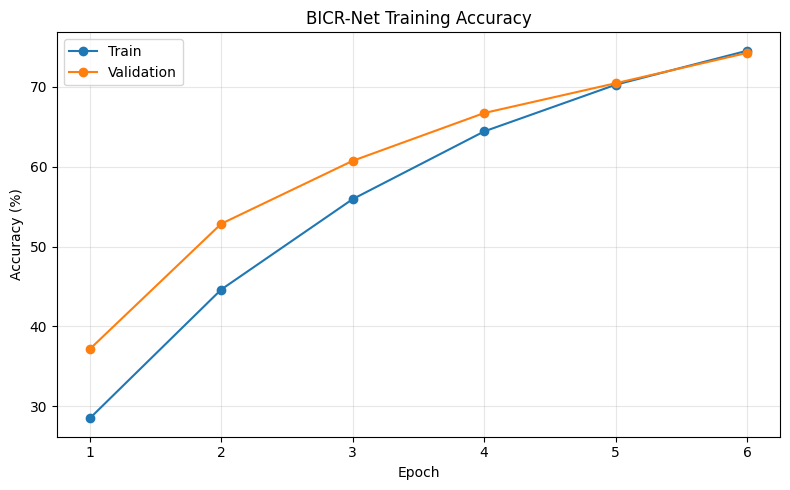

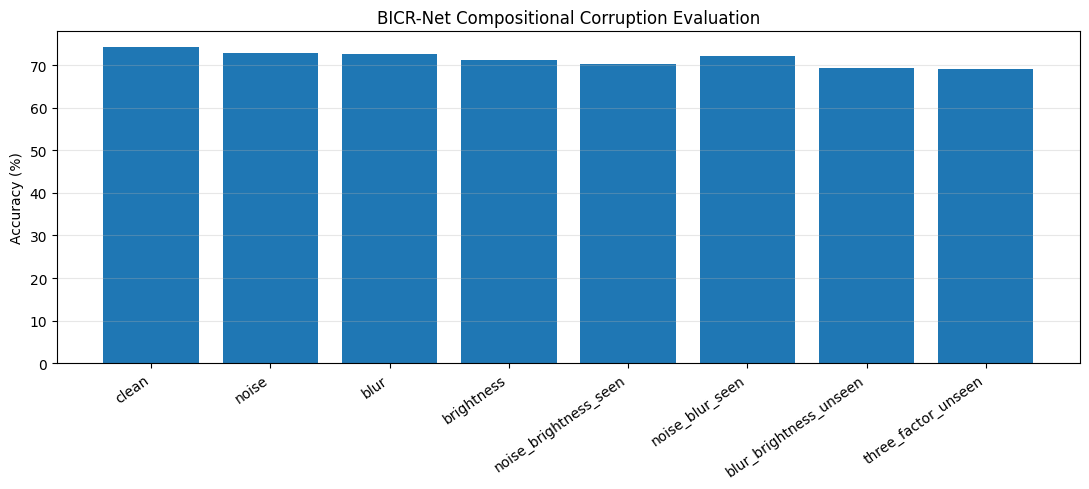

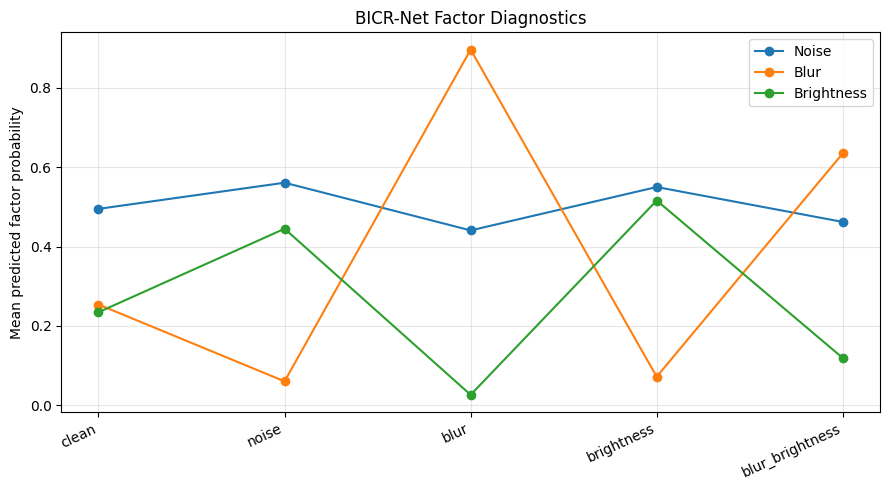


BICR-NET PIPELINE COMPLETED

Compositional evaluation:
   model              condition  accuracy      split
BICR-Net                  clean 74.243490 validation
BICR-Net                  noise 72.906404 validation
BICR-Net                   blur 72.695285 validation
BICR-Net             brightness 71.147080 validation
BICR-Net  noise_brightness_seen 70.302604 validation
BICR-Net        noise_blur_seen 72.132301 validation
BICR-Net blur_brightness_unseen 69.387755 validation
BICR-Net    three_factor_unseen 69.035890 validation

Interaction ablation:
             condition  full_bicr_accuracy  without_interaction_accuracy  difference
                 clean           74.243490                     74.243490    0.000000
                 noise           72.836031                     71.921182    0.914849
                  blur           72.695285                     72.624912    0.070373
            brightness           71.147080                     71.147080    0.000000
 noise_brightness_s

In [164]:

# ================================================================
# BICR-NET: COMPLETE RESEARCH PIPELINE
# Kaggle Tesla T4 | Imagenette | Single execution cell
# ================================================================

import os, time, json, random, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models

# -------------------- 1. CONFIGURATION ---------------------------

BICR_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BICR_ROOT = "/kaggle/working/BICR_Net"
BICR_CKPT = f"{BICR_ROOT}/checkpoints"
BICR_RESULTS = f"{BICR_ROOT}/results"
BICR_FIGURES = f"{BICR_ROOT}/figures"

for p in [BICR_ROOT, BICR_CKPT, BICR_RESULTS, BICR_FIGURES]:
    os.makedirs(p, exist_ok=True)

BICR_SEED = 42
BICR_EPOCHS = 6
BICR_LR = 3e-4
BICR_FACTOR_WEIGHT = 0.25
BICR_SEVERITY_WEIGHT = 0.10
BICR_MAX_TRAIN_SECONDS = 4 * 60 * 60

random.seed(BICR_SEED)
np.random.seed(BICR_SEED)
torch.manual_seed(BICR_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(BICR_SEED)
    torch.backends.cudnn.benchmark = True

print("Device:", BICR_DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# -------------------- 2. SAFE DATALOADERS ------------------------

def bicr_safe_loader(old_loader, shuffle=False):
    return DataLoader(
        dataset=old_loader.dataset,
        batch_size=old_loader.batch_size or 32,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(BICR_DEVICE.type == "cuda"),
        drop_last=False,
        collate_fn=old_loader.collate_fn,
        persistent_workers=False
    )

if "train_loader" not in globals() or "val_loader" not in globals():
    raise RuntimeError("Existing train_loader and val_loader are required.")

train_loader = bicr_safe_loader(train_loader, shuffle=True)
val_loader = bicr_safe_loader(val_loader, shuffle=False)

test_loader = None
if "test_loader" in globals() and test_loader is not None:
    test_loader = bicr_safe_loader(test_loader, shuffle=False)

BICR_EVAL_LOADER = test_loader if test_loader is not None else val_loader
BICR_EVAL_SPLIT = "test" if test_loader is not None else "validation"

def bicr_unpack(batch):
    if isinstance(batch, (tuple, list)):
        x, y = batch[:2]
    elif isinstance(batch, dict):
        x = batch.get("image", batch.get("images"))
        y = batch.get("label", batch.get("labels"))
    else:
        raise TypeError("Unsupported batch format.")

    if y.ndim > 1:
        y = y.argmax(dim=1)

    return x, y.long()

sample_x, sample_y = bicr_unpack(next(iter(train_loader)))

BICR_NUM_CLASSES = 10
BICR_IMAGE_SHAPE = list(sample_x.shape[1:])

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Evaluation split:", BICR_EVAL_SPLIT)
print("Image shape:", sample_x.shape)

# -------------------- 3. CORRUPTION GENERATION -------------------

BICR_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

BICR_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)

BICR_FACTORS = ["noise", "blur", "brightness"]

BICR_TRAIN_COMBOS = [
    (),
    ("noise",),
    ("blur",),
    ("brightness",),
    ("noise", "brightness"),
    ("noise", "blur")
]

def bicr_denormalize(x):
    mean = BICR_MEAN.to(x.device, dtype=x.dtype)
    std = BICR_STD.to(x.device, dtype=x.dtype)
    return (x * std + mean).clamp(0, 1)

def bicr_normalize(x):
    mean = BICR_MEAN.to(x.device, dtype=x.dtype)
    std = BICR_STD.to(x.device, dtype=x.dtype)
    return (x - mean) / std

def bicr_corrupt(x, name, strength=1.0):
    if name == "noise":
        return (x + torch.randn_like(x) * (0.15 * strength)).clamp(0, 1)

    if name == "blur":
        return F.avg_pool2d(
            x, kernel_size=5, stride=1, padding=2
        ).clamp(0, 1)

    if name == "brightness":
        return (x * (1.0 + 0.4 * strength)).clamp(0, 1)

    return x

def bicr_training_corruptions(x):
    pixel_x = bicr_denormalize(x)
    output, factor_targets, severity_targets = [], [], []

    for i in range(x.shape[0]):
        combo = random.choice(BICR_TRAIN_COMBOS)
        img = pixel_x[i:i+1].clone()

        factors = torch.zeros(3, device=x.device)
        severities = torch.zeros(3, device=x.device)

        for name in combo:
            idx = BICR_FACTORS.index(name)
            strength = random.uniform(0.65, 1.0)

            img = bicr_corrupt(img, name, strength)
            factors[idx] = 1.0
            severities[idx] = strength

        output.append(img)
        factor_targets.append(factors)
        severity_targets.append(severities)

    return (
        bicr_normalize(torch.cat(output)),
        torch.stack(factor_targets),
        torch.stack(severity_targets)
    )

def bicr_fixed_corruption(x, combo):
    img = bicr_denormalize(x)
    for name in combo:
        img = bicr_corrupt(img, name, 1.0)
    return bicr_normalize(img)

# -------------------- 4. BICR-NET ARCHITECTURE -------------------

class BICRFactorizer(nn.Module):
    def __init__(self, feature_dim=512, hidden_dim=128, factors=3):
        super().__init__()

        self.shared = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.15)
        )

        self.factor_head = nn.Linear(hidden_dim, factors)
        self.severity_head = nn.Linear(hidden_dim, factors)

        self.factor_embeddings = nn.Parameter(
            torch.randn(factors, hidden_dim) * 0.02
        )

    def forward(self, features):
        h = self.shared(features)
        factor_logits = self.factor_head(h)
        severity = torch.sigmoid(self.severity_head(h))
        factor_probs = torch.sigmoid(factor_logits)

        tokens = (
            factor_probs.unsqueeze(-1)
            * severity.unsqueeze(-1)
            * self.factor_embeddings.unsqueeze(0)
        )

        return factor_logits, severity, factor_probs, tokens


class BICRInteraction(nn.Module):
    def __init__(self, hidden_dim=128, feature_dim=512):
        super().__init__()

        self.pair_network = nn.Sequential(
            nn.Linear(hidden_dim * 2, 192),
            nn.ReLU(inplace=True),
            nn.Linear(192, feature_dim),
            nn.ReLU(inplace=True)
        )

        self.individual_network = nn.Sequential(
            nn.Linear(hidden_dim, feature_dim),
            nn.ReLU(inplace=True),
            nn.Linear(feature_dim, feature_dim)
        )

        self.scale = nn.Parameter(torch.tensor(0.1))

    def forward(self, tokens, factor_probs):
        pair_outputs = []

        for i in range(tokens.shape[1]):
            for j in range(i + 1, tokens.shape[1]):
                pair = torch.cat([tokens[:, i], tokens[:, j]], dim=1)
                pair_output = self.pair_network(pair)

                # Suppress pair contribution when either factor is absent.
                pair_output = pair_output * (
                    factor_probs[:, i] * factor_probs[:, j]
                ).unsqueeze(1)

                pair_outputs.append(pair_output)

        if pair_outputs:
            interaction = torch.stack(pair_outputs).sum(dim=0)
        else:
            interaction = torch.zeros(
                tokens.shape[0], 512,
                device=tokens.device,
                dtype=tokens.dtype
            )

        factor_strength = factor_probs.sum(dim=1, keepdim=True)
        individual = self.individual_network(
            tokens.sum(dim=1)
        ) * (factor_strength > 0).to(tokens.dtype)

        return self.scale * (individual + interaction)


class BICRNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        backbone = models.resnet18(weights=None)

        self.encoder = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1,
            backbone.layer2,
            backbone.layer3,
            backbone.layer4,
            backbone.avgpool
        )

        self.factorizer = BICRFactorizer()
        self.interaction = BICRInteraction()
        self.feature_norm = nn.LayerNorm(512)

        self.classifier = nn.Sequential(
            nn.Dropout(0.25),
            nn.Linear(512, num_classes)
        )

    def forward(self, x, disable_interaction=False):
        features = torch.flatten(self.encoder(x), 1)

        factor_logits, severity, factor_probs, tokens = (
            self.factorizer(features)
        )

        if disable_interaction:
            correction = torch.zeros_like(features)
        else:
            correction = self.interaction(tokens, factor_probs)

        corrected = self.feature_norm(features + correction)
        logits = self.classifier(corrected)

        return {
            "logits": logits,
            "factor_logits": factor_logits,
            "severity": severity,
            "factor_probs": factor_probs,
            "features": features,
            "corrected_features": corrected,
            "correction": correction
        }


BICR_MODEL = BICRNet(BICR_NUM_CLASSES).to(BICR_DEVICE)

BICR_PARAMS = sum(
    p.numel() for p in BICR_MODEL.parameters()
    if p.requires_grad
)

with torch.no_grad():
    test_out = BICR_MODEL(sample_x[:2].to(BICR_DEVICE))

print("BICR-Net parameters:", f"{BICR_PARAMS:,}")
print("Forward test:", test_out["logits"].shape)

# -------------------- 5. TRAINING -------------------------------

BICR_OPTIMIZER = torch.optim.AdamW(
    BICR_MODEL.parameters(),
    lr=BICR_LR,
    weight_decay=1e-4
)

BICR_SCHEDULER = torch.optim.lr_scheduler.CosineAnnealingLR(
    BICR_OPTIMIZER,
    T_max=BICR_EPOCHS
)

BICR_SCALER = torch.amp.GradScaler(
    "cuda", enabled=(BICR_DEVICE.type == "cuda")
)

BICR_BEST_PATH = f"{BICR_CKPT}/bicr_net_best.pth"
BICR_LAST_PATH = f"{BICR_CKPT}/bicr_net_last.pth"

BICR_HISTORY = []
BICR_BEST_VAL = -1.0
BICR_START = time.time()

def bicr_clean_validation(model, loader):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0

    with torch.no_grad():
        for batch in loader:
            x, y = bicr_unpack(batch)
            x = x.to(BICR_DEVICE, non_blocking=True)
            y = y.to(BICR_DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(BICR_DEVICE.type == "cuda")
            ):
                output = model(x)
                loss = F.cross_entropy(output["logits"], y)

            correct += (output["logits"].argmax(1) == y).sum().item()
            total += y.size(0)
            loss_sum += loss.item() * y.size(0)

    return 100 * correct / max(total, 1), loss_sum / max(total, 1)


print("\n" + "=" * 65)
print("BICR-NET TRAINING STARTED")
print("=" * 65)

for epoch in range(1, BICR_EPOCHS + 1):

    if time.time() - BICR_START > BICR_MAX_TRAIN_SECONDS:
        print("Training time reserve reached.")
        break

    BICR_MODEL.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    epoch_start = time.time()

    for step, batch in enumerate(train_loader, 1):
        x, y = bicr_unpack(batch)

        x = x.to(BICR_DEVICE, non_blocking=True)
        y = y.to(BICR_DEVICE, non_blocking=True)

        corrupted, factor_targets, severity_targets = (
            bicr_training_corruptions(x)
        )

        BICR_OPTIMIZER.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(BICR_DEVICE.type == "cuda")
        ):
            output = BICR_MODEL(corrupted)

            cls_loss = F.cross_entropy(output["logits"], y)

            factor_loss = F.binary_cross_entropy_with_logits(
                output["factor_logits"], factor_targets
            )

            severity_error = F.smooth_l1_loss(
                output["severity"],
                severity_targets,
                reduction="none"
            )

            severity_mask = factor_targets
            severity_loss = (
                (severity_error * severity_mask).sum()
                / severity_mask.sum().clamp_min(1.0)
            )

            loss = (
                cls_loss
                + BICR_FACTOR_WEIGHT * factor_loss
                + BICR_SEVERITY_WEIGHT * severity_loss
            )

        BICR_SCALER.scale(loss).backward()
        BICR_SCALER.unscale_(BICR_OPTIMIZER)

        torch.nn.utils.clip_grad_norm_(
            BICR_MODEL.parameters(), 2.0
        )

        BICR_SCALER.step(BICR_OPTIMIZER)
        BICR_SCALER.update()

        bs = y.size(0)
        total_loss += loss.item() * bs
        total_correct += (
            output["logits"].argmax(1) == y
        ).sum().item()
        total_samples += bs

        if step % 50 == 0:
            print(
                f"Epoch {epoch}/{BICR_EPOCHS} "
                f"Batch {step}/{len(train_loader)} "
                f"Loss {loss.item():.4f}"
            )
f
    BICR_SCHEDULER.step()

    train_acc = 100 * total_correct / max(total_samples, 1)
    train_loss = total_loss / max(total_samples, 1)

    val_acc, val_loss = bicr_clean_validation(
        BICR_MODEL, val_loader
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "validation_loss": val_loss,
        "validation_accuracy": val_acc,
        "epoch_seconds": time.time() - epoch_start
    }

    BICR_HISTORY.append(record)

    # Save latest model after every epoch.
    torch.save({
        "epoch": epoch,
        "model_state_dict": BICR_MODEL.state_dict(),
        "optimizer_state_dict": BICR_OPTIMIZER.state_dict(),
        "history": BICR_HISTORY,
        "validation_accuracy": val_acc
    }, BICR_LAST_PATH)

    if val_acc > BICR_BEST_VAL:
        BICR_BEST_VAL = val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": BICR_MODEL.state_dict(),
            "validation_accuracy": val_acc,
            "history": BICR_HISTORY
        }, BICR_BEST_PATH)

    pd.DataFrame(BICR_HISTORY).to_csv(
        f"{BICR_RESULTS}/training_history.csv",
        index=False
    )

    print(
        f"\nEpoch {epoch} | "
        f"Train {train_acc:.2f}% | "
        f"Val {val_acc:.2f}% | "
        f"Best {BICR_BEST_VAL:.2f}% | "
        f"Time {record['epoch_seconds']:.1f}s\n"
    )

print("Training phase finished.")
print("Best validation accuracy:", BICR_BEST_VAL)

# -------------------- 6. LOAD BEST CHECKPOINT --------------------

if not os.path.exists(BICR_BEST_PATH):
    raise RuntimeError("No BICR-Net checkpoint was saved.")

BICR_CHECKPOINT = torch.load(
    BICR_BEST_PATH,
    map_location=BICR_DEVICE,
    weights_only=False
)

BICR_MODEL.load_state_dict(
    BICR_CHECKPOINT["model_state_dict"]
)
BICR_MODEL.eval()

# -------------------- 7. COMPOSITIONAL EVALUATION ----------------

BICR_CONDITIONS = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness_seen": ("noise", "brightness"),
    "noise_blur_seen": ("noise", "blur"),
    "blur_brightness_unseen": ("blur", "brightness"),
    "three_factor_unseen": ("noise", "blur", "brightness")
}

def bicr_evaluate(model, loader, combo, disable_interaction=False):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for batch in loader:
            x, y = bicr_unpack(batch)
            x = x.to(BICR_DEVICE, non_blocking=True)
            y = y.to(BICR_DEVICE, non_blocking=True)

            if combo:
                x = bicr_fixed_corruption(x, combo)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(BICR_DEVICE.type == "cuda")
            ):
                output = model(
                    x, disable_interaction=disable_interaction
                )

            correct += (
                output["logits"].argmax(1) == y
            ).sum().item()

            total += y.size(0)

    return 100 * correct / max(total, 1)


BICR_EVAL_ROWS = []

print("\n" + "=" * 65)
print("BICR-NET COMPOSITIONAL EVALUATION")
print("=" * 65)

for name, combo in BICR_CONDITIONS.items():
    acc = bicr_evaluate(
        BICR_MODEL, BICR_EVAL_LOADER, combo
    )

    BICR_EVAL_ROWS.append({
        "model": "BICR-Net",
        "condition": name,
        "accuracy": acc,
        "split": BICR_EVAL_SPLIT
    })

    print(f"{name:30s} | {acc:.2f}%")

BICR_EVAL_DF = pd.DataFrame(BICR_EVAL_ROWS)
BICR_EVAL_DF.to_csv(
    f"{BICR_RESULTS}/compositional_evaluation.csv",
    index=False
)

# -------------------- 8. INTERACTION ABLATION --------------------

print("\nRunning interaction ablation...")

BICR_ABLATION_ROWS = []

for name, combo in BICR_CONDITIONS.items():
    normal_acc = bicr_evaluate(
        BICR_MODEL, BICR_EVAL_LOADER, combo, False
    )

    no_interaction_acc = bicr_evaluate(
        BICR_MODEL, BICR_EVAL_LOADER, combo, True
    )

    BICR_ABLATION_ROWS.append({
        "condition": name,
        "full_bicr_accuracy": normal_acc,
        "without_interaction_accuracy": no_interaction_acc,
        "difference": normal_acc - no_interaction_acc
    })

BICR_ABLATION_DF = pd.DataFrame(BICR_ABLATION_ROWS)
BICR_ABLATION_DF.to_csv(
    f"{BICR_RESULTS}/interaction_ablation.csv",
    index=False
)

# -------------------- 9. FACTOR DIAGNOSTICS ----------------------

print("\nRunning factor diagnostics...")

BICR_DIAGNOSTIC_CONDITIONS = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "blur_brightness": ("blur", "brightness")
}

BICR_FACTOR_ROWS = []

for name, combo in BICR_DIAGNOSTIC_CONDITIONS.items():
    factor_sum = torch.zeros(3, device=BICR_DEVICE)
    count = 0

    with torch.no_grad():
        for batch in BICR_EVAL_LOADER:
            x, y = bicr_unpack(batch)
            x = x.to(BICR_DEVICE, non_blocking=True)

            if combo:
                x = bicr_fixed_corruption(x, combo)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(BICR_DEVICE.type == "cuda")
            ):
                output = BICR_MODEL(x)

            factor_sum += output["factor_probs"].sum(dim=0)
            count += x.size(0)

    averages = (factor_sum / max(count, 1)).cpu().numpy()

    BICR_FACTOR_ROWS.append({
        "condition": name,
        "predicted_noise": averages[0],
        "predicted_blur": averages[1],
        "predicted_brightness": averages[2]
    })

BICR_FACTOR_DF = pd.DataFrame(BICR_FACTOR_ROWS)
BICR_FACTOR_DF.to_csv(
    f"{BICR_RESULTS}/factor_diagnostics.csv",
    index=False
)

# -------------------- 10. SAVE CONFIGURATION --------------------

BICR_CONFIG = {
    "architecture": "BICR-Net",
    "dataset": "Imagenette",
    "backbone": "ResNet-18",
    "pretrained": False,
    "seed": BICR_SEED,
    "epochs_requested": BICR_EPOCHS,
    "best_validation_accuracy": float(BICR_BEST_VAL),
    "trainable_parameters": int(BICR_PARAMS),
    "factors": BICR_FACTORS,
    "training_combinations": [list(c) for c in BICR_TRAIN_COMBOS],
    "held_out_pair": ["blur", "brightness"],
    "held_out_triple": ["noise", "blur", "brightness"],
    "evaluation_split": BICR_EVAL_SPLIT,
    "factor_loss_weight": BICR_FACTOR_WEIGHT,
    "severity_loss_weight": BICR_SEVERITY_WEIGHT,
    "optimizer": "AdamW",
    "learning_rate": BICR_LR
}

with open(f"{BICR_ROOT}/experiment_config.json", "w") as f:
    json.dump(BICR_CONFIG, f, indent=4)

torch.save(
    BICR_MODEL.state_dict(),
    f"{BICR_CKPT}/bicr_net_final_state.pth"
)

# -------------------- 11. GENERATE GRAPHS ------------------------

if BICR_HISTORY:
    hist = pd.DataFrame(BICR_HISTORY)

    plt.figure(figsize=(8, 5))
    plt.plot(hist["epoch"], hist["train_accuracy"], marker="o", label="Train")
    plt.plot(hist["epoch"], hist["validation_accuracy"], marker="o", label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("BICR-Net Training Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{BICR_FIGURES}/training_accuracy.png", dpi=200)
    plt.show()
    plt.close()

plt.figure(figsize=(11, 5))
plt.bar(
    BICR_EVAL_DF["condition"],
    BICR_EVAL_DF["accuracy"]
)
plt.xticks(rotation=35, ha="right")
plt.ylabel("Accuracy (%)")
plt.title("BICR-Net Compositional Corruption Evaluation")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{BICR_FIGURES}/compositional_accuracy.png", dpi=200)
plt.show()
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(
    BICR_FACTOR_DF["condition"],
    BICR_FACTOR_DF["predicted_noise"],
    marker="o", label="Noise"
)
plt.plot(
    BICR_FACTOR_DF["condition"],
    BICR_FACTOR_DF["predicted_blur"],
    marker="o", label="Blur"
)
plt.plot(
    BICR_FACTOR_DF["condition"],
    BICR_FACTOR_DF["predicted_brightness"],
    marker="o", label="Brightness"
)
plt.ylabel("Mean predicted factor probability")
plt.title("BICR-Net Factor Diagnostics")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{BICR_FIGURES}/factor_diagnostics.png", dpi=200)
plt.show()
plt.close()

# -------------------- 12. FINAL SUMMARY --------------------------

print("\n" + "=" * 65)
print("BICR-NET PIPELINE COMPLETED")
print("=" * 65)

print("\nCompositional evaluation:")
print(BICR_EVAL_DF.to_string(index=False))

print("\nInteraction ablation:")
print(BICR_ABLATION_DF.to_string(index=False))

print("\nFactor diagnostics:")
print(BICR_FACTOR_DF.to_string(index=False))

print("\nBest validation accuracy:", BICR_BEST_VAL)
print("Training epochs completed:", len(BICR_HISTORY))
print("Total elapsed minutes:", round((time.time() - BICR_START) / 60, 2))
print("Parameters:", BICR_PARAMS)

print("\nSaved research directory:")
for root, dirs, files in os.walk(BICR_ROOT):
    for filename in files:
        path = os.path.join(root, filename)
        print(path, "|", round(os.path.getsize(path) / 1024**2, 2), "MB")

print("\nBICR-Net execution finished.")


In [165]:

# ================================================================
# FINAL RESEARCH CELL: TEST EVALUATION + COMPLETE BACKUP
# No additional training
# ================================================================

import os, json, time, zipfile, shutil, platform
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

BICR_ROOT = "/kaggle/working/BICR_Net"
BICR_CKPT = f"{BICR_ROOT}/checkpoints"
BICR_RESULTS = f"{BICR_ROOT}/results"
BICR_FIGURES = f"{BICR_ROOT}/figures"

os.makedirs(BICR_RESULTS, exist_ok=True)

# 1. Load the best saved model
best_path = f"{BICR_CKPT}/bicr_net_best.pth"

checkpoint = torch.load(
    best_path,
    map_location=BICR_DEVICE,
    weights_only=False
)

BICR_MODEL.load_state_dict(checkpoint["model_state_dict"])
BICR_MODEL.eval()

print("Loaded best BICR-Net checkpoint.")
print("Best validation accuracy:", checkpoint["validation_accuracy"])

# 2. Evaluate ONLY if a genuine test loader is available
test_results = []
test_available = (
    "test_loader" in globals()
    and test_loader is not None
)

if test_available:

    if test_loader.num_workers != 0:
        test_loader = DataLoader(
            test_loader.dataset,
            batch_size=test_loader.batch_size or 8,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
            collate_fn=test_loader.collate_fn
        )

    conditions = {
        "clean": (),
        "noise": ("noise",),
        "blur": ("blur",),
        "brightness": ("brightness",),
        "noise_brightness_seen": ("noise", "brightness"),
        "noise_blur_seen": ("noise", "blur"),
        "blur_brightness_unseen": ("blur", "brightness"),
        "three_factor_unseen": ("noise", "blur", "brightness")
    }

    def final_test_evaluate(combo):
        BICR_MODEL.eval()
        correct = 0
        total = 0

        # Fixed seed makes stochastic Gaussian noise reproducible
        torch.manual_seed(2026)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(2026)

        with torch.no_grad():
            for batch in test_loader:
                x, y = bicr_unpack(batch)
                x = x.to(BICR_DEVICE, non_blocking=True)
                y = y.to(BICR_DEVICE, non_blocking=True)

                if combo:
                    x = bicr_fixed_corruption(x, combo)

                with torch.amp.autocast(
                    device_type="cuda",
                    enabled=(BICR_DEVICE.type == "cuda")
                ):
                    output = BICR_MODEL(x)

                correct += (
                    output["logits"].argmax(1) == y
                ).sum().item()
                total += y.size(0)

        return 100.0 * correct / max(total, 1), total

    print("\nIndependent TEST evaluation started.")

    for name, combo in conditions.items():
        accuracy, count = final_test_evaluate(combo)

        test_results.append({
            "model": "BICR-Net",
            "split": "test",
            "condition": name,
            "accuracy": accuracy,
            "samples": count
        })

        print(f"{name:30s} | {accuracy:.2f}% | n={count}")

    test_df = pd.DataFrame(test_results)
    test_df.to_csv(
        f"{BICR_RESULTS}/independent_test_results.csv",
        index=False
    )

    print("\nIndependent test results saved.")

else:
    print(
        "\nNo separate test_loader is currently available. "
        "Validation results will NOT be relabelled as test results."
    )

    with open(
        f"{BICR_RESULTS}/test_evaluation_status.txt", "w"
    ) as f:
        f.write(
            "Independent test evaluation not performed: "
            "a separate test_loader was unavailable in this runtime."
        )

# 3. Write architecture documentation
architecture_text = """
# BICR-Net

Blind Interaction-aware Compositional Robustness Network

## Research objective

Investigate blind inference of latent degradation factors,
pairwise degradation interactions, and feature-level correction
for image classification under held-out combinations of
synthetic visual corruptions.

## Architecture

1. Shared ResNet-18 encoder.
2. Blind degradation factorizer.
3. Pairwise latent interaction module.
4. Residual feature correction.
5. Layer normalization and classification head.

## Training protocol

Dataset: Imagenette
Input: 3-channel 160 x 160 images
Backbone: ResNet-18 trained from scratch
Optimizer: AdamW
Seed: 42
Training combinations:
- Clean
- Noise
- Blur
- Brightness
- Noise + brightness
- Noise + blur

Held-out combinations:
- Blur + brightness
- Noise + blur + brightness

## Important implementation details

The factorizer predicts three synthetic corruption indicators
and continuous strength values. Training uses synthetic
corruption metadata as supervision. Inference uses only the image.

The current model uses a simplified average-pooling blur operator
and synthetic additive Gaussian noise and brightness changes.

The current implementation is a prototype and should not be
described as a validated solution to general real-world
distribution shifts.

## Current limitations

- One training seed only.
- Factor identification is imperfect, especially on combined shifts.
- Interaction ablation is an inference-time ablation, not a
  separately retrained ablation.
- Validation results were used for checkpoint selection.
- Independent test results must be reported separately.
- Baseline comparisons require matched training and evaluation
  protocols.
- Novelty requires further literature and citation verification.

## Reproducibility

The Kaggle notebook containing the implementation should be
saved separately using Kaggle Save Version. This folder stores
the model checkpoints, experiment configuration, result tables,
and generated figures.
"""

with open(
    f"{BICR_ROOT}/ARCHITECTURE_AND_METHOD.md", "w"
) as f:
    f.write(architecture_text)

# 4. Write result summary
summary_text = f"""
# BICR-Net Experimental Summary

Best validation accuracy: {checkpoint['validation_accuracy']:.4f}%
Training epochs completed: {len(BICR_HISTORY)}
Trainable parameters: {BICR_PARAMS:,}
Evaluation split previously used: validation
Independent test available in current runtime: {test_available}

This is a single-seed prototype. Results do not establish
statistical significance or state-of-the-art performance.

The factor diagnostics and interaction ablation should be
interpreted as preliminary evidence only.
"""

with open(
    f"{BICR_ROOT}/RESULTS_AND_LIMITATIONS.md", "w"
) as f:
    f.write(summary_text)

# 5. Save environment information
environment = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else "CPU"
    ),
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}

with open(
    f"{BICR_ROOT}/environment.json", "w"
) as f:
    json.dump(environment, f, indent=4)

# 6. Save a compact final checkpoint
torch.save({
    "model_state_dict": BICR_MODEL.state_dict(),
    "architecture": "BICR-Net",
    "best_validation_accuracy": checkpoint["validation_accuracy"],
    "seed": BICR_SEED,
    "parameters": BICR_PARAMS
}, f"{BICR_CKPT}/bicr_net_final.pth")

# 7. Create complete ZIP backup
zip_path = "/kaggle/working/BICR_Net_complete_bundle.zip"

folders_to_backup = [
    "/kaggle/working/BICR_Net",
    "/kaggle/working/reliability_guided_research"
]

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED,
    compresslevel=3
) as archive:

    for folder in folders_to_backup:
        if not os.path.isdir(folder):
            continue

        for root, dirs, files in os.walk(folder):
            for filename in files:
                full_path = os.path.join(root, filename)
                archive_name = os.path.relpath(
                    full_path, "/kaggle/working"
                )
                archive.write(full_path, archive_name)

print("\n" + "=" * 65)
print("RESEARCH BACKUP COMPLETED")
print("=" * 65)

print("Independent test evaluation:", test_available)
print("ZIP:", zip_path)
print("ZIP size (MB):", round(os.path.getsize(zip_path) / 1024**2, 2))
print("BICR project:", BICR_ROOT)
print("Old research files included if available.")
print("Save the Kaggle notebook version separately.")


Loaded best BICR-Net checkpoint.
Best validation accuracy: 74.24349049964813

No separate test_loader is currently available. Validation results will NOT be relabelled as test results.

RESEARCH BACKUP COMPLETED
Independent test evaluation: False
ZIP: /kaggle/working/BICR_Net_complete_bundle.zip
ZIP size (MB): 716.06
BICR project: /kaggle/working/BICR_Net
Old research files included if available.
Save the Kaggle notebook version separately.


In [166]:

# ============================================================
# BICR-NET: RECOVER ORIGINAL TEST DATASET
# Safe diagnostic - does not overwrite existing variables
# ============================================================

import torch
from torch.utils.data import DataLoader
import os

print("=" * 65)
print("AVAILABLE DATA LOADERS")
print("=" * 65)

for name, obj in list(globals().items()):
    if isinstance(obj, DataLoader):
        print(
            f"{name}: dataset={type(obj.dataset).__name__}, "
            f"samples={len(obj.dataset)}, "
            f"batch_size={obj.batch_size}, "
            f"workers={obj.num_workers}"
        )

print("\n" + "=" * 65)
print("POSSIBLE TEST DATASET VARIABLES")
print("=" * 65)

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in [
        "test", "imagenette", "dataset", "data_set", "testset"
    ]):
        try:
            if hasattr(obj, "__len__") and not isinstance(obj, (str, dict)):
                print(
                    f"{name}: type={type(obj).__name__}, "
                    f"length={len(obj)}"
                )
        except Exception:
            pass

print("\n" + "=" * 65)
print("AVAILABLE CHECKPOINTS")
print("=" * 65)

for root, dirs, files in os.walk(
    "/kaggle/working/reliability_guided_research/checkpoints"
):
    for filename in files:
        print(os.path.join(root, filename))

print("\n" + "=" * 65)
print("BICR-NET CHECKPOINTS")
print("=" * 65)

for filename in os.listdir("/kaggle/working/BICR_Net/checkpoints"):
    print(filename)


AVAILABLE DATA LOADERS
train_loader: dataset=CartoonRobustnessDataset, samples=8048, batch_size=8, workers=0
val_loader: dataset=CartoonRobustnessDataset, samples=1421, batch_size=8, workers=0
train_loader_woof: dataset=Subset, samples=8122, batch_size=8, workers=2
val_loader_woof: dataset=Subset, samples=903, batch_size=8, workers=2
test_loader_woof: dataset=ImageFolder, samples=3929, batch_size=8, workers=2
loader: dataset=ImageFolder, samples=3929, batch_size=8, workers=2
noisy_loader: dataset=FixedNoiseDataset, samples=3929, batch_size=8, workers=0
clean_loader: dataset=PairedPaprikaDataset, samples=500, batch_size=8, workers=0
paprika_loader: dataset=PairedPaprikaDataset, samples=500, batch_size=8, workers=0
safe_loader: dataset=Subset, samples=8122, batch_size=4, workers=0
RG_check_loader: dataset=CartoonRobustnessDataset, samples=8048, batch_size=32, workers=0
RG_train_pilot: dataset=CartoonRobustnessDataset, samples=8048, batch_size=32, workers=0
RG_val_pilot: dataset=CartoonRo

In [167]:

# ================================================================
# BICR-NET FINAL TEST EXPERIMENT
# Imagenette test set: 3,925 images
# BICR-Net vs three existing ResNet-18 checkpoints
# No training and no checkpoint overwriting
# ================================================================

import os, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader

BICR_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BICR_FINAL_TEST_DIR = "/kaggle/working/BICR_Net/results"
os.makedirs(BICR_FINAL_TEST_DIR, exist_ok=True)

# ------------------------------------------------
# 1. Recover the correct Imagenette test loader
# ------------------------------------------------

assert "BICR_TEST_LOADER" in globals(), "BICR_TEST_LOADER missing."
assert len(BICR_TEST_LOADER.dataset) == 3925, "Unexpected test dataset size."

BICR_FINAL_TEST_LOADER = DataLoader(
    BICR_TEST_LOADER.dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test images:", len(BICR_FINAL_TEST_LOADER.dataset))
print("Test batches:", len(BICR_FINAL_TEST_LOADER))
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------
# 2. Load the saved best BICR-Net
# ------------------------------------------------

BICR_BEST_PATH = (
    "/kaggle/working/BICR_Net/checkpoints/bicr_net_best.pth"
)

BICR_CKPT_DATA = torch.load(
    BICR_BEST_PATH,
    map_location=BICR_DEVICE,
    weights_only=False
)

BICR_MODEL.load_state_dict(
    BICR_CKPT_DATA["model_state_dict"]
)

BICR_MODEL.to(BICR_DEVICE).eval()

print("BICR-Net checkpoint loaded.")

# ------------------------------------------------
# 3. Load existing ResNet-18 checkpoints
# ------------------------------------------------

BICR_RESNET_DIR = (
    "/kaggle/working/reliability_guided_research/"
    "checkpoints/baseline_resnet18"
)

BICR_RESNET_FILES = {
    42: f"{BICR_RESNET_DIR}/resnet18_seed42_best_v1.pth",
    123: f"{BICR_RESNET_DIR}/resnet18_seed123_best_v1.pth",
    2026: f"{BICR_RESNET_DIR}/resnet18_seed2026_best_v1.pth"
}

def bicr_extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in [
            "model_state_dict",
            "state_dict",
            "model",
            "net",
            "weights"
        ]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                candidate = checkpoint[key]
                if any(torch.is_tensor(v) for v in candidate.values()):
                    return candidate

        if any(torch.is_tensor(v) for v in checkpoint.values()):
            return checkpoint

    raise RuntimeError("Could not identify model state dictionary.")

BICR_RESNET_MODELS = {}

for seed, path in BICR_RESNET_FILES.items():

    if not os.path.exists(path):
        print("Missing ResNet checkpoint:", path)
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    state = bicr_extract_state_dict(checkpoint)

    # Remove DataParallel prefix if present.
    state = {
        k.replace("module.", "", 1) if k.startswith("module.") else k: v
        for k, v in state.items()
    }

    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)

    result = model.load_state_dict(state, strict=True)

    model = model.to(BICR_DEVICE).eval()

    BICR_RESNET_MODELS[seed] = model

    print("Loaded ResNet-18 seed:", seed)

# ------------------------------------------------
# 4. Evaluation conditions
# ------------------------------------------------

BICR_TEST_CONDITIONS = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness_seen": ("noise", "brightness"),
    "noise_blur_seen": ("noise", "blur"),
    "blur_brightness_unseen": ("blur", "brightness"),
    "three_factor_unseen": ("noise", "blur", "brightness")
}

# ------------------------------------------------
# 5. Common evaluation function
# ------------------------------------------------

def bicr_final_evaluate(model, condition, seed=2026,
                        disable_interaction=False):

    model.eval()
    correct = 0
    total = 0

    # Identical random-noise sequence for each model
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    with torch.inference_mode():

        for batch in BICR_FINAL_TEST_LOADER:

            images, labels = bicr_unpack(batch)

            images = images.to(
                BICR_DEVICE, non_blocking=True
            )

            labels = labels.to(
                BICR_DEVICE, non_blocking=True
            )

            if condition:
                images = bicr_fixed_corruption(
                    images, condition
                )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(BICR_DEVICE.type == "cuda")
            ):

                if isinstance(model, BICRNet):
                    output = model(
                        images,
                        disable_interaction=disable_interaction
                    )
                    logits = output["logits"]

                else:
                    logits = model(images)

            predictions = logits.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return 100.0 * correct / max(total, 1)

# ------------------------------------------------
# 6. BICR-Net independent test evaluation
# ------------------------------------------------

BICR_TEST_ROWS = []

print("\n" + "=" * 65)
print("BICR-NET INDEPENDENT TEST RESULTS")
print("=" * 65)

for name, condition in BICR_TEST_CONDITIONS.items():

    accuracy = bicr_final_evaluate(
        BICR_MODEL,
        condition,
        seed=2026
    )

    BICR_TEST_ROWS.append({
        "model": "BICR-Net",
        "seed": 42,
        "condition": name,
        "accuracy": accuracy
    })

    print(f"{name:30s}: {accuracy:.2f}%")

# ------------------------------------------------
# 7. ResNet-18 independent test evaluation
# ------------------------------------------------

for seed, model in BICR_RESNET_MODELS.items():

    print("\nResNet-18 seed:", seed)

    for name, condition in BICR_TEST_CONDITIONS.items():

        accuracy = bicr_final_evaluate(
            model,
            condition,
            seed=2026
        )

        BICR_TEST_ROWS.append({
            "model": "ResNet-18",
            "seed": seed,
            "condition": name,
            "accuracy": accuracy
        })

        print(f"{name:30s}: {accuracy:.2f}%")

# ------------------------------------------------
# 8. Interaction ablation on independent test set
# ------------------------------------------------

BICR_ABLATION_TEST_ROWS = []

print("\nInteraction ablation on test set")

for name, condition in BICR_TEST_CONDITIONS.items():

    full_acc = bicr_final_evaluate(
        BICR_MODEL,
        condition,
        seed=2026,
        disable_interaction=False
    )

    no_interaction_acc = bicr_final_evaluate(
        BICR_MODEL,
        condition,
        seed=2026,
        disable_interaction=True
    )

    BICR_ABLATION_TEST_ROWS.append({
        "condition": name,
        "full_bicr_accuracy": full_acc,
        "without_interaction_accuracy": no_interaction_acc,
        "difference": full_acc - no_interaction_acc
    })

BICR_ABLATION_TEST_DF = pd.DataFrame(
    BICR_ABLATION_TEST_ROWS
)

BICR_ABLATION_TEST_DF.to_csv(
    f"{BICR_FINAL_TEST_DIR}/test_interaction_ablation.csv",
    index=False
)

# ------------------------------------------------
# 9. Save test results
# ------------------------------------------------

BICR_TEST_DF = pd.DataFrame(BICR_TEST_ROWS)

BICR_TEST_DF.to_csv(
    f"{BICR_FINAL_TEST_DIR}/independent_test_comparison.csv",
    index=False
)

BICR_TEST_SUMMARY = (
    BICR_TEST_DF.groupby(
        ["model", "condition"]
    )["accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

BICR_TEST_SUMMARY.to_csv(
    f"{BICR_FINAL_TEST_DIR}/independent_test_summary.csv",
    index=False
)

BICR_ABLATION_TEST_DF.to_csv(
    f"{BICR_FINAL_TEST_DIR}/test_interaction_ablation.csv",
    index=False
)

# ------------------------------------------------
# 10. Final output
# ------------------------------------------------

print("\n" + "=" * 65)
print("INDEPENDENT TEST COMPARISON")
print("=" * 65)

display(BICR_TEST_SUMMARY)

print("\nINTERACTION ABLATION")
display(BICR_ABLATION_TEST_DF)

print("\nSaved:")
print(f"{BICR_FINAL_TEST_DIR}/independent_test_comparison.csv")
print(f"{BICR_FINAL_TEST_DIR}/independent_test_summary.csv")
print(f"{BICR_FINAL_TEST_DIR}/test_interaction_ablation.csv")

print("\nINDEPENDENT TEST EVALUATION COMPLETED.")


Test images: 3925
Test batches: 123
GPU: Tesla T4
BICR-Net checkpoint loaded.
Loaded ResNet-18 seed: 42
Loaded ResNet-18 seed: 123
Loaded ResNet-18 seed: 2026

BICR-NET INDEPENDENT TEST RESULTS
clean                         : 74.11%
noise                         : 73.89%
blur                          : 73.58%
brightness                    : 72.33%
noise_brightness_seen         : 72.43%
noise_blur_seen               : 72.89%
blur_brightness_unseen        : 71.69%
three_factor_unseen           : 71.46%

ResNet-18 seed: 42
clean                         : 73.66%
noise                         : 24.99%
blur                          : 47.16%
brightness                    : 65.07%
noise_brightness_seen         : 19.62%
noise_blur_seen               : 50.19%
blur_brightness_unseen        : 46.85%
three_factor_unseen           : 50.52%

ResNet-18 seed: 123
clean                         : 74.09%
noise                         : 21.45%
blur                          : 47.18%
brightness              

,model,condition,mean,std
0,BICR-Net,blur,73.579618,NaN
1,BICR-Net,blur_brightness_unseen,71.694268,NaN
2,BICR-Net,brightness,72.331210,NaN
3,BICR-Net,clean,74.114650,NaN
4,BICR-Net,noise,73.885350,NaN
5,BICR-Net,noise_blur_seen,72.891720,NaN
6,BICR-Net,noise_brightness_seen,72.433121,NaN
7,BICR-Net,three_factor_unseen,71.464968,NaN
8,ResNet-18,blur,48.925690,3.037551
9,ResNet-18,blur_brightness_unseen,48.602972,2.727107



INTERACTION ABLATION


,condition,full_bicr_accuracy,without_interaction_accuracy,difference
0,clean,74.114650,74.114650,0.000000
1,noise,73.885350,73.885350,0.000000
2,blur,73.579618,73.579618,0.000000
3,brightness,72.331210,72.305732,0.025478
4,noise_brightness_seen,72.433121,72.458599,-0.025478
5,noise_blur_seen,72.891720,72.917197,-0.025478
6,blur_brightness_unseen,71.694268,71.719745,-0.025478
7,three_factor_unseen,71.464968,71.414013,0.050955



Saved:
/kaggle/working/BICR_Net/results/independent_test_comparison.csv
/kaggle/working/BICR_Net/results/independent_test_summary.csv
/kaggle/working/BICR_Net/results/test_interaction_ablation.csv

INDEPENDENT TEST EVALUATION COMPLETED.


In [168]:

# ============================================================
# BICR-Net FINAL EFFICIENCY BENCHMARK
# No training. No checkpoint overwriting.
# Run after the independent test evaluation cell.
# ============================================================

import os, time, gc, json, glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models

assert torch.cuda.is_available(), "CUDA GPU is required for this benchmark."
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# 1. Locate the already-loaded BICR-Net model
bicr_model = globals().get("bicr_model", None)

if bicr_model is None:
    bicr_model = globals().get("bicr_net", None)

if bicr_model is None:
    bicr_model = globals().get("model_bicr", None)

if bicr_model is None and "BICRNet" in globals():
    for value in list(globals().values()):
        try:
            if isinstance(value, BICRNet):
                bicr_model = value
                break
        except Exception:
            pass

assert bicr_model is not None, (
    "Could not locate the loaded BICR-Net object. "
    "Assign your loaded model to bicr_model and rerun."
)

bicr_model = bicr_model.to(device).eval()

# 2. Load the three existing ResNet-18 checkpoints
baseline_dir = (
    "/kaggle/working/reliability_guided_research/"
    "checkpoints/baseline_resnet18"
)

checkpoint_paths = {
    42: os.path.join(baseline_dir, "resnet18_seed42_best_v1.pth"),
    123: os.path.join(baseline_dir, "resnet18_seed123_best_v1.pth"),
    2026: os.path.join(baseline_dir, "resnet18_seed2026_best_v1.pth"),
}

def load_state(path):
    obj = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(obj, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in obj and isinstance(obj[key], dict):
                obj = obj[key]
                break
    if not isinstance(obj, dict):
        raise TypeError(f"Unexpected checkpoint format: {path}")
    return {
        k.replace("module.", "", 1) if k.startswith("module.") else k: v
        for k, v in obj.items()
    }

resnet_models = {}

for seed, path in checkpoint_paths.items():
    assert os.path.exists(path), f"Missing checkpoint: {path}"
    net = models.resnet18(weights=None)
    net.fc = nn.Linear(net.fc.in_features, 10)
    state = load_state(path)
    net.load_state_dict(state, strict=True)
    net = net.to(device).eval()
    resnet_models[seed] = net
    print("Loaded ResNet-18 seed:", seed)

# 3. Get a real input batch from the independent test loader
test_loader = globals().get("BICR_TEST_LOADER", None)
assert test_loader is not None, "BICR_TEST_LOADER not found."

batch = next(iter(test_loader))
if isinstance(batch, (tuple, list)):
    images = batch[0]
else:
    images = batch

images = images.to(device, non_blocking=True)
x1 = images[:1].contiguous()
x8 = images[:min(8, len(images))].contiguous()

# 4. Normalize model output to logits for profiling
def extract_logits(output):
    if torch.is_tensor(output):
        return output
    if isinstance(output, (tuple, list)):
        for item in output:
            if torch.is_tensor(item) and item.ndim == 2:
                return item
    if isinstance(output, dict):
        for key in ("logits", "class_logits", "classification"):
            if key in output and torch.is_tensor(output[key]):
                return output[key]
    raise TypeError("Could not identify classification logits from model output.")

class LogitsOnly(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        return extract_logits(self.model(x))

# 5. Parameter count and estimated FLOPs
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def estimate_flops(model, sample):
    try:
        from torch.profiler import profile, ProfilerActivity
        wrapped = LogitsOnly(model).eval()
        with torch.no_grad():
            with profile(
                activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
                with_flops=True
            ) as prof:
                wrapped(sample)
                torch.cuda.synchronize()
        total_flops = sum(
            event.flops for event in prof.key_averages()
            if getattr(event, "flops", None) is not None
        )
        return float(total_flops), "torch.profiler estimate"
    except Exception as e:
        print("FLOPs estimation unavailable:", repr(e))
        return np.nan, "unavailable"

# 6. Latency, throughput and peak memory
def benchmark_runtime(model, sample, repeats=100, warmup=20):
    wrapped = LogitsOnly(model).eval()

    with torch.no_grad():
        for _ in range(warmup):
            wrapped(sample)
        torch.cuda.synchronize()

        torch.cuda.reset_peak_memory_stats()
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)

        timings = []
        for _ in range(repeats):
            start.record()
            wrapped(sample)
            end.record()
            end.synchronize()
            timings.append(start.elapsed_time(end))

        torch.cuda.synchronize()

    mean_ms = float(np.mean(timings))
    median_ms = float(np.median(timings))
    p95_ms = float(np.percentile(timings, 95))
    batch_size = sample.shape[0]
    throughput = batch_size * 1000.0 / mean_ms
    peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

    return {
        "batch_size": batch_size,
        "latency_mean_ms": mean_ms,
        "latency_median_ms": median_ms,
        "latency_p95_ms": p95_ms,
        "throughput_images_per_sec": throughput,
        "peak_gpu_memory_mb": float(peak_mb),
    }

# 7. Benchmark BICR-Net and each ResNet seed
models_to_test = {"BICR-Net": bicr_model}
for seed, net in resnet_models.items():
    models_to_test[f"ResNet18_seed{seed}"] = net

records = []

for name, net in models_to_test.items():
    print("\nBenchmarking:", name)
    params, trainable = count_parameters(net)
    flops, flops_method = estimate_flops(net, x1)

    result = {
        "model": name,
        "parameters": params,
        "trainable_parameters": trainable,
        "parameters_millions": params / 1e6,
        "estimated_flops_batch1": flops,
        "estimated_gflops_batch1": flops / 1e9 if np.isfinite(flops) else np.nan,
        "flops_method": flops_method,
    }

    for sample in (x1, x8):
        runtime = benchmark_runtime(net, sample)
        suffix = f"batch{runtime['batch_size']}"
        for key, value in runtime.items():
            if key != "batch_size":
                result[f"{key}_{suffix}"] = value

    records.append(result)
    print("Parameters (M):", round(params / 1e6, 3))
    print("Estimated GFLOPs/image:", result["estimated_gflops_batch1"])
    print("Batch-1 latency (ms):", result["latency_mean_ms_batch1"])
    print("Batch-1 throughput:", result["throughput_images_per_sec_batch1"])
    print("Peak GPU memory (MB):", result["peak_gpu_memory_mb_batch1"])

# 8. Save results without touching existing files
out_dir = "/kaggle/working/BICR_Net/results"
os.makedirs(out_dir, exist_ok=True)

efficiency_df = pd.DataFrame(records)
csv_path = os.path.join(out_dir, "efficiency_benchmark.csv")
json_path = os.path.join(out_dir, "efficiency_benchmark.json")

efficiency_df.to_csv(csv_path, index=False)
with open(json_path, "w") as f:
    json.dump(records, f, indent=2)

print("\n" + "=" * 65)
print("FINAL EFFICIENCY BENCHMARK")
print("=" * 65)
display(efficiency_df.round(4))
print("\nSaved:", csv_path)
print("Saved:", json_path)
print("\nIMPORTANT: FLOPs are profiler estimates; report the method.")
print("Latency is specific to this Tesla T4, software stack and input size.")


GPU: Tesla T4
Loaded ResNet-18 seed: 42
Loaded ResNet-18 seed: 123
Loaded ResNet-18 seed: 2026

Benchmarking: BICR-Net


/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Parameters (M): 11.726
Estimated GFLOPs/image: 1.852258826
Batch-1 latency (ms): 4.703279364109039
Batch-1 throughput: 212.6176062666084
Peak GPU memory (MB): 3631.65576171875

Benchmarking: ResNet18_seed42
Parameters (M): 11.182
Estimated GFLOPs/image: 1.85058304
Batch-1 latency (ms): 3.495179839134216
Batch-1 throughput: 286.1083108809955
Peak GPU memory (MB): 3631.65576171875

Benchmarking: ResNet18_seed123
Parameters (M): 11.182
Estimated GFLOPs/image: 1.85058304
Batch-1 latency (ms): 3.181112003326416
Batch-1 throughput: 314.3554829111087
Peak GPU memory (MB): 3631.65576171875

Benchmarking: ResNet18_seed2026
Parameters (M): 11.182
Estimated GFLOPs/image: 1.85058304
Batch-1 latency (ms): 3.4393449592590333
Batch-1 throughput: 290.7530392692678
Peak GPU memory (MB): 3631.65576171875

FINAL EFFICIENCY BENCHMARK


,model,parameters,trainable_parameters,parameters_millions,estimated_flops_batch1,estimated_gflops_batch1,flops_method,latency_mean_ms_batch1,latency_median_ms_batch1,latency_p95_ms_batch1,throughput_images_per_sec_batch1,peak_gpu_memory_mb_batch1,latency_mean_ms_batch8,latency_median_ms_batch8,latency_p95_ms_batch8,throughput_images_per_sec_batch8,peak_gpu_memory_mb_batch8
0,BICR-Net,11726353,11726353,11.7264,1.852259e+09,1.8523,torch.profiler estimate,4.7033,4.9559,5.2302,212.6176,3631.6558,7.4702,7.4365,7.5872,1070.9235,3653.0933
1,ResNet18_seed42,11181642,11181642,11.1816,1.850583e+09,1.8506,torch.profiler estimate,3.4952,3.4759,3.8173,286.1083,3631.6558,7.3569,7.3698,7.4596,1087.4152,3653.0933
2,ResNet18_seed123,11181642,11181642,11.1816,1.850583e+09,1.8506,torch.profiler estimate,3.1811,3.0842,3.6399,314.3555,3631.6558,7.3826,7.3797,7.5318,1083.6337,3653.0933
3,ResNet18_seed2026,11181642,11181642,11.1816,1.850583e+09,1.8506,torch.profiler estimate,3.4393,3.4536,3.8187,290.7530,3631.6558,7.3882,7.3833,7.5306,1082.8070,3653.0933



Saved: /kaggle/working/BICR_Net/results/efficiency_benchmark.csv
Saved: /kaggle/working/BICR_Net/results/efficiency_benchmark.json

IMPORTANT: FLOPs are profiler estimates; report the method.
Latency is specific to this Tesla T4, software stack and input size.


In [169]:

import os, glob, torch, json

base = "/kaggle/working/reliability_guided_research"
checkpoint_dir = os.path.join(base, "checkpoints/baseline_resnet18")

print("=" * 65)
print("RESNET-18 TRAINING CONFIGURATION AUDIT")
print("=" * 65)

for seed in [42, 123, 2026]:
    path = os.path.join(
        checkpoint_dir, f"resnet18_seed{seed}_best_v1.pth"
    )
    print(f"\nSEED {seed}:")
    if not os.path.exists(path):
        print("Checkpoint missing:", path)
        continue

    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    if isinstance(ckpt, dict):
        for key, value in ckpt.items():
            if key in ("state_dict", "model_state_dict", "model"):
                continue
            if isinstance(value, (str, int, float, bool, list, tuple)):
                print(f"{key}: {value}")
            elif isinstance(value, dict) and len(value) < 30:
                print(f"{key}: {value}")

print("\n" + "=" * 65)
print("POSSIBLE CONFIGURATION / TRAINING FILES")
print("=" * 65)

patterns = [
    "**/*config*.json",
    "**/*history*.csv",
    "**/*baseline*.py",
    "**/*resnet*.py",
    "**/*training*.json",
]

for pattern in patterns:
    for path in glob.glob(
        os.path.join(base, pattern), recursive=True
    ):
        print(path)

print("\nAudit completed. No checkpoints were modified.")


RESNET-18 TRAINING CONFIGURATION AUDIT

SEED 42:
seed: 42
epoch: 6
val_accuracy: 73.39901477832512
model_type: ResNet18_scratch
num_classes: 10

SEED 123:
seed: 123
epoch: 6
val_accuracy: 75.58057705840957
model_type: ResNet18_scratch
num_classes: 10

SEED 2026:
seed: 2026
epoch: 6
val_accuracy: 74.94722026741731
model_type: ResNet18_scratch
num_classes: 10

POSSIBLE CONFIGURATION / TRAINING FILES
/kaggle/working/reliability_guided_research/architecture_config.json
/kaggle/working/reliability_guided_research/complete_experiment_config.json
/kaggle/working/reliability_guided_research/pilot_backup/architecture_config.json
/kaggle/working/reliability_guided_research/results/rg_matched_ablation_history_v1.csv
/kaggle/working/reliability_guided_research/results/rg_multiseed_history_v1.csv
/kaggle/working/reliability_guided_research/results/ranking_training_history.csv
/kaggle/working/reliability_guided_research/results/rg_no_ranking_loss_control_history_v1.csv
/kaggle/working/reliability_gu

In [170]:

import os, json, glob, re

root = "/kaggle/working/reliability_guided_research"

files = [
    os.path.join(root, "architecture_config.json"),
    os.path.join(root, "complete_experiment_config.json"),
    "/kaggle/working/BICR_Net/experiment_config.json"
]

print("=" * 65)
print("EXPERIMENT CONFIGURATION")
print("=" * 65)

for path in files:
    if os.path.isfile(path):
        print("\nFILE:", path)
        try:
            with open(path, "r") as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:12000])
        except Exception as e:
            print("Could not read:", e)

print("\n" + "=" * 65)
print("TRAINING CODE / AUGMENTATION SEARCH")
print("=" * 65)

search_roots = [
    "/kaggle/working/reliability_guided_research",
    "/kaggle/working/BICR_Net"
]

patterns = [
    "RandomHorizontalFlip",
    "RandomRotation",
    "ColorJitter",
    "GaussianBlur",
    "corruption",
    "add_noise",
    "brightness",
    "noise_strength",
    "blur_strength",
    "train_transform",
    "transforms.Compose",
    "criterion",
    "CrossEntropyLoss"
]

for folder in search_roots:
    for ext in ("*.py", "*.ipynb"):
        for path in glob.glob(
            os.path.join(folder, "**", ext), recursive=True
        ):
            try:
                with open(path, "r", encoding="utf-8") as f:
                    content = f.read()
                matches = [
                    line.strip()[:250]
                    for line in content.splitlines()
                    if any(term.lower() in line.lower()
                           for term in patterns)
                ]
                if matches:
                    print("\nSOURCE:", path)
                    for line in matches[:35]:
                        print(" ", line)
            except Exception:
                pass

print("\nAudit complete. No files or checkpoints modified.")


EXPERIMENT CONFIGURATION

FILE: /kaggle/working/reliability_guided_research/architecture_config.json
{
  "architecture": "Reliability-Supervised Adaptive Feature Learning",
  "input_channels": 3,
  "num_classes": 3,
  "feature_dim": 256,
  "input_size": 160,
  "normalization": "ImageNet"
}

FILE: /kaggle/working/reliability_guided_research/complete_experiment_config.json
{
  "research_direction": "Reliability-Guided Adaptive Feature Learning",
  "dataset": "Imagenette",
  "num_classes": 10,
  "original_checkpoint": "/kaggle/working/reliability_guided_research/checkpoints/rg_pilot_best.pth",
  "ranking_checkpoint": "/kaggle/working/reliability_guided_research/checkpoints/rg_ranking_best.pth",
  "ranking_loss_weight": 0.25,
  "ranking_margin": 0.2,
  "ranking_best_epoch": 1,
  "random_seed": 42,
  "evaluation_conditions": [
    "clean",
    "gaussian_noise",
    "gaussian_blur"
  ]
}

FILE: /kaggle/working/BICR_Net/experiment_config.json
{
  "architecture": "BICR-Net",
  "dataset": "Imag

In [171]:

import inspect

names = [
    "CartoonRobustnessDataset",
    "BICRNet",
    "BICR_TRAIN_LOADER",
    "BICR_VAL_LOADER",
    "BICR_TEST_LOADER",
    "train_loader",
    "val_loader"
]

for name in names:
    obj = globals().get(name)
    print("\n" + "=" * 60)
    print(name, ":", type(obj).__name__ if obj is not None else "NOT FOUND")

    if obj is None:
        continue

    if inspect.isclass(obj) or inspect.isfunction(obj):
        try:
            print(inspect.getsource(obj)[:10000])
        except Exception as e:
            print("Source unavailable:", e)

    elif hasattr(obj, "dataset"):
        ds = obj.dataset
        print("Dataset:", type(ds).__name__)
        print("Samples:", len(ds))
        print("Batch size:", obj.batch_size)
        print("Workers:", obj.num_workers)
        try:
            print("Dataset source:")
            print(inspect.getsource(type(ds))[:10000])
        except Exception:
            pass

print("\nInspection completed. No training performed.")



CartoonRobustnessDataset : type
Source unavailable: source code not available

BICRNet : type
Source unavailable: source code not available

BICR_TRAIN_LOADER : DataLoader
Dataset: CartoonRobustnessDataset
Samples: 8048
Batch size: 8
Workers: 0
Dataset source:

BICR_VAL_LOADER : DataLoader
Dataset: CartoonRobustnessDataset
Samples: 1421
Batch size: 8
Workers: 0
Dataset source:

BICR_TEST_LOADER : DataLoader
Dataset: CartoonRobustnessDataset
Samples: 3925
Batch size: 8
Workers: 0
Dataset source:

train_loader : DataLoader
Dataset: CartoonRobustnessDataset
Samples: 8048
Batch size: 8
Workers: 0
Dataset source:

val_loader : DataLoader
Dataset: CartoonRobustnessDataset
Samples: 1421
Batch size: 8
Workers: 0
Dataset source:

Inspection completed. No training performed.


In [172]:

import torch
import pprint

print("=" * 65)
print("BICR-NET DATASET INTERNAL INSPECTION")
print("=" * 65)

for name in ["BICR_TRAIN_LOADER", "BICR_VAL_LOADER", "BICR_TEST_LOADER"]:
    loader = globals()[name]
    ds = loader.dataset

    print(f"\n{'='*55}")
    print("LOADER:", name)
    print("Dataset class:", type(ds))
    print("Dataset size:", len(ds))
    print("Dataset attributes:")

    for key, value in vars(ds).items():
        if key.startswith("__"):
            continue
        if isinstance(value, (str, int, float, bool, type(None))):
            print(f"  {key}: {value}")
        elif isinstance(value, (list, tuple)):
            print(f"  {key}: {type(value).__name__}, length={len(value)}")
            if len(value) and len(value) <= 10:
                print("   ", value)
        elif isinstance(value, dict):
            print(f"  {key}: dict keys={list(value.keys())[:20]}")
        else:
            print(f"  {key}: {type(value).__name__}")

    print("\nDataset transform:")
    print(getattr(ds, "transform", "No transform attribute"))

    print("\nOne sample:")
    sample = ds[0]
    if isinstance(sample, (tuple, list)):
        for i, item in enumerate(sample):
            if torch.is_tensor(item):
                print(f"  item {i}: tensor shape={tuple(item.shape)}, dtype={item.dtype}")
                if item.numel() < 20:
                    print("   value:", item)
            else:
                print(f"  item {i}: {type(item).__name__}, value={str(item)[:300]}")
    else:
        print("  sample type:", type(sample).__name__)
        print("  sample:", str(sample)[:500])

print("\nInspection finished. No training or checkpoint changes.")


BICR-NET DATASET INTERNAL INSPECTION

LOADER: BICR_TRAIN_LOADER
Dataset class: <class '__main__.CartoonRobustnessDataset'>
Dataset size: 8048
Dataset attributes:
  dataframe: DataFrame
  transform: Compose
  training: True

Dataset transform:
Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

One sample:
  item 0: tensor shape=(3, 160, 160), dtype=torch.float32
  item 1: int, value=0

LOADER: BICR_VAL_LOADER
Dataset class: <class '__main__.CartoonRobustnessDataset'>
Dataset size: 1421
Dataset attributes:
  dataframe: DataFrame
  transform: Compose
  training: False

Dataset transform:
Compose(
    Resize(size=(160, 160), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

One sample:
  item 0: tensor shape=(3, 160, 160), dtype=torch.float32

In [173]:

import inspect

print("=" * 65)
print("BICR-NET CORRUPTION PIPELINE AUDIT")
print("=" * 65)

keywords = [
    "corrupt", "noise", "blur", "bright",
    "severity", "strength", "augment", "transform",
    "factor", "bicr", "train"
]

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in keywords):
        if inspect.isfunction(obj):
            print(f"\nFUNCTION: {name}")
            try:
                print(inspect.getsource(obj)[:5000])
            except Exception:
                print("Source unavailable")
        elif isinstance(obj, (int, float, str, bool)):
            print(f"{name} = {obj}")

print("\n" + "=" * 65)
print("DATAFRAME COLUMNS")
print("=" * 65)

df = BICR_TRAIN_LOADER.dataset.dataframe
print("Columns:", list(df.columns))
print(df.head(3).to_string())

print("\nAudit completed. No training performed.")


BICR-NET CORRUPTION PIPELINE AUDIT
train_accuracy = 38.63071570576541
train_loss = 0.896221584697841
PRETRAINED_EPOCHS = 3
best_pretrained_val_acc = 95.77762139338493
train_correct = 6903
train_total = 8122
train_acc = 74.51540755467197
train_count = 940

FUNCTION: train_test_split
@validate_params(
    {
        "test_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "train_size": [
            Interval(RealNotInt, 0, 1, closed="neither"),
            Interval(numbers.Integral, 1, None, closed="left"),
            None,
        ],
        "random_state": ["random_state"],
        "shuffle": ["boolean"],
        "stratify": ["array-like", None],
    },
    prefer_skip_nested_validation=True,
)
def train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None,
):
    """Split arrays or matrices into ran

In [174]:

import os, pandas as pd

print("BICR-NET TRAINING SETTINGS")
for name in [
    "BICR_TRAIN_COMBOS",
    "BICR_FACTORS",
    "BICR_EPOCHS",
    "BICR_LR",
    "BICR_FACTOR_WEIGHT",
    "BICR_SEVERITY_WEIGHT",
    "BICR_WEIGHT_DECAY",
    "BICR_BATCH_SIZE",
    "BICR_OPTIMIZER",
]:
    if name in globals():
        print(name, "=", globals()[name])

path = (
    "/kaggle/working/reliability_guided_research/"
    "results/resnet18_baseline_training_v1.csv"
)

print("\nEXISTING RESNET-18 TRAINING HISTORY")
if os.path.exists(path):
    df = pd.read_csv(path)
    print("Columns:", list(df.columns))
    print(df.to_string(index=False))
else:
    print("Training history CSV not found.")

print("\nInspection only. No training or checkpoint changes.")


BICR-NET TRAINING SETTINGS
BICR_TRAIN_COMBOS = [(), ('noise',), ('blur',), ('brightness',), ('noise', 'brightness'), ('noise', 'blur')]
BICR_FACTORS = ['noise', 'blur', 'brightness']
BICR_EPOCHS = 6
BICR_LR = 0.0003
BICR_FACTOR_WEIGHT = 0.25
BICR_SEVERITY_WEIGHT = 0.1
BICR_OPTIMIZER = AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0003
    lr: 0.0
    maximize: False
    weight_decay: 0.0001
)

EXISTING RESNET-18 TRAINING HISTORY
Columns: ['seed', 'epoch', 'learning_rate', 'train_loss', 'train_accuracy', 'val_accuracy']
 seed  epoch  learning_rate  train_loss  train_accuracy  val_accuracy
   42      1        0.00010    1.547161       48.074056     56.931738
   42      2        0.00010    1.071383       64.662028     66.361717
   42      3        0.00010    0.864742       72.005467     65.869106
   42      4        0.00

In [175]:

# ============================================================
# MATCHED RESNET-18 CONTROL FOR BICR-NET
# Same data, corruption exposure, epochs and optimizer settings
# Classification loss only — no auxiliary factor/severity heads
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.models import resnet18
from pathlib import Path
from tqdm.auto import tqdm

# ----------------------------
# 1. Verify required components
# ----------------------------
required = [
    "BICR_TRAIN_LOADER",
    "BICR_VAL_LOADER",
    "BICR_TEST_LOADER",
    "bicr_training_corruptions",
    "bicr_fixed_corruption",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Missing required notebook variables/functions: {missing}")

# ----------------------------
# 2. Reproducibility and config
# ----------------------------
SEED = 42
EPOCHS = 6
LEARNING_RATE = 0.0003
WEIGHT_DECAY = 0.0001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    BICR_DEVICE if "BICR_DEVICE" in globals()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

batch_size = getattr(BICR_TRAIN_LOADER, "batch_size", None)

print("Device:", device)
print("Training batch size:", batch_size)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

if batch_size != 8:
    print("WARNING: Training loader batch size is not 8. "
          "This differs from the recorded BICR-Net batch size.")

# ----------------------------
# 3. Create ordinary ResNet-18
# ----------------------------
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999),
    eps=1e-8
)

use_amp = device.type == "cuda"
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# ----------------------------
# 4. Helper functions
# ----------------------------
def unpack_batch(batch):
    if isinstance(batch, (tuple, list)) and len(batch) >= 2:
        return batch[0], batch[1]
    raise ValueError("Unexpected dataloader batch format.")

def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            images, labels = unpack_batch(batch)
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total

# ----------------------------
# 5. Train with BICR corruption exposure
# ----------------------------
history = []
best_val_accuracy = -1.0

output_dir = Path("/kaggle/working/BICR_Net")
checkpoint_dir = output_dir / "checkpoints"
results_dir = output_dir / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "resnet18_matched_corruption_control_seed42.pth"

for epoch in range(1, EPOCHS + 1):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        BICR_TRAIN_LOADER,
        desc=f"Matched ResNet Epoch {epoch}/{EPOCHS}"
    )

    for batch in progress:
        images, labels = unpack_batch(batch)

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, dtype=torch.long, non_blocking=True)

        # Apply exactly the BICR-Net training corruption generator.
        # Factor and severity targets are intentionally not used.
        corrupted_images, _, _ = bicr_training_corruptions(images)

        corrupted_images = corrupted_images.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(corrupted_images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_count = labels.size(0)
        running_loss += loss.item() * batch_count
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_count

        progress.set_postfix(
            loss=f"{running_loss / total:.4f}",
            train_acc=f"{100.0 * correct / total:.2f}%"
        )

    train_loss = running_loss / total
    train_accuracy = 100.0 * correct / total

    val_loss, val_accuracy = evaluate_clean(model, BICR_VAL_LOADER)

    history.append({
        "epoch": epoch,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch}: "
        f"Train Loss={train_loss:.4f}, "
        f"Train Acc={train_accuracy:.2f}%, "
        f"Val Loss={val_loss:.4f}, "
        f"Val Acc={val_accuracy:.2f}%"
    )

    # Save the best model using validation accuracy only.
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save({
            "model_state_dict": model.state_dict(),
            "seed": SEED,
            "epoch": epoch,
            "val_accuracy": val_accuracy,
            "model_type": "ResNet18_matched_corruption_control",
            "num_classes": 10,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "epochs": EPOCHS,
            "training_corruptions": [
                (), ("noise",), ("blur",), ("brightness",),
                ("noise", "brightness"), ("noise", "blur")
            ]
        }, checkpoint_path)

history_path = results_dir / "resnet18_matched_control_training_history.csv"
pd.DataFrame(history).to_csv(history_path, index=False)

print("\nTraining completed.")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print("Checkpoint:", checkpoint_path)
print("Training history:", history_path)

# ----------------------------
# 6. Load best checkpoint
# ----------------------------
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# ----------------------------
# 7. Independent test evaluation
# ----------------------------
test_conditions = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness": ("noise", "brightness"),
    "noise_blur": ("noise", "blur"),
    "unseen_blur_brightness": ("blur", "brightness"),
    "unseen_triple": ("noise", "blur", "brightness")
}

test_results = []

for condition_name, combo in test_conditions.items():
    # Reset RNG for reproducible noise evaluation.
    random.seed(2026)
    np.random.seed(2026)
    torch.manual_seed(2026)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(2026)

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch in tqdm(
            BICR_TEST_LOADER,
            desc=f"Testing {condition_name}"
        ):
            images, labels = unpack_batch(batch)

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long, non_blocking=True)

            if combo:
                test_images = bicr_fixed_corruption(images, combo)
            else:
                test_images = images

            test_images = test_images.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(test_images)

            predictions = logits.argmax(1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100.0 * correct / total

    test_results.append({
        "condition": condition_name,
        "corruption_combination": str(combo),
        "correct": correct,
        "total": total,
        "accuracy_percent": accuracy
    })

    print(f"{condition_name}: {accuracy:.2f}% ({correct}/{total})")

# ----------------------------
# 8. Save test results
# ----------------------------
test_results_df = pd.DataFrame(test_results)
test_results_path = results_dir / "resnet18_matched_control_test_results.csv"

test_results_df.to_csv(test_results_path, index=False)

print("\n========== MATCHED RESNET-18 TEST RESULTS ==========")
display(test_results_df)

print("\nSaved files:")
print(checkpoint_path)
print(history_path)
print(test_results_path)


Device: cuda
Training batch size: 8
Epochs: 6
Learning rate: 0.0003
Weight decay: 0.0001


/tmp/ipykernel_49/499199774.py:84: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Matched ResNet Epoch 1/6:   0%|          | 0/1006 [00:00<?, ?it/s]

/tmp/ipykernel_49/499199774.py:157: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/tmp/ipykernel_49/499199774.py:106: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


Epoch 1: Train Loss=1.8081, Train Acc=38.11%, Val Loss=1.5185, Val Acc=49.96%


Matched ResNet Epoch 2/6:   0%|          | 0/1006 [00:00<?, ?it/s]

... (24 outputs left out)

Testing unseen_triple:   0%|          | 0/491 [00:00<?, ?it/s]

unseen_triple: 64.69% (2539/3925)

========== MATCHED RESNET-18 TEST RESULTS ==========


,condition,corruption_combination,correct,total,accuracy_percent
0,clean,(),2692,3925,68.585987
1,noise,"('noise',)",2656,3925,67.668790
2,blur,"('blur',)",2609,3925,66.471338
3,brightness,"('brightness',)",2702,3925,68.840764
4,noise_brightness,"('noise', 'brightness')",2684,3925,68.382166
5,noise_blur,"('noise', 'blur')",2561,3925,65.248408
6,unseen_blur_brightness,"('blur', 'brightness')",2591,3925,66.012739
7,unseen_triple,"('noise', 'blur', 'brightness')",2539,3925,64.687898



Saved files:
/kaggle/working/BICR_Net/checkpoints/resnet18_matched_corruption_control_seed42.pth
/kaggle/working/BICR_Net/results/resnet18_matched_control_training_history.csv
/kaggle/working/BICR_Net/results/resnet18_matched_control_test_results.csv


In [176]:

# ============================================================
# MATCHED RESNET-18 REPEATABILITY EXPERIMENT
# Additional seeds: 123 and 2026
# Preserves the existing seed-42 checkpoint
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.models import resnet18
from pathlib import Path
from tqdm.auto import tqdm

# ----------------------------
# Configuration
# ----------------------------
SEEDS = [123, 2026]
EPOCHS = 6
LEARNING_RATE = 0.0003
WEIGHT_DECAY = 0.0001

device = torch.device(
    BICR_DEVICE if "BICR_DEVICE" in globals()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

use_amp = device.type == "cuda"

output_dir = Path("/kaggle/working/BICR_Net")
checkpoint_dir = output_dir / "checkpoints"
results_dir = output_dir / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

conditions = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness": ("noise", "brightness"),
    "noise_blur": ("noise", "blur"),
    "unseen_blur_brightness": ("blur", "brightness"),
    "unseen_triple": ("noise", "blur", "brightness")
}

all_seed_results = []
all_training_histories = []

# ----------------------------
# Helper functions
# ----------------------------
def unpack_batch(batch):
    if isinstance(batch, (tuple, list)) and len(batch) >= 2:
        return batch[0], batch[1]
    raise ValueError("Unexpected batch format.")

def evaluate_validation(model):
    model.eval()
    correct = 0
    total = 0
    loss_sum = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch in BICR_VAL_LOADER:
            images, labels = unpack_batch(batch)
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return loss_sum / total, 100.0 * correct / total

# ----------------------------
# Train each additional seed
# ----------------------------
for seed in SEEDS:

    print("\n" + "=" * 65)
    print(f"TRAINING MATCHED RESNET-18 — SEED {seed}")
    print("=" * 65)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Fresh ResNet-18 from scratch
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
        eps=1e-8
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=use_amp
    )

    best_val_accuracy = -1.0
    seed_history = []

    checkpoint_path = (
        checkpoint_dir /
        f"resnet18_matched_corruption_control_seed{seed}.pth"
    )

    # Training
    for epoch in range(1, EPOCHS + 1):

        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        progress = tqdm(
            BICR_TRAIN_LOADER,
            desc=f"Seed {seed} | Epoch {epoch}/{EPOCHS}"
        )

        for batch in progress:

            images, labels = unpack_batch(batch)
            images = images.to(device, non_blocking=True)
            labels = labels.to(
                device, dtype=torch.long, non_blocking=True
            )

            # Same corruption generator as BICR-Net
            corrupted_images, _, _ = bicr_training_corruptions(images)
            corrupted_images = corrupted_images.to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                logits = model(corrupted_images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            count = labels.size(0)
            running_loss += loss.item() * count
            correct += (logits.argmax(1) == labels).sum().item()
            total += count

            progress.set_postfix(
                loss=f"{running_loss / total:.4f}",
                accuracy=f"{100 * correct / total:.2f}%"
            )

        train_loss = running_loss / total
        train_accuracy = 100.0 * correct / total

        val_loss, val_accuracy = evaluate_validation(model)

        record = {
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }

        seed_history.append(record)
        all_training_histories.append(record)

        print(
            f"Seed {seed}, Epoch {epoch}: "
            f"Train Acc={train_accuracy:.2f}%, "
            f"Val Acc={val_accuracy:.2f}%"
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_accuracy,
                "model_type": "ResNet18_matched_corruption_control",
                "num_classes": 10,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "epochs": EPOCHS
            }, checkpoint_path)

    print(f"Best validation accuracy: {best_val_accuracy:.2f}%")

    # ------------------------
    # Independent test
    # ------------------------
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    for condition_name, combo in conditions.items():

        random.seed(2026)
        np.random.seed(2026)
        torch.manual_seed(2026)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(2026)

        correct = 0
        total = 0

        with torch.no_grad():
            for batch in tqdm(
                BICR_TEST_LOADER,
                desc=f"Seed {seed} | Test {condition_name}"
            ):
                images, labels = unpack_batch(batch)

                images = images.to(device, non_blocking=True)
                labels = labels.to(
                    device, dtype=torch.long, non_blocking=True
                )

                test_images = (
                    bicr_fixed_corruption(images, combo)
                    if combo else images
                )

                test_images = test_images.to(
                    device, non_blocking=True
                )

                with torch.amp.autocast(
                    device_type=device.type, enabled=use_amp
                ):
                    logits = model(test_images)

                correct += (
                    logits.argmax(1) == labels
                ).sum().item()
                total += labels.size(0)

        accuracy = 100.0 * correct / total

        all_seed_results.append({
            "seed": seed,
            "condition": condition_name,
            "correct": correct,
            "total": total,
            "accuracy_percent": accuracy
        })

        print(
            f"Seed {seed} | {condition_name}: "
            f"{accuracy:.2f}%"
        )

    del model, optimizer, scaler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ----------------------------
# Save all results
# ----------------------------
new_results = pd.DataFrame(all_seed_results)
new_history = pd.DataFrame(all_training_histories)

new_results.to_csv(
    results_dir / "resnet18_matched_control_seeds_123_2026.csv",
    index=False
)

new_history.to_csv(
    results_dir / "resnet18_matched_control_training_seeds_123_2026.csv",
    index=False
)

# Include the previously completed seed 42 results
seed42_path = results_dir / "resnet18_matched_control_test_results.csv"

if not seed42_path.exists():
    raise FileNotFoundError(
        f"Cannot find existing seed-42 results: {seed42_path}"
    )

seed42 = pd.read_csv(seed42_path)

seed42["seed"] = 42
seed42["accuracy_percent"] = pd.to_numeric(
    seed42["accuracy_percent"]
)

combined = pd.concat(
    [seed42[["seed", "condition", "accuracy_percent"]],
     new_results[["seed", "condition", "accuracy_percent"]]],
    ignore_index=True
)

summary = combined.groupby("condition")["accuracy_percent"].agg(
    mean_accuracy="mean",
    std_accuracy="std"
).reset_index()

summary["mean_accuracy"] = summary["mean_accuracy"].round(3)
summary["std_accuracy"] = summary["std_accuracy"].round(3)

combined.to_csv(
    results_dir / "resnet18_matched_control_all_seeds.csv",
    index=False
)

summary.to_csv(
    results_dir / "resnet18_matched_control_mean_std.csv",
    index=False
)

print("\n" + "=" * 65)
print("THREE-SEED MATCHED RESNET-18 SUMMARY")
print("=" * 65)

display(summary)

print("\nSaved:")
print(results_dir / "resnet18_matched_control_all_seeds.csv")
print(results_dir / "resnet18_matched_control_mean_std.csv")
print(results_dir / "resnet18_matched_control_seeds_123_2026.csv")



TRAINING MATCHED RESNET-18 — SEED 123


Seed 123 | Epoch 1/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Seed 123, Epoch 1: Train Acc=37.09%, Val Acc=51.44%


Seed 123 | Epoch 2/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Seed 123, Epoch 2: Train Acc=54.13%, Val Acc=58.20%


Seed 123 | Epoch 3/6:   0%|          | 0/1006 [00:00<?, ?it/s]

... (49 outputs left out)

Seed 2026 | Test unseen_triple:   0%|          | 0/491 [00:00<?, ?it/s]

Seed 2026 | unseen_triple: 68.18%

THREE-SEED MATCHED RESNET-18 SUMMARY


,condition,mean_accuracy,std_accuracy
0,blur,68.773,2.113
1,brightness,69.826,0.915
2,clean,69.826,1.189
3,noise,68.739,1.034
4,noise_blur,67.830,2.447
5,noise_brightness,68.943,0.651
6,unseen_blur_brightness,67.380,1.284
7,unseen_triple,66.471,1.746



Saved:
/kaggle/working/BICR_Net/results/resnet18_matched_control_all_seeds.csv
/kaggle/working/BICR_Net/results/resnet18_matched_control_mean_std.csv
/kaggle/working/BICR_Net/results/resnet18_matched_control_seeds_123_2026.csv


In [177]:

# ============================================================
# BICR-NET MULTI-SEED REPEATABILITY EXPERIMENT
# Seeds: 123 and 2026
# Original seed-42 checkpoint remains untouched
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm

# ----------------------------
# 1. Configuration
# ----------------------------
SEEDS = [123, 2026]
EPOCHS = 6
LR = 0.0003
WEIGHT_DECAY = 0.0001

FACTOR_WEIGHT = 0.25
SEVERITY_WEIGHT = 0.10
GRAD_CLIP = 2.0

device = torch.device(
    BICR_DEVICE if "BICR_DEVICE" in globals()
    else ("cuda" if torch.cuda.is_available() else "cpu")
)

use_amp = device.type == "cuda"

assert "BICRNet" in globals(), "BICRNet class not found."
assert "bicr_training_corruptions" in globals()
assert "bicr_fixed_corruption" in globals()

output_dir = Path("/kaggle/working/BICR_Net")
checkpoint_dir = output_dir / "checkpoints"
results_dir = output_dir / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Seeds:", SEEDS)
print("Epochs:", EPOCHS)
print("Learning rate:", LR)
print("Weight decay:", WEIGHT_DECAY)

# ----------------------------
# 2. Evaluation conditions
# ----------------------------
conditions = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness": ("noise", "brightness"),
    "noise_blur": ("noise", "blur"),
    "unseen_blur_brightness": ("blur", "brightness"),
    "unseen_triple": ("noise", "blur", "brightness")
}

all_test_results = []
all_histories = []

# ----------------------------
# 3. Helper functions
# ----------------------------
def unpack_batch(batch):
    if isinstance(batch, (tuple, list)) and len(batch) >= 2:
        return batch[0], batch[1]
    raise ValueError("Unexpected batch format.")

def validation_accuracy(model):
    model.eval()
    correct = 0
    total = 0
    loss_total = 0.0

    with torch.no_grad():
        for batch in BICR_VAL_LOADER:
            images, labels = unpack_batch(batch)

            images = images.to(device, non_blocking=True)
            labels = labels.to(
                device, dtype=torch.long, non_blocking=True
            )

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                output = model(images)
                logits = output["logits"]
                loss = F.cross_entropy(logits, labels)

            loss_total += loss.item() * labels.size(0)
            correct += (
                logits.argmax(1) == labels
            ).sum().item()
            total += labels.size(0)

    return loss_total / total, 100.0 * correct / total

# ----------------------------
# 4. Train both seeds
# ----------------------------
for seed in SEEDS:

    print("\n" + "=" * 65)
    print(f"TRAINING BICR-NET — SEED {seed}")
    print("=" * 65)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Fresh model from scratch
    model = BICRNet(num_classes=10).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
        eps=1e-8
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    scaler = torch.amp.GradScaler(
        "cuda", enabled=use_amp
    )

    best_val_accuracy = -1.0
    seed_history = []

    checkpoint_path = (
        checkpoint_dir /
        f"bicr_net_seed{seed}_best.pth"
    )

    # ------------------------
    # Training loop
    # ------------------------
    for epoch in range(1, EPOCHS + 1):

        model.train()

        total_loss = 0.0
        total_cls_loss = 0.0
        total_factor_loss = 0.0
        total_severity_loss = 0.0

        correct = 0
        total = 0

        progress = tqdm(
            BICR_TRAIN_LOADER,
            desc=f"BICR Seed {seed} | Epoch {epoch}/{EPOCHS}"
        )

        for batch in progress:

            images, labels = unpack_batch(batch)

            images = images.to(device, non_blocking=True)
            labels = labels.to(
                device, dtype=torch.long, non_blocking=True
            )

            corrupted, factor_targets, severity_targets = (
                bicr_training_corruptions(images)
            )

            corrupted = corrupted.to(device, non_blocking=True)
            factor_targets = factor_targets.to(
                device, dtype=torch.float32, non_blocking=True
            )
            severity_targets = severity_targets.to(
                device, dtype=torch.float32, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):

                output = model(corrupted)

                logits = output["logits"]
                factor_logits = output["factor_logits"]
                severity_pred = output["severity"]

                # Classification objective
                cls_loss = F.cross_entropy(logits, labels)

                # Auxiliary degradation-factor objective
                factor_loss = F.binary_cross_entropy_with_logits(
                    factor_logits,
                    factor_targets
                )

                # Severity objective, considering only active factors
                severity_element_loss = F.smooth_l1_loss(
                    severity_pred,
                    severity_targets,
                    reduction="none"
                )

                severity_mask = factor_targets.float()

                severity_loss = (
                    (severity_element_loss * severity_mask).sum()
                    / severity_mask.sum().clamp_min(1.0)
                )

                # Combined BICR-Net objective
                loss = (
                    cls_loss
                    + FACTOR_WEIGHT * factor_loss
                    + SEVERITY_WEIGHT * severity_loss
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            count = labels.size(0)

            total += count
            correct += (
                logits.argmax(1) == labels
            ).sum().item()

            total_loss += loss.item() * count
            total_cls_loss += cls_loss.item() * count
            total_factor_loss += factor_loss.item() * count
            total_severity_loss += severity_loss.item() * count

            progress.set_postfix(
                loss=f"{total_loss / total:.4f}",
                accuracy=f"{100 * correct / total:.2f}%"
            )

        scheduler.step()

        train_accuracy = 100.0 * correct / total

        train_metrics = {
            "seed": seed,
            "epoch": epoch,
            "train_loss": total_loss / total,
            "classification_loss": total_cls_loss / total,
            "factor_loss": total_factor_loss / total,
            "severity_loss": total_severity_loss / total,
            "train_accuracy": train_accuracy,
            "learning_rate": optimizer.param_groups[0]["lr"]
        }

        val_loss, val_accuracy = validation_accuracy(model)

        train_metrics["val_loss"] = val_loss
        train_metrics["val_accuracy"] = val_accuracy

        seed_history.append(train_metrics)
        all_histories.append(train_metrics)

        print(
            f"Epoch {epoch}: "
            f"Train Acc={train_accuracy:.2f}%, "
            f"Val Acc={val_accuracy:.2f}%, "
            f"Total Loss={total_loss / total:.4f}"
        )

        # Save best checkpoint based on validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_accuracy,
                "model_type": "BICRNet",
                "num_classes": 10,
                "learning_rate": LR,
                "weight_decay": WEIGHT_DECAY,
                "factor_weight": FACTOR_WEIGHT,
                "severity_weight": SEVERITY_WEIGHT
            }, checkpoint_path)

    print(
        f"\nSeed {seed} best validation accuracy: "
        f"{best_val_accuracy:.2f}%"
    )

    # ------------------------
    # Independent test
    # ------------------------
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    for condition_name, combo in conditions.items():

        random.seed(2026)
        np.random.seed(2026)
        torch.manual_seed(2026)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(2026)

        correct = 0
        total = 0

        with torch.no_grad():

            for batch in tqdm(
                BICR_TEST_LOADER,
                desc=f"BICR Seed {seed} | {condition_name}"
            ):

                images, labels = unpack_batch(batch)

                images = images.to(device, non_blocking=True)
                labels = labels.to(
                    device, dtype=torch.long, non_blocking=True
                )

                test_images = (
                    bicr_fixed_corruption(images, combo)
                    if combo else images
                )

                test_images = test_images.to(
                    device, non_blocking=True
                )

                with torch.amp.autocast(
                    device_type=device.type, enabled=use_amp
                ):
                    output = model(test_images)
                    logits = output["logits"]

                correct += (
                    logits.argmax(1) == labels
                ).sum().item()

                total += labels.size(0)

        accuracy = 100.0 * correct / total

        all_test_results.append({
            "seed": seed,
            "condition": condition_name,
            "correct": correct,
            "total": total,
            "accuracy_percent": accuracy
        })

        print(
            f"BICR Seed {seed} | {condition_name}: "
            f"{accuracy:.2f}%"
        )

    del model, optimizer, scheduler, scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ----------------------------
# 5. Save additional seed results
# ----------------------------
new_results = pd.DataFrame(all_test_results)
new_history = pd.DataFrame(all_histories)

new_results.to_csv(
    results_dir / "bicr_net_seeds_123_2026_test.csv",
    index=False
)

new_history.to_csv(
    results_dir / "bicr_net_seeds_123_2026_history.csv",
    index=False
)

# ----------------------------
# 6. Combine with original seed 42
# ----------------------------
seed42_values = {
    "clean": 74.1147,
    "noise": 73.8854,
    "blur": 73.5796,
    "brightness": 72.3312,
    "noise_brightness": 72.4331,
    "noise_blur": 72.8917,
    "unseen_blur_brightness": 71.6943,
    "unseen_triple": 71.4650
}

seed42_df = pd.DataFrame([
    {
        "seed": 42,
        "condition": condition,
        "accuracy_percent": accuracy
    }
    for condition, accuracy in seed42_values.items()
])

combined = pd.concat(
    [
        seed42_df,
        new_results[["seed", "condition", "accuracy_percent"]]
    ],
    ignore_index=True
)

summary = combined.groupby("condition")[
    "accuracy_percent"
].agg(
    mean_accuracy="mean",
    std_accuracy="std"
).reset_index()

summary["mean_accuracy"] = summary["mean_accuracy"].round(3)
summary["std_accuracy"] = summary["std_accuracy"].round(3)

combined.to_csv(
    results_dir / "bicr_net_all_three_seeds.csv",
    index=False
)

summary.to_csv(
    results_dir / "bicr_net_three_seed_mean_std.csv",
    index=False
)

# ----------------------------
# 7. Final display
# ----------------------------
print("\n" + "=" * 70)
print("BICR-NET THREE-SEED RESULTS")
print("=" * 70)

display(summary)

print("\nSaved files:")
print(results_dir / "bicr_net_seeds_123_2026_test.csv")
print(results_dir / "bicr_net_seeds_123_2026_history.csv")
print(results_dir / "bicr_net_all_three_seeds.csv")
print(results_dir / "bicr_net_three_seed_mean_std.csv")


Device: cuda
Seeds: [123, 2026]
Epochs: 6
Learning rate: 0.0003
Weight decay: 0.0001

TRAINING BICR-NET — SEED 123


BICR Seed 123 | Epoch 1/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Epoch 1: Train Acc=28.84%, Val Acc=42.22%, Total Loss=2.2217


BICR Seed 123 | Epoch 2/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Epoch 2: Train Acc=44.87%, Val Acc=47.78%, Total Loss=1.7823


BICR Seed 123 | Epoch 3/6:   0%|          | 0/1006 [00:00<?, ?it/s]

... (49 outputs left out)

BICR Seed 2026 | unseen_triple:   0%|          | 0/491 [00:00<?, ?it/s]

BICR Seed 2026 | unseen_triple: 68.94%

BICR-NET THREE-SEED RESULTS


,condition,mean_accuracy,std_accuracy
0,blur,72.764,1.178
1,brightness,72.594,1.007
2,clean,73.877,0.597
3,noise,73.206,0.602
4,noise_blur,71.992,1.128
5,noise_brightness,71.958,0.513
6,unseen_blur_brightness,70.488,1.151
7,unseen_triple,70.081,1.279



Saved files:
/kaggle/working/BICR_Net/results/bicr_net_seeds_123_2026_test.csv
/kaggle/working/BICR_Net/results/bicr_net_seeds_123_2026_history.csv
/kaggle/working/BICR_Net/results/bicr_net_all_three_seeds.csv
/kaggle/working/BICR_Net/results/bicr_net_three_seed_mean_std.csv


In [179]:

# ============================================================
# BICR-NET AUDIT — SAFE VERSION
# No training, no checkpoint modifications
# ============================================================

import os
import json
import torch
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/BICR_Net")
CHECKPOINT_DIR = ROOT / "checkpoints"
RESULTS_DIR = ROOT / "results"

# ------------------------------------------------
# 1. Model structure and parameter count
# ------------------------------------------------
print("=" * 70)
print("1. BICR-NET MODEL STRUCTURE")
print("=" * 70)

if "BICRNet" in globals():
    try:
        model = BICRNet(num_classes=10)
        print(model)
        print("\nTotal parameters:",
              sum(p.numel() for p in model.parameters()))
        print("Trainable parameters:",
              sum(p.numel() for p in model.parameters() if p.requires_grad))
        del model
    except Exception as e:
        print("Model construction inspection:", repr(e))
else:
    print("BICRNet class not found in current session.")

# ------------------------------------------------
# 2. Original corruption functions
# ------------------------------------------------
print("\n" + "=" * 70)
print("2. CORRUPTION FUNCTION DETAILS")
print("=" * 70)

for name in [
    "bicr_corrupt",
    "bicr_training_corruptions",
    "bicr_fixed_corruption"
]:
    if name in globals():
        fn = globals()[name]
        print(f"\n{name}")
        print("Function name:", getattr(fn, "__name__", None))
        print("Arguments:", getattr(fn, "__code__", None).co_varnames
              if hasattr(fn, "__code__") else "Unavailable")
        print("Source filename:",
              getattr(getattr(fn, "__code__", None), "co_filename", "Unavailable"))
        print("First line:",
              getattr(getattr(fn, "__code__", None), "co_firstlineno", "Unavailable"))
    else:
        print(name, "NOT FOUND")

# ------------------------------------------------
# 3. Notebook execution history
# ------------------------------------------------
print("\n" + "=" * 70)
print("3. NOTEBOOK TRAINING HISTORY")
print("=" * 70)

try:
    from IPython import get_ipython
    ip = get_ipython()
    history = ip.user_ns.get("In", [])

    keywords = [
        "BICRNet(",
        "CosineAnnealingLR",
        "scheduler.step",
        "severity_loss",
        "factor_loss",
        "AdamW",
        "clip_grad_norm",
        "BICR_SEVERITY_WEIGHT",
        "BICR_FACTOR_WEIGHT",
        "best_val_accuracy"
    ]

    for i, source in enumerate(history):
        if any(key in source for key in keywords):
            print(f"\n--- CELL {i} ---")
            print(source[:7000])

except Exception as e:
    print("History unavailable:", repr(e))

# ------------------------------------------------
# 4. Experiment configuration
# ------------------------------------------------
print("\n" + "=" * 70)
print("4. EXPERIMENT CONFIGURATION")
print("=" * 70)

config_path = ROOT / "experiment_config.json"

if config_path.exists():
    with open(config_path, "r") as f:
        config = json.load(f)
    print(json.dumps(config, indent=2))
else:
    print("Configuration file not found.")

# ------------------------------------------------
# 5. Checkpoint metadata
# ------------------------------------------------
print("\n" + "=" * 70)
print("5. CHECKPOINT METADATA")
print("=" * 70)

if CHECKPOINT_DIR.exists():
    for path in sorted(CHECKPOINT_DIR.glob("*.pth")):
        print("\nFILE:", path.name)
        try:
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )
            if isinstance(ckpt, dict):
                for key, value in ckpt.items():
                    if key != "model_state_dict":
                        print(f"{key}: {value}")
                state = ckpt.get("model_state_dict", {})
                if state:
                    print("Parameter tensors:", len(state))
                    print("First parameter names:",
                          list(state.keys())[:12])
        except Exception as e:
            print("Inspection error:", repr(e))

# ------------------------------------------------
# 6. All training history files
# ------------------------------------------------
print("\n" + "=" * 70)
print("6. TRAINING HISTORY FILES")
print("=" * 70)

if RESULTS_DIR.exists():
    for path in sorted(RESULTS_DIR.glob("*.csv")):
        if "history" in path.name or "training" in path.name:
            print("\nFILE:", path.name)
            try:
                df = pd.read_csv(path)
                print("Columns:", list(df.columns))
                print(df.head(3).to_string(index=False))
                print("Rows:", len(df))
            except Exception as e:
                print("CSV error:", repr(e))

# ------------------------------------------------
# 7. Current notebook configuration
# ------------------------------------------------
print("\n" + "=" * 70)
print("7. CURRENT BICR SETTINGS")
print("=" * 70)

for name in [
    "BICR_EPOCHS",
    "BICR_LR",
    "BICR_FACTOR_WEIGHT",
    "BICR_SEVERITY_WEIGHT",
    "BICR_WEIGHT_DECAY",
    "BICR_BATCH_SIZE",
    "BICR_TRAIN_COMBOS",
    "BICR_FACTORS"
]:
    print(name, "=", globals().get(name, "NOT FOUND"))

print("\nAUDIT FINISHED — NO TRAINING OR CHECKPOINT MODIFICATIONS.")


1. BICR-NET MODEL STRUCTURE
BICRNet(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tru

In [180]:

# COMPACT BICR-NET AUDIT — INSPECTION ONLY

import json
import torch
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/BICR_Net")
CKPT = ROOT / "checkpoints"
RES = ROOT / "results"

print("========== 1. ORIGINAL EXPERIMENT CONFIG ==========")

config_path = ROOT / "experiment_config.json"
if config_path.exists():
    config = json.load(open(config_path))
    print(json.dumps(config, indent=2)[:6000])
else:
    print("Config file not found")

print("\n========== 2. BICR CHECKPOINTS ==========")

for p in sorted(CKPT.glob("*bicr*.pth")):
    c = torch.load(p, map_location="cpu", weights_only=False)
    print("\n", p.name)
    if isinstance(c, dict):
        for k in [
            "seed", "epoch", "val_accuracy", "model_type",
            "learning_rate", "weight_decay",
            "factor_weight", "severity_weight"
        ]:
            if k in c:
                print(k, "=", c[k])

print("\n========== 3. BICR TRAINING CSV SUMMARY ==========")

for p in sorted(RES.glob("*bicr*history*.csv")):
    d = pd.read_csv(p)
    print("\n", p.name, "| rows:", len(d))
    print("Columns:", list(d.columns))
    cols = [
        c for c in [
            "seed", "epoch", "learning_rate",
            "train_loss", "train_accuracy", "val_accuracy"
        ] if c in d.columns
    ]
    print(d[cols].to_string(index=False))

print("\n========== 4. ORIGINAL BICR TRAINING CELL ==========")

try:
    from IPython import get_ipython
    history = get_ipython().user_ns.get("In", [])

    found = False
    for i, source in enumerate(history):
        if "BICRNet(" in source and "bicr_training_corruptions" in source:
            found = True
            print("Matching notebook cell:", i)

            keywords = [
                "AdamW", "learning_rate", "weight_decay",
                "CosineAnnealingLR", "scheduler",
                "severity_loss", "factor_loss",
                "smooth_l1_loss", "binary_cross_entropy",
                "clip_grad_norm", "GradScaler",
                "FACTOR_WEIGHT", "SEVERITY_WEIGHT"
            ]

            for line in source.splitlines():
                if any(k.lower() in line.lower() for k in keywords):
                    print(line.strip())

    if not found:
        print("Original BICR training cell not found in notebook history.")

except Exception as e:
    print("History inspection unavailable:", str(e))

print("\n========== 5. FINAL CONFIG VARIABLES ==========")

for k in [
    "BICR_EPOCHS", "BICR_LR", "BICR_FACTOR_WEIGHT",
    "BICR_SEVERITY_WEIGHT", "BICR_WEIGHT_DECAY",
    "BICR_TRAIN_COMBOS"
]:
    print(k, "=", globals().get(k, "Not available"))

print("\nAUDIT COMPLETE — NO TRAINING OR CHECKPOINT CHANGES.")


========== 1. ORIGINAL EXPERIMENT CONFIG ==========
{
  "architecture": "BICR-Net",
  "dataset": "Imagenette",
  "backbone": "ResNet-18",
  "pretrained": false,
  "seed": 42,
  "epochs_requested": 6,
  "best_validation_accuracy": 74.24349049964813,
  "trainable_parameters": 11726353,
  "factors": [
    "noise",
    "blur",
    "brightness"
  ],
  "training_combinations": [
    [],
    [
      "noise"
    ],
    [
      "blur"
    ],
    [
      "brightness"
    ],
    [
      "noise",
      "brightness"
    ],
    [
      "noise",
      "blur"
    ]
  ],
  "held_out_pair": [
    "blur",
    "brightness"
  ],
  "held_out_triple": [
    "noise",
    "blur",
    "brightness"
  ],
  "evaluation_split": "validation",
  "factor_loss_weight": 0.25,
  "severity_loss_weight": 0.1,
  "optimizer": "AdamW",
  "learning_rate": 0.0003
}

========== 2. BICR CHECKPOINTS ==========

 bicr_net_best.pth
epoch = 6

 bicr_net_final.pth
seed = 42

 bicr_net_final_state.pth

 bicr_net_last.pth
epoch = 6

 bi

In [181]:

# ============================================================
# FINAL CONTROL: RESNET-18 WITH BICR-MATCHED COSINE SCHEDULER
# Three seeds: 42, 123, 2026
# Existing checkpoints and results remain untouched.
# ============================================================

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.models import resnet18
from pathlib import Path
from tqdm.auto import tqdm

SEEDS = [42, 123, 2026]
EPOCHS = 6
LR = 0.0003
WEIGHT_DECAY = 0.0001

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

ROOT = Path("/kaggle/working/BICR_Net")
CKPT_DIR = ROOT / "checkpoints"
RES_DIR = ROOT / "results"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

conditions = {
    "clean": (),
    "noise": ("noise",),
    "blur": ("blur",),
    "brightness": ("brightness",),
    "noise_brightness": ("noise", "brightness"),
    "noise_blur": ("noise", "blur"),
    "unseen_blur_brightness": ("blur", "brightness"),
    "unseen_triple": ("noise", "blur", "brightness")
}

criterion = nn.CrossEntropyLoss()
all_results = []
all_histories = []

def unpack_batch(batch):
    return batch[0], batch[1]

def evaluate_val(model):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for batch in BICR_VAL_LOADER:
            images, labels = unpack_batch(batch)
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                logits = model(images)

            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"RESNET-18 COSINE CONTROL — SEED {seed}")
    print("=" * 60)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
        eps=1e-8
    )

    # Match BICR-Net cosine schedule
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_val = -1.0
    checkpoint_path = (
        CKPT_DIR / f"resnet18_cosine_control_seed{seed}.pth"
    )

    # ---------------- TRAIN ----------------
    for epoch in range(1, EPOCHS + 1):

        model.train()
        total_loss, correct, total = 0.0, 0, 0

        progress = tqdm(
            BICR_TRAIN_LOADER,
            desc=f"Seed {seed} | Epoch {epoch}/{EPOCHS}"
        )

        for batch in progress:

            images, labels = unpack_batch(batch)
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long)

            corrupted, _, _ = bicr_training_corruptions(images)
            corrupted = corrupted.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type, enabled=use_amp
            ):
                logits = model(corrupted)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            n = labels.size(0)
            total_loss += loss.item() * n
            correct += (logits.argmax(1) == labels).sum().item()
            total += n

        train_loss = total_loss / total
        train_acc = 100.0 * correct / total
        val_acc = evaluate_val(model)

        # Step after completing the epoch
        scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]

        all_histories.append({
            "seed": seed,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_accuracy": val_acc,
            "learning_rate_after_epoch": current_lr
        })

        print(
            f"Epoch {epoch}: "
            f"Train Acc={train_acc:.2f}%, "
            f"Val Acc={val_acc:.2f}%, "
            f"Next LR={current_lr:.7f}"
        )

        if val_acc > best_val:
            best_val = val_acc

            torch.save({
                "model_state_dict": model.state_dict(),
                "seed": seed,
                "epoch": epoch,
                "val_accuracy": val_acc,
                "model_type": "ResNet18_cosine_matched_control",
                "learning_rate": LR,
                "weight_decay": WEIGHT_DECAY,
                "scheduler": "CosineAnnealingLR",
                "epochs": EPOCHS
            }, checkpoint_path)

    print(f"Best validation accuracy: {best_val:.2f}%")

    # ---------------- TEST ----------------
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    for condition, combo in conditions.items():

        random.seed(2026)
        np.random.seed(2026)
        torch.manual_seed(2026)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(2026)

        correct, total = 0, 0

        with torch.no_grad():
            for batch in tqdm(
                BICR_TEST_LOADER,
                desc=f"Seed {seed} | {condition}"
            ):
                images, labels = unpack_batch(batch)
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, dtype=torch.long)

                test_images = (
                    bicr_fixed_corruption(images, combo)
                    if combo else images
                )

                test_images = test_images.to(device, non_blocking=True)

                with torch.amp.autocast(
                    device_type=device.type, enabled=use_amp
                ):
                    logits = model(test_images)

                correct += (logits.argmax(1) == labels).sum().item()
                total += labels.size(0)

        accuracy = 100.0 * correct / total

        all_results.append({
            "seed": seed,
            "condition": condition,
            "correct": correct,
            "total": total,
            "accuracy_percent": accuracy
        })

        print(f"{condition}: {accuracy:.2f}%")

    del model, optimizer, scheduler, scaler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------------- SAVE ----------------
results_df = pd.DataFrame(all_results)
history_df = pd.DataFrame(all_histories)

results_df.to_csv(
    RES_DIR / "resnet18_cosine_control_three_seeds.csv",
    index=False
)

history_df.to_csv(
    RES_DIR / "resnet18_cosine_control_training_history.csv",
    index=False
)

summary = results_df.groupby("condition")[
    "accuracy_percent"
].agg(["mean", "std"]).reset_index()

summary.columns = ["condition", "mean_accuracy", "std_accuracy"]
summary[["mean_accuracy", "std_accuracy"]] = (
    summary[["mean_accuracy", "std_accuracy"]].round(3)
)

summary.to_csv(
    RES_DIR / "resnet18_cosine_control_mean_std.csv",
    index=False
)

print("\n========== FINAL COSINE-MATCHED RESNET SUMMARY ==========")
display(summary)

print("\nAll corrected control results saved in:", RES_DIR)



RESNET-18 COSINE CONTROL — SEED 42


Seed 42 | Epoch 1/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Epoch 1: Train Acc=38.11%, Val Acc=49.96%, Next LR=0.0002799


Seed 42 | Epoch 2/6:   0%|          | 0/1006 [00:00<?, ?it/s]

Epoch 2: Train Acc=54.10%, Val Acc=62.42%, Next LR=0.0002250


Seed 42 | Epoch 3/6:   0%|          | 0/1006 [00:00<?, ?it/s]

... (77 outputs left out)

Seed 2026 | unseen_triple:   0%|          | 0/491 [00:00<?, ?it/s]

unseen_triple: 73.89%

========== FINAL COSINE-MATCHED RESNET SUMMARY ==========


,condition,mean_accuracy,std_accuracy
0,blur,75.762,0.463
1,brightness,75.448,0.462
2,clean,76.527,0.220
3,noise,75.779,0.241
4,noise_blur,75.083,0.613
5,noise_brightness,75.125,0.887
6,unseen_blur_brightness,73.291,1.107
7,unseen_triple,72.688,1.574



All corrected control results saved in: /kaggle/working/BICR_Net/results


In [182]:

# ============================================================
# BICR-NET: FACTORIZER DIAGNOSTIC PRE-FLIGHT
# Safe inspection only — no training or checkpoint modification
# ============================================================

import torch
import inspect
from pathlib import Path

ROOT = Path("/kaggle/working/BICR_Net")
CKPT_DIR = ROOT / "checkpoints"

print("=" * 65)
print("1. AVAILABLE BICR-NET CLASSES")
print("=" * 65)

for name, obj in globals().copy().items():
    if inspect.isclass(obj) and (
        "BICR" in name.upper()
    ):
        print("\nClass:", name)
        try:
            print("Constructor:", inspect.signature(obj))
        except Exception:
            pass

print("\n" + "=" * 65)
print("2. FACTORIZER AND MODEL INTERFACES")
print("=" * 65)

for name in ["model", "bicr_model"]:
    obj = globals().get(name)

    if obj is not None and hasattr(obj, "encoder"):
        print("\nModel variable:", name)
        print("Model class:", type(obj).__name__)

        for module_name in [
            "encoder", "factorizer",
            "interaction", "classifier"
        ]:
            module = getattr(obj, module_name, None)

            if module is not None:
                print(f"\n{module_name}:")
                print(module)

        try:
            print(
                "\nForward signature:",
                inspect.signature(obj.forward)
            )
        except Exception:
            pass

        factorizer = getattr(obj, "factorizer", None)

        if factorizer is not None:
            try:
                print(
                    "Factorizer forward:",
                    inspect.signature(factorizer.forward)
                )
            except Exception:
                pass

print("\n" + "=" * 65)
print("3. AVAILABLE BICR CHECKPOINTS")
print("=" * 65)

if CKPT_DIR.exists():
    paths = sorted(CKPT_DIR.glob("*.pth"))

    for path in paths:
        print(path.name, "|", round(path.stat().st_size / 1e6, 2), "MB")

        try:
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            print("  Keys:", list(ckpt.keys())
                  if isinstance(ckpt, dict) else type(ckpt))

            if isinstance(ckpt, dict):
                state = ckpt.get(
                    "model_state_dict",
                    ckpt.get("state_dict", ckpt)
                )

                if isinstance(state, dict):
                    print("  Factorizer keys:")
                    for key in state:
                        if "factorizer" in key:
                            print("   ", key)

        except Exception as e:
            print("  Inspection error:", str(e))
else:
    print("Checkpoint directory not found:", CKPT_DIR)

print("\n" + "=" * 65)
print("4. AVAILABLE TEST LOADERS")
print("=" * 65)

for name in [
    "BICR_FINAL_TEST_LOADER",
    "test_loader",
    "BICR_TEST_LOADER"
]:
    obj = globals().get(name)

    if obj is not None:
        print(
            name,
            "| Dataset size:",
            len(obj.dataset),
            "| Batches:",
            len(obj)
        )

print("\n" + "=" * 65)
print("PREFLIGHT COMPLETE — NO TRAINING PERFORMED")
print("=" * 65)


1. AVAILABLE BICR-NET CLASSES

Class: BICRFactorizer
Constructor: (feature_dim=512, hidden_dim=128, factors=3)

Class: BICRInteraction
Constructor: (hidden_dim=128, feature_dim=512)

Class: BICRNet
Constructor: (num_classes=10)

2. FACTORIZER AND MODEL INTERFACES

Model variable: bicr_model
Model class: BICRNet

encoder:
Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1

In [183]:

import inspect
import os
import glob
import torch

def show_source(title, obj):
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)
    try:
        print(inspect.getsource(obj))
    except Exception as e:
        print("Source unavailable:", e)

# 1. Factorizer forward method
show_source(
    "BICRFactorizer.forward()",
    BICRFactorizer.forward
)

# 2. Find corruption and label-generation functions
print("\n" + "=" * 80)
print("CORRUPTION / LABEL FUNCTIONS")
print("=" * 80)

keywords = [
    "corrupt", "severity", "factor", "noise",
    "blur", "brightness", "transform"
]

for name, obj in list(globals().items()):
    if callable(obj) and any(k in name.lower() for k in keywords):
        if inspect.isfunction(obj):
            show_source(name, obj)

# 3. Inspect dataset classes and their __getitem__ methods
print("\n" + "=" * 80)
print("DATASET STRUCTURE")
print("=" * 80)

loaders_to_check = [
    "BICR_FINAL_TEST_LOADER",
    "BICR_TEST_LOADER",
    "test_loader"
]

for loader_name in loaders_to_check:
    loader = globals().get(loader_name)

    if loader is None:
        continue

    dataset = loader.dataset
    print(f"\nLoader: {loader_name}")
    print("Dataset class:", type(dataset).__name__)
    print("Dataset size:", len(dataset))

    show_source(
        f"{loader_name} dataset __getitem__",
        type(dataset).__getitem__
    )

    try:
        sample = dataset[0]
        if isinstance(sample, dict):
            for key, value in sample.items():
                if torch.is_tensor(value):
                    print(key, "shape:", tuple(value.shape),
                          "dtype:", value.dtype)
                else:
                    print(key, "=", value)
        elif isinstance(sample, (tuple, list)):
            for i, value in enumerate(sample):
                if torch.is_tensor(value):
                    print(f"Item {i}: shape={tuple(value.shape)}, "
                          f"dtype={value.dtype}")
                else:
                    print(f"Item {i}:", value)
    except Exception as e:
        print("Sample inspection error:", e)

# 4. Inspect one test batch
print("\n" + "=" * 80)
print("TEST BATCH STRUCTURE")
print("=" * 80)

loader = globals().get("BICR_FINAL_TEST_LOADER")

if loader is not None:
    batch = next(iter(loader))
    print("Batch type:", type(batch))

    if isinstance(batch, dict):
        for key, value in batch.items():
            if torch.is_tensor(value):
                print(key, tuple(value.shape), value.dtype)
            else:
                print(key, type(value), value)
    elif isinstance(batch, (tuple, list)):
        for i, value in enumerate(batch):
            if torch.is_tensor(value):
                print(i, tuple(value.shape), value.dtype)
            else:
                print(i, type(value), value)

# 5. Check corrected ResNet results CSV
print("\n" + "=" * 80)
print("EXISTING COSINE-CONTROL RESULT FILES")
print("=" * 80)

paths = glob.glob(
    "/kaggle/working/BICR_Net/results/*cosine*"
)

for path in paths:
    print("\nFile:", path)
    if path.endswith(".csv"):
        try:
            import pandas as pd
            print(pd.read_csv(path).to_string(index=False))
        except Exception as e:
            print("CSV read error:", e)

print("\nDIAGNOSTIC COLLECTION COMPLETE")



BICRFactorizer.forward()
    def forward(self, features):
        h = self.shared(features)
        factor_logits = self.factor_head(h)
        severity = torch.sigmoid(self.severity_head(h))
        factor_probs = torch.sigmoid(factor_logits)

        tokens = (
            factor_probs.unsqueeze(-1)
            * severity.unsqueeze(-1)
            * self.factor_embeddings.unsqueeze(0)
        )

        return factor_logits, severity, factor_probs, tokens


CORRUPTION / LABEL FUNCTIONS

make_corruption_loader
def make_corruption_loader(corruption, severity):
    dataset = CorruptedImageDataset(
        test_dataset_woof,
        corruption,
        severity
    )

    return DataLoader(
        dataset,
        batch_size=8,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )


evaluate_corruption
def evaluate_corruption(model, loader):

    model.eval()
    predictions = []
    labels_all = []

    with torch.no_grad():
        for images, labels in loader:


In [184]:

import torch
import inspect

print("FACTORIZE FORWARD SOURCE:")
print(inspect.getsource(BICRFactorizer.forward))

print("\nFACTORIZE OUTPUT TEST:")
bicr_model.eval()

batch = next(iter(BICR_FINAL_TEST_LOADER))
images, labels = batch

images = images[:2].to(next(bicr_model.parameters()).device)

with torch.no_grad():
    features = bicr_model.encoder(images)
    features = torch.flatten(features, 1)
    output = bicr_model.factorizer(features)

print("Output type:", type(output))

if isinstance(output, dict):
    for key, value in output.items():
        print(key, type(value),
              getattr(value, "shape", None))
elif isinstance(output, (tuple, list)):
    for i, value in enumerate(output):
        print(i, type(value),
              getattr(value, "shape", None))
else:
    print("Output shape:", getattr(output, "shape", None))


FACTORIZE FORWARD SOURCE:
    def forward(self, features):
        h = self.shared(features)
        factor_logits = self.factor_head(h)
        severity = torch.sigmoid(self.severity_head(h))
        factor_probs = torch.sigmoid(factor_logits)

        tokens = (
            factor_probs.unsqueeze(-1)
            * severity.unsqueeze(-1)
            * self.factor_embeddings.unsqueeze(0)
        )

        return factor_logits, severity, factor_probs, tokens


FACTORIZE OUTPUT TEST:
Output type: <class 'tuple'>
0 <class 'torch.Tensor'> torch.Size([2, 3])
1 <class 'torch.Tensor'> torch.Size([2, 3])
2 <class 'torch.Tensor'> torch.Size([2, 3])
3 <class 'torch.Tensor'> torch.Size([2, 3, 128])


Device: cuda
Test samples: 3925

1. Evaluating BICR-Net checkpoints...

Loading BICR-Net seed 42
Seed 42 | clean: 74.115%
Seed 42 | noise: 73.911%
Seed 42 | blur: 73.580%
Seed 42 | brightness: 72.331%
Seed 42 | noise_brightness: 72.280%
Seed 42 | noise_blur: 72.815%
Seed 42 | unseen_blur_brightness: 71.720%
Seed 42 | unseen_triple: 71.338%

Loading BICR-Net seed 123
Seed 123 | clean: 74.318%
Seed 123 | noise: 73.096%
Seed 123 | blur: 73.299%
Seed 123 | brightness: 73.682%
Seed 123 | noise_brightness: 72.357%
Seed 123 | noise_blur: 73.096%
Seed 123 | unseen_blur_brightness: 70.369%
Seed 123 | unseen_triple: 70.217%

Loading BICR-Net seed 2026
Seed 2026 | clean: 73.197%
Seed 2026 | noise: 73.096%
Seed 2026 | blur: 71.389%
Seed 2026 | brightness: 71.745%
Seed 2026 | noise_brightness: 71.643%
Seed 2026 | noise_blur: 71.083%
Seed 2026 | unseen_blur_brightness: 69.401%
Seed 2026 | unseen_triple: 68.943%

2. Evaluating factorizer predictions...

Seed 42
Factor precision: [0.5994 0.8843 0.7659

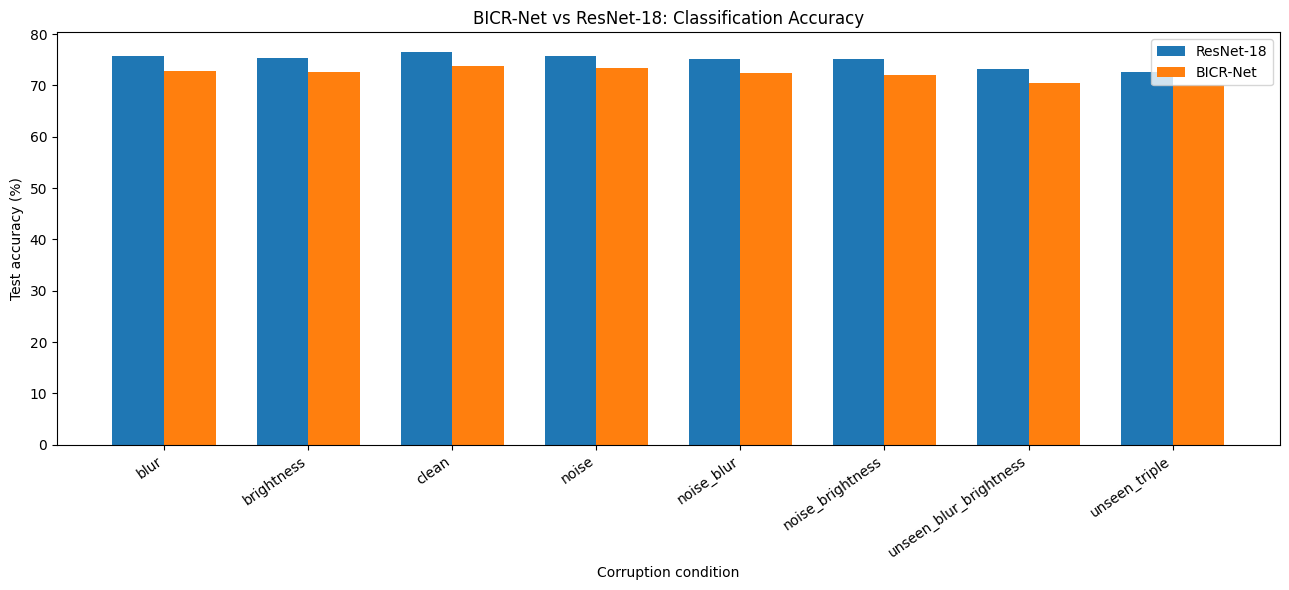

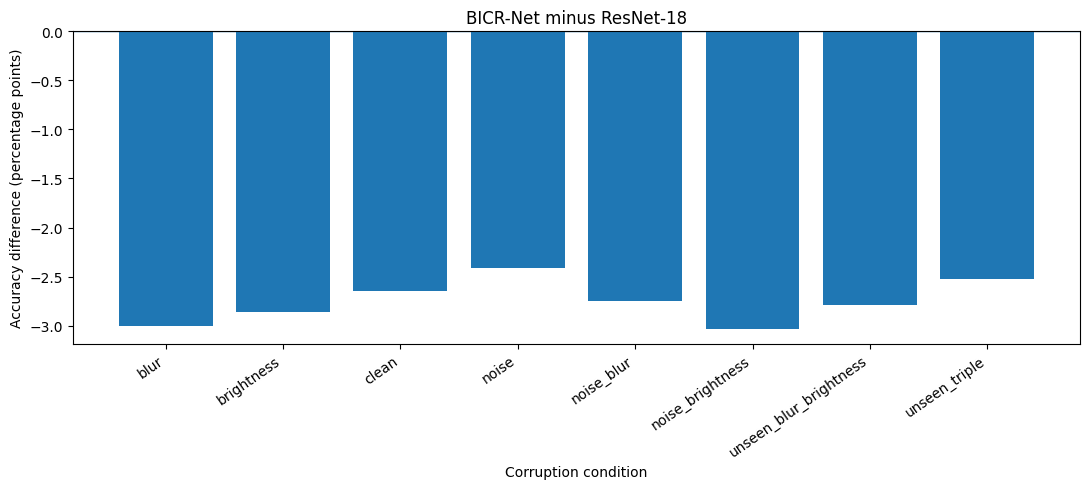

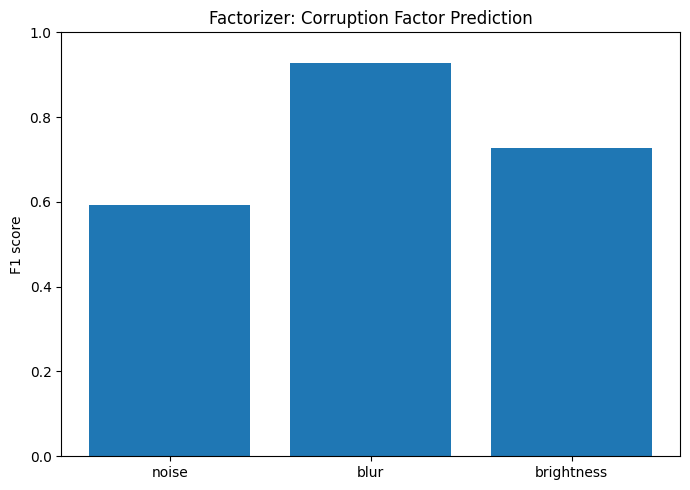


FINAL EVALUATION COMPLETED

BICR classification summary:
             condition  BICR_mean  BICR_std
                  blur     72.756     1.192
            brightness     72.586     0.993
                 clean     73.877     0.597
                 noise     73.367     0.471
            noise_blur     72.331     1.090
      noise_brightness     72.093     0.392
unseen_blur_brightness     70.497     1.164
         unseen_triple     70.166     1.198

Factorizer summary:
           precision          recall              f1        
                mean     std    mean     std    mean     std
factor                                                      
blur          0.9337  0.0428  0.9253  0.0656  0.9276  0.0217
brightness    0.7024  0.0636  0.7650  0.1009  0.7264  0.0242
noise         0.5826  0.0259  0.6038  0.0273  0.5929  0.0242

Paired seed differences:
             condition  mean_paired_difference  std_paired_difference
                  blur                  -3.006                 

In [185]:

# ================================================================
# BICR-NET: FINAL CONSOLIDATED EVALUATION
# No training. Evaluation and result generation only.
# ================================================================

import os
import glob
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support

# -------------------- CONFIGURATION -----------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RESULT_DIR = Path("/kaggle/working/BICR_Net/results")
CHECKPOINT_DIR = Path("/kaggle/working/BICR_Net/checkpoints")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 123, 2026]

BICR_CHECKPOINTS = {
    42: CHECKPOINT_DIR / "bicr_net_best.pth",
    123: CHECKPOINT_DIR / "bicr_net_seed123_best.pth",
    2026: CHECKPOINT_DIR / "bicr_net_seed2026_best.pth"
}

CONDITIONS = {
    "clean": [],
    "noise": ["noise"],
    "blur": ["blur"],
    "brightness": ["brightness"],
    "noise_brightness": ["noise", "brightness"],
    "noise_blur": ["noise", "blur"],
    "unseen_blur_brightness": ["blur", "brightness"],
    "unseen_triple": ["noise", "blur", "brightness"]
}

TEST_LOADER = BICR_FINAL_TEST_LOADER

print("Device:", DEVICE)
print("Test samples:", len(TEST_LOADER.dataset))

# -------------------- HELPER FUNCTIONS -------------------------

def load_checkpoint(path):
    if not path.exists():
        raise FileNotFoundError(f"Missing checkpoint: {path}")

    checkpoint = torch.load(
        path, map_location=DEVICE, weights_only=False
    )

    state = checkpoint.get("model_state_dict", checkpoint)

    # Handle DataParallel checkpoints if present.
    if any(k.startswith("module.") for k in state):
        state = {
            k.replace("module.", "", 1): v
            for k, v in state.items()
        }

    model = BICRNet(num_classes=10).to(DEVICE)
    model.load_state_dict(state, strict=True)
    model.eval()

    return model


def get_logits(output):
    if isinstance(output, dict):
        for key in ["final_logits", "logits", "output"]:
            if key in output:
                return output[key]
        raise KeyError("Could not find classification logits.")

    if isinstance(output, (tuple, list)):
        return output[0]

    return output


def evaluate_classification(model, loader, condition, seed):
    correct = 0
    total = 0

    # Same corruption realization across BICR seeds
    condition_index = list(CONDITIONS).index(condition)
    torch.manual_seed(9000 + condition_index)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(9000 + condition_index)

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            corrupted = bicr_fixed_corruption(
                images, CONDITIONS[condition]
            )

            logits = get_logits(model(corrupted))
            predictions = logits.argmax(dim=1)

            correct += predictions.eq(labels).sum().item()
            total += labels.size(0)

    return {
        "seed": seed,
        "condition": condition,
        "correct": correct,
        "total": total,
        "accuracy": 100.0 * correct / total
    }


# -------------------- 1. BICR CLASSIFICATION -------------------

print("\n1. Evaluating BICR-Net checkpoints...")

bicr_rows = []
loaded_models = {}

for seed in SEEDS:
    print(f"\nLoading BICR-Net seed {seed}")

    model = load_checkpoint(BICR_CHECKPOINTS[seed])
    loaded_models[seed] = model

    for condition in CONDITIONS:
        result = evaluate_classification(
            model, TEST_LOADER, condition, seed
        )
        bicr_rows.append(result)

        print(
            f"Seed {seed} | {condition}: "
            f"{result['accuracy']:.3f}%"
        )

bicr_df = pd.DataFrame(bicr_rows)

bicr_df.to_csv(
    RESULT_DIR / "FINAL_BICR_three_seed_results.csv",
    index=False
)

bicr_summary = (
    bicr_df.groupby("condition")["accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

bicr_summary.columns = [
    "condition", "BICR_mean", "BICR_std"
]

# -------------------- 2. FACTORIZER EVALUATION -----------------

print("\n2. Evaluating factorizer predictions...")

factor_rows = []

for seed in SEEDS:
    model = loaded_models[seed]
    model.eval()

    # Reproducible synthetic corruption samples
    random.seed(777)
    torch.manual_seed(777)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(777)

    tp = np.zeros(3)
    fp = np.zeros(3)
    fn = np.zeros(3)

    severity_abs_error = 0.0
    severity_count = 0
    exact_match_correct = 0
    sample_count = 0

    with torch.inference_mode():
        for images, labels in TEST_LOADER:
            images = images.to(DEVICE, non_blocking=True)

            # Generate corruption images and ground-truth targets
            corrupted, factor_targets, severity_targets = (
                bicr_training_corruptions(images)
            )

            features = model.encoder(corrupted)
            features = torch.flatten(features, 1)

            factor_logits, severity_pred, factor_probs, tokens = (
                model.factorizer(features)
            )

            targets = factor_targets.bool()
            predictions = factor_probs >= 0.5

            tp += (predictions & targets).sum(dim=0).cpu().numpy()
            fp += (predictions & ~targets).sum(dim=0).cpu().numpy()
            fn += (~predictions & targets).sum(dim=0).cpu().numpy()

            # Exact multi-label match
            exact_match_correct += (
                predictions == targets
            ).all(dim=1).sum().item()

            sample_count += targets.size(0)

            # Severity error only where a factor is present
            active = targets

            if active.any():
                errors = (
                    severity_pred - severity_targets
                ).abs()

                severity_abs_error += (
                    errors * active.float()
                ).sum().item()

                severity_count += active.sum().item()

    precision = tp / np.maximum(tp + fp, 1)
    recall = tp / np.maximum(tp + fn, 1)
    f1 = (
        2 * precision * recall /
        np.maximum(precision + recall, 1e-12)
    )

    factor_names = ["noise", "blur", "brightness"]

    for i, name in enumerate(factor_names):
        factor_rows.append({
            "seed": seed,
            "factor": name,
            "precision": precision[i],
            "recall": recall[i],
            "f1": f1[i],
            "true_positive": int(tp[i]),
            "false_positive": int(fp[i]),
            "false_negative": int(fn[i])
        })

    print(f"\nSeed {seed}")
    print("Factor precision:", np.round(precision, 4))
    print("Factor recall:", np.round(recall, 4))
    print("Factor F1:", np.round(f1, 4))
    print(
        "Exact match accuracy:",
        round(100 * exact_match_correct / sample_count, 3), "%"
    )
    print(
        "Severity MAE:",
        round(severity_abs_error / max(severity_count, 1), 5)
    )

factor_df = pd.DataFrame(factor_rows)

factor_df.to_csv(
    RESULT_DIR / "FINAL_factorizer_performance.csv",
    index=False
)

factor_summary = (
    factor_df.groupby("factor")[["precision", "recall", "f1"]]
    .agg(["mean", "std"])
)

factor_summary.to_csv(
    RESULT_DIR / "FINAL_factorizer_mean_std.csv"
)

# -------------------- 3. MERGE RESNET BASELINE -----------------

print("\n3. Combining verified ResNet-18 results...")

baseline_path = (
    RESULT_DIR / "resnet18_cosine_control_three_seeds.csv"
)

if not baseline_path.exists():
    raise FileNotFoundError(
        "Verified ResNet-18 three-seed CSV is missing."
    )

baseline_df = pd.read_csv(baseline_path)

baseline_summary = (
    baseline_df.groupby("condition")["accuracy_percent"]
    .agg(["mean", "std"])
    .reset_index()
)

baseline_summary.columns = [
    "condition", "ResNet18_mean", "ResNet18_std"
]

comparison = bicr_summary.merge(
    baseline_summary,
    on="condition",
    how="inner"
)

comparison["BICR_minus_ResNet18"] = (
    comparison["BICR_mean"] - comparison["ResNet18_mean"]
)

comparison["BICR_std"] = comparison["BICR_std"].fillna(0)
comparison["ResNet18_std"] = comparison["ResNet18_std"].fillna(0)

comparison.to_csv(
    RESULT_DIR / "FINAL_BICR_vs_ResNet18_comparison.csv",
    index=False
)

print("\nFINAL CLASSIFICATION COMPARISON")
print(comparison.round(3).to_string(index=False))

# -------------------- 4. PAIRED SEED DIFFERENCES ---------------

paired = bicr_df.merge(
    baseline_df[["seed", "condition", "accuracy_percent"]],
    on=["seed", "condition"],
    how="inner"
)

paired["difference"] = (
    paired["accuracy"] - paired["accuracy_percent"]
)

paired_summary = (
    paired.groupby("condition")["difference"]
    .agg(["mean", "std"])
    .reset_index()
)

paired_summary.columns = [
    "condition", "mean_paired_difference", "std_paired_difference"
]

paired_summary.to_csv(
    RESULT_DIR / "FINAL_paired_seed_differences.csv",
    index=False
)

# -------------------- 5. PUBLICATION FIGURES -------------------

plot_df = comparison.copy()

x = np.arange(len(plot_df))
width = 0.36

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    plot_df["ResNet18_mean"],
    width,
    label="ResNet-18"
)

plt.bar(
    x + width / 2,
    plot_df["BICR_mean"],
    width,
    label="BICR-Net"
)

plt.xticks(
    x,
    plot_df["condition"],
    rotation=35,
    ha="right"
)

plt.ylabel("Test accuracy (%)")
plt.xlabel("Corruption condition")
plt.title("BICR-Net vs ResNet-18: Classification Accuracy")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "FIGURE_1_accuracy_comparison.png",
    dpi=300
)
plt.show()


plt.figure(figsize=(11, 5))

plt.bar(
    np.arange(len(plot_df)),
    plot_df["BICR_minus_ResNet18"]
)

plt.axhline(0, linewidth=1)
plt.xticks(
    np.arange(len(plot_df)),
    plot_df["condition"],
    rotation=35,
    ha="right"
)

plt.ylabel("Accuracy difference (percentage points)")
plt.xlabel("Corruption condition")
plt.title("BICR-Net minus ResNet-18")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "FIGURE_2_accuracy_difference.png",
    dpi=300
)
plt.show()


factor_plot = (
    factor_df.groupby("factor")["f1"]
    .mean()
    .reindex(["noise", "blur", "brightness"])
)

plt.figure(figsize=(7, 5))
plt.bar(factor_plot.index, factor_plot.values)
plt.ylim(0, 1)
plt.ylabel("F1 score")
plt.title("Factorizer: Corruption Factor Prediction")
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "FIGURE_3_factorizer_f1.png",
    dpi=300
)
plt.show()

# -------------------- 6. FINAL SUMMARY -------------------------

print("\n" + "=" * 70)
print("FINAL EVALUATION COMPLETED")
print("=" * 70)

print("\nBICR classification summary:")
print(bicr_summary.round(3).to_string(index=False))

print("\nFactorizer summary:")
print(factor_summary.round(4))

print("\nPaired seed differences:")
print(paired_summary.round(3).to_string(index=False))

print("\nFiles saved in:", RESULT_DIR)

for file in sorted(RESULT_DIR.glob("FINAL_*")):
    print(file.name)

for file in sorted(RESULT_DIR.glob("FIGURE_*.png")):
    print(file.name)

print("\nNO TRAINING WAS PERFORMED.")
print("FINAL EVALUATION COMPLETE.")


In [186]:

# ================================================================
# BICR-NET: FINAL RESEARCH CLAIM VALIDATION
# Interaction ablation + unseen factorizer + efficiency
# No training performed
# ================================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.models import resnet18

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("/kaggle/working/BICR_Net/results")
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 123, 2026]
BICR_CKPTS = {
    42: "/kaggle/working/BICR_Net/checkpoints/bicr_net_best.pth",
    123: "/kaggle/working/BICR_Net/checkpoints/bicr_net_seed123_best.pth",
    2026: "/kaggle/working/BICR_Net/checkpoints/bicr_net_seed2026_best.pth"
}

RESNET_CKPT = (
    "/kaggle/working/BICR_Net/checkpoints/"
    "resnet18_cosine_control_seed42.pth"
)

UNSEEN = {
    "unseen_blur_brightness": ["blur", "brightness"],
    "unseen_triple": ["noise", "blur", "brightness"]
}

ALL_CONDITIONS = {
    "clean": [],
    "noise": ["noise"],
    "blur": ["blur"],
    "brightness": ["brightness"],
    "noise_brightness": ["noise", "brightness"],
    "noise_blur": ["noise", "blur"],
    **UNSEEN
}

def load_state(path):
    ckpt = torch.load(
        path, map_location=DEVICE, weights_only=False
    )
    return ckpt.get("model_state_dict", ckpt)

def load_bicr(seed):
    model = BICRNet(num_classes=10).to(DEVICE)
    model.load_state_dict(load_state(BICR_CKPTS[seed]), strict=True)
    return model.eval()

def logits_of(output):
    if isinstance(output, dict):
        return output.get("final_logits", output.get("logits"))
    if isinstance(output, (tuple, list)):
        return output[0]
    return output

def make_resnet():
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)
    model.load_state_dict(load_state(RESNET_CKPT), strict=True)
    return model.to(DEVICE).eval()

# ================================================================
# 1. INTERACTION ABLATION
# ================================================================

print("\n1. INTERACTION MODULE ABLATION")

interaction_rows = []

for seed in SEEDS:
    model = load_bicr(seed)

    for condition, combo in ALL_CONDITIONS.items():
        torch.manual_seed(5000 + list(ALL_CONDITIONS).index(condition))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                5000 + list(ALL_CONDITIONS).index(condition)
            )

        correct_on = 0
        correct_off = 0
        total = 0

        with torch.inference_mode():
            for images, labels in BICR_FINAL_TEST_LOADER:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                corrupted = bicr_fixed_corruption(images, combo)

                output_on = logits_of(
                    model(corrupted, disable_interaction=False)
                )
                output_off = logits_of(
                    model(corrupted, disable_interaction=True)
                )

                correct_on += (
                    output_on.argmax(1) == labels
                ).sum().item()

                correct_off += (
                    output_off.argmax(1) == labels
                ).sum().item()

                total += labels.size(0)

        acc_on = 100 * correct_on / total
        acc_off = 100 * correct_off / total

        interaction_rows.append({
            "seed": seed,
            "condition": condition,
            "interaction_enabled": acc_on,
            "interaction_disabled": acc_off,
            "difference_pp": acc_on - acc_off
        })

        print(
            seed, condition,
            "enabled:", round(acc_on, 3),
            "disabled:", round(acc_off, 3),
            "difference:", round(acc_on - acc_off, 3)
        )

interaction_df = pd.DataFrame(interaction_rows)
interaction_df.to_csv(
    OUT / "FINAL_interaction_ablation.csv", index=False
)

interaction_summary = (
    interaction_df.groupby("condition")["difference_pp"]
    .agg(["mean", "std"]).reset_index()
)
interaction_summary.to_csv(
    OUT / "FINAL_interaction_ablation_summary.csv", index=False
)

# ================================================================
# 2. FACTORIZER ON UNSEEN COMBINATIONS
# ================================================================

print("\n2. FACTORIZER UNSEEN-COMBINATION EVALUATION")

factor_rows = []

for seed in SEEDS:
    model = load_bicr(seed)

    for condition, combo in UNSEEN.items():
        torch.manual_seed(7000 + list(UNSEEN).index(condition))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                7000 + list(UNSEEN).index(condition)
            )

        tp = np.zeros(3)
        fp = np.zeros(3)
        fn = np.zeros(3)
        severity_error = 0.0
        severity_count = 0
        exact = 0
        total = 0

        target = torch.zeros(3, device=DEVICE)
        for name in combo:
            target[["noise", "blur", "brightness"].index(name)] = 1.0

        target_batch = None

        with torch.inference_mode():
            for images, labels in BICR_FINAL_TEST_LOADER:
                images = images.to(DEVICE)

                corrupted = bicr_fixed_corruption(images, combo)

                features = model.encoder(corrupted)
                features = torch.flatten(features, 1)

                factor_logits, severity, factor_probs, tokens = (
                    model.factorizer(features)
                )

                targets = target.unsqueeze(0).expand(
                    images.size(0), -1
                ).bool()

                predictions = factor_probs >= 0.5

                tp += (predictions & targets).sum(0).cpu().numpy()
                fp += (predictions & ~targets).sum(0).cpu().numpy()
                fn += (~predictions & targets).sum(0).cpu().numpy()

                exact += (
                    (predictions == targets).all(1).sum().item()
                )
                total += images.size(0)

                active = targets
                severity_error += (
                    (severity - 1.0).abs() * active.float()
                ).sum().item()
                severity_count += active.sum().item()

        precision = tp / np.maximum(tp + fp, 1)
        recall = tp / np.maximum(tp + fn, 1)
        f1 = (
            2 * precision * recall /
            np.maximum(precision + recall, 1e-12)
        )

        for i, name in enumerate(
            ["noise", "blur", "brightness"]
        ):
            factor_rows.append({
                "seed": seed,
                "condition": condition,
                "factor": name,
                "precision": precision[i],
                "recall": recall[i],
                "f1": f1[i],
                "exact_match_accuracy": 100 * exact / total,
                "severity_mae": (
                    severity_error / max(severity_count, 1)
                )
            })

        print(
            f"Seed {seed} | {condition} | "
            f"Exact match: {100*exact/total:.3f}% | "
            f"Severity MAE: "
            f"{severity_error/max(severity_count,1):.5f}"
        )

factor_unseen_df = pd.DataFrame(factor_rows)

factor_unseen_df.to_csv(
    OUT / "FINAL_factorizer_unseen.csv", index=False
)

factor_unseen_summary = (
    factor_unseen_df.groupby(["condition", "factor"])
    [["precision", "recall", "f1",
      "exact_match_accuracy", "severity_mae"]]
    .mean().reset_index()
)

factor_unseen_summary.to_csv(
    OUT / "FINAL_factorizer_unseen_summary.csv", index=False
)

# ================================================================
# 3. COMPUTATIONAL EFFICIENCY
# ================================================================

print("\n3. COMPUTATIONAL EFFICIENCY")

def benchmark(model, batch_size, warmup=20, iterations=80):
    model.eval()
    x = torch.randn(
        batch_size, 3, 160, 160, device=DEVICE
    )

    with torch.inference_mode():
        for _ in range(warmup):
            model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = torch.cuda.Event(enable_timing=True) if DEVICE.type == "cuda" else None
        end = torch.cuda.Event(enable_timing=True) if DEVICE.type == "cuda" else None

        if DEVICE.type == "cuda":
            start.record()
            for _ in range(iterations):
                model(x)
            end.record()
            torch.cuda.synchronize()
            total_ms = start.elapsed_time(end)
        else:
            import time
            t0 = time.perf_counter()
            for _ in range(iterations):
                model(x)
            total_ms = (time.perf_counter() - t0) * 1000

    latency = total_ms / iterations
    throughput = batch_size * 1000 / latency

    return latency, throughput

bicr = load_bicr(42)
resnet = make_resnet()

efficiency_rows = []

for name, model in [
    ("BICR-Net", bicr),
    ("ResNet-18", resnet)
]:
    params = sum(p.numel() for p in model.parameters())

    for batch_size in [1, 8]:
        latency, throughput = benchmark(model, batch_size)

        efficiency_rows.append({
            "model": name,
            "batch_size": batch_size,
            "parameters_M": params / 1e6,
            "latency_ms_per_batch": latency,
            "throughput_images_per_second": throughput
        })

        print(
            name, "batch", batch_size,
            "| Params M:", round(params / 1e6, 3),
            "| Latency ms:", round(latency, 4),
            "| Throughput:", round(throughput, 2)
        )

efficiency_df = pd.DataFrame(efficiency_rows)
efficiency_df.to_csv(
    OUT / "FINAL_efficiency_benchmark.csv", index=False
)

# ================================================================
# 4. FINAL RESEARCH CLAIM REPORT
# ================================================================

print("\n" + "=" * 70)
print("FINAL RESEARCH CLAIM VALIDATION")
print("=" * 70)

print("\nINTERACTION ABLATION SUMMARY")
print(interaction_summary.round(4).to_string(index=False))

print("\nUNSEEN FACTORIZER SUMMARY")
print(factor_unseen_summary.round(4).to_string(index=False))

print("\nEFFICIENCY SUMMARY")
print(efficiency_df.round(4).to_string(index=False))

print("\nSaved result files:")
for p in sorted(OUT.glob("FINAL_*.csv")):
    print(p.name)

print("\nEVALUATION FINISHED — NO TRAINING PERFORMED")



1. INTERACTION MODULE ABLATION
42 clean enabled: 74.115 disabled: 74.115 difference: 0.0
42 noise enabled: 73.605 disabled: 73.605 difference: 0.0
42 blur enabled: 73.58 disabled: 73.58 difference: 0.0
42 brightness enabled: 72.331 disabled: 72.331 difference: 0.0
42 noise_brightness enabled: 71.873 disabled: 71.924 difference: -0.051
42 noise_blur enabled: 73.045 disabled: 73.045 difference: 0.0
42 unseen_blur_brightness enabled: 71.72 disabled: 71.72 difference: 0.0
42 unseen_triple enabled: 71.465 disabled: 71.439 difference: 0.025
123 clean enabled: 74.318 disabled: 74.318 difference: 0.0
123 noise enabled: 73.045 disabled: 73.121 difference: -0.076
123 blur enabled: 73.299 disabled: 73.325 difference: -0.025
123 brightness enabled: 73.682 disabled: 73.707 difference: -0.025
123 noise_brightness enabled: 72.433 disabled: 72.331 difference: 0.102
123 noise_blur enabled: 72.662 disabled: 72.662 difference: 0.0
123 unseen_blur_brightness enabled: 70.369 disabled: 70.369 difference: 0

In [187]:

import pandas as pd
import numpy as np

# Latest BICR-Net results from the final audit
results = {
    42: {
        "clean": 74.115, "noise": 73.605, "blur": 73.580,
        "brightness": 72.331, "noise_blur": 73.045,
        "noise_brightness": 71.873,
        "blur_brightness": 71.720, "triple": 71.465
    },
    123: {
        "clean": 74.318, "noise": 73.045, "blur": 73.299,
        "brightness": 73.682, "noise_blur": 72.662,
        "noise_brightness": 72.433,
        "blur_brightness": 70.369, "triple": 69.783
    },
    2026: {
        "clean": 73.197, "noise": 72.815, "blur": 71.389,
        "brightness": 71.745, "noise_blur": 70.369,
        "noise_brightness": 71.694,
        "blur_brightness": 69.401, "triple": 69.096
    }
}

rows = []

for seed, r in results.items():
    clean = r["clean"]

    # Pairwise interaction scores
    pairs = [
        ("Noise + Blur", "noise_blur", "noise", "blur"),
        ("Noise + Brightness", "noise_brightness",
         "noise", "brightness"),
        ("Blur + Brightness", "blur_brightness",
         "blur", "brightness")
    ]

    for name, combined, a, b in pairs:
        interaction = (
            r[combined] - r[a] - r[b] + clean
        )

        rows.append({
            "seed": seed,
            "interaction": name,
            "interaction_score": interaction
        })

    # Three-way higher-order interaction
    triple_interaction = (
        r["triple"]
        - r["noise_blur"]
        - r["noise_brightness"]
        - r["blur_brightness"]
        + r["noise"]
        + r["blur"]
        + r["brightness"]
        - clean
    )

    rows.append({
        "seed": seed,
        "interaction": "Three-way interaction",
        "interaction_score": triple_interaction
    })

df = pd.DataFrame(rows)

summary = (
    df.groupby("interaction")["interaction_score"]
    .agg(["mean", "std"])
    .reset_index()
)

print("PER-SEED INTERACTION SCORES")
print(df.round(4).to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")
print(summary.round(4).to_string(index=False))

df.to_csv("FINAL_compositional_interaction_per_seed.csv",
          index=False)
summary.to_csv("FINAL_compositional_interaction_summary.csv",
               index=False)

print("\nInteraction analysis completed.")


PER-SEED INTERACTION SCORES
 seed           interaction  interaction_score
   42          Noise + Blur             -0.025
   42    Noise + Brightness              0.052
   42     Blur + Brightness             -0.076
   42 Three-way interaction              0.228
  123          Noise + Blur              0.636
  123    Noise + Brightness              0.024
  123     Blur + Brightness             -2.294
  123 Three-way interaction              0.027
 2026          Noise + Blur             -0.638
 2026    Noise + Brightness              0.331
 2026     Blur + Brightness             -0.536
 2026 Three-way interaction              0.384

MEAN AND STANDARD DEVIATION
          interaction    mean    std
    Blur + Brightness -0.9687 1.1706
         Noise + Blur -0.0090 0.6372
   Noise + Brightness  0.1357 0.1697
Three-way interaction  0.2130 0.1790

Interaction analysis completed.


In [188]:

import os
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

# Kaggle working directory
WORK_DIR = Path("/kaggle/working")

# Backup destination
BACKUP_PATH = WORK_DIR / "BICR_Net_COMPLETE_RESEARCH_BACKUP.zip"

print("=" * 65)
print("BICR-NET COMPLETE RESEARCH BACKUP")
print("=" * 65)

# List all files before backup
all_files = [
    p for p in WORK_DIR.rglob("*")
    if p.is_file() and p != BACKUP_PATH
]

print(f"\nTotal files found: {len(all_files)}")

# Create ZIP
with zipfile.ZipFile(
    BACKUP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in all_files:
        archive.write(
            file_path,
            arcname=file_path.relative_to(WORK_DIR)
        )

# Verify archive
with zipfile.ZipFile(BACKUP_PATH, "r") as archive:
    bad_file = archive.testzip()
    archived_files = archive.namelist()

print("\nBACKUP VERIFICATION")
print("ZIP integrity:", "PASSED" if bad_file is None else "FAILED")
print("Files archived:", len(archived_files))
print(
    "Backup size:",
    round(BACKUP_PATH.stat().st_size / (1024 ** 2), 2),
    "MB"
)

print("\nARCHIVED FILES:")
for name in archived_files:
    print(" -", name)

print("\nDOWNLOAD YOUR COMPLETE BACKUP:")
display(FileLink(str(BACKUP_PATH)))


BICR-NET COMPLETE RESEARCH BACKUP

Total files found: 26564


KeyboardInterrupt: 

In [189]:

import os
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

WORK_DIR = Path("/kaggle/working")
ZIP_PATH = WORK_DIR / "BICR_NET_ALL_RESEARCH_RESULTS.zip"

# Research artifact extensions
extensions = {
    ".csv", ".json", ".txt", ".log",
    ".pth", ".pt", ".ckpt",
    ".pkl", ".joblib",
    ".npy", ".npz",
    ".xlsx", ".pdf",
    ".py", ".yaml", ".yml", ".md"
}

# Include image files only when they look like research plots
plot_words = [
    "plot", "curve", "confusion", "matrix",
    "accuracy", "loss", "graph", "result",
    "performance", "comparison", "heatmap"
]

# Exclude common dataset/cache directories
excluded_parts = {
    "dataset", "datasets", "images", "train",
    "validation", "test", "cache", ".venv",
    "__pycache__"
}

selected = []

for p in WORK_DIR.rglob("*"):
    if not p.is_file() or p == ZIP_PATH:
        continue

    relative_parts = {part.lower() for part in p.relative_to(WORK_DIR).parts}

    if relative_parts & excluded_parts:
        continue

    suffix = p.suffix.lower()
    name = p.name.lower()

    if suffix in extensions:
        selected.append(p)
    elif suffix in {".png", ".jpg", ".jpeg"}:
        if any(word in name for word in plot_words):
            selected.append(p)

# Create results archive
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for p in selected:
        z.write(p, arcname=p.relative_to(WORK_DIR))

# Verify
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    bad = z.testzip()
    names = z.namelist()

print("=" * 60)
print("BICR-NET RESEARCH RESULTS BACKUP")
print("=" * 60)
print("Files collected:", len(selected))
print("ZIP integrity:", "PASSED" if bad is None else "FAILED")
print("ZIP size:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")

print("\nINCLUDED FILES:")
for name in names:
    print(name)

print("\nDOWNLOAD YOUR RESEARCH RESULTS:")
display(FileLink(str(ZIP_PATH)))


KeyboardInterrupt: 

In [190]:

import os
import zipfile
from pathlib import Path
from IPython.display import FileLink, display

WORK = Path("/kaggle/working")
ZIP = WORK / "BICR_NET_FINAL_BACKUP.zip"

# Important research result files
important_files = [
    "FINAL_BICR_three_seed_results.csv",
    "FINAL_BICR_vs_ResNet18_comparison.csv",
    "FINAL_efficiency_benchmark.csv",
    "FINAL_factorizer_mean_std.csv",
    "FINAL_factorizer_performance.csv",
    "FINAL_factorizer_unseen.csv",
    "FINAL_factorizer_unseen_summary.csv",
    "FINAL_interaction_ablation.csv",
    "FINAL_interaction_ablation_summary.csv",
    "FINAL_paired_seed_differences.csv",
    "FINAL_compositional_interaction_per_seed.csv",
    "FINAL_compositional_interaction_summary.csv",
]

# Locate checkpoints and scripts without including datasets
selected = []

for p in WORK.rglob("*"):
    if not p.is_file() or p == ZIP:
        continue

    parts = {x.lower() for x in p.relative_to(WORK).parts}

    if parts & {
        "dataset", "datasets", "images", "train",
        "test", "validation", "cache", "__pycache__"
    }:
        continue

    name = p.name.lower()

    if p.name in important_files:
        selected.append(p)
    elif p.suffix.lower() in {".pth", ".pt", ".ckpt"}:
        selected.append(p)
    elif p.suffix.lower() in {".py", ".json", ".log", ".txt"}:
        if any(x in name for x in ["bicr", "resnet", "train", "config", "experiment"]):
            selected.append(p)

selected = list(dict.fromkeys(selected))

print("Files selected:", len(selected))

# No compression: much faster
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_STORED) as z:
    for i, p in enumerate(selected, 1):
        z.write(p, p.relative_to(WORK))
        if i % 10 == 0:
            print(f"Added {i}/{len(selected)} files")

print("\nBackup created:", ZIP)
print("Size (MB):", round(ZIP.stat().st_size / 1024**2, 2))

with zipfile.ZipFile(ZIP) as z:
    print("Verification:", "PASSED" if z.testzip() is None else "FAILED")
    print("\nIncluded files:")
    for name in z.namelist():
        print(name)

print("\nCLICK TO DOWNLOAD:")
display(FileLink(str(ZIP)))


Files selected: 71
Added 10/71 files
Added 20/71 files
Added 30/71 files
Added 40/71 files


OSError: [Errno 28] No space left on device

In [191]:

from pathlib import Path
import shutil

WORK = Path("/kaggle/working")

# Remove only the backup archives created in our previous attempts
backup_names = [
    "BICR_Net_COMPLETE_RESEARCH_BACKUP.zip",
    "BICR_NET_ALL_RESEARCH_RESULTS.zip",
    "BICR_NET_FINAL_BACKUP.zip"
]

for name in backup_names:
    p = WORK / name
    if p.exists():
        size = p.stat().st_size / (1024**3)
        p.unlink()
        print(f"Removed {name} ({size:.2f} GB)")

total, used, free = shutil.disk_usage(WORK)

print("\nAvailable Kaggle storage:")
print(f"Free: {free / (1024**3):.2f} GB")


Removed BICR_Net_COMPLETE_RESEARCH_BACKUP.zip (5.34 GB)
Removed BICR_NET_ALL_RESEARCH_RESULTS.zip (0.78 GB)
Removed BICR_NET_FINAL_BACKUP.zip (3.80 GB)

Available Kaggle storage:
Free: 4.58 GB


In [192]:

from pathlib import Path

WORK = Path("/kaggle/working")

print("=== MODEL CHECKPOINTS ===")
for p in WORK.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".pth", ".pt", ".ckpt"]:
        print(p.name, round(p.stat().st_size / (1024**2), 2), "MB")
        print("Path:", p)

print("\n=== FINAL CSV RESULTS ===")
for p in WORK.rglob("FINAL_*.csv"):
    print(p.name, round(p.stat().st_size / 1024, 2), "KB")
    print("Path:", p)


=== MODEL CHECKPOINTS ===
ddaf_latest.pth 291.86 MB
Path: /kaggle/working/checkpoints/ddaf_latest.pth
ddaf_best.pth 291.86 MB
Path: /kaggle/working/checkpoints/ddaf_best.pth
ddaf_latest.pth 291.86 MB
Path: /kaggle/working/ddaf_training/ddaf_latest.pth
ddaf_best.pth 291.86 MB
Path: /kaggle/working/ddaf_training/ddaf_best.pth
resnet18_pretrained_best.pth 128.09 MB
Path: /kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_best.pth
resnet18_pretrained_latest.pth 128.1 MB
Path: /kaggle/working/resnet18_pretrained_baseline/resnet18_pretrained_latest.pth
resnet18_latest.pth 128.09 MB
Path: /kaggle/working/resnet18_baseline/resnet18_latest.pth
resnet18_best.pth 128.09 MB
Path: /kaggle/working/resnet18_baseline/resnet18_best.pth
bicr_net_final_state.pth 44.82 MB
Path: /kaggle/working/BICR_Net/checkpoints/bicr_net_final_state.pth
resnet18_matched_corruption_control_seed42.pth 42.73 MB
Path: /kaggle/working/BICR_Net/checkpoints/resnet18_matched_corruption_control_seed42.pth
resnet18_

In [193]:

from pathlib import Path
from IPython.display import display, FileLink, Markdown

base = Path("/kaggle/working/BICR_Net")

# Six essential checkpoints
checkpoints = [
    base / "checkpoints/bicr_net_best.pth",
    base / "checkpoints/bicr_net_seed123_best.pth",
    base / "checkpoints/bicr_net_seed2026_best.pth",
    base / "checkpoints/resnet18_cosine_control_seed42.pth",
    base / "checkpoints/resnet18_cosine_control_seed123.pth",
    base / "checkpoints/resnet18_cosine_control_seed2026.pth",
]

# Additional BICR-Net checkpoint files worth preserving
extra_checkpoints = [
    base / "checkpoints/bicr_net_final.pth",
    base / "checkpoints/bicr_net_final_state.pth",
    base / "checkpoints/bicr_net_last.pth",
]

# All final result CSV files
results = [
    base / "results/FINAL_BICR_three_seed_results.csv",
    base / "results/FINAL_BICR_vs_ResNet18_comparison.csv",
    base / "results/FINAL_efficiency_benchmark.csv",
    base / "results/FINAL_factorizer_mean_std.csv",
    base / "results/FINAL_factorizer_performance.csv",
    base / "results/FINAL_factorizer_unseen.csv",
    base / "results/FINAL_factorizer_unseen_summary.csv",
    base / "results/FINAL_interaction_ablation.csv",
    base / "results/FINAL_interaction_ablation_summary.csv",
    base / "results/FINAL_paired_seed_differences.csv",
    Path("/kaggle/working/FINAL_compositional_interaction_per_seed.csv"),
    Path("/kaggle/working/FINAL_compositional_interaction_summary.csv"),
]

def show_downloads(title, files):
    display(Markdown("## " + title))
    for p in files:
        if p.exists():
            size = p.stat().st_size / (1024**2)
            print(f"{p.name} — {size:.2f} MB")
            display(FileLink(str(p)))
        else:
            print("MISSING:", p)

show_downloads("1. ESSENTIAL MODEL CHECKPOINTS", checkpoints)
show_downloads("2. ADDITIONAL BICR CHECKPOINTS", extra_checkpoints)
show_downloads("3. FINAL EXPERIMENTAL RESULTS", results)


## 1. ESSENTIAL MODEL CHECKPOINTS

bicr_net_best.pth — 44.82 MB


/kaggle/working/BICR_Net/checkpoints/bicr_net_best.pth

bicr_net_seed123_best.pth — 44.82 MB


/kaggle/working/BICR_Net/checkpoints/bicr_net_seed123_best.pth

bicr_net_seed2026_best.pth — 44.82 MB


... (35 outputs left out)

FINAL_compositional_interaction_per_seed.csv — 0.00 MB


/kaggle/working/FINAL_compositional_interaction_per_seed.csv

FINAL_compositional_interaction_summary.csv — 0.00 MB


/kaggle/working/FINAL_compositional_interaction_summary.csv

In [194]:

import os
from pathlib import Path
from IPython.display import display, FileLink

os.chdir("/kaggle/working")

files = [
    "BICR_Net/results/FINAL_BICR_three_seed_results.csv",
    "BICR_Net/results/FINAL_BICR_vs_ResNet18_comparison.csv",
    "BICR_Net/checkpoints/bicr_net_best.pth",
]

for name in files:
    p = Path(name)
    if p.exists():
        print("Download:", name)
        display(FileLink(name))
    else:
        print("Missing:", name)


Download: BICR_Net/results/FINAL_BICR_three_seed_results.csv


/kaggle/working/BICR_Net/results/FINAL_BICR_three_seed_results.csv

Download: BICR_Net/results/FINAL_BICR_vs_ResNet18_comparison.csv


/kaggle/working/BICR_Net/results/FINAL_BICR_vs_ResNet18_comparison.csv

Download: BICR_Net/checkpoints/bicr_net_best.pth


/kaggle/working/BICR_Net/checkpoints/bicr_net_best.pth

In [195]:

import os
from pathlib import Path
from IPython.display import display, FileLink, Markdown

os.chdir("/kaggle/working")

ROOT = Path("BICR_Net")

# Skip datasets and temporary/cache folders
excluded = {
    "dataset", "datasets", "images", "train",
    "test", "validation", "cache", "__pycache__"
}

# Files already downloaded in the previous step
already_downloaded = {
    "bicr_net_best.pth",
    "bicr_net_seed123_best.pth",
    "bicr_net_seed2026_best.pth",
    "resnet18_cosine_control_seed42.pth",
    "resnet18_cosine_control_seed123.pth",
    "resnet18_cosine_control_seed2026.pth"
}

files = []

for p in ROOT.rglob("*"):
    if not p.is_file():
        continue

    if any(part.lower() in excluded for part in p.parts):
        continue

    if p.name in already_downloaded:
        continue

    files.append(p)

# Include final analysis CSVs stored outside BICR_Net
for p in Path(".").glob("FINAL_compositional_interaction_*.csv"):
    files.append(p)

files = sorted(set(files))

print("Remaining files:", len(files))
print("\nClick each link to download:\n")

for p in files:
    size = p.stat().st_size / (1024**2)
    print(f"{p} ({size:.2f} MB)")
    display(FileLink(str(p)))


Remaining files: 51

Click each link to download:

BICR_Net/ARCHITECTURE_AND_METHOD.md (0.00 MB)


/kaggle/working/BICR_Net/ARCHITECTURE_AND_METHOD.md

BICR_Net/RESULTS_AND_LIMITATIONS.md (0.00 MB)


/kaggle/working/BICR_Net/RESULTS_AND_LIMITATIONS.md

BICR_Net/checkpoints/bicr_net_final.pth (44.82 MB)


/kaggle/working/BICR_Net/checkpoints/bicr_net_final.pth

... (92 outputs left out)

FINAL_compositional_interaction_per_seed.csv (0.00 MB)


/kaggle/working/FINAL_compositional_interaction_per_seed.csv

FINAL_compositional_interaction_summary.csv (0.00 MB)


/kaggle/working/FINAL_compositional_interaction_summary.csv

In [196]:

import os
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

ROOT = Path("/kaggle/working")
PROJECT = ROOT / "BICR_Net"
ZIP_PATH = ROOT / "BICR_NET_COMPLETE_RESULTS.zip"

# Essential final results
required_csv = [
    "FINAL_BICR_three_seed_results.csv",
    "FINAL_BICR_vs_ResNet18_comparison.csv",
    "FINAL_efficiency_benchmark.csv",
    "FINAL_factorizer_mean_std.csv",
    "FINAL_factorizer_performance.csv",
    "FINAL_factorizer_unseen.csv",
    "FINAL_factorizer_unseen_summary.csv",
    "FINAL_interaction_ablation.csv",
    "FINAL_interaction_ablation_summary.csv",
    "FINAL_paired_seed_differences.csv",
]

# Exclude dataset and temporary folders
excluded = {
    "dataset", "datasets", "images", "train", "test",
    "validation", "cache", "__pycache__", ".venv"
}

selected = set()

# 1. Include all files from the main BICR project,
# excluding dataset and temporary directories.
for p in PROJECT.rglob("*"):
    if not p.is_file():
        continue

    relative = p.relative_to(PROJECT)
    if any(part.lower() in excluded for part in relative.parts):
        continue

    # Avoid old backup archives
    if p.suffix.lower() in {".zip", ".rar", ".7z"}:
        continue

    selected.add(p)

# 2. Include the compositional interaction results
for name in [
    "FINAL_compositional_interaction_per_seed.csv",
    "FINAL_compositional_interaction_summary.csv"
]:
    p = ROOT / name
    if p.exists():
        selected.add(p)

# 3. Ensure every essential CSV is included
missing_csv = []

for name in required_csv:
    matches = list(PROJECT.rglob(name))
    if matches:
        selected.update(matches)
    else:
        missing_csv.append(name)

# 4. Identify essential checkpoints
checkpoint_names = [
    "bicr_net_best.pth",
    "bicr_net_seed123_best.pth",
    "bicr_net_seed2026_best.pth",
    "resnet18_cosine_control_seed42.pth",
    "resnet18_cosine_control_seed123.pth",
    "resnet18_cosine_control_seed2026.pth",
]

missing_checkpoints = []

for name in checkpoint_names:
    matches = list(PROJECT.rglob(name))
    if matches:
        selected.update(matches)
    else:
        missing_checkpoints.append(name)

# 5. Build ZIP without compression to save processing time
selected = sorted(selected)

print("Files selected:", len(selected))
print("Creating research archive...")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_STORED
) as archive:

    for i, p in enumerate(selected, 1):
        archive.write(
            p,
            arcname=p.relative_to(ROOT)
        )

        if i % 10 == 0:
            print(f"Archived {i}/{len(selected)} files")

# 6. Verify archive
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    archived_names = archive.namelist()

print("\n========== BACKUP REPORT ==========")
print("Archive integrity:", "PASSED" if bad_file is None else "FAILED")
print("Files archived:", len(archived_names))
print("Archive size:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")

print("\nMissing CSV files:", missing_csv)
print("Missing essential checkpoints:", missing_checkpoints)

print("\nDownload archive:")
display(FileLink("BICR_NET_COMPLETE_RESULTS.zip"))


Files selected: 57
Creating research archive...
Archived 10/57 files
Archived 20/57 files
Archived 30/57 files
Archived 40/57 files
Archived 50/57 files

========== BACKUP REPORT ==========
Archive integrity: PASSED
Files archived: 57
Archive size: 615.65 MB

Missing CSV files: []
Missing essential checkpoints: []

Download archive:


/kaggle/working/BICR_NET_COMPLETE_RESULTS.zip

In [197]:

from pathlib import Path
import shutil

root = Path("/kaggle/working/BICR_Net")

if not root.exists():
    print("BICR_Net folder not found!")
else:
    files = [p for p in root.rglob("*") if p.is_file()]
    total = sum(p.stat().st_size for p in files)

    print("BICR-Net files:", len(files))
    print("Total size:", round(total / (1024**3), 2), "GB")

    print("\nCheckpoint files:")
    for p in root.rglob("*.pth"):
        print(
            p.relative_to(root),
            round(p.stat().st_size / (1024**2), 2),
            "MB"
        )

print("\nGit:", shutil.which("git"))
print("Git LFS:", shutil.which("git-lfs"))


BICR-Net files: 55
Total size: 0.6 GB

Checkpoint files:
checkpoints/bicr_net_final_state.pth 44.82 MB
checkpoints/resnet18_matched_corruption_control_seed42.pth 42.73 MB
checkpoints/resnet18_cosine_control_seed2026.pth 42.73 MB
checkpoints/bicr_net_seed123_best.pth 44.82 MB
checkpoints/bicr_net_last.pth 134.35 MB
checkpoints/bicr_net_seed2026_best.pth 44.82 MB
checkpoints/resnet18_matched_corruption_control_seed123.pth 42.73 MB
checkpoints/bicr_net_best.pth 44.82 MB
checkpoints/resnet18_cosine_control_seed42.pth 42.73 MB
checkpoints/resnet18_cosine_control_seed123.pth 42.73 MB
checkpoints/resnet18_matched_corruption_control_seed2026.pth 42.74 MB
checkpoints/bicr_net_final.pth 44.82 MB

Git: /usr/bin/git
Git LFS: None


In [198]:

import subprocess
import shutil
import os

print("Installing Git LFS...")

result = subprocess.run(
    ["bash", "-lc", "apt-get update -qq && apt-get install -y git-lfs"],
    capture_output=True,
    text=True
)

print(result.stdout[-2500:])
if result.returncode != 0:
    print(result.stderr[-2500:])
    raise RuntimeError("Git LFS installation failed.")

subprocess.run(["git", "lfs", "install"], check=True)

print("\nGit:", shutil.which("git"))
print("Git LFS:", shutil.which("git-lfs"))

# Check available disk space
stat = shutil.disk_usage("/kaggle/working")
print("Free disk space:", round(stat.free / (1024**3), 2), "GB")


Installing Git LFS...
Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 94 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 1s (3,783 kB/s)
Selecting previously unselected package git-lfs.
(Reading database ... 
(Reading database ... 5%
(Reading database ... 10%
(Reading database ... 15%
(Reading database ... 20%
(Reading database ... 25%
(Reading database ... 30%
(Reading database ... 35%
(Reading database ... 40%
(Reading database ... 45%
(Reading database ... 50%
(Reading database ... 55%
(Reading database ... 60%
(Reading database ... 65%
(Reading database ... 70%
(Reading database ... 75%
(Reading database ... 80%
(Reading database ... 85%
(Reading datab

In [199]:

import os
import subprocess
import shutil
from pathlib import Path
from kaggle_secrets import UserSecretsClient

# Existing GitHub repository
REPO_URL = "https://github.com/Karthik6-cpu/cartoonization-robustness-study.git"

SOURCE = Path("/kaggle/working/BICR_Net")
REPO_DIR = Path("/kaggle/working/cartoonization-robustness-study")
DEST = REPO_DIR / "BICR_Net_Research"

# Retrieve token securely
token = UserSecretsClient().get_secret("GITHUB_TOKEN")

if not SOURCE.exists():
    raise FileNotFoundError(f"Source folder not found: {SOURCE}")

if REPO_DIR.exists():
    raise FileExistsError(
        f"{REPO_DIR} already exists. Stop here; do not overwrite it."
    )

# Temporary authentication helper (token is never printed)
askpass = Path("/kaggle/working/github-askpass.sh")
askpass.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *) echo "$GITHUB_TOKEN" ;;\n'
    'esac\n'
)
askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"
env["GIT_LFS_SKIP_SMUDGE"] = "1"

def run(command):
    result = subprocess.run(
        command, cwd=REPO_DIR if REPO_DIR.exists() else None,
        env=env, capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr[-3000:] or result.stdout[-3000:])
    return result.stdout

print("1. Cloning existing repository...")
run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)])

print("2. Checking destination folder...")
if DEST.exists():
    raise FileExistsError("BICR_Net_Research already exists in the repository.")

print("3. Copying all BICR-Net research files...")
shutil.copytree(SOURCE, DEST)

print("4. Configuring Git LFS for model checkpoints...")
run(["git", "lfs", "install", "--local"])
run(["git", "lfs", "track", "*.pth"])

# Count and measure copied files
files = [p for p in DEST.rglob("*") if p.is_file()]
total_bytes = sum(p.stat().st_size for p in files)

print("\nPRE-UPLOAD CHECK")
print("Files copied:", len(files))
print("Total size (GB):", round(total_bytes / (1024**3), 3))
print("Git LFS:", run(["git", "lfs", "version"]).strip())
print("\nGit status:")
print(run(["git", "status", "--short"]))

print("\nPreparation completed. Nothing has been pushed yet.")


1. Cloning existing repository...
2. Checking destination folder...
3. Copying all BICR-Net research files...
4. Configuring Git LFS for model checkpoints...

PRE-UPLOAD CHECK
Files copied: 55
Total size (GB): 0.601
Git LFS: git-lfs/3.4.1 (GitHub; linux amd64; go 1.22.2)

Git status:
 M .gitattributes
?? BICR_Net_Research/


Preparation completed. Nothing has been pushed yet.


In [200]:

import os
import subprocess
from pathlib import Path
from kaggle_secrets import UserSecretsClient

REPO = Path("/kaggle/working/cartoonization-robustness-study")
askpass = Path("/kaggle/working/github-askpass.sh")

# Retrieve token securely
token = UserSecretsClient().get_secret("GITHUB_TOKEN")

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

def run(command):
    result = subprocess.run(
        command,
        cwd=REPO,
        env=env,
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            result.stderr[-4000:] or result.stdout[-4000:]
        )
    return result.stdout.strip()

# Verify current branch
branch = run(["git", "branch", "--show-current"])
if branch != "main":
    raise RuntimeError(f"Expected main branch, found: {branch}")

# Stage all research files and LFS attributes
print("1. Staging research files...")
run(["git", "add", ".gitattributes", "BICR_Net_Research/"])

# Verify LFS checkpoint tracking
lfs_files = run(["git", "lfs", "ls-files"]).splitlines()
print("2. Git LFS tracked files:", len(lfs_files))

pth_files = list((REPO / "BICR_Net_Research").rglob("*.pth"))
print("3. Checkpoint files found:", len(pth_files))

if len(pth_files) != 12:
    raise RuntimeError("Expected 12 .pth checkpoints. Stopping.")

if len(lfs_files) < 12:
    raise RuntimeError("Not all checkpoints appear to be tracked by Git LFS.")

# Commit
print("4. Creating commit...")
run([
    "git",
    "-c", "user.name=Karthik6-cpu",
    "-c", "user.email=Karthik6-cpu@users.noreply.github.com",
    "commit",
    "-m", "Add complete BICR-Net research results and checkpoints"
])

# Push to existing repository
print("5. Uploading to GitHub...")
print(run(["git", "push", "origin", "main"]))

print("\nSUCCESS: BICR-Net research files pushed to GitHub!")
print("Repository: https://github.com/Karthik6-cpu/cartoonization-robustness-study")
print("Folder: BICR_Net_Research")

# Clean up temporary authentication
askpass.unlink(missing_ok=True)
token = None


1. Staging research files...
2. Git LFS tracked files: 15
3. Checkpoint files found: 12
4. Creating commit...
5. Uploading to GitHub...
Uploading LFS objects: 100% (12/12), 645 MB | 198 MB/s, done.

SUCCESS: BICR-Net research files pushed to GitHub!
Repository: https://github.com/Karthik6-cpu/cartoonization-robustness-study
Folder: BICR_Net_Research
